# Avance 4. Modelos alternativos

## Equipo 41

**Proyecto:** Evaluación de modelos de visión computacional para la detección de eventos de ocultamiento de mercancía en video

**Integrantes:**
- Jesús Alberto Jiménez Ramos
- Nélida Silva Cabrera
- José Luis Tinajero Guerrero

**Empresa:** BLOCK NETWORKS S.A. DE C.V. (BNext)

**Asesor:** Dr. Guillermo Mota Medina

**Curso:** Proyecto Integrador  
**Maestría en Inteligencia Artificial Aplicada**  
**Tecnológico de Monterrey**

**Fecha:** octubre de 2026

## 1. Objetivo del avance

El objetivo de este notebook es evaluar modelos alternativos para la detección de eventos de ocultamiento de mercancía y determinar cuáles presentan el comportamiento más prometedor para continuar con el proyecto.

El avance parte del modelo baseline R3D-18 desarrollado en el Avance 3 y amplía la experimentación mediante arquitecturas con diferentes mecanismos de modelado espacio-temporal. Se evaluarán seis modelos individuales:

1. R3D-18.
2. MC3-18.
3. R(2+1)D-18.
4. S3D.
5. MViT-V2-S.
6. STG-NF sobre secuencias de pose.

Los primeros cinco modelos procesan información RGB y se evaluarán bajo un protocolo común de clasificación binaria. STG-NF utiliza una representación diferente, basada en puntos corporales, y formula el problema como detección de anomalías. Por esta razón, sus resultados se reportarán como un experimento complementario dentro de la comparación de modelos, evitando interpretar sus métricas como directamente equivalentes a las obtenidas por los clasificadores RGB cuando los datos y las unidades de evaluación sean diferentes.

Además de comparar los modelos, se seleccionarán los dos candidatos con mayor evidencia de desempeño y generalización dentro de condiciones experimentales comparables. Sobre estos candidatos se realizará ajuste de hiperparámetros antes de seleccionar el modelo individual que continuará hacia la siguiente etapa del proyecto.

La evaluación considera no solamente el desempeño predictivo, sino también estabilidad, errores observados, tiempo de entrenamiento, demanda computacional y pertinencia para el caso de uso planteado por BNext.

## 2. Relación entre la rúbrica y el diseño experimental

El propósito del diseño experimental fue encontrar un modelo viable para los fines de BNext, sustentando la selección en experimentos bien diseñados y en resultados medibles. Para ello se tomaron como referencia los principios de CRISP-ML(Q), considerando condiciones de calidad en la preparación de los datos, la separación entre entrenamiento, validación y prueba, la evaluación de los modelos y el análisis de los resultados.

Los cinco modelos RGB se evaluaron utilizando las mismas particiones y condiciones experimentales para evitar introducir sesgos en la comparación. Si cada modelo utilizara diferentes datos, particiones o procedimientos de evaluación, las diferencias observadas podrían deberse a esos cambios y no necesariamente a la arquitectura del modelo.

La rúbrica del Avance 4 se utilizó además como lista de comprobación para asegurar que cada criterio solicitado estuviera representado en el experimento. Cuando las características del problema de video hicieron necesario adaptar algún criterio, la diferencia se documentó explícitamente.

| Criterio de la rúbrica | Aplicación en el proyecto |
|---|---|
| Seis modelos diferentes | Se evaluaron cinco arquitecturas para video RGB y STG-NF como sexto modelo basado en secuencias de pose. |
| Algoritmos variados | Los modelos RGB incluyen diferentes arquitecturas convolucionales y un transformer. STG-NF utiliza una representación y un enfoque de modelado diferentes basados en pose y detección de anomalías. |
| Comparación de desempeño | Los cinco modelos RGB utilizan las mismas particiones, definición de clases y protocolo de evaluación. Average Precision se utiliza como métrica principal y se reportan métricas complementarias y tiempos de entrenamiento. |
| Comparación de los seis modelos | **Adaptación al dominio:** STG-NF utiliza otro dataset, una representación basada en pose y un objetivo de detección de anomalías. Se incluye como sexto modelo y se reportan sus resultados, pero no se utiliza para establecer un ranking numérico directo con los modelos RGB. |
| Selección de dos modelos | Los candidatos se seleccionan utilizando resultados de validation y considerando la métrica principal, métricas complementarias y costo computacional. |
| Ajuste de hiperparámetros | Los dos candidatos seleccionados se someten a diferentes configuraciones de hiperparámetros utilizando únicamente train y validation. |
| Selección del modelo individual final | El modelo final se selecciona utilizando los resultados de `validation`, considerando principalmente Average Precision y complementando la decisión con otras métricas y requerimientos computacionales. |
| Evaluación final | Para la configuración final reportada, `test` se utiliza para caracterizar su desempeño una vez fijados el checkpoint y el threshold, sin modificar posteriormente esas decisiones a partir de los resultados obtenidos. |

La principal adaptación respecto a una comparación completamente homogénea corresponde a STG-NF. Su inclusión responde al interés de BNext por explorar modelos de frontera y al hecho de que los datos disponibles también incluyen información de pose. Debido a que parte de datos y una representación diferentes, sus métricas se utilizan como evidencia complementaria y no como una comparación numérica directamente equivalente con los clasificadores RGB.

## 3. Punto de partida: modelo baseline

El Avance 3 estableció R3D-18 como modelo baseline para el problema de clasificación binaria de clips de video. El modelo utiliza pesos preentrenados en Kinetics-400 y fue ajustado para distinguir las clases `ocultamiento` y `sin_ocultamiento`.

La unidad de análisis utilizada para los modelos RGB es un clip compuesto por 16 frames con resolución espacial de 112 × 112 píxeles:

$$
X_i \in \mathbb{R}^{3 \times 16 \times 112 \times 112}
$$

La variable objetivo se define como:

$$
y_i =
\begin{cases}
0, & \text{sin\_ocultamiento} \\
1, & \text{ocultamiento}
\end{cases}
$$


El Avance 3 también permitió identificar casos donde las etiquetas originales asociadas con `shoplifting` no correspondían con suficiente claridad a la definición operacional de ocultamiento utilizada por el proyecto. Estos casos se analizaron cualitativamente y constituyen el punto de partida para una revisión dirigida del ground truth antes de realizar la comparación de modelos del presente avance.

## 4. Experimento 0: calidad del ground truth

Antes de evaluar modelos alternativos se realiza un experimento dirigido a analizar el efecto de la calidad de las etiquetas sobre las métricas del baseline.

Durante el análisis de errores del Avance 3 se revisaron los 13 falsos negativos obtenidos por R3D-18 sobre el conjunto de prueba. Once de ellos fueron clasificados como ambiguos respecto a la definición operacional de `ocultamiento`, mientras que dos presentaron evidencia suficiente para conservar la etiqueta positiva.

La revisión no constituye una nueva auditoría completa del dataset. Su alcance se limita a los casos que ya fueron identificados y revisados durante el análisis cualitativo del Avance 3.

Los clips ambiguos:

- permanecen documentados para conservar trazabilidad;
- no se reasignan automáticamente a `sin_ocultamiento`;
- se excluyen del conjunto utilizado para calcular las métricas binarias del Avance 4.

Los clips cuya etiqueta fue considerada clara conservan su clase original.

Las particiones de entrenamiento, validación y prueba no se redistribuyen después de esta revisión. Por lo tanto, los grupos y videos mantienen la partición asignada previamente.

El conjunto resultante se denomina en este notebook **dataset v2**. Una vez aplicada la revisión dirigida, sus etiquetas y particiones quedan congeladas para todos los experimentos posteriores.

El Experimento 0 compara las métricas del mismo checkpoint R3D-18 utilizando:

1. El ground truth empleado en el Avance 3.
2. El ground truth revisado utilizado en el Avance 4.

Cualquier diferencia entre ambas evaluaciones representa un cambio en la estimación del desempeño debido a la calidad y alineación semántica del ground truth. No representa una mejora del modelo, ya que los parámetros y predicciones de R3D-18 permanecen sin cambios.

## 5. Definiciones y decisiones de modelado

BNext no proporcionó una definición operacional detallada ni reglas específicas para determinar cuándo una acción debía considerarse ocultamiento. Por esta razón, el equipo estableció una definición provisional a partir de su comprensión del problema y de la revisión de los videos disponibles.

Para los experimentos se consideró `ocultamiento` cuando existe evidencia visual suficiente de que una persona aproxima o introduce mercancía hacia una zona donde puede quedar oculta, como ropa, bolsillo, bolsa o mochila. Cuando la acción no puede determinarse con suficiente claridad, el caso se considera ambiguo y queda fuera de la evaluación binaria principal.

Esta definición introduce una limitación importante. Como fue establecida por el equipo y no validada mediante reglas específicas de BNext, existe el riesgo de que algunos criterios utilizados no correspondan completamente con el dominio comercial real o con la forma en que BNext y sus clientes definirían una alerta relevante.

### Unidad temporal de análisis

Los modelos RGB trabajan con clips de aproximadamente 4 segundos para concentrar el entrenamiento en una temporalidad donde ocurre o no una acción de ocultamiento. Utilizar videos completos incorporaría periodos con actividades que pueden no tener relación directa con las dos clases del problema y dificultaría asociar la etiqueta con la acción observada.

Cada clip se representa mediante 16 frames. Esta cantidad proporciona una cobertura temporal suficiente de los segmentos utilizados manteniendo un costo computacional manejable. Además, durante la investigación y experimentación preliminar se comprobó que R3D-18 trabaja adecuadamente con esta longitud temporal, por lo que se mantuvo como referencia común para los modelos RGB.

### Transfer learning

Los modelos RGB utilizados cuentan con pesos preentrenados sobre Kinetics-400 para reconocer una amplia variedad de actividades. Por lo tanto, parten de representaciones previamente aprendidas de movimiento y contenido visual.

Se decidió utilizar transfer learning para aprovechar esas representaciones y adaptarlas al problema específico de ocultamiento. Entrenar las arquitecturas desde cero con los datasets disponibles requeriría una cantidad mayor de datos y aumentaría el riesgo de aprender patrones demasiado específicos de las escenas utilizadas en el proyecto.

### Representación basada en pose

La incorporación de un modelo basado en pose respondió inicialmente a una solicitud explícita de BNext. El interés era comprobar si un enfoque que ellos describieron como más “holístico” podía aprender patrones de comportamiento a partir de las poses corporales y reducir la dependencia de grandes cantidades de video real para entrenamiento.

Para explorar esta hipótesis se seleccionó STG-NF, que utiliza secuencias temporales de pose y plantea el problema como detección de anomalías. A diferencia de los modelos RGB, esta representación se concentra principalmente en el movimiento corporal y elimina una parte importante de la información visual de la escena.

La posible ventaja de utilizar pose se evaluó experimentalmente y no se asumió de antemano. Los resultados de STG-NF se analizan posteriormente considerando tanto sus fortalezas como las limitaciones derivadas de trabajar con una representación distinta y con otro conjunto de datos.

## 6. Criterios de calidad experimental

Los experimentos se diseñaron para que las diferencias observadas entre modelos pudieran atribuirse principalmente al enfoque de modelado y no a cambios inadvertidos en los datos o en el procedimiento de evaluación.

Las etiquetas corresponden con la definición operacional de `ocultamiento` adoptada por el proyecto. Los casos ambiguos identificados durante la revisión del Avance 3 se excluyen de la evaluación binaria del dataset v2.

Todos los clips derivados de un mismo video o grupo relacionado permanecen dentro de una sola partición para evitar data leakage. Si fragmentos muy relacionados aparecieran tanto en entrenamiento como en validación o prueba, el modelo podría aprovechar características compartidas de la misma persona, escena o acción y producir métricas artificialmente optimistas.

La separación entre conjuntos se mantiene durante todo el proceso. `Train` se utiliza para optimizar los parámetros del modelo; `validation` para seleccionar checkpoints, comparar configuraciones, elegir candidatos, ajustar hiperparámetros y definir el threshold; y `test` se reserva para estimar el desempeño de una configuración previamente seleccionada.

Las etiquetas de `test` no se modifican después de observar los errores de los modelos del Avance 4. Hacerlo introduciría sesgo en las métricas de prueba, ya que permitiría ajustar el ground truth después de conocer los falsos positivos y falsos negativos. Los errores pueden analizarse cualitativamente, pero ese análisis no modifica las etiquetas durante esta ronda experimental.

Para favorecer la reproducibilidad se registran, cuando aplica, arquitectura, pesos preentrenados, semilla, tamaño de lote, optimizador, tasas de aprendizaje, regularización, número máximo de épocas, criterio de selección del checkpoint, tiempo de entrenamiento y dispositivo utilizado. La semilla ayuda a reducir la variación asociada con los componentes estocásticos del entrenamiento, mientras que el registro de la configuración permite repetir los experimentos bajo condiciones equivalentes.

La comparabilidad experimental se mantiene utilizando las mismas particiones, definición de clases y protocolo de evaluación para los cinco modelos RGB. De esta forma, las diferencias en las métricas pueden atribuirse principalmente al modelo o configuración evaluada. Las diferencias requeridas por cada arquitectura, como resolución o normalización, se documentan explícitamente.

STG-NF se analiza mediante un protocolo separado porque utiliza otro conjunto de datos, una representación basada en pose y un objetivo de detección de anomalías, por lo que sus resultados no se consideran directamente equivalentes a los obtenidos por los clasificadores RGB.

## 7. Métricas de evaluación

Debido al desbalance entre `ocultamiento` y `sin_ocultamiento`, la evaluación no se basa únicamente en accuracy. Un modelo podría obtener una accuracy aparentemente alta al clasificar correctamente una gran cantidad de casos negativos y, al mismo tiempo, dejar sin detectar una proporción importante de los casos positivos.

**Average Precision (AP)** se utiliza como métrica principal para seleccionar y comparar los modelos RGB. AP evalúa la capacidad del modelo para posicionar los casos positivos respecto a los negativos a partir de sus scores, resumiendo la relación entre precision y recall a diferentes thresholds. Esto permite evaluar los modelos antes de fijar un punto de decisión específico y resulta especialmente útil debido a que `ocultamiento` es la clase minoritaria.

**F1-score** combina precision y recall, pero depende de un threshold específico. Por esta razón se utiliza como métrica complementaria y posteriormente como criterio para seleccionar el threshold de decisión sobre validation, mientras que AP se mantiene como métrica principal para comparar arquitecturas y configuraciones.

**ROC-AUC** se utiliza como una medida complementaria de capacidad discriminativa. Evalúa la capacidad del modelo para asignar puntuaciones mayores a los casos positivos que a los negativos considerando diferentes thresholds. Un valor cercano a 1 representa una mayor separación entre ambas clases, mientras que un valor cercano a 0.5 corresponde a una discriminación similar al azar.

**Equal Error Rate (EER)** representa el punto en el que la tasa de falsos positivos y la tasa de falsos negativos son aproximadamente iguales. Un EER menor indica que ese equilibrio se alcanza con menores tasas de error. Sin embargo, no se utiliza como criterio único de selección porque el punto de equilibrio entre ambos tipos de error no necesariamente coincide con los objetivos del caso de uso.

**Precision** y **recall** permiten relacionar los resultados con posibles criterios operativos. Precision indica qué proporción de las alertas positivas corresponde realmente a casos positivos, mientras que recall indica qué proporción de los casos reales de ocultamiento es detectada por el modelo.

**Specificity** evalúa qué proporción de los casos reales `sin_ocultamiento` es clasificada correctamente. Una specificity alta implica una menor tasa de falsas alarmas, aspecto relevante para un sistema de apoyo en el que las alertas serían revisadas posteriormente por una persona.

BNext expresó cualitativamente una preferencia por reducir falsas alarmas, debido a que una detección verdadera puede ser utilizada para identificar áreas, productos o situaciones que requieren mayor vigilancia, mientras que una alerta incorrecta puede provocar revisiones innecesarias y afectar la experiencia del cliente o la reputación del negocio. Esta preferencia se utiliza para interpretar los trade-offs entre las métricas, pero no constituye una función de costo cuantitativa ni sustituye la evaluación del desempeño general del modelo.

Además de las métricas predictivas se registran los tiempos de entrenamiento y, cuando están disponibles, tiempo medio por época, velocidad de inferencia, memoria GPU y número de parámetros. Estas mediciones permiten complementar la comparación predictiva con los requerimientos computacionales de cada arquitectura.

## 8. Protocolos experimentales

El Avance 4 organiza la experimentación en etapas consecutivas que permiten revisar primero la calidad de la referencia de evaluación, preparar posteriormente los experimentos comparables y finalmente seleccionar los modelos que continuarán hacia el ajuste de hiperparámetros.

El protocolo contempla cuatro etapas:

1. análisis de sensibilidad de las métricas a la calidad del ground truth
2. evaluación comparativa de arquitecturas RGB
3. evaluación complementaria de un modelo basado en pose
4. selección de dos candidatos para ajuste fino

Las decisiones de selección de modelos y configuración de hiperparámetros utilizarán exclusivamente información de entrenamiento y validación. El conjunto de prueba se mantendrá reservado para la evaluación final correspondiente.

In [1]:
# ============================================================
# Configuración global del repositorio
# ============================================================

from pathlib import Path
import os
import numpy as np
import sys


MARCADOR_REPOSITORIO = Path(
    "Datos"
) / "Preparacion_Datasets" / "scripts" / (
    "validar_retails_stgnf.py"
)


def find_repo_root():
    """
    Localiza la raíz del repositorio sin depender
    de rutas personales del equipo.
    """

    candidatos = []

    repo_env = os.environ.get(
        "MNA_REPO_DIR"
    )

    if repo_env:

        candidatos.append(
            Path(
                repo_env
            )
        )

    candidatos.extend(
        [
            Path.cwd(),
            *Path.cwd().parents
        ]
    )

    for candidato in candidatos:

        if (
            candidato
            / MARCADOR_REPOSITORIO
        ).is_file():

            return candidato.resolve()

    raise RuntimeError(
        "No se pudo localizar la raíz del repositorio. "
        "Ejecute el notebook desde algún directorio del "
        "repositorio o defina MNA_REPO_DIR."
    )


REPO_DIR = find_repo_root()

REPO_DIR_STR = str(
    REPO_DIR
)

if REPO_DIR_STR not in sys.path:
    sys.path.insert(
        0,
        REPO_DIR_STR
    )

print(
    "Repositorio localizado correctamente."
)

# ============================================================
# Configuración temporal de STG-NF
# ============================================================

SEG_LEN_STGNF = 16
SEG_STRIDE_TRAIN_STGNF = 8
SEG_STRIDE_TEST_STGNF = 1


print(
    "Configuración temporal STG-NF:",
    {
        "seg_len":
            SEG_LEN_STGNF,
        "stride_train":
            SEG_STRIDE_TRAIN_STGNF,
        "stride_test":
            SEG_STRIDE_TEST_STGNF
    }
)

# ============================================================
# Configuración de canales de entrada para STG-NF
# ============================================================

MODEL_CONFIDENCE_STGNF = False


print(
    "Canales de entrada STG-NF:",
    (
        "x, y, confianza"
        if MODEL_CONFIDENCE_STGNF
        else "x, y"
    )
)

# ============================================================
# Espacio de coordenadas de RetailS para STG-NF
# ============================================================

VID_RES_RETAILS = np.array(
    [
        1080.0,
        1920.0
    ],
    dtype=np.float32
)


print(
    "Resolución de referencia RetailS:",
    tuple(
        VID_RES_RETAILS.astype(int)
    )
)


# ============================================================
# Configuración de muestreo para STG-NF
# ============================================================

SEMILLA_MUESTREO_STGNF = 42
TAMANO_BLOQUE_STGNF = 16


print(
    "Configuración de muestreo STG-NF:",
    {
        "semilla": SEMILLA_MUESTREO_STGNF,
        "tamano_bloque": TAMANO_BLOQUE_STGNF
    }
)

Repositorio localizado correctamente.
Configuración temporal STG-NF: {'seg_len': 16, 'stride_train': 8, 'stride_test': 1}
Canales de entrada STG-NF: x, y
Resolución de referencia RetailS: (np.int64(1080), np.int64(1920))
Configuración de muestreo STG-NF: {'semilla': 42, 'tamano_bloque': 16}


In [2]:
# ============================================================
# Configuración general del Avance 4
# ============================================================

SEED = 42

PRIMARY_METRIC = "average_precision"

RGB_MODELS = {
    "RGB-0": "R3D-18",
    "RGB-1": "MC3-18",
    "RGB-2": "R(2+1)D-18",
    "RGB-3": "S3D",
    "RGB-4": "MViT-V2-S",
}

POSE_MODEL = {
    "POSE-0": "STG-NF"
}

AMBIGUOUS_TEST_CLIPS_AVANCE3 = [
    # DCSASS
    "Shoplifting006_x264_28",
    "Shoplifting006_x264_29",
    "Shoplifting006_x264_19",
    "Shoplifting021_x264_23",

    # MNNIT
    "MNNIT_065",
    "MNNIT_067",
    "MNNIT_013",
    "MNNIT_064",
    "MNNIT_069",
    "MNNIT_066",
    "MNNIT_068",
]

print("=== CONFIGURACIÓN DEL AVANCE 4 ===")
print(f"Semilla: {SEED}")
print(f"Métrica principal: {PRIMARY_METRIC}")
print(f"Modelos RGB: {len(RGB_MODELS)}")
print(f"Modelo de poses: {list(POSE_MODEL.values())[0]}")
print(f"Total de modelos: {len(RGB_MODELS) + len(POSE_MODEL)}")
print(
    "Clips ambiguos identificados en el Avance 3:",
    len(AMBIGUOUS_TEST_CLIPS_AVANCE3)
)

=== CONFIGURACIÓN DEL AVANCE 4 ===
Semilla: 42
Métrica principal: average_precision
Modelos RGB: 5
Modelo de poses: STG-NF
Total de modelos: 6
Clips ambiguos identificados en el Avance 3: 11


### 8.1 Experimento 0: sensibilidad de las métricas a la calidad del ground truth

Se reutiliza el checkpoint R3D-18 del Avance 3 y se comparan sus métricas utilizando el ground truth original y el ground truth revisado.

No se realiza entrenamiento adicional.

Este experimento permite cuantificar cuánto cambia la evaluación del baseline cuando los casos ambiguos previamente identificados se excluyen de la tarea binaria.

La revisión se limita a los 11 casos ambiguos identificados durante el análisis de falsos negativos del Avance 3. El objetivo es evaluar el efecto de esta decisión sobre las métricas sin modificar las predicciones generadas por el modelo original.

In [3]:
# ============================================================
# Carga de predicciones históricas del baseline R3D-18
# ============================================================

import pandas as pd


CHECKPOINT_DIR = (
    REPO_DIR
    / "Notebooks"
    / "checkpoints"
)

TEST_PREDICTIONS_PATH = (
    CHECKPOINT_DIR
    / "r3d18_baseline_test_predictions.csv"
)

if not TEST_PREDICTIONS_PATH.exists():
    raise FileNotFoundError(
        "No se encontró el artefacto histórico requerido: "
        "Notebooks/checkpoints/"
        "r3d18_baseline_test_predictions.csv"
    )


df_test_v1 = pd.read_csv(
    TEST_PREDICTIONS_PATH
)


print(
    "=== PREDICCIONES BASELINE CARGADAS ==="
)

print(
    "Archivo:",
    TEST_PREDICTIONS_PATH.relative_to(
        REPO_DIR
    )
)

print(
    "Registros:",
    len(
        df_test_v1
    )
)

print(
    "Positivos reales:",
    int(
        df_test_v1[
            "clase_binaria"
        ].sum()
    )
)

print(
    "Negativos reales:",
    int(
        len(
            df_test_v1
        )
        - df_test_v1[
            "clase_binaria"
        ].sum()
    )
)

print(
    "Split:",
    df_test_v1[
        "split"
    ].unique().tolist()
)

=== PREDICCIONES BASELINE CARGADAS ===
Archivo: Notebooks/checkpoints/r3d18_baseline_test_predictions.csv
Registros: 147
Positivos reales: 28
Negativos reales: 119
Split: ['test']


In [4]:
# ============================================================
# Validación de clips ambiguos identificados en el Avance 3
# ============================================================

df_ambiguos_v1 = (
    df_test_v1[
        df_test_v1["clip_id"].isin(
            AMBIGUOUS_TEST_CLIPS_AVANCE3
        )
    ]
    .copy()
    .sort_values(
        ["dataset", "video_id", "clip_id"]
    )
    .reset_index(drop=True)
)

clips_encontrados = set(
    df_ambiguos_v1["clip_id"]
)

clips_esperados = set(
    AMBIGUOUS_TEST_CLIPS_AVANCE3
)

clips_faltantes = (
    clips_esperados
    - clips_encontrados
)

duplicados = (
    df_ambiguos_v1["clip_id"]
    .duplicated()
    .sum()
)

todos_positivos = (
    df_ambiguos_v1["clase_binaria"]
    .eq(1)
    .all()
)

print("=== VALIDACIÓN DE CLIPS AMBIGUOS ===")
print(
    "Clips ambiguos esperados:",
    len(clips_esperados)
)
print(
    "Clips ambiguos encontrados:",
    len(df_ambiguos_v1)
)
print(
    "Clips faltantes:",
    len(clips_faltantes)
)
print(
    "Registros duplicados:",
    int(duplicados)
)
print(
    "Todos tienen etiqueta positiva:",
    todos_positivos
)

assert len(df_ambiguos_v1) == 11
assert len(clips_faltantes) == 0
assert duplicados == 0
assert todos_positivos

display(
    df_ambiguos_v1[
        [
            "dataset",
            "video_id",
            "clip_id",
            "clase_binaria",
            "p_ocultamiento",
            "pred_threshold_final"
        ]
    ]
)

=== VALIDACIÓN DE CLIPS AMBIGUOS ===
Clips ambiguos esperados: 11
Clips ambiguos encontrados: 11
Clips faltantes: 0
Registros duplicados: 0
Todos tienen etiqueta positiva: True


,dataset,video_id,clip_id,clase_binaria,p_ocultamiento,pred_threshold_final
0,DCSASS,Shoplifting006_x264,Shoplifting006_x264_19,1,0.12620,0
1,DCSASS,Shoplifting006_x264,Shoplifting006_x264_28,1,0.03738,0
2,DCSASS,Shoplifting006_x264,Shoplifting006_x264_29,1,0.01015,0
3,DCSASS,Shoplifting021_x264,Shoplifting021_x264_23,1,0.00945,0
4,MNNIT,shoplifting-13,MNNIT_013,1,0.37100,0
5,MNNIT,shoplifting-65,MNNIT_064,1,0.38400,0
6,MNNIT,shoplifting-66,MNNIT_065,1,0.16090,0
7,MNNIT,shoplifting-67,MNNIT_066,1,0.43920,0
8,MNNIT,shoplifting-68,MNNIT_067,1,0.33400,0
9,MNNIT,shoplifting-69,MNNIT_068,1,0.61570,0


In [5]:
# ============================================================
# Construcción del conjunto de prueba v2
# ============================================================

df_test_v2 = (
    df_test_v1[
        ~df_test_v1["clip_id"].isin(
            AMBIGUOUS_TEST_CLIPS_AVANCE3
        )
    ]
    .copy()
    .reset_index(drop=True)
)

n_v1 = len(df_test_v1)
n_v2 = len(df_test_v2)

positivos_v1 = int(
    df_test_v1["clase_binaria"].sum()
)

positivos_v2 = int(
    df_test_v2["clase_binaria"].sum()
)

negativos_v1 = n_v1 - positivos_v1
negativos_v2 = n_v2 - positivos_v2

ambiguos_restantes = (
    df_test_v2["clip_id"]
    .isin(AMBIGUOUS_TEST_CLIPS_AVANCE3)
    .sum()
)

print("=== CONSTRUCCIÓN DE TEST V2 ===")
print("Registros test v1:", n_v1)
print("Registros test v2:", n_v2)
print("Clips excluidos:", n_v1 - n_v2)
print()
print("Positivos test v1:", positivos_v1)
print("Positivos test v2:", positivos_v2)
print()
print("Negativos test v1:", negativos_v1)
print("Negativos test v2:", negativos_v2)
print()
print(
    "Clips ambiguos restantes en test v2:",
    int(ambiguos_restantes)
)

assert n_v1 == 147
assert n_v2 == 136
assert n_v1 - n_v2 == 11

assert positivos_v1 == 28
assert positivos_v2 == 17

assert negativos_v1 == 119
assert negativos_v2 == 119

assert ambiguos_restantes == 0

=== CONSTRUCCIÓN DE TEST V2 ===
Registros test v1: 147
Registros test v2: 136
Clips excluidos: 11

Positivos test v1: 28
Positivos test v2: 17

Negativos test v1: 119
Negativos test v2: 119

Clips ambiguos restantes en test v2: 0


In [6]:
# ============================================================
# Experimento 0
# Comparación de métricas entre test v1 y test v2
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    auc,
    roc_curve
)


THRESHOLD_FINAL = 0.7090


def calcular_metricas(
    y_true,
    y_prob,
    threshold=0.5
):
    y_true = np.asarray(y_true)
    y_prob = np.asarray(y_prob)

    y_pred = (
        y_prob >= threshold
    ).astype(int)

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    precision = precision_score(
        y_true,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        zero_division=0
    )

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    roc_auc = roc_auc_score(
        y_true,
        y_prob
    )

    average_precision = average_precision_score(
        y_true,
        y_prob
    )

    precision_curve, recall_curve, _ = (
        precision_recall_curve(
            y_true,
            y_prob
        )
    )

    pr_auc = auc(
        recall_curve,
        precision_curve
    )

    fpr, tpr, thresholds = roc_curve(
        y_true,
        y_prob
    )

    fnr = 1 - tpr

    idx_eer = np.nanargmin(
        np.abs(fpr - fnr)
    )

    eer = (
        fpr[idx_eer]
        + fnr[idx_eer]
    ) / 2

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "specificity": specificity,
        "f1": f1,
        "roc_auc": roc_auc,
        "average_precision": average_precision,
        "pr_auc": pr_auc,
        "eer": eer,
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp)
    }


metricas_v1 = calcular_metricas(
    df_test_v1["clase_binaria"],
    df_test_v1["p_ocultamiento"],
    threshold=THRESHOLD_FINAL
)

metricas_v2 = calcular_metricas(
    df_test_v2["clase_binaria"],
    df_test_v2["p_ocultamiento"],
    threshold=THRESHOLD_FINAL
)


metricas_mostrar = [
    "average_precision",
    "pr_auc",
    "roc_auc",
    "eer",
    "accuracy",
    "precision",
    "recall",
    "specificity",
    "f1",
    "tn",
    "fp",
    "fn",
    "tp"
]


comparacion_exp0 = pd.DataFrame(
    {
        "test_v1": [
            metricas_v1[m]
            for m in metricas_mostrar
        ],
        "test_v2": [
            metricas_v2[m]
            for m in metricas_mostrar
        ]
    },
    index=metricas_mostrar
)

comparacion_exp0["delta"] = (
    comparacion_exp0["test_v2"]
    - comparacion_exp0["test_v1"]
)

display(
    comparacion_exp0.round(4)
)

,test_v1,test_v2,delta
average_precision,0.5393,0.6067,0.0675
pr_auc,0.5244,0.5858,0.0615
roc_auc,0.8472,0.9249,0.0776
eer,0.2164,0.1092,-0.1071
accuracy,0.8367,0.9044,0.0677
precision,0.5769,0.5769,0.0000
recall,0.5357,0.8824,0.3466
specificity,0.9076,0.9076,0.0000
f1,0.5556,0.6977,0.1421
tn,108.0000,108.0000,0.0000


#### 8.1.1 Resultados del Experimento 0

La evaluación con el ground truth original reproduce las métricas obtenidas en el Avance 3, lo que confirma que las predicciones congeladas del baseline y el procedimiento de cálculo se conservaron correctamente.

Después de excluir los 11 clips previamente clasificados como ambiguos para la definición operacional de ocultamiento, el conjunto de prueba pasa de 147 a 136 observaciones. Los 119 ejemplos negativos permanecen sin cambios, mientras que los positivos disminuyen de 28 a 17. Es importante señalar que test v2 se construyó exclusivamente a partir de la exclusión de estos 11 falsos negativos del baseline identificados como ambiguos; no se realizó en esta etapa una revisión equivalente de falsos positivos, verdaderos positivos o verdaderos negativos antes de congelar el conjunto revisado.

La modificación del ground truth produce cambios relevantes en las métricas del mismo checkpoint R3D-18. Average Precision aumenta de 0.5393 a 0.6067, PR-AUC de 0.5244 a 0.5858 y ROC-AUC de 0.8472 a 0.9249. EER disminuye de 0.2164 a 0.1092.

En las métricas dependientes del umbral seleccionado previamente en validación, recall aumenta de 0.5357 a 0.8824 y F1-score de 0.5556 a 0.6977. Precision permanece en 0.5769 y specificity en 0.9076.

Este comportamiento se explica por la naturaleza de los casos excluidos. Los 11 clips eran positivos que el baseline había clasificado como negativos. Al retirarlos de la evaluación, los falsos negativos disminuyen de 13 a 2, mientras que TP, FP y TN permanecen sin cambios. Por esta razón, recall aumenta de manera considerable, mientras que precision y specificity permanecen iguales.

Los resultados no representan una mejora del modelo. El checkpoint, sus parámetros y sus probabilidades permanecen sin cambios. La diferencia corresponde al efecto de evaluar el mismo modelo con una versión del ground truth más alineada con la definición operacional del proyecto.

Esta revisión tiene un alcance limitado. Los clips excluidos fueron identificados mediante el análisis cualitativo de falsos negativos realizado en el Avance 3 y no mediante una nueva auditoría exhaustiva de todo el conjunto de prueba. Por esta razón, el experimento se interpreta como un análisis de sensibilidad de las métricas ante problemas de alineación semántica de las etiquetas y no como una validación completa de la calidad del ground truth.

A partir de este punto, el conjunto de evaluación revisado queda congelado y no se modificarán sus etiquetas en función de los errores producidos por los modelos alternativos del Avance 4.

#### 8.1.2 Dataset v2 y particiones de modelado

A partir de los resultados del Experimento 0 se construye una versión congelada del conjunto de datos que será utilizada en los experimentos posteriores del Avance 4.

Los 11 clips identificados previamente como ambiguos se conservan en el registro original, pero se marcan como no elegibles para la evaluación binaria de `ocultamiento`. No se reasignan a la clase negativa.

La nueva versión conserva sin cambios las particiones de entrenamiento y validación. La modificación afecta únicamente al conjunto de prueba.

Para asegurar reproducibilidad se guarda la versión revisada del split y se calcula su identificador SHA-256. Posteriormente se verifican la distribución de clases y la independencia de los grupos experimentales entre `train`, `validation` y `test`.

In [7]:
# ============================================================
# Congelación del dataset v2 para el Avance 4
# ============================================================

import hashlib


BASE_DIR = (
    REPO_DIR
    / "Datos"
    / "Preparacion_Datasets"
)

SPLIT_V1_PATH = (
    BASE_DIR
    / "baseline_split_equipo41.csv"
)

SPLIT_V2_PATH = (
    BASE_DIR
    / "avance4_split_ground_truth_v2.csv"
)


if not SPLIT_V1_PATH.exists():
    raise FileNotFoundError(
        "No se encontró el archivo esperado: "
        "Datos/Preparacion_Datasets/"
        "baseline_split_equipo41.csv"
    )


df_split_v2 = pd.read_csv(
    SPLIT_V1_PATH
)

assert len(df_split_v2) == 985
assert df_split_v2["clip_id"].notna().all()
assert df_split_v2["split"].notna().all()


mascara_ambiguos = (
    df_split_v2["clip_id"]
    .isin(AMBIGUOUS_TEST_CLIPS_AVANCE3)
)

assert mascara_ambiguos.sum() == 11

assert (
    df_split_v2.loc[
        mascara_ambiguos,
        "split"
    ]
    .eq("test")
    .all()
)

assert (
    df_split_v2.loc[
        mascara_ambiguos,
        "clase_binaria"
    ]
    .eq(1)
    .all()
)


df_split_v2["revision_etiqueta"] = (
    "sin_revision"
)

df_split_v2["elegible_avance4"] = True


df_split_v2.loc[
    mascara_ambiguos,
    "revision_etiqueta"
] = "ambigua_para_ocultamiento"

df_split_v2.loc[
    mascara_ambiguos,
    "elegible_avance4"
] = False


if SPLIT_V2_PATH.exists():

    df_split_v2_existente = pd.read_csv(
        SPLIT_V2_PATH
    )

    pd.testing.assert_frame_equal(
        df_split_v2,
        df_split_v2_existente,
        check_dtype=False
    )

    estado_archivo = (
        "El archivo ya existía y coincide con el dataset v2."
    )

else:

    df_split_v2.to_csv(
        SPLIT_V2_PATH,
        index=False
    )

    estado_archivo = (
        "Dataset v2 guardado correctamente."
    )


def calcular_sha256(ruta):
    sha256 = hashlib.sha256()

    with open(ruta, "rb") as archivo:
        for bloque in iter(
            lambda: archivo.read(8192),
            b""
        ):
            sha256.update(bloque)

    return sha256.hexdigest()


sha256_v2 = calcular_sha256(
    SPLIT_V2_PATH
)


resumen_elegibles = (
    df_split_v2[
        df_split_v2["elegible_avance4"]
    ]
    ["split"]
    .value_counts()
    .reindex(
        ["train", "val", "test"]
    )
)


print("=== DATASET V2 CONGELADO ===")
print(estado_archivo)
print(
    "Archivo:",
    SPLIT_V2_PATH.relative_to(REPO_DIR)
)
print(
    "Registros totales:",
    len(df_split_v2)
)
print(
    "Casos ambiguos excluidos:",
    int((~df_split_v2["elegible_avance4"]).sum())
)

print("\nRegistros elegibles por partición:")
print(resumen_elegibles)

print("\nSHA-256:")
print(sha256_v2)

=== DATASET V2 CONGELADO ===
El archivo ya existía y coincide con el dataset v2.
Archivo: Datos/Preparacion_Datasets/avance4_split_ground_truth_v2.csv
Registros totales: 985
Casos ambiguos excluidos: 11

Registros elegibles por partición:
split
train    702
val      136
test     136
Name: count, dtype: int64

SHA-256:
b85d6b55e8c32420a4df5a0fb9a10e558105beee47f1d4a98ad83d63fcbda21e


In [8]:
# ============================================================
# Particiones elegibles para los experimentos RGB
# ============================================================

df_modelado_v2 = (
    df_split_v2[
        df_split_v2["elegible_avance4"]
    ]
    .copy()
    .reset_index(drop=True)
)

df_train_v2 = (
    df_modelado_v2[
        df_modelado_v2["split"] == "train"
    ]
    .copy()
    .reset_index(drop=True)
)

df_val_v2 = (
    df_modelado_v2[
        df_modelado_v2["split"] == "val"
    ]
    .copy()
    .reset_index(drop=True)
)

df_test_modelado_v2 = (
    df_modelado_v2[
        df_modelado_v2["split"] == "test"
    ]
    .copy()
    .reset_index(drop=True)
)


def resumen_particion(nombre, df):
    positivos = int(
        df["clase_binaria"].sum()
    )

    negativos = (
        len(df)
        - positivos
    )

    prevalencia = (
        positivos / len(df)
    )

    return {
        "particion": nombre,
        "n": len(df),
        "negativos": negativos,
        "positivos": positivos,
        "prevalencia_ocultamiento": prevalencia
    }


resumen_particiones_v2 = pd.DataFrame(
    [
        resumen_particion(
            "train",
            df_train_v2
        ),
        resumen_particion(
            "val",
            df_val_v2
        ),
        resumen_particion(
            "test",
            df_test_modelado_v2
        )
    ]
)

assert len(df_train_v2) == 702
assert len(df_val_v2) == 136
assert len(df_test_modelado_v2) == 136

assert (
    df_modelado_v2["revision_etiqueta"]
    .ne("ambigua_para_ocultamiento")
    .all()
)

print("=== PARTICIONES DE MODELADO V2 ===")

display(
    resumen_particiones_v2.style.format(
        {
            "prevalencia_ocultamiento": "{:.4f}"
        }
    )
)

=== PARTICIONES DE MODELADO V2 ===


,particion,n,negativos,positivos,prevalencia_ocultamiento
0,train,702,570,132,0.1880
1,val,136,106,30,0.2206
2,test,136,119,17,0.1250


In [9]:
# ============================================================
# Verificación de independencia entre particiones
# ============================================================

grupos_por_split = (
    df_modelado_v2
    .groupby("grupo_experimental")["split"]
    .nunique()
)

grupos_con_fuga = (
    grupos_por_split[
        grupos_por_split > 1
    ]
)

grupos_train = set(
    df_train_v2["grupo_experimental"]
)

grupos_val = set(
    df_val_v2["grupo_experimental"]
)

grupos_test = set(
    df_test_modelado_v2["grupo_experimental"]
)

interseccion_train_val = (
    grupos_train
    & grupos_val
)

interseccion_train_test = (
    grupos_train
    & grupos_test
)

interseccion_val_test = (
    grupos_val
    & grupos_test
)

clips_duplicados = (
    df_modelado_v2["clip_id"]
    .duplicated()
    .sum()
)

print("=== VERIFICACIÓN DE INDEPENDENCIA ===")

print(
    "Grupos experimentales totales:",
    df_modelado_v2["grupo_experimental"].nunique()
)

print(
    "Grupos en train:",
    len(grupos_train)
)

print(
    "Grupos en val:",
    len(grupos_val)
)

print(
    "Grupos en test:",
    len(grupos_test)
)

print()

print(
    "Grupos compartidos train / val:",
    len(interseccion_train_val)
)

print(
    "Grupos compartidos train / test:",
    len(interseccion_train_test)
)

print(
    "Grupos compartidos val / test:",
    len(interseccion_val_test)
)

print()

print(
    "Grupos asignados a más de un split:",
    len(grupos_con_fuga)
)

print(
    "Clip IDs duplicados:",
    int(clips_duplicados)
)

assert len(grupos_con_fuga) == 0
assert len(interseccion_train_val) == 0
assert len(interseccion_train_test) == 0
assert len(interseccion_val_test) == 0
assert clips_duplicados == 0

=== VERIFICACIÓN DE INDEPENDENCIA ===
Grupos experimentales totales: 63
Grupos en train: 46
Grupos en val: 9
Grupos en test: 8

Grupos compartidos train / val: 0
Grupos compartidos train / test: 0
Grupos compartidos val / test: 0

Grupos asignados a más de un split: 0
Clip IDs duplicados: 0


#### Conclusiones del dataset v2 y las particiones de modelado

La revisión del ground truth produce una versión congelada del dataset para los experimentos posteriores del Avance 4. Los 11 casos ambiguos permanecen registrados en el archivo, pero se excluyen de la tarea binaria mediante el campo `elegible_avance4`.

Las particiones elegibles quedan distribuidas de la siguiente forma:

| Partición | Total | Sin ocultamiento | Ocultamiento | Prevalencia de ocultamiento |
|---|---:|---:|---:|---:|
| Train | 702 | 570 | 132 | 0.1880 |
| Validation | 136 | 106 | 30 | 0.2206 |
| Test | 136 | 119 | 17 | 0.1250 |

Train y validation permanecen sin cambios respecto al Avance 3. La modificación se concentra en test, donde los 11 casos excluidos correspondían originalmente a la clase positiva.

La menor prevalencia de `ocultamiento` en test debe considerarse al interpretar métricas Precision-Recall. Para `test_v2`, la referencia aproximada de Average Precision de un clasificador no informativo es 0.1250. Por esta razón, accuracy no se utilizará como criterio principal para seleccionar modelos.

También se verificó la independencia de las particiones. Los 63 grupos experimentales se distribuyen en 46 grupos de entrenamiento, 9 de validación y 8 de prueba. No existen grupos compartidos entre particiones, grupos asignados a más de un split ni identificadores de clip duplicados.

La versión congelada queda identificada mediante su SHA-256:

`b85d6b55e8c32420a4df5a0fb9a10e558105beee47f1d4a98ad83d63fcbda21e`

A partir de este punto, todos los modelos RGB utilizarán exactamente estas particiones. Train y validation se emplearán para entrenamiento, selección de checkpoints y ajuste de hiperparámetros. Test permanecerá reservado hasta que la configuración correspondiente haya sido fijada.

### 8.2 Preparación común de los experimentos RGB

La comparación inicial considera cinco arquitecturas para reconocimiento de acciones directamente sobre video RGB.

| ID | Arquitectura | Familia |
|---|---|---|
| RGB-0 | R3D-18 | Convolución 3D |
| RGB-1 | MC3-18 | Convolución 3D/2D mixta |
| RGB-2 | R(2+1)D-18 | Convolución espacial y temporal factorizada |
| RGB-3 | S3D | Convolución 3D separable |
| RGB-4 | MViT-V2-S | Transformer multiescala para video |

R3D-18 funciona como arquitectura de referencia debido a su uso previo como baseline. Los otros cuatro modelos permiten evaluar mecanismos diferentes para representar la información espacial y temporal de los clips.

Los cinco modelos utilizarán las mismas particiones del dataset v2, el mismo muestreo temporal de 16 frames y un protocolo común de entrenamiento y evaluación.

Antes de iniciar los entrenamientos se verificará de forma común:

1. entorno experimental y disponibilidad de los clips
2. preprocesamiento requerido por cada arquitectura
3. compatibilidad de las formas de entrada
4. implementación del dataset y los DataLoader
5. adaptación de los clasificadores al problema binario
6. política inicial de fine-tuning
7. capacidad de la GPU y tamaño de batch
8. criterios comunes de entrenamiento, evaluación y registro

La preparación común busca que las diferencias observadas posteriormente puedan atribuirse principalmente a las arquitecturas evaluadas y no a cambios en las particiones, el muestreo temporal o el procedimiento experimental.

#### 8.2.1 Entorno experimental y disponibilidad de los datos

Antes de configurar las arquitecturas se verifica que el entorno de ejecución y los datos físicos necesarios para los experimentos estén disponibles.

La configuración reproducible fija la semilla aleatoria utilizada durante los experimentos y registra las versiones principales del entorno, la disponibilidad de CUDA, el dispositivo seleccionado y la memoria total de la GPU.

También se comprueba que la variable de entorno utilizada para localizar los clips esté configurada sin incorporar rutas locales específicas dentro del notebook.

Finalmente, se valida que los clips requeridos por el dataset v2 existan físicamente antes de construir los datasets y DataLoader utilizados durante el entrenamiento.

In [10]:
# ============================================================
# Configuración reproducible del entorno experimental
# ============================================================

import random
import torch


SEED = 42


def fijar_semilla(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)


fijar_semilla(SEED)


if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
    nombre_dispositivo = torch.cuda.get_device_name(0)
    memoria_total_gb = (
        torch.cuda.get_device_properties(0).total_memory
        / (1024 ** 3)
    )
else:
    DEVICE = torch.device("cpu")
    nombre_dispositivo = "CPU"
    memoria_total_gb = np.nan


torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True


print("=== ENTORNO EXPERIMENTAL ===")
print("Semilla:", SEED)
print("PyTorch:", torch.__version__)
print("CUDA disponible:", torch.cuda.is_available())
print("Dispositivo:", DEVICE)
print("Hardware:", nombre_dispositivo)

if torch.cuda.is_available():
    print(
        "Memoria GPU total:",
        f"{memoria_total_gb:.2f} GB"
    )

print(
    "cuDNN deterministic:",
    torch.backends.cudnn.deterministic
)

print(
    "cuDNN benchmark:",
    torch.backends.cudnn.benchmark
)

=== ENTORNO EXPERIMENTAL ===
Semilla: 42
PyTorch: 2.14.1+cu126
CUDA disponible: True
Dispositivo: cuda
Hardware: NVIDIA GeForce RTX 3050 6GB Laptop GPU
Memoria GPU total: 6.00 GB
cuDNN deterministic: True
cuDNN benchmark: False


In [11]:
# ============================================================
# Verificación del dataset físico
# ============================================================

bnext_path = os.environ.get(
    "BNEXT_CLIPS_DIR"
)

if bnext_path is None:
    raise RuntimeError(
        "La variable de entorno BNEXT_CLIPS_DIR "
        "no está configurada."
    )

CLIPS_DIR = Path(
    bnext_path
)

if not CLIPS_DIR.is_dir():
    raise RuntimeError(
        "El directorio configurado en BNEXT_CLIPS_DIR "
        "no está disponible."
    )


archivos_mp4 = {
    archivo.name
    for archivo in CLIPS_DIR.glob("*.mp4")
}

clips_requeridos = set(
    df_split_v2["nombre_clip"]
)

clips_faltantes = (
    clips_requeridos
    - archivos_mp4
)


print("=== VERIFICACIÓN DEL DATASET FÍSICO ===")

print(
    "BNEXT_CLIPS_DIR configurado:",
    True
)

print(
    "Archivos MP4 disponibles:",
    len(archivos_mp4)
)

print(
    "Clips requeridos por dataset v2:",
    len(clips_requeridos)
)

print(
    "Clips faltantes:",
    len(clips_faltantes)
)


assert len(clips_requeridos) == 985
assert len(clips_faltantes) == 0

=== VERIFICACIÓN DEL DATASET FÍSICO ===
BNEXT_CLIPS_DIR configurado: True
Archivos MP4 disponibles: 987
Clips requeridos por dataset v2: 985
Clips faltantes: 0


##### Conclusiones de 8.2.1

El entorno experimental quedó validado para continuar con la comparación de arquitecturas RGB.

La ejecución utiliza una semilla fija de 42, PyTorch con soporte CUDA y una GPU NVIDIA GeForce RTX 3050 Laptop con 6 GB de memoria. La configuración de cuDNN mantiene comportamiento determinista y desactiva `benchmark` para favorecer la reproducibilidad de los experimentos.

También se verificó la disponibilidad física de los datos. El dataset v2 requiere 985 clips y todos se encuentran disponibles en el directorio configurado mediante la variable de entorno correspondiente. No se detectaron archivos faltantes.

Con estas verificaciones se descartan, antes del entrenamiento, dos fuentes básicas de error experimental: diferencias no controladas en el entorno de ejecución y ausencia de clips requeridos por las particiones definidas.

#### 8.2.2 Preprocesamiento y compatibilidad de arquitecturas

Las cinco arquitecturas RGB utilizan pesos preentrenados sobre Kinetics-400, pero sus requerimientos de preprocesamiento espacial no son idénticos.

Antes de construir el dataset común se verifica que las arquitecturas, sus pesos preentrenados y las transformaciones correspondientes estén disponibles en la versión de Torchvision utilizada por el proyecto.

La comparación mantiene constantes las observaciones, las etiquetas, las particiones experimentales y el muestreo temporal de 16 frames por clip. El preprocesamiento espacial se adapta a los requerimientos asociados con los pesos preentrenados de cada arquitectura.

| Modelo | Frames | Resolución de entrada | Media | Desviación estándar |
|---|---:|---:|---|---|
| R3D-18 | 16 | 112 × 112 | `[0.43216, 0.394666, 0.37645]` | `[0.22803, 0.22145, 0.216989]` |
| MC3-18 | 16 | 112 × 112 | `[0.43216, 0.394666, 0.37645]` | `[0.22803, 0.22145, 0.216989]` |
| R(2+1)D-18 | 16 | 112 × 112 | `[0.43216, 0.394666, 0.37645]` | `[0.22803, 0.22145, 0.216989]` |
| S3D | 16 | 224 × 224 | `[0.43216, 0.394666, 0.37645]` | `[0.22803, 0.22145, 0.216989]` |
| MViT-V2-S | 16 | 224 × 224 | `[0.45, 0.45, 0.45]` | `[0.225, 0.225, 0.225]` |

La diferencia de resolución deberá considerarse al interpretar el costo computacional, ya que S3D y MViT-V2-S procesan una cantidad mayor de píxeles por frame.

Además de verificar las transformaciones, se comprobará empíricamente que las cinco arquitecturas acepten tensores con 16 frames y las dimensiones espaciales correspondientes antes de adaptar sus clasificadores al problema binario.

In [12]:
# ============================================================
# Verificación de arquitecturas RGB disponibles
# ============================================================

import torchvision
import torchvision.models.video as video_models


modelos_verificar = {
    "R3D-18": (
        "r3d_18",
        "R3D_18_Weights"
    ),
    "MC3-18": (
        "mc3_18",
        "MC3_18_Weights"
    ),
    "R(2+1)D-18": (
        "r2plus1d_18",
        "R2Plus1D_18_Weights"
    ),
    "S3D": (
        "s3d",
        "S3D_Weights"
    ),
    "MViT-V2-S": (
        "mvit_v2_s",
        "MViT_V2_S_Weights"
    )
}


print("=== DISPONIBILIDAD DE MODELOS RGB ===")
print("Torchvision:", torchvision.__version__)
print()


for nombre, (
    nombre_modelo,
    nombre_weights
) in modelos_verificar.items():

    modelo_disponible = hasattr(
        video_models,
        nombre_modelo
    )

    weights_disponibles = hasattr(
        video_models,
        nombre_weights
    )

    print(nombre)
    print(
        "  Arquitectura disponible:",
        modelo_disponible
    )
    print(
        "  Pesos disponibles:",
        weights_disponibles
    )

    if (
        modelo_disponible
        and weights_disponibles
    ):
        clase_weights = getattr(
            video_models,
            nombre_weights
        )

        weights_default = (
            clase_weights.DEFAULT
        )

        print(
            "  Pesos por defecto:",
            weights_default
        )

        print(
            "  Transformación:"
        )

        print(
            weights_default.transforms()
        )

    print()

=== DISPONIBILIDAD DE MODELOS RGB ===
Torchvision: 0.29.1+cu126

R3D-18
  Arquitectura disponible: True
  Pesos disponibles: True
  Pesos por defecto: R3D_18_Weights.KINETICS400_V1
  Transformación:
VideoClassification(
    crop_size=[112, 112]
    resize_size=[128, 171]
    mean=[0.43216, 0.394666, 0.37645]
    std=[0.22803, 0.22145, 0.216989]
    interpolation=InterpolationMode.BILINEAR
)

MC3-18
  Arquitectura disponible: True
  Pesos disponibles: True
  Pesos por defecto: MC3_18_Weights.KINETICS400_V1
  Transformación:
VideoClassification(
    crop_size=[112, 112]
    resize_size=[128, 171]
    mean=[0.43216, 0.394666, 0.37645]
    std=[0.22803, 0.22145, 0.216989]
    interpolation=InterpolationMode.BILINEAR
)

R(2+1)D-18
  Arquitectura disponible: True
  Pesos disponibles: True
  Pesos por defecto: R2Plus1D_18_Weights.KINETICS400_V1
  Transformación:
VideoClassification(
    crop_size=[112, 112]
    resize_size=[128, 171]
    mean=[0.43216, 0.394666, 0.37645]
    std=[0.22803, 0.2

In [13]:
# ============================================================
# Verificación de compatibilidad de entrada
# ============================================================

import gc
import torch

from torchvision.models.video import (
    r3d_18,
    mc3_18,
    r2plus1d_18,
    s3d,
    mvit_v2_s
)


pruebas_entrada = [
    {
        "nombre": "R3D-18",
        "constructor": r3d_18,
        "shape": (1, 3, 16, 112, 112)
    },
    {
        "nombre": "MC3-18",
        "constructor": mc3_18,
        "shape": (1, 3, 16, 112, 112)
    },
    {
        "nombre": "R(2+1)D-18",
        "constructor": r2plus1d_18,
        "shape": (1, 3, 16, 112, 112)
    },
    {
        "nombre": "S3D",
        "constructor": s3d,
        "shape": (1, 3, 16, 224, 224)
    },
    {
        "nombre": "MViT-V2-S",
        "constructor": mvit_v2_s,
        "shape": (1, 3, 16, 224, 224)
    }
]


resultados_forma = []


for prueba in pruebas_entrada:

    nombre = prueba["nombre"]
    constructor = prueba["constructor"]
    shape = prueba["shape"]

    print(f"\n=== {nombre} ===")
    print("Entrada esperada:", shape)

    try:
        modelo = constructor(
            weights=None
        )

        modelo.eval()

        entrada = torch.zeros(
            shape,
            dtype=torch.float32
        )

        with torch.inference_mode():
            salida = modelo(
                entrada
            )

        print(
            "Salida:",
            tuple(salida.shape)
        )

        estado = "OK"

    except Exception as exc:
        print(
            "Error:",
            type(exc).__name__
        )

        print(
            "Detalle:",
            str(exc)
        )

        estado = "ERROR"

    resultados_forma.append(
        {
            "modelo": nombre,
            "entrada": str(shape),
            "estado": estado
        }
    )

    del modelo
    del entrada

    if "salida" in locals():
        del salida

    gc.collect()


df_resultados_forma = pd.DataFrame(
    resultados_forma
)

print(
    "\n=== RESUMEN DE COMPATIBILIDAD ==="
)

display(
    df_resultados_forma
)


=== R3D-18 ===
Entrada esperada: (1, 3, 16, 112, 112)
Salida: (1, 400)

=== MC3-18 ===
Entrada esperada: (1, 3, 16, 112, 112)
Salida: (1, 400)

=== R(2+1)D-18 ===
Entrada esperada: (1, 3, 16, 112, 112)
Salida: (1, 400)

=== S3D ===
Entrada esperada: (1, 3, 16, 224, 224)
Salida: (1, 400)

=== MViT-V2-S ===
Entrada esperada: (1, 3, 16, 224, 224)
Salida: (1, 400)

=== RESUMEN DE COMPATIBILIDAD ===


,modelo,entrada,estado
0,R3D-18,"(1, 3, 16, 112, 112)",OK
1,MC3-18,"(1, 3, 16, 112, 112)",OK
2,R(2+1)D-18,"(1, 3, 16, 112, 112)",OK
3,S3D,"(1, 3, 16, 224, 224)",OK
4,MViT-V2-S,"(1, 3, 16, 224, 224)",OK


##### Conclusiones de 8.2.2

Las cinco arquitecturas RGB y sus pesos preentrenados se encuentran disponibles en la versión de Torchvision utilizada por el proyecto.

Las transformaciones asociadas a los pesos confirman dos configuraciones espaciales principales. R3D-18, MC3-18 y R(2+1)D-18 utilizan entradas de 112 × 112 píxeles, mientras que S3D y MViT-V2-S utilizan entradas de 224 × 224 píxeles. El muestreo temporal se mantiene constante en 16 frames para todos los modelos.

La prueba estructural confirmó que las cinco arquitecturas aceptan correctamente las formas de entrada propuestas:

| Modelo | Forma de entrada | Estado |
|---|---|---|
| R3D-18 | `(1, 3, 16, 112, 112)` | Correcto |
| MC3-18 | `(1, 3, 16, 112, 112)` | Correcto |
| R(2+1)D-18 | `(1, 3, 16, 112, 112)` | Correcto |
| S3D | `(1, 3, 16, 224, 224)` | Correcto |
| MViT-V2-S | `(1, 3, 16, 224, 224)` | Correcto |

En esta etapa las arquitecturas conservan sus clasificadores originales de 400 clases correspondientes a Kinetics-400. La adaptación a las dos clases del proyecto se realizará posteriormente.

Con estas verificaciones queda validada la compatibilidad entre el muestreo temporal común, el preprocesamiento específico de cada arquitectura y las formas de entrada requeridas por los cinco modelos RGB.

#### 8.2.3 Implementación del dataset RGB común

Para realizar una comparación consistente entre las cinco arquitecturas se implementa una clase de dataset común encargada de la lectura y el muestreo temporal de los clips.

Cada video se representa mediante 16 frames seleccionados uniformemente a lo largo de su duración. Los frames se leen en formato RGB y se conservan inicialmente sin aplicar una resolución espacial específica.

Esta separación permite mantener constante la unidad temporal de análisis y aplicar posteriormente la transformación requerida por cada arquitectura.

La implementación divide el procesamiento en tres etapas:

1. selección uniforme de 16 frames de cada clip
2. aplicación del preprocesamiento específico del modelo
3. asociación del tensor resultante con su etiqueta binaria

A partir de esta clase se construirán las particiones `train`, `validation` y `test` para cada arquitectura utilizando exactamente los mismos registros del dataset v2.

Antes de continuar se verificará que las muestras producidas tengan la forma, tipo de dato y valores numéricos esperados para cada modelo.

In [14]:
# ============================================================
# Dataset RGB común para los modelos del Avance 4
# ============================================================

import cv2

from torch.utils.data import Dataset


NUM_FRAMES = 16


def cargar_frames_rgb(
    video_path,
    num_frames=NUM_FRAMES
):
    """
    Muestrea frames distribuidos uniformemente a lo largo
    de un clip y devuelve un tensor con forma (T, C, H, W).
    """

    cap = cv2.VideoCapture(
        str(video_path)
    )

    if not cap.isOpened():
        raise RuntimeError(
            "No se pudo abrir el clip: "
            f"{video_path.name}"
        )

    n_frames = int(
        cap.get(
            cv2.CAP_PROP_FRAME_COUNT
        )
    )

    if n_frames < num_frames:
        cap.release()

        raise RuntimeError(
            f"El clip {video_path.name} contiene "
            f"{n_frames} frames y requiere al menos "
            f"{num_frames}."
        )

    indices = np.linspace(
        0,
        n_frames - 1,
        num_frames
    )

    indices = np.round(
        indices
    ).astype(int)

    frames = []

    for idx in indices:

        cap.set(
            cv2.CAP_PROP_POS_FRAMES,
            int(idx)
        )

        ret, frame = cap.read()

        if not ret:
            cap.release()

            raise RuntimeError(
                f"No se pudo leer el frame {idx} "
                f"del clip {video_path.name}"
            )

        frame = cv2.cvtColor(
            frame,
            cv2.COLOR_BGR2RGB
        )

        frame = torch.from_numpy(
            frame.copy()
        )

        frame = frame.permute(
            2,
            0,
            1
        )

        frames.append(
            frame
        )

    cap.release()

    clip = torch.stack(
        frames,
        dim=0
    )

    return clip


class VideoDatasetRGB(Dataset):
    """
    Dataset común para clasificación binaria de clips RGB.

    La transformación espacial y la normalización se reciben
    como argumento para adaptarse a cada arquitectura.
    """

    def __init__(
        self,
        dataframe,
        clips_dir,
        transform
    ):
        self.df = (
            dataframe
            .reset_index(drop=True)
            .copy()
        )

        self.clips_dir = Path(
            clips_dir
        )

        self.transform = transform

    def __len__(self):
        return len(
            self.df
        )

    def __getitem__(
        self,
        idx
    ):
        fila = self.df.iloc[
            idx
        ]

        video_path = (
            self.clips_dir
            / fila["nombre_clip"]
        )

        if not video_path.exists():
            raise FileNotFoundError(
                "No se encontró el clip requerido: "
                f"{video_path.name}"
            )

        clip = cargar_frames_rgb(
            video_path
        )

        if self.transform is not None:
            clip = self.transform(
                clip
            )

        etiqueta = torch.tensor(
            int(
                fila["clase_binaria"]
            ),
            dtype=torch.long
        )

        return clip, etiqueta


print(
    "Dataset RGB común definido correctamente."
)

Dataset RGB común definido correctamente.


In [15]:
# ============================================================
# Transformaciones específicas por arquitectura
# ============================================================

TRANSFORMS_RGB = {
    "R3D-18": (
        video_models
        .R3D_18_Weights
        .DEFAULT
        .transforms()
    ),
    "MC3-18": (
        video_models
        .MC3_18_Weights
        .DEFAULT
        .transforms()
    ),
    "R(2+1)D-18": (
        video_models
        .R2Plus1D_18_Weights
        .DEFAULT
        .transforms()
    ),
    "S3D": (
        video_models
        .S3D_Weights
        .DEFAULT
        .transforms()
    ),
    "MViT-V2-S": (
        video_models
        .MViT_V2_S_Weights
        .DEFAULT
        .transforms()
    )
}


nombre_clip_prueba = (
    df_train_v2
    .iloc[0]
    ["nombre_clip"]
)

video_prueba = (
    CLIPS_DIR
    / nombre_clip_prueba
)

clip_raw = cargar_frames_rgb(
    video_prueba
)

print("=== CLIP CRUDO ===")
print("Clip:", nombre_clip_prueba)
print("Forma:", tuple(clip_raw.shape))
print("Tipo:", clip_raw.dtype)


resultados_transformacion = []

for nombre_modelo, transform in TRANSFORMS_RGB.items():

    clip_transformado = transform(
        clip_raw
    )

    resultados_transformacion.append(
        {
            "modelo": nombre_modelo,
            "forma": str(
                tuple(
                    clip_transformado.shape
                )
            ),
            "tipo": str(
                clip_transformado.dtype
            ),
            "finitos": bool(
                torch.isfinite(
                    clip_transformado
                )
                .all()
                .item()
            )
        }
    )


df_transformaciones = pd.DataFrame(
    resultados_transformacion
)

print(
    "\n=== RESULTADO DE TRANSFORMACIONES ==="
)

display(
    df_transformaciones
)

=== CLIP CRUDO ===
Clip: CCTV_YOLO__CCTV_001__CCTV_001.mp4
Forma: (16, 3, 544, 544)
Tipo: torch.uint8

=== RESULTADO DE TRANSFORMACIONES ===


,modelo,forma,tipo,finitos
0,R3D-18,"(3, 16, 112, 112)",torch.float32,True
1,MC3-18,"(3, 16, 112, 112)",torch.float32,True
2,R(2+1)D-18,"(3, 16, 112, 112)",torch.float32,True
3,S3D,"(3, 16, 224, 224)",torch.float32,True
4,MViT-V2-S,"(3, 16, 224, 224)",torch.float32,True


In [16]:
# ============================================================
# Construcción de datasets por arquitectura
# ============================================================

datasets_rgb = {}

for nombre_modelo, transform in TRANSFORMS_RGB.items():

    datasets_rgb[nombre_modelo] = {
        "train": VideoDatasetRGB(
            df_train_v2,
            CLIPS_DIR,
            transform
        ),
        "val": VideoDatasetRGB(
            df_val_v2,
            CLIPS_DIR,
            transform
        ),
        "test": VideoDatasetRGB(
            df_test_modelado_v2,
            CLIPS_DIR,
            transform
        )
    }


resultados_datasets = []

for nombre_modelo, particiones in datasets_rgb.items():

    clip_prueba, etiqueta_prueba = (
        particiones["train"][0]
    )

    resultados_datasets.append(
        {
            "modelo": nombre_modelo,
            "train": len(
                particiones["train"]
            ),
            "val": len(
                particiones["val"]
            ),
            "test": len(
                particiones["test"]
            ),
            "forma_muestra_train": str(
                tuple(
                    clip_prueba.shape
                )
            ),
            "tipo_tensor": str(
                clip_prueba.dtype
            ),
            "etiqueta_muestra": int(
                etiqueta_prueba.item()
            ),
            "finitos": bool(
                torch.isfinite(
                    clip_prueba
                )
                .all()
                .item()
            )
        }
    )


df_datasets_rgb = pd.DataFrame(
    resultados_datasets
)


assert (
    df_datasets_rgb["train"]
    .eq(702)
    .all()
)

assert (
    df_datasets_rgb["val"]
    .eq(136)
    .all()
)

assert (
    df_datasets_rgb["test"]
    .eq(136)
    .all()
)

assert (
    df_datasets_rgb["finitos"]
    .all()
)


print(
    "=== DATASETS RGB VERIFICADOS ==="
)

display(
    df_datasets_rgb
)

=== DATASETS RGB VERIFICADOS ===


,modelo,train,val,test,forma_muestra_train,tipo_tensor,etiqueta_muestra,finitos
0,R3D-18,702,136,136,"(3, 16, 112, 112)",torch.float32,0,True
1,MC3-18,702,136,136,"(3, 16, 112, 112)",torch.float32,0,True
2,R(2+1)D-18,702,136,136,"(3, 16, 112, 112)",torch.float32,0,True
3,S3D,702,136,136,"(3, 16, 224, 224)",torch.float32,0,True
4,MViT-V2-S,702,136,136,"(3, 16, 224, 224)",torch.float32,0,True


##### Conclusiones de 8.2.3

La implementación del dataset RGB común quedó validada para las cinco arquitecturas.

La lectura de video utiliza el mismo procedimiento de muestreo temporal para todos los modelos. Cada clip aporta 16 frames distribuidos uniformemente a lo largo de su duración y posteriormente se aplica la transformación específica correspondiente a la arquitectura.

Las cinco variantes del dataset utilizan exactamente las mismas observaciones:

| Partición | Clips |
|---|---:|
| Train | 702 |
| Validation | 136 |
| Test | 136 |

Las transformaciones producen tensores `torch.float32` con valores finitos. R3D-18, MC3-18 y R(2+1)D-18 generan muestras con forma `(3, 16, 112, 112)`, mientras que S3D y MViT-V2-S generan muestras con forma `(3, 16, 224, 224)`.

La separación entre lectura temporal y transformación espacial permite reutilizar una misma implementación de dataset para las cinco arquitecturas y mantener constantes las observaciones, etiquetas y selección temporal de frames.

Con esta verificación queda preparada la entrada de datos RGB para las siguientes etapas de adaptación y entrenamiento de los modelos.

#### 8.2.4 Adaptación binaria y política inicial de fine-tuning

Las arquitecturas seleccionadas fueron preentrenadas para clasificación sobre Kinetics-400, por lo que sus capas finales producen originalmente 400 salidas.

Antes del entrenamiento para el problema de ocultamiento se inspeccionará la estructura final de cada arquitectura y se sustituirá su clasificador original por una salida de dos clases:

- `0`: `sin_ocultamiento`
- `1`: `ocultamiento`

La adaptación debe respetar la estructura propia de cada modelo. R3D-18, MC3-18 y R(2+1)D-18 utilizan una capa lineal final. S3D emplea una convolución tridimensional como parte de su clasificador y MViT-V2-S utiliza una cabeza basada en una capa lineal posterior a Dropout.

Después de adaptar las salidas se inspeccionarán los bloques finales de representación para definir qué parte de cada backbone permanecerá entrenable durante la comparación inicial.

La política de fine-tuning buscará conservar la mayor parte de las representaciones aprendidas durante el preentrenamiento y, al mismo tiempo, permitir que las capas de mayor nivel se adapten al dominio de retail.

Debido a que las arquitecturas tienen estructuras y cantidades de parámetros diferentes, la comparación no exigirá exactamente el mismo número de parámetros entrenables. Se buscará una profundidad de ajuste aproximadamente comparable y se verificará el porcentaje de parámetros actualizados antes de fijar la configuración definitiva.

In [17]:
# ============================================================
# Inspección de las capas clasificadoras finales
# ============================================================

constructores_rgb = {
    "R3D-18": r3d_18,
    "MC3-18": mc3_18,
    "R(2+1)D-18": r2plus1d_18,
    "S3D": s3d,
    "MViT-V2-S": mvit_v2_s
}


print("=== CLASIFICADORES ORIGINALES ===")


for nombre_modelo, constructor in constructores_rgb.items():

    modelo = constructor(
        weights=None
    )

    print(f"\n{nombre_modelo}")

    if hasattr(modelo, "fc"):
        print("Atributo final: fc")
        print(modelo.fc)

    elif hasattr(modelo, "classifier"):
        print("Atributo final: classifier")
        print(modelo.classifier)

    elif hasattr(modelo, "head"):
        print("Atributo final: head")
        print(modelo.head)

    else:
        print(
            "Clasificador final no identificado"
        )

    del modelo

    gc.collect()

=== CLASIFICADORES ORIGINALES ===

R3D-18
Atributo final: fc
Linear(in_features=512, out_features=400, bias=True)

MC3-18
Atributo final: fc
Linear(in_features=512, out_features=400, bias=True)

R(2+1)D-18
Atributo final: fc
Linear(in_features=512, out_features=400, bias=True)

S3D
Atributo final: classifier
Sequential(
  (0): Dropout(p=0.2, inplace=False)
  (1): Conv3d(1024, 400, kernel_size=(1, 1, 1), stride=(1, 1, 1))
)

MViT-V2-S
Atributo final: head
Sequential(
  (0): Dropout(p=0.5, inplace=True)
  (1): Linear(in_features=768, out_features=400, bias=True)
)


In [18]:
# ============================================================
# Adaptación de arquitecturas RGB a clasificación binaria
# ============================================================

import torch.nn as nn


PESOS_RGB = {
    "R3D-18": video_models.R3D_18_Weights.DEFAULT,
    "MC3-18": video_models.MC3_18_Weights.DEFAULT,
    "R(2+1)D-18": video_models.R2Plus1D_18_Weights.DEFAULT,
    "S3D": video_models.S3D_Weights.DEFAULT,
    "MViT-V2-S": video_models.MViT_V2_S_Weights.DEFAULT
}


def crear_modelo_rgb(
    nombre_modelo,
    num_classes=2,
    pretrained=True
):
    """
    Crea una arquitectura RGB y sustituye su clasificador
    original por una salida binaria.
    """

    if nombre_modelo not in constructores_rgb:
        raise ValueError(
            f"Modelo no reconocido: {nombre_modelo}"
        )

    constructor = constructores_rgb[
        nombre_modelo
    ]

    pesos = (
        PESOS_RGB[nombre_modelo]
        if pretrained
        else None
    )

    modelo = constructor(
        weights=pesos
    )

    if nombre_modelo in [
        "R3D-18",
        "MC3-18",
        "R(2+1)D-18"
    ]:
        in_features = modelo.fc.in_features

        modelo.fc = nn.Linear(
            in_features,
            num_classes
        )

    elif nombre_modelo == "S3D":
        in_channels = (
            modelo
            .classifier[1]
            .in_channels
        )

        modelo.classifier[1] = nn.Conv3d(
            in_channels=in_channels,
            out_channels=num_classes,
            kernel_size=1
        )

    elif nombre_modelo == "MViT-V2-S":
        in_features = (
            modelo
            .head[1]
            .in_features
        )

        modelo.head[1] = nn.Linear(
            in_features,
            num_classes
        )

    return modelo


# ------------------------------------------------------------
# Verificación estructural
# ------------------------------------------------------------

resultados_binarios = []


for nombre_modelo in constructores_rgb:

    modelo = crear_modelo_rgb(
        nombre_modelo,
        num_classes=2,
        pretrained=False
    )

    if hasattr(modelo, "fc"):
        clasificador = modelo.fc

    elif hasattr(modelo, "classifier"):
        clasificador = modelo.classifier

    else:
        clasificador = modelo.head

    parametros_totales = sum(
        p.numel()
        for p in modelo.parameters()
    )

    resultados_binarios.append(
        {
            "modelo": nombre_modelo,
            "clasificador_binario": str(
                clasificador
            ),
            "parametros_totales": parametros_totales
        }
    )

    del modelo

    gc.collect()


df_modelos_binarios = pd.DataFrame(
    resultados_binarios
)


print(
    "=== MODELOS ADAPTADOS A DOS CLASES ==="
)

display(
    df_modelos_binarios
)

=== MODELOS ADAPTADOS A DOS CLASES ===


,modelo,clasificador_binario,parametros_totales
0,R3D-18,"Linear(in_features=512, out_features=2, bias=T...",33167298
1,MC3-18,"Linear(in_features=512, out_features=2, bias=T...",11491266
2,R(2+1)D-18,"Linear(in_features=512, out_features=2, bias=T...",31301151
3,S3D,"Sequential(\n (0): Dropout(p=0.2, inplace=Fal...",7912098
4,MViT-V2-S,"Sequential(\n (0): Dropout(p=0.5, inplace=Tru...",34231682


In [19]:
# ============================================================
# Inspección de bloques finales de cada arquitectura
# ============================================================

print(
    "=== BLOQUES FINALES DE LAS ARQUITECTURAS RGB ==="
)


for nombre_modelo in constructores_rgb:

    modelo = crear_modelo_rgb(
        nombre_modelo,
        num_classes=2,
        pretrained=False
    )

    print(
        f"\n{'=' * 60}"
    )
    print(
        nombre_modelo
    )
    print(
        "=" * 60
    )

    print(
        "\nMódulos principales:"
    )

    for nombre, modulo in modelo.named_children():
        print(
            f"  {nombre}: "
            f"{modulo.__class__.__name__}"
        )

    if nombre_modelo in [
        "R3D-18",
        "MC3-18",
        "R(2+1)D-18"
    ]:

        print(
            "\nBloque final residual:"
        )

        print(
            "layer4 contiene:",
            len(modelo.layer4),
            "subbloques"
        )

        for idx, bloque in enumerate(
            modelo.layer4
        ):
            print(
                f"  layer4[{idx}]: "
                f"{bloque.__class__.__name__}"
            )

    elif nombre_modelo == "S3D":

        print(
            "\nParte final de features:"
        )

        print(
            "Número de módulos:",
            len(modelo.features)
        )

        inicio = max(
            0,
            len(modelo.features) - 4
        )

        for idx in range(
            inicio,
            len(modelo.features)
        ):
            print(
                f"  features[{idx}]: "
                f"{modelo.features[idx].__class__.__name__}"
            )

        print(
            "\nClasificador:"
        )

        print(
            modelo.classifier
        )

    elif nombre_modelo == "MViT-V2-S":

        print(
            "\nBloques Transformer:"
        )

        print(
            "Número de bloques:",
            len(modelo.blocks)
        )

        inicio = max(
            0,
            len(modelo.blocks) - 3
        )

        for idx in range(
            inicio,
            len(modelo.blocks)
        ):
            print(
                f"  blocks[{idx}]: "
                f"{modelo.blocks[idx].__class__.__name__}"
            )

        print(
            "\nNormalización final:"
        )

        print(
            modelo.norm
        )

        print(
            "\nHead:"
        )

        print(
            modelo.head
        )

    del modelo

    gc.collect()

=== BLOQUES FINALES DE LAS ARQUITECTURAS RGB ===

R3D-18

Módulos principales:
  stem: BasicStem
  layer1: Sequential
  layer2: Sequential
  layer3: Sequential
  layer4: Sequential
  avgpool: AdaptiveAvgPool3d
  fc: Linear

Bloque final residual:
layer4 contiene: 2 subbloques
  layer4[0]: BasicBlock
  layer4[1]: BasicBlock

MC3-18

Módulos principales:
  stem: BasicStem
  layer1: Sequential
  layer2: Sequential
  layer3: Sequential
  layer4: Sequential
  avgpool: AdaptiveAvgPool3d
  fc: Linear

Bloque final residual:
layer4 contiene: 2 subbloques
  layer4[0]: BasicBlock
  layer4[1]: BasicBlock

R(2+1)D-18

Módulos principales:
  stem: R2Plus1dStem
  layer1: Sequential
  layer2: Sequential
  layer3: Sequential
  layer4: Sequential
  avgpool: AdaptiveAvgPool3d
  fc: Linear

Bloque final residual:
layer4 contiene: 2 subbloques
  layer4[0]: BasicBlock
  layer4[1]: BasicBlock

S3D

Módulos principales:
  features: Sequential
  avgpool: AvgPool3d
  classifier: Sequential

Parte final de feat

In [20]:
# ============================================================
# Política inicial común de fine-tuning
# ============================================================

def configurar_parametros_entrenables(
    modelo,
    nombre_modelo
):
    """
    Congela toda la arquitectura y descongela únicamente
    el último bloque de representación y el clasificador.
    """

    for parametro in modelo.parameters():
        parametro.requires_grad = False

    if nombre_modelo in [
        "R3D-18",
        "MC3-18",
        "R(2+1)D-18"
    ]:

        for parametro in (
            modelo
            .layer4[1]
            .parameters()
        ):
            parametro.requires_grad = True

        for parametro in (
            modelo
            .fc
            .parameters()
        ):
            parametro.requires_grad = True

    elif nombre_modelo == "S3D":

        for parametro in (
            modelo
            .features[15]
            .parameters()
        ):
            parametro.requires_grad = True

        for parametro in (
            modelo
            .classifier
            .parameters()
        ):
            parametro.requires_grad = True

    elif nombre_modelo == "MViT-V2-S":

        for parametro in (
            modelo
            .blocks[15]
            .parameters()
        ):
            parametro.requires_grad = True

        for parametro in (
            modelo
            .norm
            .parameters()
        ):
            parametro.requires_grad = True

        for parametro in (
            modelo
            .head
            .parameters()
        ):
            parametro.requires_grad = True

    else:
        raise ValueError(
            f"Modelo no reconocido: {nombre_modelo}"
        )

    return modelo


resultados_finetuning = []


for nombre_modelo in constructores_rgb:

    modelo = crear_modelo_rgb(
        nombre_modelo,
        num_classes=2,
        pretrained=False
    )

    modelo = configurar_parametros_entrenables(
        modelo,
        nombre_modelo
    )

    parametros_totales = sum(
        p.numel()
        for p in modelo.parameters()
    )

    parametros_entrenables = sum(
        p.numel()
        for p in modelo.parameters()
        if p.requires_grad
    )

    porcentaje_entrenable = (
        100
        * parametros_entrenables
        / parametros_totales
    )

    tensores_entrenables = [
        nombre
        for nombre, parametro
        in modelo.named_parameters()
        if parametro.requires_grad
    ]

    resultados_finetuning.append(
        {
            "modelo": nombre_modelo,
            "parametros_totales": parametros_totales,
            "parametros_entrenables": parametros_entrenables,
            "porcentaje_entrenable": round(
                porcentaje_entrenable,
                2
            ),
            "tensores_entrenables": len(
                tensores_entrenables
            )
        }
    )

    del modelo

    gc.collect()


df_finetuning_inicial = pd.DataFrame(
    resultados_finetuning
)


print(
    "=== POLÍTICA INICIAL DE FINE-TUNING ==="
)

display(
    df_finetuning_inicial
)

=== POLÍTICA INICIAL DE FINE-TUNING ===


,modelo,parametros_totales,parametros_entrenables,porcentaje_entrenable,tensores_entrenables
0,R3D-18,33167298,14158850,42.69,8
1,MC3-18,11491266,4721666,41.09,8
2,R(2+1)D-18,31301151,14163458,45.25,14
3,S3D,7912098,1841634,23.28,26
4,MViT-V2-S,34231682,7103234,20.75,28


In [21]:
# ============================================================
# Comparación de profundidad de fine-tuning
# para S3D y MViT-V2-S
# ============================================================

def contar_parametros_entrenables(
    modelo
):
    totales = sum(
        p.numel()
        for p in modelo.parameters()
    )

    entrenables = sum(
        p.numel()
        for p in modelo.parameters()
        if p.requires_grad
    )

    porcentaje = (
        100
        * entrenables
        / totales
    )

    return (
        totales,
        entrenables,
        porcentaje
    )


resultados_profundidad = []


# ------------------------------------------------------------
# S3D con un bloque final
# ------------------------------------------------------------

modelo = crear_modelo_rgb(
    "S3D",
    num_classes=2,
    pretrained=False
)

modelo = configurar_parametros_entrenables(
    modelo,
    "S3D"
)

totales, entrenables, porcentaje = (
    contar_parametros_entrenables(
        modelo
    )
)

resultados_profundidad.append(
    {
        "modelo": "S3D",
        "politica": "1 bloque",
        "parametros_entrenables": entrenables,
        "porcentaje_entrenable": round(
            porcentaje,
            2
        )
    }
)

del modelo
gc.collect()


# ------------------------------------------------------------
# S3D con dos bloques finales
# ------------------------------------------------------------

modelo = crear_modelo_rgb(
    "S3D",
    num_classes=2,
    pretrained=False
)

for parametro in modelo.parameters():
    parametro.requires_grad = False

for idx in [14, 15]:
    for parametro in (
        modelo
        .features[idx]
        .parameters()
    ):
        parametro.requires_grad = True

for parametro in (
    modelo
    .classifier
    .parameters()
):
    parametro.requires_grad = True

totales, entrenables, porcentaje = (
    contar_parametros_entrenables(
        modelo
    )
)

resultados_profundidad.append(
    {
        "modelo": "S3D",
        "politica": "2 bloques",
        "parametros_entrenables": entrenables,
        "porcentaje_entrenable": round(
            porcentaje,
            2
        )
    }
)

del modelo
gc.collect()


# ------------------------------------------------------------
# MViT con un bloque final
# ------------------------------------------------------------

modelo = crear_modelo_rgb(
    "MViT-V2-S",
    num_classes=2,
    pretrained=False
)

modelo = configurar_parametros_entrenables(
    modelo,
    "MViT-V2-S"
)

totales, entrenables, porcentaje = (
    contar_parametros_entrenables(
        modelo
    )
)

resultados_profundidad.append(
    {
        "modelo": "MViT-V2-S",
        "politica": "1 bloque",
        "parametros_entrenables": entrenables,
        "porcentaje_entrenable": round(
            porcentaje,
            2
        )
    }
)

del modelo
gc.collect()


# ------------------------------------------------------------
# MViT con dos bloques finales
# ------------------------------------------------------------

modelo = crear_modelo_rgb(
    "MViT-V2-S",
    num_classes=2,
    pretrained=False
)

for parametro in modelo.parameters():
    parametro.requires_grad = False

for idx in [14, 15]:
    for parametro in (
        modelo
        .blocks[idx]
        .parameters()
    ):
        parametro.requires_grad = True

for parametro in (
    modelo
    .norm
    .parameters()
):
    parametro.requires_grad = True

for parametro in (
    modelo
    .head
    .parameters()
):
    parametro.requires_grad = True

totales, entrenables, porcentaje = (
    contar_parametros_entrenables(
        modelo
    )
)

resultados_profundidad.append(
    {
        "modelo": "MViT-V2-S",
        "politica": "2 bloques",
        "parametros_entrenables": entrenables,
        "porcentaje_entrenable": round(
            porcentaje,
            2
        )
    }
)

del modelo
gc.collect()


df_profundidad_finetuning = pd.DataFrame(
    resultados_profundidad
)


print(
    "=== COMPARACIÓN DE PROFUNDIDAD DE FINE-TUNING ==="
)

display(
    df_profundidad_finetuning
)

=== COMPARACIÓN DE PROFUNDIDAD DE FINE-TUNING ===


,modelo,politica,parametros_entrenables,porcentaje_entrenable
0,S3D,1 bloque,1841634,23.28
1,S3D,2 bloques,3177826,40.16
2,MViT-V2-S,1 bloque,7103234,20.75
3,MViT-V2-S,2 bloques,13616258,39.78


In [22]:
# ============================================================
# Política definitiva de fine-tuning para comparación inicial
# ============================================================

def configurar_parametros_entrenables(
    modelo,
    nombre_modelo
):
    """
    Congela el backbone y habilita una porción final
    aproximadamente comparable entre arquitecturas.
    """

    for parametro in modelo.parameters():
        parametro.requires_grad = False

    if nombre_modelo in [
        "R3D-18",
        "MC3-18",
        "R(2+1)D-18"
    ]:

        for parametro in (
            modelo
            .layer4[1]
            .parameters()
        ):
            parametro.requires_grad = True

        for parametro in (
            modelo
            .fc
            .parameters()
        ):
            parametro.requires_grad = True

    elif nombre_modelo == "S3D":

        for idx in [14, 15]:
            for parametro in (
                modelo
                .features[idx]
                .parameters()
            ):
                parametro.requires_grad = True

        for parametro in (
            modelo
            .classifier
            .parameters()
        ):
            parametro.requires_grad = True

    elif nombre_modelo == "MViT-V2-S":

        for idx in [14, 15]:
            for parametro in (
                modelo
                .blocks[idx]
                .parameters()
            ):
                parametro.requires_grad = True

        for parametro in (
            modelo
            .norm
            .parameters()
        ):
            parametro.requires_grad = True

        for parametro in (
            modelo
            .head
            .parameters()
        ):
            parametro.requires_grad = True

    else:
        raise ValueError(
            f"Modelo no reconocido: {nombre_modelo}"
        )

    return modelo


resultados_politica_final = []


for nombre_modelo in constructores_rgb:

    modelo = crear_modelo_rgb(
        nombre_modelo,
        num_classes=2,
        pretrained=False
    )

    modelo = configurar_parametros_entrenables(
        modelo,
        nombre_modelo
    )

    parametros_totales = sum(
        p.numel()
        for p in modelo.parameters()
    )

    parametros_entrenables = sum(
        p.numel()
        for p in modelo.parameters()
        if p.requires_grad
    )

    porcentaje_entrenable = (
        100
        * parametros_entrenables
        / parametros_totales
    )

    resultados_politica_final.append(
        {
            "modelo": nombre_modelo,
            "parametros_totales": parametros_totales,
            "parametros_entrenables": parametros_entrenables,
            "porcentaje_entrenable": round(
                porcentaje_entrenable,
                2
            )
        }
    )

    del modelo
    gc.collect()


df_politica_final = pd.DataFrame(
    resultados_politica_final
)


print(
    "=== POLÍTICA DEFINITIVA DE FINE-TUNING INICIAL ==="
)

display(
    df_politica_final
)

=== POLÍTICA DEFINITIVA DE FINE-TUNING INICIAL ===


,modelo,parametros_totales,parametros_entrenables,porcentaje_entrenable
0,R3D-18,33167298,14158850,42.69
1,MC3-18,11491266,4721666,41.09
2,R(2+1)D-18,31301151,14163458,45.25
3,S3D,7912098,3177826,40.16
4,MViT-V2-S,34231682,13616258,39.78


##### Conclusiones de 8.2.4

Las cinco arquitecturas fueron adaptadas correctamente al problema de clasificación binaria mediante la sustitución de sus clasificadores originales de Kinetics-400 por salidas correspondientes a `sin_ocultamiento` y `ocultamiento`.

La estructura del clasificador se conservó de acuerdo con el diseño de cada arquitectura. R3D-18, MC3-18 y R(2+1)D-18 utilizan una capa lineal final. S3D conserva su esquema con Dropout y convolución tridimensional, mientras que MViT-V2-S mantiene Dropout seguido de una capa lineal.

La inspección de los bloques finales mostró que utilizar una única etapa entrenable en S3D y MViT-V2-S producía una proporción de parámetros ajustables considerablemente menor que en las arquitecturas residuales. Por esta razón se evaluó una profundidad adicional antes de fijar la política definitiva.

La configuración seleccionada para la comparación inicial es:

| Modelo | Bloques entrenables | Parámetros entrenables | Porcentaje entrenable |
|---|---|---:|---:|
| R3D-18 | `layer4[1]` y `fc` | 14,158,850 | 42.69 % |
| MC3-18 | `layer4[1]` y `fc` | 4,721,666 | 41.09 % |
| R(2+1)D-18 | `layer4[1]` y `fc` | 14,163,458 | 45.25 % |
| S3D | `features[14]`, `features[15]` y `classifier` | 3,177,826 | 40.16 % |
| MViT-V2-S | `blocks[14]`, `blocks[15]`, `norm` y `head` | 13,616,258 | 39.78 % |

La proporción entrenable queda así dentro de un intervalo aproximado de 40 % a 45 % para las cinco arquitecturas.

Este criterio no implica que porcentajes similares representen exactamente la misma capacidad de adaptación entre modelos con estructuras distintas. Su propósito es evitar diferencias extremas en la profundidad del fine-tuning durante la comparación inicial.

Con esta política queda definida la parte de cada arquitectura que será actualizada durante el entrenamiento. El siguiente paso consiste en verificar si esta configuración puede ejecutarse con un tamaño de batch común bajo la memoria disponible de la GPU.

#### 8.2.5 Validación de la configuración computacional

Antes de iniciar los entrenamientos completos se valida empíricamente que la configuración de fine-tuning definida para cada arquitectura pueda ejecutarse con los recursos computacionales disponibles.

La prueba reproduce un paso real de entrenamiento mediante propagación hacia adelante, cálculo de la pérdida, propagación hacia atrás y actualización de parámetros con AdamW utilizando precisión mixta.

El objetivo principal es determinar si las cinco arquitecturas pueden utilizar un tamaño de batch físico común. Mantener el mismo batch permite reducir una fuente adicional de variación durante la comparación inicial.

Durante la prueba se registran también el pico aproximado de memoria GPU y el tiempo de ejecución por paso. Estos valores se consideran diagnósticos preliminares y no sustituyen las mediciones obtenidas durante los entrenamientos completos.

A partir de los resultados se fijará la configuración definitiva de batch y posteriormente se construirán los `DataLoader` que serán utilizados por los cinco experimentos RGB.

In [23]:
# ============================================================
# Prueba empírica de batch físico máximo
# ============================================================

import time
from torch.utils.data import DataLoader


if not torch.cuda.is_available():
    raise RuntimeError(
        "Esta prueba requiere CUDA."
    )


def configurar_modo_entrenamiento_rgb(
    modelo,
    nombre_modelo
):
    """
    Mantiene los bloques congelados en evaluación y activa
    únicamente los bloques seleccionados para fine-tuning.
    """

    modelo.eval()

    if nombre_modelo in [
        "R3D-18",
        "MC3-18",
        "R(2+1)D-18"
    ]:
        modelo.layer4[1].train()
        modelo.fc.train()

    elif nombre_modelo == "S3D":
        modelo.features[14].train()
        modelo.features[15].train()
        modelo.classifier.train()

    elif nombre_modelo == "MViT-V2-S":
        modelo.blocks[14].train()
        modelo.blocks[15].train()
        modelo.norm.train()
        modelo.head.train()

    return modelo


CANDIDATOS_BATCH = {
    "R3D-18": [16],
    "MC3-18": [16],
    "R(2+1)D-18": [16],
    "S3D": [16, 8, 4, 2, 1],
    "MViT-V2-S": [16, 8, 4, 2, 1]
}


resultados_batch_gpu = []


for nombre_modelo, candidatos in CANDIDATOS_BATCH.items():

    print(
        f"\n=== {nombre_modelo} ==="
    )

    batch_encontrado = None

    for batch_size in candidatos:

        modelo = None
        optimizador = None
        batch_x = None
        batch_y = None
        salida = None
        perdida = None

        gc.collect()
        torch.cuda.empty_cache()

        try:
            loader_prueba = DataLoader(
                datasets_rgb[nombre_modelo]["train"],
                batch_size=batch_size,
                shuffle=False,
                num_workers=0,
                pin_memory=True
            )

            batch_x, batch_y = next(
                iter(loader_prueba)
            )

            modelo = crear_modelo_rgb(
                nombre_modelo,
                num_classes=2,
                pretrained=False
            )

            modelo = configurar_parametros_entrenables(
                modelo,
                nombre_modelo
            )

            modelo = configurar_modo_entrenamiento_rgb(
                modelo,
                nombre_modelo
            )

            modelo = modelo.to(
                DEVICE
            )

            optimizador = torch.optim.AdamW(
                filter(
                    lambda p: p.requires_grad,
                    modelo.parameters()
                ),
                lr=1e-4,
                weight_decay=1e-4
            )

            criterio = nn.CrossEntropyLoss()

            scaler = torch.amp.GradScaler(
                "cuda"
            )

            batch_x = batch_x.to(
                DEVICE,
                non_blocking=True
            )

            batch_y = batch_y.to(
                DEVICE,
                non_blocking=True
            )

            torch.cuda.empty_cache()
            torch.cuda.reset_peak_memory_stats()
            torch.cuda.synchronize()

            inicio = time.perf_counter()

            optimizador.zero_grad(
                set_to_none=True
            )

            with torch.amp.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):
                salida = modelo(
                    batch_x
                )

                perdida = criterio(
                    salida,
                    batch_y
                )

            scaler.scale(
                perdida
            ).backward()

            scaler.step(
                optimizador
            )

            scaler.update()

            torch.cuda.synchronize()

            tiempo_s = (
                time.perf_counter()
                - inicio
            )

            memoria_asignada_gb = (
                torch.cuda.max_memory_allocated()
                / 1024**3
            )

            memoria_reservada_gb = (
                torch.cuda.max_memory_reserved()
                / 1024**3
            )

            acumulacion = (
                16 // batch_size
            )

            resultados_batch_gpu.append(
                {
                    "modelo": nombre_modelo,
                    "batch_fisico": batch_size,
                    "estado": "OK",
                    "acumulacion": acumulacion,
                    "batch_efectivo": (
                        batch_size
                        * acumulacion
                    ),
                    "memoria_asignada_gb": round(
                        memoria_asignada_gb,
                        3
                    ),
                    "memoria_reservada_gb": round(
                        memoria_reservada_gb,
                        3
                    ),
                    "tiempo_step_s": round(
                        tiempo_s,
                        3
                    )
                }
            )

            print(
                f"Batch {batch_size}: OK"
            )

            batch_encontrado = batch_size

        except torch.cuda.OutOfMemoryError:

            resultados_batch_gpu.append(
                {
                    "modelo": nombre_modelo,
                    "batch_fisico": batch_size,
                    "estado": "OOM",
                    "acumulacion": None,
                    "batch_efectivo": None,
                    "memoria_asignada_gb": None,
                    "memoria_reservada_gb": None,
                    "tiempo_step_s": None
                }
            )

            print(
                f"Batch {batch_size}: OOM"
            )

        except RuntimeError as exc:

            if "out of memory" in str(exc).lower():

                resultados_batch_gpu.append(
                    {
                        "modelo": nombre_modelo,
                        "batch_fisico": batch_size,
                        "estado": "OOM",
                        "acumulacion": None,
                        "batch_efectivo": None,
                        "memoria_asignada_gb": None,
                        "memoria_reservada_gb": None,
                        "tiempo_step_s": None
                    }
                )

                print(
                    f"Batch {batch_size}: OOM"
                )

            else:
                raise

        finally:

            if modelo is not None:
                del modelo

            if optimizador is not None:
                del optimizador

            if batch_x is not None:
                del batch_x

            if batch_y is not None:
                del batch_y

            if salida is not None:
                del salida

            if perdida is not None:
                del perdida

            gc.collect()
            torch.cuda.empty_cache()

        if batch_encontrado is not None:
            break


df_batch_gpu = pd.DataFrame(
    resultados_batch_gpu
)


print(
    "\n=== PRUEBA DE BATCH FÍSICO ==="
)

display(
    df_batch_gpu
)


=== R3D-18 ===
Batch 16: OK

=== MC3-18 ===
Batch 16: OK

=== R(2+1)D-18 ===
Batch 16: OK

=== S3D ===
Batch 16: OK

=== MViT-V2-S ===
Batch 16: OK

=== PRUEBA DE BATCH FÍSICO ===


,modelo,batch_fisico,estado,acumulacion,batch_efectivo,memoria_asignada_gb,memoria_reservada_gb,tiempo_step_s
0,R3D-18,16,OK,1,16,0.738,0.795,1.164
1,MC3-18,16,OK,1,16,0.670,0.719,0.250
2,R(2+1)D-18,16,OK,1,16,1.078,1.443,0.572
3,S3D,16,OK,1,16,1.339,1.705,0.464
4,MViT-V2-S,16,OK,1,16,2.530,5.084,1.744


In [24]:
# ============================================================
# Configuración definitiva de batch para comparación RGB
# ============================================================

BATCH_SIZE_RGB = 16

CONFIG_BATCH_RGB = {
    "R3D-18": {
        "batch_size": 16,
        "acumulacion": 1
    },
    "MC3-18": {
        "batch_size": 16,
        "acumulacion": 1
    },
    "R(2+1)D-18": {
        "batch_size": 16,
        "acumulacion": 1
    },
    "S3D": {
        "batch_size": 16,
        "acumulacion": 1
    },
    "MViT-V2-S": {
        "batch_size": 16,
        "acumulacion": 1
    }
}


configuracion_batch_final = []


for nombre_modelo, config in CONFIG_BATCH_RGB.items():

    batch_fisico = config[
        "batch_size"
    ]

    acumulacion = config[
        "acumulacion"
    ]

    configuracion_batch_final.append(
        {
            "modelo": nombre_modelo,
            "batch_fisico": batch_fisico,
            "acumulacion": acumulacion,
            "batch_efectivo": (
                batch_fisico
                * acumulacion
            )
        }
    )


df_batch_final = pd.DataFrame(
    configuracion_batch_final
)


assert (
    df_batch_final[
        "batch_fisico"
    ]
    .eq(16)
    .all()
)

assert (
    df_batch_final[
        "batch_efectivo"
    ]
    .eq(16)
    .all()
)


print(
    "=== CONFIGURACIÓN DEFINITIVA DE BATCH RGB ==="
)

display(
    df_batch_final
)

=== CONFIGURACIÓN DEFINITIVA DE BATCH RGB ===


,modelo,batch_fisico,acumulacion,batch_efectivo
0,R3D-18,16,1,16
1,MC3-18,16,1,16
2,R(2+1)D-18,16,1,16
3,S3D,16,1,16
4,MViT-V2-S,16,1,16


In [25]:
# ============================================================
# DataLoaders definitivos para la comparación RGB
# ============================================================

NUM_WORKERS = 0

loaders_rgb = {}


for nombre_modelo, particiones in datasets_rgb.items():

    generator = torch.Generator()
    generator.manual_seed(SEED)

    batch_size = CONFIG_BATCH_RGB[
        nombre_modelo
    ]["batch_size"]

    loaders_rgb[nombre_modelo] = {
        "train": DataLoader(
            particiones["train"],
            batch_size=batch_size,
            shuffle=True,
            num_workers=NUM_WORKERS,
            pin_memory=torch.cuda.is_available(),
            generator=generator
        ),
        "val": DataLoader(
            particiones["val"],
            batch_size=batch_size,
            shuffle=False,
            num_workers=NUM_WORKERS,
            pin_memory=torch.cuda.is_available()
        ),
        "test": DataLoader(
            particiones["test"],
            batch_size=batch_size,
            shuffle=False,
            num_workers=NUM_WORKERS,
            pin_memory=torch.cuda.is_available()
        )
    }


verificacion_loaders_finales = []


for nombre_modelo, particiones in loaders_rgb.items():

    batch_x, batch_y = next(
        iter(
            particiones["train"]
        )
    )

    verificacion_loaders_finales.append(
        {
            "modelo": nombre_modelo,
            "batch_real": int(
                batch_x.shape[0]
            ),
            "forma_batch": str(
                tuple(
                    batch_x.shape
                )
            ),
            "batches_train": len(
                particiones["train"]
            ),
            "batches_val": len(
                particiones["val"]
            ),
            "batches_test": len(
                particiones["test"]
            )
        }
    )


df_loaders_finales = pd.DataFrame(
    verificacion_loaders_finales
)


assert (
    df_loaders_finales[
        "batch_real"
    ]
    .eq(16)
    .all()
)


print(
    "=== DATALOADERS RGB DEFINITIVOS ==="
)

display(
    df_loaders_finales
)

=== DATALOADERS RGB DEFINITIVOS ===


,modelo,batch_real,forma_batch,batches_train,batches_val,batches_test
0,R3D-18,16,"(16, 3, 16, 112, 112)",44,9,9
1,MC3-18,16,"(16, 3, 16, 112, 112)",44,9,9
2,R(2+1)D-18,16,"(16, 3, 16, 112, 112)",44,9,9
3,S3D,16,"(16, 3, 16, 224, 224)",44,9,9
4,MViT-V2-S,16,"(16, 3, 16, 224, 224)",44,9,9


##### Conclusiones de 8.2.5

La configuración computacional quedó validada para realizar la comparación inicial de las cinco arquitecturas RGB bajo un tamaño de batch común.

Todas las arquitecturas completaron correctamente un paso de entrenamiento con batch físico de 16 utilizando precisión mixta. Por esta razón, la configuración definitiva utiliza:

$$
\text{batch físico}=16
$$

$$
\text{batch efectivo}=16
$$

$$
\text{acumulación de gradientes}=1
$$

La prueba preliminar también mostró diferencias relevantes en costo computacional:

| Modelo | Memoria reservada aproximada | Tiempo preliminar por paso |
|---|---:|---:|
| R3D-18 | 0.795 GB | 1.219 s |
| MC3-18 | 0.719 GB | 0.488 s |
| R(2+1)D-18 | 1.443 GB | 0.575 s |
| S3D | 1.705 GB | 0.490 s |
| MViT-V2-S | 5.084 GB | 4.801 s |

MViT-V2-S presentó el mayor consumo de memoria reservada y el mayor tiempo por paso en esta prueba, mientras que MC3-18 presentó el menor consumo de memoria reservada.

Estos valores se consideran únicamente diagnósticos preliminares. Los tiempos de entrenamiento, picos de memoria y velocidades de inferencia utilizados en la comparación final se medirán durante los experimentos completos.

Finalmente, se construyeron y verificaron los `DataLoader` definitivos. Las cinco arquitecturas utilizan batch físico de 16 y conservan las mismas 702 observaciones de entrenamiento, 136 de validación y 136 de prueba.

Con esta validación queda cerrada la preparación computacional previa al entrenamiento de los modelos RGB.

#### 8.2.6 Protocolo común de entrenamiento, evaluación y registro

Una vez definidas las particiones, el preprocesamiento, la política de fine-tuning y la configuración computacional, los cinco modelos RGB se evaluarán mediante un protocolo experimental común.

El objetivo es que las diferencias observadas durante la comparación inicial puedan atribuirse principalmente a la arquitectura evaluada y no a cambios en el procedimiento de entrenamiento o en los criterios de selección.

Para todos los modelos se aplicarán los siguientes principios:

1. Las decisiones de entrenamiento y selección utilizarán exclusivamente `train` y `validation`.
2. `test` permanecerá reservado hasta la evaluación final correspondiente.
3. Los bloques congelados permanecerán en modo de evaluación durante el fine-tuning.
4. Se utilizará precisión mixta para reducir el costo computacional.
5. El mejor checkpoint se seleccionará mediante desempeño sobre validación.
6. Se registrarán las mismas métricas predictivas y computacionales para todas las arquitecturas.

La métrica principal será Average Precision:

$$
AP = \sum_n (R_n - R_{n-1})P_n
$$

donde $P_n$ y $R_n$ representan precisión y recall en los distintos niveles de decisión.

Average Precision se utiliza como criterio principal debido al desbalance de clases y al interés específico en evaluar el desempeño sobre la clase `ocultamiento`.

Como métricas complementarias se registrarán:

- PR-AUC
- ROC-AUC
- EER
- precision
- recall
- specificity
- F1

Las métricas dependientes de umbral se utilizarán para caracterizar el comportamiento operativo del modelo, mientras que AP, PR-AUC, ROC-AUC y EER permiten comparar modelos con menor dependencia de un único punto de decisión.

Además del desempeño predictivo se registrarán variables de costo computacional:

- Número total de parámetros.
- Número y porcentaje de parámetros entrenables.
- Número de épocas ejecutadas.
- Mejor época.
- Tiempo total de entrenamiento.
- Pico de memoria GPU.
- Velocidad de inferencia en clips por segundo.

Cada experimento utilizará una estructura de registro uniforme. Esto permitirá ordenar posteriormente los modelos por Average Precision y analizar simultáneamente desempeño predictivo y costo computacional antes de seleccionar los dos candidatos que continuarán hacia el ajuste de hiperparámetros.

In [26]:
# ============================================================
# Registro uniforme de experimentos RGB
# ============================================================

COLUMNAS_REGISTRO_RGB = [
    "modelo",
    "parametros_totales",
    "parametros_entrenables",
    "porcentaje_entrenable",
    "batch_fisico",
    "batch_efectivo",
    "epocas_ejecutadas",
    "mejor_epoca",
    "val_average_precision",
    "val_pr_auc",
    "val_roc_auc",
    "val_eer",
    "tiempo_entrenamiento_s",
    "gpu_peak_gb",
    "inferencia_clips_s"
]


def crear_registro_base_rgb(
    modelo,
    nombre_modelo
):
    """
    Genera la estructura base que será completada
    después del entrenamiento de cada arquitectura.
    """

    parametros_totales = sum(
        p.numel()
        for p in modelo.parameters()
    )

    parametros_entrenables = sum(
        p.numel()
        for p in modelo.parameters()
        if p.requires_grad
    )

    porcentaje_entrenable = (
        100
        * parametros_entrenables
        / parametros_totales
    )

    batch_fisico = (
        CONFIG_BATCH_RGB[
            nombre_modelo
        ]["batch_size"]
    )

    acumulacion = (
        CONFIG_BATCH_RGB[
            nombre_modelo
        ]["acumulacion"]
    )

    return {
        "modelo": nombre_modelo,
        "parametros_totales": parametros_totales,
        "parametros_entrenables": parametros_entrenables,
        "porcentaje_entrenable": round(
            porcentaje_entrenable,
            2
        ),
        "batch_fisico": batch_fisico,
        "batch_efectivo": (
            batch_fisico
            * acumulacion
        ),
        "epocas_ejecutadas": None,
        "mejor_epoca": None,
        "val_average_precision": None,
        "val_pr_auc": None,
        "val_roc_auc": None,
        "val_eer": None,
        "tiempo_entrenamiento_s": None,
        "gpu_peak_gb": None,
        "inferencia_clips_s": None
    }


registros_base_rgb = []


for nombre_modelo in constructores_rgb:

    modelo = crear_modelo_rgb(
        nombre_modelo,
        num_classes=2,
        pretrained=False
    )

    modelo = configurar_parametros_entrenables(
        modelo,
        nombre_modelo
    )

    registro = crear_registro_base_rgb(
        modelo,
        nombre_modelo
    )

    registros_base_rgb.append(
        registro
    )

    del modelo
    gc.collect()


df_registro_base_rgb = pd.DataFrame(
    registros_base_rgb,
    columns=COLUMNAS_REGISTRO_RGB
)


print(
    "=== ESTRUCTURA UNIFORME DE REGISTRO RGB ==="
)

display(
    df_registro_base_rgb
)

=== ESTRUCTURA UNIFORME DE REGISTRO RGB ===


,modelo,parametros_totales,parametros_entrenables,porcentaje_entrenable,batch_fisico,batch_efectivo,epocas_ejecutadas,mejor_epoca,val_average_precision,val_pr_auc,val_roc_auc,val_eer,tiempo_entrenamiento_s,gpu_peak_gb,inferencia_clips_s
0,R3D-18,33167298,14158850,42.69,16,16,None,None,None,None,None,None,None,None,None
1,MC3-18,11491266,4721666,41.09,16,16,None,None,None,None,None,None,None,None,None
2,R(2+1)D-18,31301151,14163458,45.25,16,16,None,None,None,None,None,None,None,None,None
3,S3D,7912098,3177826,40.16,16,16,None,None,None,None,None,None,None,None,None
4,MViT-V2-S,34231682,13616258,39.78,16,16,None,None,None,None,None,None,None,None,None


##### Conclusiones de 8.2.6

El protocolo experimental común quedó definido antes de iniciar el entrenamiento de las arquitecturas RGB.

Los cinco modelos utilizarán las mismas particiones del dataset v2, el mismo muestreo temporal de 16 frames y criterios uniformes para entrenamiento, selección de checkpoints y evaluación. Las diferencias de resolución y normalización se mantienen únicamente cuando forman parte de los requerimientos de los pesos preentrenados de cada arquitectura.

Average Precision será la métrica principal para comparar los modelos durante la etapa de validación. PR-AUC, ROC-AUC y EER se utilizarán como métricas complementarias, junto con precision, recall, specificity y F1 cuando corresponda evaluar un umbral de decisión.

También quedó definida una estructura común de registro que almacenará para cada arquitectura:

- parámetros totales y entrenables
- porcentaje de parámetros entrenables
- batch físico y efectivo
- épocas ejecutadas y mejor época
- métricas de validación
- tiempo total de entrenamiento
- pico de memoria GPU
- velocidad de inferencia

El conjunto de prueba permanecerá fuera del proceso de selección inicial. Los modelos se compararán primero con información de entrenamiento y validación y sólo después de fijar las decisiones de modelado se utilizará test para la evaluación correspondiente.

Con esto queda terminada la preparación común de los experimentos RGB y se puede iniciar la comparación individual de las cinco arquitecturas.

### 8.3 Comparación inicial de modelos RGB

La comparación inicial evalúa las cinco arquitecturas RGB utilizando el protocolo común definido en la sección 8.2.

Todos los modelos utilizarán las mismas particiones de entrenamiento y validación del dataset v2, el mismo muestreo temporal de 16 frames y los criterios comunes de selección y registro. Durante esta etapa el conjunto de prueba permanecerá reservado.

Los modelos se entrenarán y evaluarán individualmente en el siguiente orden:

1. R3D-18
2. MC3-18
3. R(2+1)D-18
4. S3D
5. MViT-V2-S

La comparación inicial utilizará Average Precision sobre validación como métrica principal para ordenar los modelos antes de seleccionar los candidatos que continuarán hacia el ajuste de hiperparámetros.

#### 8.3.1 R3D-18

R3D-18 se utiliza como arquitectura de referencia debido a que fue el baseline desarrollado en el Avance 3.

La configuración del Avance 4 conserva varios elementos metodológicos del baseline anterior:

- pesos preentrenados sobre Kinetics-400
- clasificador final de dos clases
- 16 frames por clip
- entrenamiento de `layer4[1]` y `fc`
- congelamiento del resto del backbone
- selección del modelo mediante datos de validación

Sin embargo, el experimento de esta sección constituye una nueva ejecución y no una reutilización directa del checkpoint del Avance 3.

La diferencia principal se encuentra en el preprocesamiento espacial. En el Avance 3 cada frame completo se redimensionaba directamente a 112 × 112 píxeles antes de aplicar la normalización de Kinetics-400. En el Avance 4 se utiliza la transformación asociada a los pesos preentrenados de Torchvision, que aplica el procedimiento espacial definido para la arquitectura antes de producir la entrada final de 112 × 112 píxeles.

Esta diferencia puede modificar la información espacial observada por el modelo. Por esta razón, utilizar las predicciones históricas del Avance 3 dentro de la comparación arquitectónica del Avance 4 introduciría una condición experimental diferente.

El R3D-18 de esta sección será entrenado nuevamente utilizando el dataset v2 y el pipeline común del Avance 4. Los resultados del Avance 3 se conservarán únicamente como referencia histórica y como base del Experimento 0 de sensibilidad a la calidad del ground truth.

In [27]:
# ============================================================
# Configuración experimental inicial de R3D-18
# ============================================================

NOMBRE_MODELO_R3D = "R3D-18"

MAX_EPOCHS_RGB = 15

LR_REPRESENTACION_RGB = 1e-4
LR_CLASIFICADOR_RGB = 1e-3
WEIGHT_DECAY_RGB = 1e-4

USAR_AMP_RGB = True

METRICA_CHECKPOINT_RGB = PRIMARY_METRIC

BATCH_R3D = (
    CONFIG_BATCH_RGB[
        NOMBRE_MODELO_R3D
    ]["batch_size"]
)


CONFIG_R3D = {
    "modelo": NOMBRE_MODELO_R3D,
    "max_epochs": MAX_EPOCHS_RGB,
    "lr_representacion": LR_REPRESENTACION_RGB,
    "lr_clasificador": LR_CLASIFICADOR_RGB,
    "weight_decay": WEIGHT_DECAY_RGB,
    "batch_size": BATCH_R3D,
    "precision_mixta": USAR_AMP_RGB,
    "metrica_checkpoint": METRICA_CHECKPOINT_RGB,
    "n_train": len(df_train_v2),
    "n_validation": len(df_val_v2),
    "test_reservado": True
}


assert (
    CONFIG_R3D["batch_size"]
    == 16
)

assert (
    CONFIG_R3D["metrica_checkpoint"]
    == "average_precision"
)

assert (
    CONFIG_R3D["n_train"]
    == 702
)

assert (
    CONFIG_R3D["n_validation"]
    == 136
)


print(
    "=== CONFIGURACIÓN INICIAL R3D-18 ==="
)

display(
    pd.DataFrame(
        [CONFIG_R3D]
    ).T.rename(
        columns={0: "valor"}
    )
)

=== CONFIGURACIÓN INICIAL R3D-18 ===


,valor
modelo,R3D-18
max_epochs,15
lr_representacion,0.0001
lr_clasificador,0.001
weight_decay,0.0001
batch_size,16
precision_mixta,True
metrica_checkpoint,average_precision
n_train,702
n_validation,136


In [28]:
# ============================================================
# Construcción y verificación de R3D-18 para Avance 4
# ============================================================

modelo_r3d = crear_modelo_rgb(
    NOMBRE_MODELO_R3D,
    num_classes=2,
    pretrained=True
)

modelo_r3d = configurar_parametros_entrenables(
    modelo_r3d,
    NOMBRE_MODELO_R3D
)

modelo_r3d = configurar_modo_entrenamiento_rgb(
    modelo_r3d,
    NOMBRE_MODELO_R3D
)

modelo_r3d = modelo_r3d.to(
    DEVICE
)


parametros_totales_r3d = sum(
    p.numel()
    for p in modelo_r3d.parameters()
)

parametros_entrenables_r3d = sum(
    p.numel()
    for p in modelo_r3d.parameters()
    if p.requires_grad
)

porcentaje_entrenable_r3d = (
    100
    * parametros_entrenables_r3d
    / parametros_totales_r3d
)


nombres_entrenables_r3d = [
    nombre
    for nombre, parametro
    in modelo_r3d.named_parameters()
    if parametro.requires_grad
]


assert (
    modelo_r3d.fc.out_features
    == 2
)

assert (
    parametros_totales_r3d
    == 33_167_298
)

assert (
    parametros_entrenables_r3d
    == 14_158_850
)

assert all(
    (
        nombre.startswith("layer4.1.")
        or nombre.startswith("fc.")
    )
    for nombre in nombres_entrenables_r3d
)


resumen_modelo_r3d = pd.DataFrame(
    [
        {
            "modelo": NOMBRE_MODELO_R3D,
            "salidas": modelo_r3d.fc.out_features,
            "parametros_totales": parametros_totales_r3d,
            "parametros_entrenables": parametros_entrenables_r3d,
            "porcentaje_entrenable": round(
                porcentaje_entrenable_r3d,
                2
            ),
            "tensores_entrenables": len(
                nombres_entrenables_r3d
            ),
            "dispositivo": str(DEVICE)
        }
    ]
)


print(
    "=== R3D-18 CONFIGURADO PARA AVANCE 4 ==="
)

display(
    resumen_modelo_r3d
)

print(
    "\nParámetros entrenables:"
)

for nombre in nombres_entrenables_r3d:
    print(
        " ",
        nombre
    )

=== R3D-18 CONFIGURADO PARA AVANCE 4 ===


,modelo,salidas,parametros_totales,parametros_entrenables,porcentaje_entrenable,tensores_entrenables,dispositivo
0,R3D-18,2,33167298,14158850,42.69,8,cuda



Parámetros entrenables:
  layer4.1.conv1.0.weight
  layer4.1.conv1.1.weight
  layer4.1.conv1.1.bias
  layer4.1.conv2.0.weight
  layer4.1.conv2.1.weight
  layer4.1.conv2.1.bias
  fc.weight
  fc.bias


In [29]:
# ============================================================
# Optimizador, pérdida y forward pass de R3D-18
# ============================================================

import torch.optim as optim


optimizador_r3d = optim.AdamW(
    [
        {
            "params": modelo_r3d.layer4[1].parameters(),
            "lr": LR_REPRESENTACION_RGB,
            "nombre": "representacion"
        },
        {
            "params": modelo_r3d.fc.parameters(),
            "lr": LR_CLASIFICADOR_RGB,
            "nombre": "clasificador"
        }
    ],
    weight_decay=WEIGHT_DECAY_RGB
)


criterio_r3d = nn.CrossEntropyLoss()


amp_habilitado_r3d = (
    USAR_AMP_RGB
    and DEVICE.type == "cuda"
)


scaler_r3d = torch.amp.GradScaler(
    "cuda",
    enabled=amp_habilitado_r3d
)


loader_train_r3d = loaders_rgb[
    NOMBRE_MODELO_R3D
]["train"]


batch_x_r3d, batch_y_r3d = next(
    iter(loader_train_r3d)
)

batch_x_r3d = batch_x_r3d.to(
    DEVICE,
    non_blocking=True
)

batch_y_r3d = batch_y_r3d.to(
    DEVICE,
    non_blocking=True
)


configurar_modo_entrenamiento_rgb(
    modelo_r3d,
    NOMBRE_MODELO_R3D
)


with torch.no_grad():

    with torch.amp.autocast(
        device_type=DEVICE.type,
        dtype=torch.float16,
        enabled=amp_habilitado_r3d
    ):

        logits_r3d = modelo_r3d(
            batch_x_r3d
        )

        perdida_prueba_r3d = criterio_r3d(
            logits_r3d,
            batch_y_r3d
        )


assert (
    tuple(batch_x_r3d.shape)
    == (16, 3, 16, 112, 112)
)

assert (
    tuple(logits_r3d.shape)
    == (16, 2)
)

assert torch.isfinite(
    logits_r3d
).all()

assert torch.isfinite(
    perdida_prueba_r3d
)


resumen_optimizador_r3d = pd.DataFrame(
    [
        {
            "grupo": grupo["nombre"],
            "learning_rate": grupo["lr"],
            "weight_decay": grupo["weight_decay"],
            "parametros": sum(
                p.numel()
                for p in grupo["params"]
            )
        }
        for grupo in optimizador_r3d.param_groups
    ]
)


print(
    "=== OPTIMIZADOR R3D-18 ==="
)

display(
    resumen_optimizador_r3d
)


print(
    "\n=== FORWARD PASS ==="
)

print(
    "Forma batch:",
    tuple(batch_x_r3d.shape)
)

print(
    "Forma etiquetas:",
    tuple(batch_y_r3d.shape)
)

print(
    "Forma logits:",
    tuple(logits_r3d.shape)
)

print(
    "Loss de prueba:",
    round(
        float(perdida_prueba_r3d.item()),
        6
    )
)

print(
    "AMP habilitado:",
    amp_habilitado_r3d
)

=== OPTIMIZADOR R3D-18 ===


,grupo,learning_rate,weight_decay,parametros
0,representacion,0.0001,0.0001,14157824
1,clasificador,0.0010,0.0001,1026



=== FORWARD PASS ===
Forma batch: (16, 3, 16, 112, 112)
Forma etiquetas: (16,)
Forma logits: (16, 2)
Loss de prueba: 0.735626
AMP habilitado: True


In [30]:
# ============================================================
# Funciones comunes de entrenamiento y validación RGB
# ============================================================

def entrenar_una_epoca_rgb(
    modelo,
    nombre_modelo,
    loader,
    criterio,
    optimizador,
    scaler,
    device,
    usar_amp=True
):
    modelo = configurar_modo_entrenamiento_rgb(
        modelo,
        nombre_modelo
    )

    perdida_acumulada = 0.0
    n_observaciones = 0

    for batch_x, batch_y in loader:

        batch_x = batch_x.to(
            device,
            non_blocking=True
        )

        batch_y = batch_y.to(
            device,
            non_blocking=True
        )

        optimizador.zero_grad(
            set_to_none=True
        )

        with torch.amp.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=(
                usar_amp
                and device.type == "cuda"
            )
        ):

            logits = modelo(
                batch_x
            )

            perdida = criterio(
                logits,
                batch_y
            )

        scaler.scale(
            perdida
        ).backward()

        scaler.step(
            optimizador
        )

        scaler.update()

        tamano_batch = batch_y.size(0)

        perdida_acumulada += (
            perdida.item()
            * tamano_batch
        )

        n_observaciones += tamano_batch

    perdida_media = (
        perdida_acumulada
        / n_observaciones
    )

    return perdida_media


def evaluar_modelo_rgb(
    modelo,
    loader,
    criterio,
    device,
    usar_amp=True,
    threshold=0.5
):
    modelo.eval()

    perdida_acumulada = 0.0
    n_observaciones = 0

    y_true = []
    y_prob = []

    with torch.inference_mode():

        for batch_x, batch_y in loader:

            batch_x = batch_x.to(
                device,
                non_blocking=True
            )

            batch_y = batch_y.to(
                device,
                non_blocking=True
            )

            with torch.amp.autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=(
                    usar_amp
                    and device.type == "cuda"
                )
            ):

                logits = modelo(
                    batch_x
                )

                perdida = criterio(
                    logits,
                    batch_y
                )

            probabilidades = torch.softmax(
                logits,
                dim=1
            )[:, 1]

            tamano_batch = batch_y.size(0)

            perdida_acumulada += (
                perdida.item()
                * tamano_batch
            )

            n_observaciones += tamano_batch

            y_true.extend(
                batch_y
                .detach()
                .cpu()
                .numpy()
                .tolist()
            )

            y_prob.extend(
                probabilidades
                .detach()
                .float()
                .cpu()
                .numpy()
                .tolist()
            )

    perdida_media = (
        perdida_acumulada
        / n_observaciones
    )

    metricas = calcular_metricas(
        y_true,
        y_prob,
        threshold=threshold
    )

    return {
        "loss": perdida_media,
        "metricas": metricas,
        "y_true": np.asarray(y_true),
        "y_prob": np.asarray(y_prob)
    }


print(
    "=== FUNCIONES RGB DEFINIDAS ==="
)

print(
    "Entrenamiento:",
    entrenar_una_epoca_rgb.__name__
)

print(
    "Validación:",
    evaluar_modelo_rgb.__name__
)

=== FUNCIONES RGB DEFINIDAS ===
Entrenamiento: entrenar_una_epoca_rgb
Validación: evaluar_modelo_rgb


In [31]:
# ============================================================
# Función común para ejecutar un experimento RGB completo
# ============================================================

def entrenar_experimento_rgb(
    modelo,
    nombre_modelo,
    loader_train,
    loader_val,
    criterio,
    optimizador,
    scaler,
    device,
    max_epochs,
    checkpoint_path,
    historial_path,
    experiment_config,
    usar_amp=True
):
    historial = []

    mejor_ap = -np.inf
    mejor_epoca = None


    # --------------------------------------------------------
    # Preparar directorios
    # --------------------------------------------------------

    checkpoint_path.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    historial_path.parent.mkdir(
        parents=True,
        exist_ok=True
    )


    # --------------------------------------------------------
    # Preparar medición computacional
    # --------------------------------------------------------

    if device.type == "cuda":
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()
        torch.cuda.synchronize()


    inicio_total = time.perf_counter()


    # ========================================================
    # Ciclo de entrenamiento
    # ========================================================

    configuracion = experiment_config.get(
    "configuracion",
    "baseline"
    )

    for epoch in range(
        1,
        max_epochs + 1
    ):

        if device.type == "cuda":
            torch.cuda.synchronize()


        inicio_epoca = time.perf_counter()


        # ----------------------------------------------------
        # Entrenamiento
        # ----------------------------------------------------

        train_loss = entrenar_una_epoca_rgb(
            modelo=modelo,
            nombre_modelo=nombre_modelo,
            loader=loader_train,
            criterio=criterio,
            optimizador=optimizador,
            scaler=scaler,
            device=device,
            usar_amp=usar_amp
        )


        # ----------------------------------------------------
        # Validación
        # ----------------------------------------------------

        resultado_val = evaluar_modelo_rgb(
            modelo=modelo,
            loader=loader_val,
            criterio=criterio,
            device=device,
            usar_amp=usar_amp,
            threshold=0.5
        )


        if device.type == "cuda":
            torch.cuda.synchronize()


        tiempo_epoca = (
            time.perf_counter()
            - inicio_epoca
        )


        metricas_val = (
            resultado_val[
                "metricas"
            ]
        )


        # ----------------------------------------------------
        # Registrar época
        # ----------------------------------------------------

        fila = {
            "epoch":
                epoch,

            "train_loss":
                train_loss,

            "val_loss":
                resultado_val[
                    "loss"
                ],

            "val_average_precision":
                metricas_val[
                    "average_precision"
                ],

            "val_pr_auc":
                metricas_val[
                    "pr_auc"
                ],

            "val_roc_auc":
                metricas_val[
                    "roc_auc"
                ],

            "val_eer":
                metricas_val[
                    "eer"
                ],

            "val_precision":
                metricas_val[
                    "precision"
                ],

            "val_recall":
                metricas_val[
                    "recall"
                ],

            "val_specificity":
                metricas_val[
                    "specificity"
                ],

            "val_f1":
                metricas_val[
                    "f1"
                ],

            "tiempo_epoca_s":
                tiempo_epoca
        }


        historial.append(
            fila
        )


        # ----------------------------------------------------
        # Selección del mejor checkpoint por AP
        # ----------------------------------------------------

        ap_actual = (
            metricas_val[
                "average_precision"
            ]
        )


        if ap_actual > mejor_ap:

            mejor_ap = ap_actual
            mejor_epoca = epoch


            checkpoint_temporal = {
                "modelo":
                    nombre_modelo,

                "epoch":
                    epoch,

                "val_average_precision":
                    ap_actual,

                "model_state_dict":
                    modelo.state_dict(),

                "optimizer_state_dict":
                    optimizador.state_dict(),

                "experiment_config":
                    experiment_config
            }


            torch.save(
                checkpoint_temporal,
                checkpoint_path
            )


        # ----------------------------------------------------
        # Seguimiento
        # ----------------------------------------------------

        print(
            f"{nombre_modelo} | {configuracion} | "
            f"Época {epoch:02d}/{max_epochs} | "
            f"Train loss {train_loss:.4f} | "
            f"Val loss {resultado_val['loss']:.4f} | "
            f"Val AP {ap_actual:.4f} | "
            f"Val PR-AUC "
            f"{metricas_val['pr_auc']:.4f} | "
            f"{tiempo_epoca:.1f} s"
        )


    # ========================================================
    # Cierre del experimento
    # ========================================================

    if device.type == "cuda":
        torch.cuda.synchronize()


    tiempo_total = (
        time.perf_counter()
        - inicio_total
    )


    gpu_peak_gb = (
        torch.cuda.max_memory_reserved()
        / 1024**3
        if device.type == "cuda"
        else np.nan
    )


    # --------------------------------------------------------
    # Guardar historial completo
    # --------------------------------------------------------

    historial_df = pd.DataFrame(
        historial
    )


    historial_df.to_csv(
        historial_path,
        index=False
    )


    # --------------------------------------------------------
    # Resumen del experimento
    # --------------------------------------------------------

    resumen = {
        "modelo":
            nombre_modelo,

        "epocas_ejecutadas":
            max_epochs,

        "mejor_epoca":
            mejor_epoca,

        "mejor_val_ap":
            mejor_ap,

        "tiempo_entrenamiento_s":
            tiempo_total,

        "gpu_peak_gb":
            gpu_peak_gb
    }


    # --------------------------------------------------------
    # Completar checkpoint definitivo
    # --------------------------------------------------------

    checkpoint_mejor = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=False
    )


    checkpoint_mejor[
        "experiment_summary"
    ] = resumen


    torch.save(
        checkpoint_mejor,
        checkpoint_path
    )


    # --------------------------------------------------------
    # Restaurar mejor estado del modelo
    # --------------------------------------------------------

    modelo.load_state_dict(
        checkpoint_mejor[
            "model_state_dict"
        ]
    )


    return {
        "modelo":
            modelo,

        "historial":
            historial_df,

        "resumen":
            resumen,

        "checkpoint_path":
            checkpoint_path,

        "historial_path":
            historial_path
    }


print(
    "=== FUNCIÓN DE EXPERIMENTO RGB DEFINIDA ==="
)

print(
    entrenar_experimento_rgb.__name__
)

=== FUNCIÓN DE EXPERIMENTO RGB DEFINIDA ===
entrenar_experimento_rgb


In [32]:
# ============================================================
# Protección contra reentrenamiento de experimentos RGB
# ============================================================

FORCE_RETRAIN_RGB = False


def configuraciones_equivalentes(
    configuracion_actual,
    configuracion_esperada
):
    if (
        not isinstance(
            configuracion_actual,
            dict
        )
        or set(
            configuracion_actual.keys()
        )
        != set(
            configuracion_esperada.keys()
        )
    ):
        return False

    for clave, valor_esperado in (
        configuracion_esperada.items()
    ):

        valor_actual = (
            configuracion_actual[
                clave
            ]
        )

        if isinstance(
            valor_esperado,
            (float, np.floating)
        ):

            if not np.isclose(
                valor_actual,
                valor_esperado
            ):
                return False

        else:

            if (
                valor_actual
                != valor_esperado
            ):
                return False

    return True


def validar_artefactos_rgb(
    checkpoint_path,
    historial_path,
    configuracion_esperada
):
    resultado = {
        "estado": None,
        "motivos": [],
        "checkpoint": None,
        "historial": None
    }


    checkpoint_existe = (
        checkpoint_path.exists()
    )

    historial_existe = (
        historial_path.exists()
    )


    # --------------------------------------------------------
    # No existen artefactos
    # --------------------------------------------------------

    if (
        not checkpoint_existe
        and not historial_existe
    ):
        resultado[
            "estado"
        ] = "ausentes"

        return resultado


    # --------------------------------------------------------
    # Existe sólo uno de los artefactos
    # --------------------------------------------------------

    if (
        checkpoint_existe
        != historial_existe
    ):
        resultado[
            "estado"
        ] = "incompatibles"

        resultado[
            "motivos"
        ].append(
            "Existe solamente uno de los dos artefactos."
        )

        return resultado


    # --------------------------------------------------------
    # Lectura de artefactos
    # --------------------------------------------------------

    try:

        checkpoint = torch.load(
            checkpoint_path,
            map_location="cpu",
            weights_only=False
        )

        historial = pd.read_csv(
            historial_path
        )

    except Exception as exc:

        resultado[
            "estado"
        ] = "incompatibles"

        resultado[
            "motivos"
        ].append(
            "No fue posible leer los artefactos: "
            f"{type(exc).__name__}"
        )

        return resultado


    resultado[
        "checkpoint"
    ] = checkpoint

    resultado[
        "historial"
    ] = historial


    # --------------------------------------------------------
    # Estructura del checkpoint
    # --------------------------------------------------------

    claves_checkpoint = {
        "modelo",
        "epoch",
        "val_average_precision",
        "model_state_dict",
        "optimizer_state_dict",
        "experiment_config",
        "experiment_summary"
    }


    faltantes_checkpoint = (
        claves_checkpoint
        - set(
            checkpoint.keys()
        )
    )


    if faltantes_checkpoint:

        resultado[
            "motivos"
        ].append(
            "Faltan claves requeridas en el checkpoint: "
            + ", ".join(
                sorted(
                    faltantes_checkpoint
                )
            )
        )


    # --------------------------------------------------------
    # Identidad experimental
    # --------------------------------------------------------

    if (
        "experiment_config"
        in checkpoint
    ):

        if not configuraciones_equivalentes(
            checkpoint[
                "experiment_config"
            ],
            configuracion_esperada
        ):
            resultado[
                "motivos"
            ].append(
                "La configuración almacenada no coincide "
                "con el experimento actual."
            )


    # --------------------------------------------------------
    # Estructura del historial
    # --------------------------------------------------------

    columnas_historial = {
        "epoch",
        "train_loss",
        "val_loss",
        "val_average_precision",
        "val_pr_auc",
        "val_roc_auc",
        "val_eer",
        "val_precision",
        "val_recall",
        "val_specificity",
        "val_f1",
        "tiempo_epoca_s"
    }


    faltantes_historial = (
        columnas_historial
        - set(
            historial.columns
        )
    )


    if faltantes_historial:

        resultado[
            "motivos"
        ].append(
            "Faltan columnas requeridas en el historial: "
            + ", ".join(
                sorted(
                    faltantes_historial
                )
            )
        )


    # --------------------------------------------------------
    # Número y secuencia de épocas
    # --------------------------------------------------------

    max_epochs_esperado = (
        configuracion_esperada[
            "max_epochs"
        ]
    )


    if (
        len(historial)
        != max_epochs_esperado
    ):

        resultado[
            "motivos"
        ].append(
            "El historial no contiene el número esperado "
            "de épocas."
        )


    if (
        "epoch"
        in historial.columns
        and len(historial)
        == max_epochs_esperado
    ):

        epocas_esperadas = list(
            range(
                1,
                max_epochs_esperado + 1
            )
        )

        if (
            historial[
                "epoch"
            ].tolist()
            != epocas_esperadas
        ):

            resultado[
                "motivos"
            ].append(
                "La secuencia de épocas del historial "
                "no es válida."
            )


    # --------------------------------------------------------
    # Coherencia checkpoint-historial
    # --------------------------------------------------------

    columnas_coherencia = {
        "epoch",
        "val_average_precision"
    }


    if (
        columnas_coherencia.issubset(
            historial.columns
        )
        and len(historial) > 0
        and "epoch" in checkpoint
        and "val_average_precision"
        in checkpoint
    ):

        indice_mejor = historial[
            "val_average_precision"
        ].idxmax()


        mejor_epoca_historial = int(
            historial.loc[
                indice_mejor,
                "epoch"
            ]
        )


        mejor_ap_historial = float(
            historial.loc[
                indice_mejor,
                "val_average_precision"
            ]
        )


        if (
            checkpoint[
                "epoch"
            ]
            != mejor_epoca_historial
        ):

            resultado[
                "motivos"
            ].append(
                "La mejor época del checkpoint "
                "no coincide con el historial."
            )


        if not np.isclose(
            checkpoint[
                "val_average_precision"
            ],
            mejor_ap_historial
        ):

            resultado[
                "motivos"
            ].append(
                "El AP almacenado en el checkpoint "
                "no coincide con el historial."
            )


    # --------------------------------------------------------
    # Estado final
    # --------------------------------------------------------

    if (
        len(
            resultado[
                "motivos"
            ]
        )
        == 0
    ):

        resultado[
            "estado"
        ] = "validos"

    else:

        resultado[
            "estado"
        ] = "incompatibles"


    return resultado


print(
    "=== PROTECCIÓN DE EXPERIMENTOS RGB DEFINIDA ==="
)

print(
    "Reentrenamiento forzado:",
    FORCE_RETRAIN_RGB
)

=== PROTECCIÓN DE EXPERIMENTOS RGB DEFINIDA ===
Reentrenamiento forzado: False


In [33]:
# ============================================================
# Identidad experimental de R3D-18
# ============================================================

CHECKPOINT_R3D_AVANCE4 = (
    CHECKPOINT_DIR
    / "r3d18_avance4_inicial.pt"
)

HISTORIAL_R3D_AVANCE4 = (
    CHECKPOINT_DIR
    / "r3d18_avance4_inicial_history.csv"
)


DATASET_V2_SHA256 = (
    "b85d6b55e8c32420a4df5a0fb9a10e55"
    "8105beee47f1d4a98ad83d63fcbda21e"
)


CONFIG_IDENTIDAD_R3D = {
    "schema_version": 1,
    "modelo": NOMBRE_MODELO_R3D,
    "seed": SEED,
    "batch_size": BATCH_R3D,
    "max_epochs": MAX_EPOCHS_RGB,
    "lr_representacion": LR_REPRESENTACION_RGB,
    "lr_clasificador": LR_CLASIFICADOR_RGB,
    "weight_decay": WEIGHT_DECAY_RGB,
    "metrica_checkpoint": METRICA_CHECKPOINT_RGB,
    "dataset_v2_sha256": DATASET_V2_SHA256,
    "n_train": len(df_train_v2),
    "n_validation": len(df_val_v2),
    "num_frames": 16,
    "transformacion": repr(
        TRANSFORMS_RGB[
            NOMBRE_MODELO_R3D
        ]
    ),
    "bloques_entrenables": [
        "layer4.1",
        "fc"
    ]
}


assert (
    CONFIG_IDENTIDAD_R3D[
        "dataset_v2_sha256"
    ]
    == DATASET_V2_SHA256
)

assert (
    CONFIG_IDENTIDAD_R3D[
        "n_train"
    ]
    == 702
)

assert (
    CONFIG_IDENTIDAD_R3D[
        "n_validation"
    ]
    == 136
)

assert (
    CONFIG_IDENTIDAD_R3D[
        "batch_size"
    ]
    == 16
)


print(
    "=== IDENTIDAD EXPERIMENTAL R3D-18 ==="
)

display(
    pd.DataFrame(
        [
            {
                "modelo":
                    CONFIG_IDENTIDAD_R3D[
                        "modelo"
                    ],

                "seed":
                    CONFIG_IDENTIDAD_R3D[
                        "seed"
                    ],

                "batch":
                    CONFIG_IDENTIDAD_R3D[
                        "batch_size"
                    ],

                "max_epochs":
                    CONFIG_IDENTIDAD_R3D[
                        "max_epochs"
                    ],

                "lr_representacion":
                    CONFIG_IDENTIDAD_R3D[
                        "lr_representacion"
                    ],

                "lr_clasificador":
                    CONFIG_IDENTIDAD_R3D[
                        "lr_clasificador"
                    ],

                "weight_decay":
                    CONFIG_IDENTIDAD_R3D[
                        "weight_decay"
                    ],

                "metrica":
                    CONFIG_IDENTIDAD_R3D[
                        "metrica_checkpoint"
                    ],

                "n_train":
                    CONFIG_IDENTIDAD_R3D[
                        "n_train"
                    ],

                "n_validation":
                    CONFIG_IDENTIDAD_R3D[
                        "n_validation"
                    ]
            }
        ]
    )
)

print(
    "Dataset v2 SHA-256:",
    DATASET_V2_SHA256
)

print(
    "Checkpoint:",
    CHECKPOINT_R3D_AVANCE4.relative_to(
        REPO_DIR
    )
)

print(
    "Historial:",
    HISTORIAL_R3D_AVANCE4.relative_to(
        REPO_DIR
    )
)

=== IDENTIDAD EXPERIMENTAL R3D-18 ===


,modelo,seed,batch,max_epochs,lr_representacion,lr_clasificador,weight_decay,metrica,n_train,n_validation
0,R3D-18,42,16,15,0.0001,0.001,0.0001,average_precision,702,136


Dataset v2 SHA-256: b85d6b55e8c32420a4df5a0fb9a10e558105beee47f1d4a98ad83d63fcbda21e
Checkpoint: Notebooks/checkpoints/r3d18_avance4_inicial.pt
Historial: Notebooks/checkpoints/r3d18_avance4_inicial_history.csv


In [34]:
# ============================================================
# Ejecución protegida del experimento R3D-18
# ============================================================

validacion_r3d = validar_artefactos_rgb(
    checkpoint_path=CHECKPOINT_R3D_AVANCE4,
    historial_path=HISTORIAL_R3D_AVANCE4,
    configuracion_esperada=CONFIG_IDENTIDAD_R3D
)


# ------------------------------------------------------------
# Bloqueo de entrenamiento automático
# ------------------------------------------------------------

if (
    validacion_r3d["estado"] != "validos"
    and not FORCE_RETRAIN_RGB
):
    motivos_r3d = validacion_r3d.get(
        "motivos",
        []
    )

    detalle_r3d = (
        "\n".join(
            f"- {motivo}"
            for motivo in motivos_r3d
        )
        if motivos_r3d
        else "- No hay artefactos válidos disponibles."
    )

    raise RuntimeError(
        "R3D-18 no dispone de artefactos válidos "
        "para la configuración actual.\n"
        f"Estado: {validacion_r3d['estado']}\n"
        "El entrenamiento automático está bloqueado.\n\n"
        f"{detalle_r3d}\n\n"
        "Para ejecutar deliberadamente un nuevo entrenamiento, "
        "establezca FORCE_RETRAIN_RGB=True."
    )


# ============================================================
# Reutilizar experimento existente
# ============================================================

if (
    validacion_r3d["estado"] == "validos"
    and not FORCE_RETRAIN_RGB
):

    checkpoint_r3d = (
        validacion_r3d[
            "checkpoint"
        ]
    )

    historial_r3d = (
        validacion_r3d[
            "historial"
        ].copy()
    )


    modelo_r3d_oficial = crear_modelo_rgb(
        NOMBRE_MODELO_R3D,
        num_classes=2,
        pretrained=True
    )

    modelo_r3d_oficial = (
        configurar_parametros_entrenables(
            modelo_r3d_oficial,
            NOMBRE_MODELO_R3D
        )
    )

    modelo_r3d_oficial.load_state_dict(
        checkpoint_r3d[
            "model_state_dict"
        ]
    )

    modelo_r3d_oficial = (
        modelo_r3d_oficial.to(
            DEVICE
        )
    )


    resultado_r3d = {
        "modelo":
            modelo_r3d_oficial,

        "historial":
            historial_r3d,

        "resumen":
            checkpoint_r3d[
                "experiment_summary"
            ],

        "checkpoint_path":
            CHECKPOINT_R3D_AVANCE4,

        "historial_path":
            HISTORIAL_R3D_AVANCE4
    }


    print(
        "=== R3D-18 REUTILIZADO ==="
    )

    print(
        "Entrenamiento omitido: "
        "los artefactos existentes son válidos."
    )


# ============================================================
# Ejecutar entrenamiento
# ============================================================

else:

    if FORCE_RETRAIN_RGB:

        motivo_entrenamiento = (
            "reentrenamiento solicitado explícitamente"
        )

    else:

        motivo_entrenamiento = (
            "artefactos ausentes"
        )


    print(
        "=== R3D-18 SERÁ ENTRENADO ==="
    )

    print(
        "Motivo:",
        motivo_entrenamiento
    )


    # --------------------------------------------------------
    # Reproducibilidad
    # --------------------------------------------------------

    random.seed(
        SEED
    )

    np.random.seed(
        SEED
    )

    torch.manual_seed(
        SEED
    )

    if torch.cuda.is_available():

        torch.cuda.manual_seed_all(
            SEED
        )

        torch.cuda.empty_cache()


    # --------------------------------------------------------
    # Modelo
    # --------------------------------------------------------

    modelo_r3d_oficial = crear_modelo_rgb(
        NOMBRE_MODELO_R3D,
        num_classes=2,
        pretrained=True
    )

    modelo_r3d_oficial = (
        configurar_parametros_entrenables(
            modelo_r3d_oficial,
            NOMBRE_MODELO_R3D
        )
    )

    modelo_r3d_oficial = (
        modelo_r3d_oficial.to(
            DEVICE
        )
    )


    # --------------------------------------------------------
    # Optimizador
    # --------------------------------------------------------

    optimizador_r3d_oficial = optim.AdamW(
        [
            {
                "params":
                    modelo_r3d_oficial
                    .layer4[1]
                    .parameters(),

                "lr":
                    LR_REPRESENTACION_RGB
            },
            {
                "params":
                    modelo_r3d_oficial
                    .fc
                    .parameters(),

                "lr":
                    LR_CLASIFICADOR_RGB
            }
        ],
        weight_decay=WEIGHT_DECAY_RGB
    )


    # --------------------------------------------------------
    # Pérdida y precisión mixta
    # --------------------------------------------------------

    criterio_r3d_oficial = (
        nn.CrossEntropyLoss()
    )


    scaler_r3d_oficial = (
        torch.amp.GradScaler(
            "cuda",
            enabled=(
                USAR_AMP_RGB
                and DEVICE.type == "cuda"
            )
        )
    )


    # --------------------------------------------------------
    # Entrenamiento completo
    # --------------------------------------------------------

    resultado_r3d = entrenar_experimento_rgb(
        modelo=modelo_r3d_oficial,
        nombre_modelo=NOMBRE_MODELO_R3D,

        loader_train=loaders_rgb[
            NOMBRE_MODELO_R3D
        ]["train"],

        loader_val=loaders_rgb[
            NOMBRE_MODELO_R3D
        ]["val"],

        criterio=criterio_r3d_oficial,
        optimizador=optimizador_r3d_oficial,
        scaler=scaler_r3d_oficial,

        device=DEVICE,

        max_epochs=MAX_EPOCHS_RGB,

        checkpoint_path=(
            CHECKPOINT_R3D_AVANCE4
        ),

        historial_path=(
            HISTORIAL_R3D_AVANCE4
        ),

        experiment_config=(
            CONFIG_IDENTIDAD_R3D
        ),

        usar_amp=USAR_AMP_RGB
    )


    # --------------------------------------------------------
    # Validación obligatoria de los artefactos generados
    # --------------------------------------------------------

    validacion_posterior_r3d = (
        validar_artefactos_rgb(
            checkpoint_path=(
                CHECKPOINT_R3D_AVANCE4
            ),

            historial_path=(
                HISTORIAL_R3D_AVANCE4
            ),

            configuracion_esperada=(
                CONFIG_IDENTIDAD_R3D
            )
        )
    )


    if (
        validacion_posterior_r3d[
            "estado"
        ]
        != "validos"
    ):
        detalle = "\n".join(
            f"- {motivo}"
            for motivo
            in validacion_posterior_r3d[
                "motivos"
            ]
        )

        raise RuntimeError(
            "El experimento terminó, pero los "
            "artefactos generados no superaron "
            "la validación.\n\n"
            f"{detalle}"
        )


# ============================================================
# Resumen común
# ============================================================

resumen_r3d_oficial = pd.DataFrame(
    [
        resultado_r3d[
            "resumen"
        ]
    ]
)


print(
    "\n=== RESUMEN R3D-18 ==="
)

display(
    resumen_r3d_oficial
)

print(
    "Checkpoint:",
    CHECKPOINT_R3D_AVANCE4.relative_to(
        REPO_DIR
    )
)

print(
    "Historial:",
    HISTORIAL_R3D_AVANCE4.relative_to(
        REPO_DIR
    )
)

=== R3D-18 REUTILIZADO ===
Entrenamiento omitido: los artefactos existentes son válidos.

=== RESUMEN R3D-18 ===


,modelo,epocas_ejecutadas,mejor_epoca,mejor_val_ap,tiempo_entrenamiento_s,gpu_peak_gb
0,R3D-18,15,2,0.615926,3975.562664,1.185547


Checkpoint: Notebooks/checkpoints/r3d18_avance4_inicial.pt
Historial: Notebooks/checkpoints/r3d18_avance4_inicial_history.csv


In [35]:
# ============================================================
# Evaluación del mejor checkpoint R3D-18 sobre validation
# ============================================================

modelo_r3d_mejor = resultado_r3d[
    "modelo"
]


criterio_r3d_evaluacion = nn.CrossEntropyLoss()


if DEVICE.type == "cuda":
    torch.cuda.synchronize()


inicio_inferencia_r3d = time.perf_counter()


resultado_val_r3d = evaluar_modelo_rgb(
    modelo=modelo_r3d_mejor,
    loader=loaders_rgb[
        NOMBRE_MODELO_R3D
    ]["val"],
    criterio=criterio_r3d_evaluacion,
    device=DEVICE,
    usar_amp=USAR_AMP_RGB,
    threshold=0.5
)


if DEVICE.type == "cuda":
    torch.cuda.synchronize()


tiempo_inferencia_r3d = (
    time.perf_counter()
    - inicio_inferencia_r3d
)


inferencia_clips_s_r3d = (
    len(df_val_v2)
    / tiempo_inferencia_r3d
)


metricas_val_r3d = resultado_val_r3d[
    "metricas"
]


historial_r3d = resultado_r3d[
    "historial"
].copy()


indice_mejor_r3d = historial_r3d[
    "val_average_precision"
].idxmax()


fila_mejor_r3d = historial_r3d.loc[
    indice_mejor_r3d
]


# ------------------------------------------------------------
# Verificaciones de coherencia
# ------------------------------------------------------------

assert (
    int(
        fila_mejor_r3d[
            "epoch"
        ]
    )
    == 2
)

assert np.isclose(
    metricas_val_r3d[
        "average_precision"
    ],
    resultado_r3d[
        "resumen"
    ][
        "mejor_val_ap"
    ]
)


# ------------------------------------------------------------
# Resumen del checkpoint seleccionado
# ------------------------------------------------------------

resumen_checkpoint_r3d = pd.DataFrame(
    [
        {
            "modelo":
                NOMBRE_MODELO_R3D,

            "mejor_epoca":
                int(
                    fila_mejor_r3d[
                        "epoch"
                    ]
                ),

            "val_loss":
                resultado_val_r3d[
                    "loss"
                ],

            "val_average_precision":
                metricas_val_r3d[
                    "average_precision"
                ],

            "val_pr_auc":
                metricas_val_r3d[
                    "pr_auc"
                ],

            "val_roc_auc":
                metricas_val_r3d[
                    "roc_auc"
                ],

            "val_eer":
                metricas_val_r3d[
                    "eer"
                ],

            "val_precision_05":
                metricas_val_r3d[
                    "precision"
                ],

            "val_recall_05":
                metricas_val_r3d[
                    "recall"
                ],

            "val_specificity_05":
                metricas_val_r3d[
                    "specificity"
                ],

            "val_f1_05":
                metricas_val_r3d[
                    "f1"
                ],

            "inferencia_clips_s":
                inferencia_clips_s_r3d
        }
    ]
)


print(
    "=== MEJOR CHECKPOINT R3D-18 ==="
)

display(
    resumen_checkpoint_r3d.round(4)
)

=== MEJOR CHECKPOINT R3D-18 ===


,modelo,mejor_epoca,val_loss,val_average_precision,val_pr_auc,val_roc_auc,val_eer,val_precision_05,val_recall_05,val_specificity_05,val_f1_05,inferencia_clips_s
0,R3D-18,2,0.4728,0.6159,0.611,0.7038,0.3814,0.8235,0.4667,0.9717,0.5957,3.3423


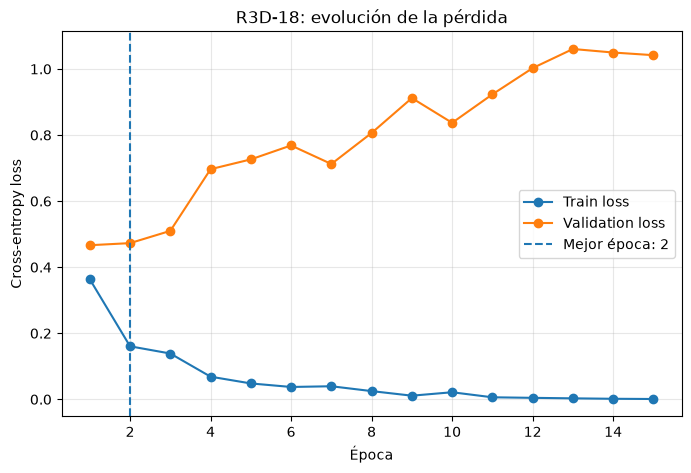

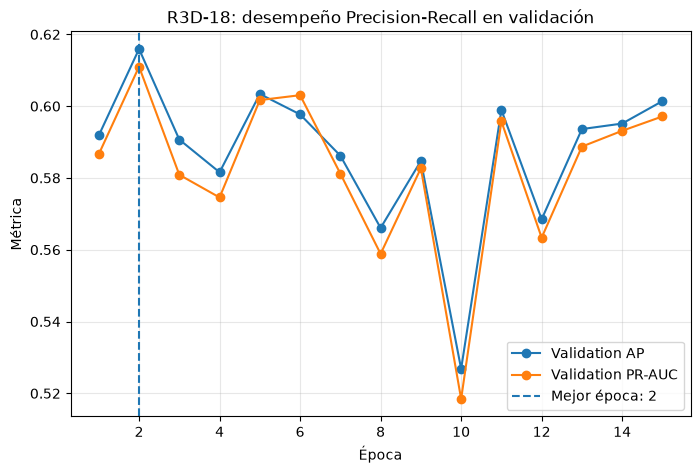

=== DIAGNÓSTICO R3D-18 ===


,momento,epoch,train_loss,val_loss,val_AP,val_PR_AUC
0,mejor_epoca,2,0.1605,0.4728,0.6159,0.6110
1,ultima_epoca,15,0.0010,1.0418,0.6014,0.5971


In [36]:
# ============================================================
# Diagnóstico del entrenamiento R3D-18
# ============================================================

import matplotlib.pyplot as plt

historial_r3d = resultado_r3d[
    "historial"
].copy()


mejor_epoca_r3d = int(
    resultado_r3d[
        "resumen"
    ][
        "mejor_epoca"
    ]
)


# ------------------------------------------------------------
# Evolución de pérdidas
# ------------------------------------------------------------

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    historial_r3d["epoch"],
    historial_r3d["train_loss"],
    marker="o",
    label="Train loss"
)

plt.plot(
    historial_r3d["epoch"],
    historial_r3d["val_loss"],
    marker="o",
    label="Validation loss"
)

plt.axvline(
    mejor_epoca_r3d,
    linestyle="--",
    label=f"Mejor época: {mejor_epoca_r3d}"
)

plt.xlabel(
    "Época"
)

plt.ylabel(
    "Cross-entropy loss"
)

plt.title(
    "R3D-18: evolución de la pérdida"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.show()


# ------------------------------------------------------------
# Evolución de métricas Precision-Recall
# ------------------------------------------------------------

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    historial_r3d["epoch"],
    historial_r3d[
        "val_average_precision"
    ],
    marker="o",
    label="Validation AP"
)

plt.plot(
    historial_r3d["epoch"],
    historial_r3d[
        "val_pr_auc"
    ],
    marker="o",
    label="Validation PR-AUC"
)

plt.axvline(
    mejor_epoca_r3d,
    linestyle="--",
    label=f"Mejor época: {mejor_epoca_r3d}"
)

plt.xlabel(
    "Época"
)

plt.ylabel(
    "Métrica"
)

plt.title(
    "R3D-18: desempeño Precision-Recall en validación"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.show()


# ------------------------------------------------------------
# Resumen cuantitativo del sobreajuste
# ------------------------------------------------------------

fila_mejor_r3d = historial_r3d.loc[
    historial_r3d[
        "epoch"
    ]
    == mejor_epoca_r3d
].iloc[0]


fila_final_r3d = historial_r3d.iloc[
    -1
]


diagnostico_r3d = pd.DataFrame(
    [
        {
            "momento": "mejor_epoca",
            "epoch": int(
                fila_mejor_r3d[
                    "epoch"
                ]
            ),
            "train_loss": (
                fila_mejor_r3d[
                    "train_loss"
                ]
            ),
            "val_loss": (
                fila_mejor_r3d[
                    "val_loss"
                ]
            ),
            "val_AP": (
                fila_mejor_r3d[
                    "val_average_precision"
                ]
            ),
            "val_PR_AUC": (
                fila_mejor_r3d[
                    "val_pr_auc"
                ]
            )
        },
        {
            "momento": "ultima_epoca",
            "epoch": int(
                fila_final_r3d[
                    "epoch"
                ]
            ),
            "train_loss": (
                fila_final_r3d[
                    "train_loss"
                ]
            ),
            "val_loss": (
                fila_final_r3d[
                    "val_loss"
                ]
            ),
            "val_AP": (
                fila_final_r3d[
                    "val_average_precision"
                ]
            ),
            "val_PR_AUC": (
                fila_final_r3d[
                    "val_pr_auc"
                ]
            )
        }
    ]
)


print(
    "=== DIAGNÓSTICO R3D-18 ==="
)

display(
    diagnostico_r3d.round(4)
)

#### Conclusiones de 8.3.1 R3D-18

R3D-18 alcanzó su mejor desempeño de validación en la época 2, con un Average Precision cercano a 0.616 y un PR-AUC cercano a 0.611. Debido a que Average Precision se definió como la métrica principal para la comparación inicial, este checkpoint se conserva como representante del modelo en las etapas posteriores.

El historial de entrenamiento muestra un patrón claro de sobreajuste temprano. La pérdida de entrenamiento disminuyó de aproximadamente 0.161 en la mejor época hasta un valor cercano a cero al final del entrenamiento, mientras que la pérdida de validación aumentó de aproximadamente 0.473 a poco más de 1.0. Las métricas Precision-Recall tampoco mejoraron de forma sostenida después de la mejor época.

Al evaluar el checkpoint seleccionado sobre la partición de validación se obtuvo un ROC-AUC cercano a 0.704 y un EER cercano a 0.381. Con el umbral provisional de 0.5, la precisión fue aproximadamente 0.824, el recall 0.467 y el F1 cercano a 0.596. Bajo este umbral, el modelo muestra una mayor precisión que sensibilidad. El umbral no se optimiza en esta etapa para evitar incorporar una decisión adicional antes de seleccionar los modelos candidatos al ajuste de hiperparámetros.

El entrenamiento completo de 15 épocas requirió aproximadamente 66 minutos y registró un pico de memoria CUDA cercano a 1.19 GB. La evaluación de validación procesó alrededor de 3.4 clips por segundo bajo el procedimiento actual de inferencia. Estas mediciones se conservarán como referencia para comparar las demás arquitecturas RGB bajo el mismo protocolo.

Los resultados justifican conservar un checkpoint temprano. Si R3D-18 resulta seleccionado entre los mejores modelos, el ajuste posterior deberá considerar estrategias dirigidas a reducir el sobreajuste, como regularización, modificación de la tasa de aprendizaje y detención temprana basada en la métrica de validación.

#### 8.3.2 MC3-18

MC3-18 se evalúa como segunda arquitectura RGB bajo el mismo protocolo experimental utilizado con R3D-18. El objetivo es comparar una arquitectura que combina convoluciones tridimensionales y bidimensionales con el baseline completamente 3D, manteniendo constantes las particiones del dataset, el número de frames por clip, la métrica principal y el esquema general de entrenamiento.

Para preservar la comparabilidad, el modelo utilizará los pesos preentrenados correspondientes, un clasificador binario para `sin_ocultamiento` y `ocultamiento`, y el mismo criterio de selección basado en Average Precision sobre la partición de validación. La partición de prueba permanecerá reservada hasta la selección y ajuste de los modelos finalistas.

In [37]:
# ============================================================
# Identidad experimental de MC3-18
# ============================================================

NOMBRE_MODELO_MC3 = "MC3-18"

CHECKPOINT_MC3_AVANCE4 = (
    CHECKPOINT_DIR
    / "mc3_18_avance4_inicial.pt"
)

HISTORIAL_MC3_AVANCE4 = (
    CHECKPOINT_DIR
    / "mc3_18_avance4_inicial_history.csv"
)

BATCH_MC3 = CONFIG_BATCH_RGB[
    NOMBRE_MODELO_MC3
]["batch_size"]


CONFIG_IDENTIDAD_MC3 = {
    "schema_version": 1,
    "modelo": NOMBRE_MODELO_MC3,
    "seed": SEED,
    "batch_size": BATCH_MC3,
    "max_epochs": MAX_EPOCHS_RGB,
    "lr_representacion": LR_REPRESENTACION_RGB,
    "lr_clasificador": LR_CLASIFICADOR_RGB,
    "weight_decay": WEIGHT_DECAY_RGB,
    "metrica_checkpoint": METRICA_CHECKPOINT_RGB,
    "dataset_v2_sha256": DATASET_V2_SHA256,
    "n_train": len(df_train_v2),
    "n_validation": len(df_val_v2),
    "num_frames": 16,
    "transformacion": repr(
        TRANSFORMS_RGB[
            NOMBRE_MODELO_MC3
        ]
    ),
    "bloques_entrenables": [
        "layer4.1",
        "fc"
    ]
}


# ------------------------------------------------------------
# Verificaciones
# ------------------------------------------------------------

assert (
    CONFIG_IDENTIDAD_MC3[
        "dataset_v2_sha256"
    ]
    == DATASET_V2_SHA256
)

assert (
    CONFIG_IDENTIDAD_MC3[
        "n_train"
    ]
    == 702
)

assert (
    CONFIG_IDENTIDAD_MC3[
        "n_validation"
    ]
    == 136
)

assert (
    BATCH_MC3
    == 16
)


# ------------------------------------------------------------
# Resumen
# ------------------------------------------------------------

resumen_identidad_mc3 = pd.DataFrame(
    [
        {
            "modelo":
                NOMBRE_MODELO_MC3,

            "seed":
                SEED,

            "batch":
                BATCH_MC3,

            "max_epochs":
                MAX_EPOCHS_RGB,

            "lr_representacion":
                LR_REPRESENTACION_RGB,

            "lr_clasificador":
                LR_CLASIFICADOR_RGB,

            "weight_decay":
                WEIGHT_DECAY_RGB,

            "metrica":
                METRICA_CHECKPOINT_RGB,

            "n_train":
                len(df_train_v2),

            "n_validation":
                len(df_val_v2)
        }
    ]
)


display(
    resumen_identidad_mc3
)

print(
    "Dataset v2 SHA-256:",
    DATASET_V2_SHA256
)

print(
    "Checkpoint:",
    CHECKPOINT_MC3_AVANCE4.relative_to(
        REPO_DIR
    )
)

print(
    "Historial:",
    HISTORIAL_MC3_AVANCE4.relative_to(
        REPO_DIR
    )
)

,modelo,seed,batch,max_epochs,lr_representacion,lr_clasificador,weight_decay,metrica,n_train,n_validation
0,MC3-18,42,16,15,0.0001,0.001,0.0001,average_precision,702,136


Dataset v2 SHA-256: b85d6b55e8c32420a4df5a0fb9a10e558105beee47f1d4a98ad83d63fcbda21e
Checkpoint: Notebooks/checkpoints/mc3_18_avance4_inicial.pt
Historial: Notebooks/checkpoints/mc3_18_avance4_inicial_history.csv


In [38]:
# ============================================================
# Ejecución protegida del experimento MC3-18
# ============================================================

validacion_mc3 = validar_artefactos_rgb(
    checkpoint_path=CHECKPOINT_MC3_AVANCE4,
    historial_path=HISTORIAL_MC3_AVANCE4,
    configuracion_esperada=CONFIG_IDENTIDAD_MC3
)


# ------------------------------------------------------------
# Bloqueo de entrenamiento automático
# ------------------------------------------------------------

if (
    validacion_mc3["estado"] != "validos"
    and not FORCE_RETRAIN_RGB
):
    motivos_mc3 = validacion_mc3.get(
        "motivos",
        []
    )

    detalle_mc3 = (
        "\n".join(
            f"- {motivo}"
            for motivo in motivos_mc3
        )
        if motivos_mc3
        else "- No hay artefactos válidos disponibles."
    )

    raise RuntimeError(
        "MC3-18 no dispone de artefactos válidos "
        "para la configuración actual.\n"
        f"Estado: {validacion_mc3['estado']}\n"
        "El entrenamiento automático está bloqueado.\n\n"
        f"{detalle_mc3}\n\n"
        "Para ejecutar deliberadamente un nuevo entrenamiento, "
        "establezca FORCE_RETRAIN_RGB=True."
    )

# ============================================================
# Reutilizar experimento existente
# ============================================================

if (
    validacion_mc3["estado"] == "validos"
    and not FORCE_RETRAIN_RGB
):

    checkpoint_mc3 = validacion_mc3[
        "checkpoint"
    ]

    historial_mc3 = validacion_mc3[
        "historial"
    ].copy()


    modelo_mc3_oficial = crear_modelo_rgb(
        NOMBRE_MODELO_MC3,
        num_classes=2,
        pretrained=True
    )

    modelo_mc3_oficial = (
        configurar_parametros_entrenables(
            modelo_mc3_oficial,
            NOMBRE_MODELO_MC3
        )
    )

    modelo_mc3_oficial.load_state_dict(
        checkpoint_mc3[
            "model_state_dict"
        ]
    )

    modelo_mc3_oficial = (
        modelo_mc3_oficial.to(
            DEVICE
        )
    )


    resultado_mc3 = {
        "modelo":
            modelo_mc3_oficial,

        "historial":
            historial_mc3,

        "resumen":
            checkpoint_mc3[
                "experiment_summary"
            ],

        "checkpoint_path":
            CHECKPOINT_MC3_AVANCE4,

        "historial_path":
            HISTORIAL_MC3_AVANCE4
    }


    print(
        "=== MC3-18 REUTILIZADO ==="
    )

    print(
        "Entrenamiento omitido: "
        "los artefactos existentes son válidos."
    )


# ============================================================
# Ejecutar entrenamiento
# ============================================================

else:

    if FORCE_RETRAIN_RGB:

        motivo_entrenamiento = (
            "reentrenamiento solicitado explícitamente"
        )

    else:

        motivo_entrenamiento = (
            "artefactos ausentes"
        )


    print(
        "=== MC3-18 SERÁ ENTRENADO ==="
    )

    print(
        "Motivo:",
        motivo_entrenamiento
    )


    # --------------------------------------------------------
    # Reproducibilidad
    # --------------------------------------------------------

    random.seed(
        SEED
    )

    np.random.seed(
        SEED
    )

    torch.manual_seed(
        SEED
    )

    if torch.cuda.is_available():

        torch.cuda.manual_seed_all(
            SEED
        )

        torch.cuda.empty_cache()


    # --------------------------------------------------------
    # Modelo
    # --------------------------------------------------------

    modelo_mc3_oficial = crear_modelo_rgb(
        NOMBRE_MODELO_MC3,
        num_classes=2,
        pretrained=True
    )

    modelo_mc3_oficial = (
        configurar_parametros_entrenables(
            modelo_mc3_oficial,
            NOMBRE_MODELO_MC3
        )
    )

    modelo_mc3_oficial = (
        modelo_mc3_oficial.to(
            DEVICE
        )
    )


    # --------------------------------------------------------
    # Optimizador
    # --------------------------------------------------------

    optimizador_mc3_oficial = optim.AdamW(
        [
            {
                "params":
                    modelo_mc3_oficial
                    .layer4[1]
                    .parameters(),

                "lr":
                    LR_REPRESENTACION_RGB
            },
            {
                "params":
                    modelo_mc3_oficial
                    .fc
                    .parameters(),

                "lr":
                    LR_CLASIFICADOR_RGB
            }
        ],
        weight_decay=WEIGHT_DECAY_RGB
    )


    # --------------------------------------------------------
    # Pérdida y precisión mixta
    # --------------------------------------------------------

    criterio_mc3_oficial = (
        nn.CrossEntropyLoss()
    )


    scaler_mc3_oficial = (
        torch.amp.GradScaler(
            "cuda",
            enabled=(
                USAR_AMP_RGB
                and DEVICE.type == "cuda"
            )
        )
    )


    # --------------------------------------------------------
    # Entrenamiento completo
    # --------------------------------------------------------

    resultado_mc3 = entrenar_experimento_rgb(
        modelo=modelo_mc3_oficial,
        nombre_modelo=NOMBRE_MODELO_MC3,

        loader_train=loaders_rgb[
            NOMBRE_MODELO_MC3
        ]["train"],

        loader_val=loaders_rgb[
            NOMBRE_MODELO_MC3
        ]["val"],

        criterio=criterio_mc3_oficial,
        optimizador=optimizador_mc3_oficial,
        scaler=scaler_mc3_oficial,

        device=DEVICE,

        max_epochs=MAX_EPOCHS_RGB,

        checkpoint_path=(
            CHECKPOINT_MC3_AVANCE4
        ),

        historial_path=(
            HISTORIAL_MC3_AVANCE4
        ),

        experiment_config=(
            CONFIG_IDENTIDAD_MC3
        ),

        usar_amp=USAR_AMP_RGB
    )


    # --------------------------------------------------------
    # Validación de artefactos generados
    # --------------------------------------------------------

    validacion_posterior_mc3 = (
        validar_artefactos_rgb(
            checkpoint_path=(
                CHECKPOINT_MC3_AVANCE4
            ),

            historial_path=(
                HISTORIAL_MC3_AVANCE4
            ),

            configuracion_esperada=(
                CONFIG_IDENTIDAD_MC3
            )
        )
    )


    if (
        validacion_posterior_mc3[
            "estado"
        ]
        != "validos"
    ):
        detalle = "\n".join(
            f"- {motivo}"
            for motivo
            in validacion_posterior_mc3[
                "motivos"
            ]
        )

        raise RuntimeError(
            "El experimento terminó, pero los "
            "artefactos generados no superaron "
            "la validación.\n\n"
            f"{detalle}"
        )


# ============================================================
# Resumen común
# ============================================================

resumen_mc3_oficial = pd.DataFrame(
    [
        resultado_mc3[
            "resumen"
        ]
    ]
)


print(
    "\n=== RESUMEN MC3-18 ==="
)

display(
    resumen_mc3_oficial
)

print(
    "Checkpoint:",
    CHECKPOINT_MC3_AVANCE4.relative_to(
        REPO_DIR
    )
)

print(
    "Historial:",
    HISTORIAL_MC3_AVANCE4.relative_to(
        REPO_DIR
    )
)

=== MC3-18 REUTILIZADO ===
Entrenamiento omitido: los artefactos existentes son válidos.

=== RESUMEN MC3-18 ===


,modelo,epocas_ejecutadas,mejor_epoca,mejor_val_ap,tiempo_entrenamiento_s,gpu_peak_gb
0,MC3-18,15,7,0.644193,3736.294595,1.269531


Checkpoint: Notebooks/checkpoints/mc3_18_avance4_inicial.pt
Historial: Notebooks/checkpoints/mc3_18_avance4_inicial_history.csv


In [39]:
# ============================================================
# Evaluación del mejor checkpoint MC3-18 sobre validation
# ============================================================

modelo_mc3_mejor = resultado_mc3[
    "modelo"
]


criterio_mc3_evaluacion = nn.CrossEntropyLoss()


if DEVICE.type == "cuda":
    torch.cuda.synchronize()


inicio_inferencia_mc3 = time.perf_counter()


resultado_val_mc3 = evaluar_modelo_rgb(
    modelo=modelo_mc3_mejor,
    loader=loaders_rgb[
        NOMBRE_MODELO_MC3
    ]["val"],
    criterio=criterio_mc3_evaluacion,
    device=DEVICE,
    usar_amp=USAR_AMP_RGB,
    threshold=0.5
)


if DEVICE.type == "cuda":
    torch.cuda.synchronize()


tiempo_inferencia_mc3 = (
    time.perf_counter()
    - inicio_inferencia_mc3
)


inferencia_clips_s_mc3 = (
    len(df_val_v2)
    / tiempo_inferencia_mc3
)


metricas_val_mc3 = resultado_val_mc3[
    "metricas"
]


historial_mc3 = resultado_mc3[
    "historial"
].copy()


indice_mejor_mc3 = historial_mc3[
    "val_average_precision"
].idxmax()


fila_mejor_mc3 = historial_mc3.loc[
    indice_mejor_mc3
]


# ------------------------------------------------------------
# Verificaciones de coherencia
# ------------------------------------------------------------

assert (
    int(
        fila_mejor_mc3[
            "epoch"
        ]
    )
    == 7
)

assert np.isclose(
    metricas_val_mc3[
        "average_precision"
    ],
    resultado_mc3[
        "resumen"
    ][
        "mejor_val_ap"
    ]
)


# ------------------------------------------------------------
# Resumen del checkpoint seleccionado
# ------------------------------------------------------------

resumen_checkpoint_mc3 = pd.DataFrame(
    [
        {
            "modelo":
                NOMBRE_MODELO_MC3,

            "mejor_epoca":
                int(
                    fila_mejor_mc3[
                        "epoch"
                    ]
                ),

            "val_loss":
                resultado_val_mc3[
                    "loss"
                ],

            "val_average_precision":
                metricas_val_mc3[
                    "average_precision"
                ],

            "val_pr_auc":
                metricas_val_mc3[
                    "pr_auc"
                ],

            "val_roc_auc":
                metricas_val_mc3[
                    "roc_auc"
                ],

            "val_eer":
                metricas_val_mc3[
                    "eer"
                ],

            "val_precision_05":
                metricas_val_mc3[
                    "precision"
                ],

            "val_recall_05":
                metricas_val_mc3[
                    "recall"
                ],

            "val_specificity_05":
                metricas_val_mc3[
                    "specificity"
                ],

            "val_f1_05":
                metricas_val_mc3[
                    "f1"
                ],

            "inferencia_clips_s":
                inferencia_clips_s_mc3
        }
    ]
)


print(
    "=== MEJOR CHECKPOINT MC3-18 ==="
)

display(
    resumen_checkpoint_mc3.round(4)
)

=== MEJOR CHECKPOINT MC3-18 ===


,modelo,mejor_epoca,val_loss,val_average_precision,val_pr_auc,val_roc_auc,val_eer,val_precision_05,val_recall_05,val_specificity_05,val_f1_05,inferencia_clips_s
0,MC3-18,7,0.6576,0.6442,0.6413,0.7492,0.3104,0.4865,0.6,0.8208,0.5373,3.1997


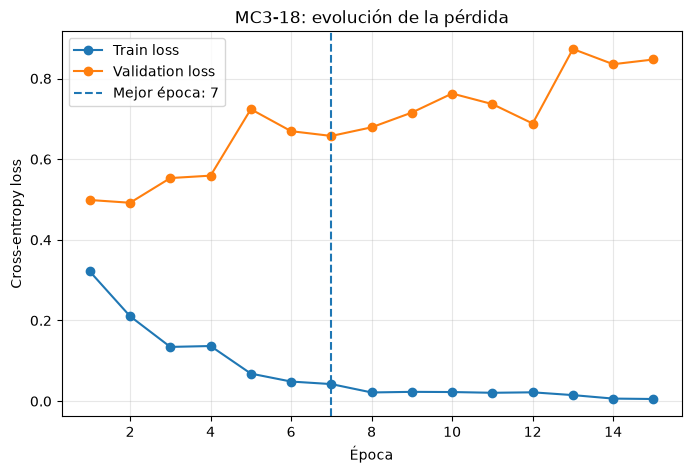

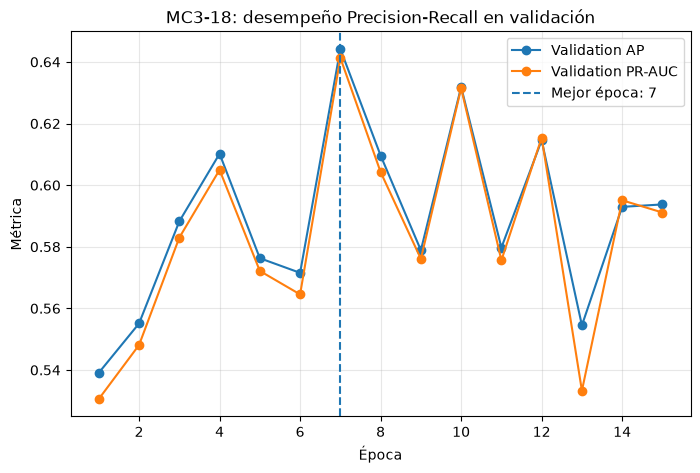

=== DIAGNÓSTICO MC3-18 ===


,momento,epoch,train_loss,val_loss,val_AP,val_PR_AUC
0,mejor_epoca,7,0.0423,0.6576,0.6442,0.6413
1,ultima_epoca,15,0.0053,0.8471,0.5937,0.5911


In [40]:
# ============================================================
# Diagnóstico del entrenamiento MC3-18
# ============================================================

historial_mc3 = resultado_mc3[
    "historial"
].copy()


mejor_epoca_mc3 = int(
    resultado_mc3[
        "resumen"
    ][
        "mejor_epoca"
    ]
)


# ------------------------------------------------------------
# Evolución de pérdidas
# ------------------------------------------------------------

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    historial_mc3["epoch"],
    historial_mc3["train_loss"],
    marker="o",
    label="Train loss"
)

plt.plot(
    historial_mc3["epoch"],
    historial_mc3["val_loss"],
    marker="o",
    label="Validation loss"
)

plt.axvline(
    mejor_epoca_mc3,
    linestyle="--",
    label=f"Mejor época: {mejor_epoca_mc3}"
)

plt.xlabel(
    "Época"
)

plt.ylabel(
    "Cross-entropy loss"
)

plt.title(
    "MC3-18: evolución de la pérdida"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.show()


# ------------------------------------------------------------
# Evolución de métricas Precision-Recall
# ------------------------------------------------------------

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    historial_mc3["epoch"],
    historial_mc3[
        "val_average_precision"
    ],
    marker="o",
    label="Validation AP"
)

plt.plot(
    historial_mc3["epoch"],
    historial_mc3[
        "val_pr_auc"
    ],
    marker="o",
    label="Validation PR-AUC"
)

plt.axvline(
    mejor_epoca_mc3,
    linestyle="--",
    label=f"Mejor época: {mejor_epoca_mc3}"
)

plt.xlabel(
    "Época"
)

plt.ylabel(
    "Métrica"
)

plt.title(
    "MC3-18: desempeño Precision-Recall en validación"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.show()


# ------------------------------------------------------------
# Resumen cuantitativo
# ------------------------------------------------------------

fila_mejor_mc3 = historial_mc3.loc[
    historial_mc3[
        "epoch"
    ]
    == mejor_epoca_mc3
].iloc[0]


fila_final_mc3 = historial_mc3.iloc[
    -1
]


diagnostico_mc3 = pd.DataFrame(
    [
        {
            "momento": "mejor_epoca",
            "epoch": int(
                fila_mejor_mc3[
                    "epoch"
                ]
            ),
            "train_loss": (
                fila_mejor_mc3[
                    "train_loss"
                ]
            ),
            "val_loss": (
                fila_mejor_mc3[
                    "val_loss"
                ]
            ),
            "val_AP": (
                fila_mejor_mc3[
                    "val_average_precision"
                ]
            ),
            "val_PR_AUC": (
                fila_mejor_mc3[
                    "val_pr_auc"
                ]
            )
        },
        {
            "momento": "ultima_epoca",
            "epoch": int(
                fila_final_mc3[
                    "epoch"
                ]
            ),
            "train_loss": (
                fila_final_mc3[
                    "train_loss"
                ]
            ),
            "val_loss": (
                fila_final_mc3[
                    "val_loss"
                ]
            ),
            "val_AP": (
                fila_final_mc3[
                    "val_average_precision"
                ]
            ),
            "val_PR_AUC": (
                fila_final_mc3[
                    "val_pr_auc"
                ]
            )
        }
    ]
)


print(
    "=== DIAGNÓSTICO MC3-18 ==="
)

display(
    diagnostico_mc3.round(4)
)

#### Conclusiones de 8.3.2 MC3-18

MC3-18 alcanzó su mejor desempeño de validación en la época 7, con un Average Precision cercano a 0.644 y un PR-AUC cercano a 0.641. Este checkpoint se conserva como representante del modelo debido a que Average Precision es la métrica principal definida para la comparación inicial.

El historial muestra un patrón de sobreajuste acompañado de variabilidad en las métricas de validación. En la mejor época, la pérdida de entrenamiento era aproximadamente 0.042 y la pérdida de validación alrededor de 0.658. Al finalizar las 15 épocas, la pérdida de entrenamiento había disminuido hasta aproximadamente 0.005, mientras que la pérdida de validación aumentó hasta cerca de 0.847. Durante el mismo intervalo, el Average Precision descendió de aproximadamente 0.644 a 0.594 y el PR-AUC de aproximadamente 0.641 a 0.591.

El checkpoint seleccionado obtuvo un ROC-AUC cercano a 0.749 y un EER aproximado de 0.310. Con el umbral provisional de 0.5, la precisión fue cercana a 0.487, el recall aproximadamente 0.600 y el F1 alrededor de 0.537. Este comportamiento muestra un equilibrio diferente al observado en R3D-18, con mayor sensibilidad pero menor precisión bajo el mismo umbral. La optimización del umbral se pospone hasta la etapa de ajuste de los modelos finalistas.

El entrenamiento completo requirió aproximadamente 62 minutos y registró un pico de memoria CUDA cercano a 1.27 GB. La evaluación de validación procesó alrededor de 3.2 clips por segundo con el procedimiento actual de inferencia.

De forma preliminar, MC3-18 supera a R3D-18 en las métricas independientes del umbral utilizadas para esta comparación inicial, incluyendo Average Precision, PR-AUC, ROC-AUC y EER. Esta ventaja todavía debe contrastarse con las arquitecturas restantes antes de seleccionar los dos modelos candidatos para ajuste de hiperparámetros.

#### 8.3.3 R(2+1)D-18

R(2+1)D-18 se evalúa como tercera arquitectura RGB bajo el mismo protocolo experimental utilizado con R3D-18 y MC3-18. Esta arquitectura factoriza las convoluciones tridimensionales en operaciones espaciales y temporales separadas, con el objetivo de representar de forma explícita ambos componentes del movimiento en video.

Para mantener una comparación controlada, se utilizan las mismas particiones del dataset v2, 16 frames por clip, el mismo tamaño de batch, las mismas tasas de aprendizaje iniciales, el mismo número máximo de épocas y Average Precision como métrica principal para seleccionar el checkpoint. La partición de prueba permanece reservada para la etapa posterior de selección y ajuste de modelos.

In [41]:
# ============================================================
# Identidad experimental de R(2+1)D-18
# ============================================================

NOMBRE_MODELO_R2PLUS1D = "R(2+1)D-18"

CHECKPOINT_R2PLUS1D_AVANCE4 = (
    CHECKPOINT_DIR
    / "r2plus1d_18_avance4_inicial.pt"
)

HISTORIAL_R2PLUS1D_AVANCE4 = (
    CHECKPOINT_DIR
    / "r2plus1d_18_avance4_inicial_history.csv"
)

BATCH_R2PLUS1D = CONFIG_BATCH_RGB[
    NOMBRE_MODELO_R2PLUS1D
]["batch_size"]


CONFIG_IDENTIDAD_R2PLUS1D = {
    "schema_version": 1,
    "modelo": NOMBRE_MODELO_R2PLUS1D,
    "seed": SEED,
    "batch_size": BATCH_R2PLUS1D,
    "max_epochs": MAX_EPOCHS_RGB,
    "lr_representacion": LR_REPRESENTACION_RGB,
    "lr_clasificador": LR_CLASIFICADOR_RGB,
    "weight_decay": WEIGHT_DECAY_RGB,
    "metrica_checkpoint": METRICA_CHECKPOINT_RGB,
    "dataset_v2_sha256": DATASET_V2_SHA256,
    "n_train": len(df_train_v2),
    "n_validation": len(df_val_v2),
    "num_frames": 16,
    "transformacion": repr(
        TRANSFORMS_RGB[
            NOMBRE_MODELO_R2PLUS1D
        ]
    ),
    "bloques_entrenables": [
        "layer4.1",
        "fc"
    ]
}


# ------------------------------------------------------------
# Verificaciones
# ------------------------------------------------------------

assert (
    CONFIG_IDENTIDAD_R2PLUS1D[
        "dataset_v2_sha256"
    ]
    == DATASET_V2_SHA256
)

assert (
    CONFIG_IDENTIDAD_R2PLUS1D[
        "n_train"
    ]
    == 702
)

assert (
    CONFIG_IDENTIDAD_R2PLUS1D[
        "n_validation"
    ]
    == 136
)

assert (
    BATCH_R2PLUS1D
    == 16
)


# ------------------------------------------------------------
# Resumen
# ------------------------------------------------------------

resumen_identidad_r2plus1d = pd.DataFrame(
    [
        {
            "modelo":
                NOMBRE_MODELO_R2PLUS1D,

            "seed":
                SEED,

            "batch":
                BATCH_R2PLUS1D,

            "max_epochs":
                MAX_EPOCHS_RGB,

            "lr_representacion":
                LR_REPRESENTACION_RGB,

            "lr_clasificador":
                LR_CLASIFICADOR_RGB,

            "weight_decay":
                WEIGHT_DECAY_RGB,

            "metrica":
                METRICA_CHECKPOINT_RGB,

            "n_train":
                len(df_train_v2),

            "n_validation":
                len(df_val_v2)
        }
    ]
)


display(
    resumen_identidad_r2plus1d
)

print(
    "Dataset v2 SHA-256:",
    DATASET_V2_SHA256
)

print(
    "Checkpoint:",
    CHECKPOINT_R2PLUS1D_AVANCE4.relative_to(
        REPO_DIR
    )
)

print(
    "Historial:",
    HISTORIAL_R2PLUS1D_AVANCE4.relative_to(
        REPO_DIR
    )
)

,modelo,seed,batch,max_epochs,lr_representacion,lr_clasificador,weight_decay,metrica,n_train,n_validation
0,R(2+1)D-18,42,16,15,0.0001,0.001,0.0001,average_precision,702,136


Dataset v2 SHA-256: b85d6b55e8c32420a4df5a0fb9a10e558105beee47f1d4a98ad83d63fcbda21e
Checkpoint: Notebooks/checkpoints/r2plus1d_18_avance4_inicial.pt
Historial: Notebooks/checkpoints/r2plus1d_18_avance4_inicial_history.csv


In [42]:
# ============================================================
# Ejecución protegida del experimento R(2+1)D-18
# ============================================================

validacion_r2plus1d = validar_artefactos_rgb(
    checkpoint_path=CHECKPOINT_R2PLUS1D_AVANCE4,
    historial_path=HISTORIAL_R2PLUS1D_AVANCE4,
    configuracion_esperada=CONFIG_IDENTIDAD_R2PLUS1D
)


# ------------------------------------------------------------
# Bloqueo de entrenamiento automático
# ------------------------------------------------------------

if (
    validacion_r2plus1d["estado"] != "validos"
    and not FORCE_RETRAIN_RGB
):
    motivos_r2plus1d = validacion_r2plus1d.get(
        "motivos",
        []
    )

    detalle_r2plus1d = (
        "\n".join(
            f"- {motivo}"
            for motivo in motivos_r2plus1d
        )
        if motivos_r2plus1d
        else "- No hay artefactos válidos disponibles."
    )

    raise RuntimeError(
        "R(2+1)D-18 no dispone de artefactos válidos "
        "para la configuración actual.\n"
        f"Estado: {validacion_r2plus1d['estado']}\n"
        "El entrenamiento automático está bloqueado.\n\n"
        f"{detalle_r2plus1d}\n\n"
        "Para ejecutar deliberadamente un nuevo entrenamiento, "
        "establezca FORCE_RETRAIN_RGB=True."
    )

# ============================================================
# Reutilizar experimento existente
# ============================================================

if (
    validacion_r2plus1d["estado"] == "validos"
    and not FORCE_RETRAIN_RGB
):

    checkpoint_r2plus1d = validacion_r2plus1d[
        "checkpoint"
    ]

    historial_r2plus1d = validacion_r2plus1d[
        "historial"
    ].copy()


    modelo_r2plus1d_oficial = crear_modelo_rgb(
        NOMBRE_MODELO_R2PLUS1D,
        num_classes=2,
        pretrained=True
    )

    modelo_r2plus1d_oficial = (
        configurar_parametros_entrenables(
            modelo_r2plus1d_oficial,
            NOMBRE_MODELO_R2PLUS1D
        )
    )

    modelo_r2plus1d_oficial.load_state_dict(
        checkpoint_r2plus1d[
            "model_state_dict"
        ]
    )

    modelo_r2plus1d_oficial = (
        modelo_r2plus1d_oficial.to(
            DEVICE
        )
    )


    resultado_r2plus1d = {
        "modelo":
            modelo_r2plus1d_oficial,

        "historial":
            historial_r2plus1d,

        "resumen":
            checkpoint_r2plus1d[
                "experiment_summary"
            ],

        "checkpoint_path":
            CHECKPOINT_R2PLUS1D_AVANCE4,

        "historial_path":
            HISTORIAL_R2PLUS1D_AVANCE4
    }


    print(
        "=== R(2+1)D-18 REUTILIZADO ==="
    )

    print(
        "Entrenamiento omitido: "
        "los artefactos existentes son válidos."
    )


# ============================================================
# Ejecutar entrenamiento
# ============================================================

else:

    if FORCE_RETRAIN_RGB:

        motivo_entrenamiento = (
            "reentrenamiento solicitado explícitamente"
        )

    else:

        motivo_entrenamiento = (
            "artefactos ausentes"
        )


    print(
        "=== R(2+1)D-18 SERÁ ENTRENADO ==="
    )

    print(
        "Motivo:",
        motivo_entrenamiento
    )


    # --------------------------------------------------------
    # Reproducibilidad
    # --------------------------------------------------------

    random.seed(
        SEED
    )

    np.random.seed(
        SEED
    )

    torch.manual_seed(
        SEED
    )

    if torch.cuda.is_available():

        torch.cuda.manual_seed_all(
            SEED
        )

        torch.cuda.empty_cache()


    # --------------------------------------------------------
    # Modelo
    # --------------------------------------------------------

    modelo_r2plus1d_oficial = crear_modelo_rgb(
        NOMBRE_MODELO_R2PLUS1D,
        num_classes=2,
        pretrained=True
    )

    modelo_r2plus1d_oficial = (
        configurar_parametros_entrenables(
            modelo_r2plus1d_oficial,
            NOMBRE_MODELO_R2PLUS1D
        )
    )

    modelo_r2plus1d_oficial = (
        modelo_r2plus1d_oficial.to(
            DEVICE
        )
    )


    # --------------------------------------------------------
    # Optimizador
    # --------------------------------------------------------

    optimizador_r2plus1d_oficial = optim.AdamW(
        [
            {
                "params":
                    modelo_r2plus1d_oficial
                    .layer4[1]
                    .parameters(),

                "lr":
                    LR_REPRESENTACION_RGB
            },
            {
                "params":
                    modelo_r2plus1d_oficial
                    .fc
                    .parameters(),

                "lr":
                    LR_CLASIFICADOR_RGB
            }
        ],
        weight_decay=WEIGHT_DECAY_RGB
    )


    # --------------------------------------------------------
    # Pérdida y precisión mixta
    # --------------------------------------------------------

    criterio_r2plus1d_oficial = (
        nn.CrossEntropyLoss()
    )


    scaler_r2plus1d_oficial = (
        torch.amp.GradScaler(
            "cuda",
            enabled=(
                USAR_AMP_RGB
                and DEVICE.type == "cuda"
            )
        )
    )


    # --------------------------------------------------------
    # Entrenamiento completo
    # --------------------------------------------------------

    resultado_r2plus1d = entrenar_experimento_rgb(
        modelo=modelo_r2plus1d_oficial,
        nombre_modelo=NOMBRE_MODELO_R2PLUS1D,

        loader_train=loaders_rgb[
            NOMBRE_MODELO_R2PLUS1D
        ]["train"],

        loader_val=loaders_rgb[
            NOMBRE_MODELO_R2PLUS1D
        ]["val"],

        criterio=criterio_r2plus1d_oficial,
        optimizador=optimizador_r2plus1d_oficial,
        scaler=scaler_r2plus1d_oficial,

        device=DEVICE,

        max_epochs=MAX_EPOCHS_RGB,

        checkpoint_path=(
            CHECKPOINT_R2PLUS1D_AVANCE4
        ),

        historial_path=(
            HISTORIAL_R2PLUS1D_AVANCE4
        ),

        experiment_config=(
            CONFIG_IDENTIDAD_R2PLUS1D
        ),

        usar_amp=USAR_AMP_RGB
    )


    # --------------------------------------------------------
    # Validación de artefactos generados
    # --------------------------------------------------------

    validacion_posterior_r2plus1d = (
        validar_artefactos_rgb(
            checkpoint_path=(
                CHECKPOINT_R2PLUS1D_AVANCE4
            ),

            historial_path=(
                HISTORIAL_R2PLUS1D_AVANCE4
            ),

            configuracion_esperada=(
                CONFIG_IDENTIDAD_R2PLUS1D
            )
        )
    )


    if (
        validacion_posterior_r2plus1d[
            "estado"
        ]
        != "validos"
    ):
        detalle = "\n".join(
            f"- {motivo}"
            for motivo
            in validacion_posterior_r2plus1d[
                "motivos"
            ]
        )

        raise RuntimeError(
            "El experimento terminó, pero los "
            "artefactos generados no superaron "
            "la validación.\n\n"
            f"{detalle}"
        )


# ============================================================
# Resumen común
# ============================================================

resumen_r2plus1d_oficial = pd.DataFrame(
    [
        resultado_r2plus1d[
            "resumen"
        ]
    ]
)


print(
    "\n=== RESUMEN R(2+1)D-18 ==="
)

display(
    resumen_r2plus1d_oficial
)

print(
    "Checkpoint:",
    CHECKPOINT_R2PLUS1D_AVANCE4.relative_to(
        REPO_DIR
    )
)

print(
    "Historial:",
    HISTORIAL_R2PLUS1D_AVANCE4.relative_to(
        REPO_DIR
    )
)

=== R(2+1)D-18 REUTILIZADO ===
Entrenamiento omitido: los artefactos existentes son válidos.

=== RESUMEN R(2+1)D-18 ===


,modelo,epocas_ejecutadas,mejor_epoca,mejor_val_ap,tiempo_entrenamiento_s,gpu_peak_gb
0,R(2+1)D-18,15,4,0.673027,3781.225018,2.320312


Checkpoint: Notebooks/checkpoints/r2plus1d_18_avance4_inicial.pt
Historial: Notebooks/checkpoints/r2plus1d_18_avance4_inicial_history.csv


In [43]:
# ============================================================
# Evaluación del mejor checkpoint R(2+1)D-18 sobre validation
# ============================================================

modelo_r2plus1d_mejor = resultado_r2plus1d[
    "modelo"
]


criterio_r2plus1d_evaluacion = nn.CrossEntropyLoss()


if DEVICE.type == "cuda":
    torch.cuda.synchronize()


inicio_inferencia_r2plus1d = time.perf_counter()


resultado_val_r2plus1d = evaluar_modelo_rgb(
    modelo=modelo_r2plus1d_mejor,
    loader=loaders_rgb[
        NOMBRE_MODELO_R2PLUS1D
    ]["val"],
    criterio=criterio_r2plus1d_evaluacion,
    device=DEVICE,
    usar_amp=USAR_AMP_RGB,
    threshold=0.5
)


if DEVICE.type == "cuda":
    torch.cuda.synchronize()


tiempo_inferencia_r2plus1d = (
    time.perf_counter()
    - inicio_inferencia_r2plus1d
)


inferencia_clips_s_r2plus1d = (
    len(df_val_v2)
    / tiempo_inferencia_r2plus1d
)


metricas_val_r2plus1d = resultado_val_r2plus1d[
    "metricas"
]


historial_r2plus1d = resultado_r2plus1d[
    "historial"
].copy()


indice_mejor_r2plus1d = historial_r2plus1d[
    "val_average_precision"
].idxmax()


fila_mejor_r2plus1d = historial_r2plus1d.loc[
    indice_mejor_r2plus1d
]


# ------------------------------------------------------------
# Verificaciones de coherencia
# ------------------------------------------------------------

assert (
    int(
        fila_mejor_r2plus1d[
            "epoch"
        ]
    )
    == 4
)

assert np.isclose(
    metricas_val_r2plus1d[
        "average_precision"
    ],
    resultado_r2plus1d[
        "resumen"
    ][
        "mejor_val_ap"
    ]
)


# ------------------------------------------------------------
# Resumen del checkpoint seleccionado
# ------------------------------------------------------------

resumen_checkpoint_r2plus1d = pd.DataFrame(
    [
        {
            "modelo":
                NOMBRE_MODELO_R2PLUS1D,

            "mejor_epoca":
                int(
                    fila_mejor_r2plus1d[
                        "epoch"
                    ]
                ),

            "val_loss":
                resultado_val_r2plus1d[
                    "loss"
                ],

            "val_average_precision":
                metricas_val_r2plus1d[
                    "average_precision"
                ],

            "val_pr_auc":
                metricas_val_r2plus1d[
                    "pr_auc"
                ],

            "val_roc_auc":
                metricas_val_r2plus1d[
                    "roc_auc"
                ],

            "val_eer":
                metricas_val_r2plus1d[
                    "eer"
                ],

            "val_precision_05":
                metricas_val_r2plus1d[
                    "precision"
                ],

            "val_recall_05":
                metricas_val_r2plus1d[
                    "recall"
                ],

            "val_specificity_05":
                metricas_val_r2plus1d[
                    "specificity"
                ],

            "val_f1_05":
                metricas_val_r2plus1d[
                    "f1"
                ],

            "inferencia_clips_s":
                inferencia_clips_s_r2plus1d
        }
    ]
)


print(
    "=== MEJOR CHECKPOINT R(2+1)D-18 ==="
)

display(
    resumen_checkpoint_r2plus1d.round(4)
)

=== MEJOR CHECKPOINT R(2+1)D-18 ===


,modelo,mejor_epoca,val_loss,val_average_precision,val_pr_auc,val_roc_auc,val_eer,val_precision_05,val_recall_05,val_specificity_05,val_f1_05,inferencia_clips_s
0,R(2+1)D-18,4,0.4959,0.673,0.6695,0.7387,0.3223,0.7826,0.6,0.9528,0.6792,3.0718


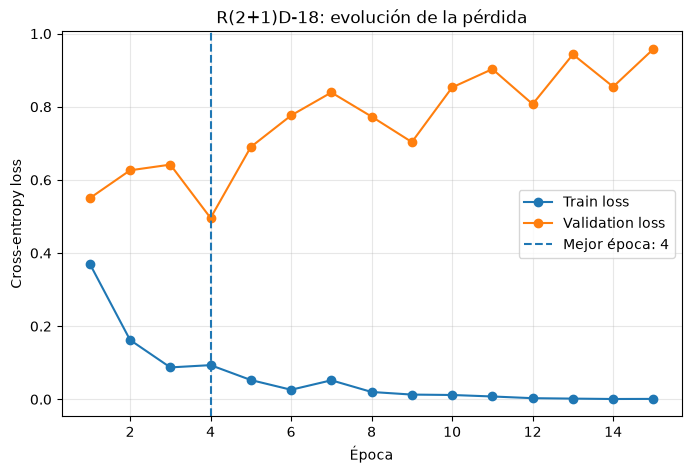

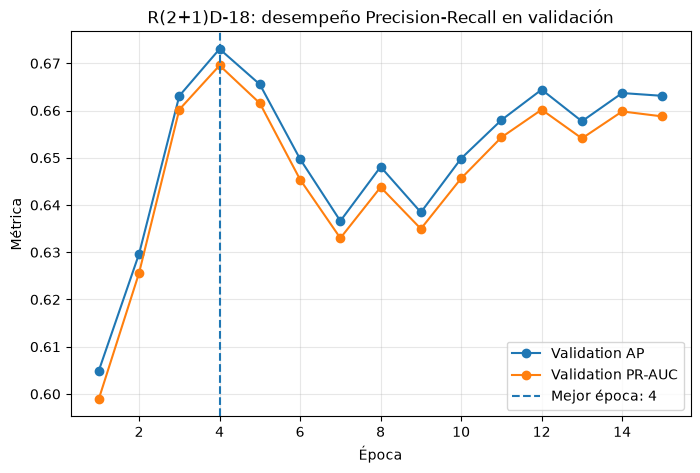

=== DIAGNÓSTICO R(2+1)D-18 ===


,momento,epoch,train_loss,val_loss,val_AP,val_PR_AUC
0,mejor_epoca,4,0.0935,0.4959,0.6730,0.6695
1,ultima_epoca,15,0.0011,0.9581,0.6631,0.6588


In [44]:
# ============================================================
# Diagnóstico del entrenamiento R(2+1)D-18
# ============================================================

historial_r2plus1d = resultado_r2plus1d[
    "historial"
].copy()


mejor_epoca_r2plus1d = int(
    resultado_r2plus1d[
        "resumen"
    ][
        "mejor_epoca"
    ]
)


# ------------------------------------------------------------
# Evolución de pérdidas
# ------------------------------------------------------------

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    historial_r2plus1d["epoch"],
    historial_r2plus1d["train_loss"],
    marker="o",
    label="Train loss"
)

plt.plot(
    historial_r2plus1d["epoch"],
    historial_r2plus1d["val_loss"],
    marker="o",
    label="Validation loss"
)

plt.axvline(
    mejor_epoca_r2plus1d,
    linestyle="--",
    label=f"Mejor época: {mejor_epoca_r2plus1d}"
)

plt.xlabel(
    "Época"
)

plt.ylabel(
    "Cross-entropy loss"
)

plt.title(
    "R(2+1)D-18: evolución de la pérdida"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.show()


# ------------------------------------------------------------
# Evolución de métricas Precision-Recall
# ------------------------------------------------------------

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    historial_r2plus1d["epoch"],
    historial_r2plus1d[
        "val_average_precision"
    ],
    marker="o",
    label="Validation AP"
)

plt.plot(
    historial_r2plus1d["epoch"],
    historial_r2plus1d[
        "val_pr_auc"
    ],
    marker="o",
    label="Validation PR-AUC"
)

plt.axvline(
    mejor_epoca_r2plus1d,
    linestyle="--",
    label=f"Mejor época: {mejor_epoca_r2plus1d}"
)

plt.xlabel(
    "Época"
)

plt.ylabel(
    "Métrica"
)

plt.title(
    "R(2+1)D-18: desempeño Precision-Recall en validación"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.show()


# ------------------------------------------------------------
# Resumen cuantitativo
# ------------------------------------------------------------

fila_mejor_r2plus1d = historial_r2plus1d.loc[
    historial_r2plus1d[
        "epoch"
    ]
    == mejor_epoca_r2plus1d
].iloc[0]


fila_final_r2plus1d = historial_r2plus1d.iloc[
    -1
]


diagnostico_r2plus1d = pd.DataFrame(
    [
        {
            "momento": "mejor_epoca",
            "epoch": int(
                fila_mejor_r2plus1d[
                    "epoch"
                ]
            ),
            "train_loss": (
                fila_mejor_r2plus1d[
                    "train_loss"
                ]
            ),
            "val_loss": (
                fila_mejor_r2plus1d[
                    "val_loss"
                ]
            ),
            "val_AP": (
                fila_mejor_r2plus1d[
                    "val_average_precision"
                ]
            ),
            "val_PR_AUC": (
                fila_mejor_r2plus1d[
                    "val_pr_auc"
                ]
            )
        },
        {
            "momento": "ultima_epoca",
            "epoch": int(
                fila_final_r2plus1d[
                    "epoch"
                ]
            ),
            "train_loss": (
                fila_final_r2plus1d[
                    "train_loss"
                ]
            ),
            "val_loss": (
                fila_final_r2plus1d[
                    "val_loss"
                ]
            ),
            "val_AP": (
                fila_final_r2plus1d[
                    "val_average_precision"
                ]
            ),
            "val_PR_AUC": (
                fila_final_r2plus1d[
                    "val_pr_auc"
                ]
            )
        }
    ]
)


print(
    "=== DIAGNÓSTICO R(2+1)D-18 ==="
)

display(
    diagnostico_r2plus1d.round(4)
)

#### Conclusiones de 8.3.3 R(2+1)D-18

R(2+1)D-18 alcanzó su mejor desempeño de validación en la época 4, con un Average Precision cercano a 0.673 y un PR-AUC cercano a 0.670. Este checkpoint se conserva como representante del modelo debido a que Average Precision es la métrica principal definida para la comparación inicial.

El historial muestra evidencia de sobreajuste después de las primeras épocas. En el checkpoint seleccionado, la pérdida de entrenamiento era aproximadamente 0.094 y la pérdida de validación cercana a 0.496. Al finalizar las 15 épocas, la pérdida de entrenamiento había disminuido hasta un valor cercano a cero, mientras que la pérdida de validación aumentó hasta aproximadamente 0.958.

A pesar de este incremento en la pérdida de validación, las métricas Precision-Recall permanecieron relativamente estables después de la mejor época. El Average Precision terminó alrededor de 0.663 y el PR-AUC alrededor de 0.659. Esto sugiere que el deterioro posterior afectó con mayor intensidad la confianza de las predicciones que su capacidad relativa para ordenar ejemplos positivos y negativos.

El checkpoint seleccionado obtuvo un ROC-AUC cercano a 0.739 y un EER aproximado de 0.322. Con el umbral provisional de 0.5, la precisión fue cercana a 0.783, el recall aproximadamente 0.600 y el F1 alrededor de 0.679. La optimización del umbral se mantiene fuera de esta etapa inicial.

El entrenamiento completo de 15 épocas requirió aproximadamente 66 minutos y registró un pico de memoria CUDA cercano a 1.19 GB. La evaluación de validación procesó alrededor de **3.44 clips por segundo** bajo el procedimiento actual de inferencia. Estas mediciones se conservarán como referencia para comparar las demás arquitecturas RGB bajo el mismo protocolo.

Hasta este punto, R(2+1)D-18 presenta el mayor Average Precision de las tres arquitecturas evaluadas. MC3-18 mantiene un ROC-AUC ligeramente superior, por lo que la selección final deberá considerar la métrica principal junto con métricas secundarias, costo computacional y comportamiento operativo después de evaluar las arquitecturas restantes.

#### 8.3.4 S3D

S3D se evalúa como cuarta arquitectura RGB bajo el mismo protocolo experimental utilizado con los modelos anteriores. Esta arquitectura emplea convoluciones tridimensionales separables para representar información espacial y temporal con una estructura diferente a las redes 3D convencionales.

La comparación mantiene las mismas particiones del dataset v2, 16 frames por clip, el mismo tamaño de batch, las mismas tasas de aprendizaje iniciales, el mismo número máximo de épocas y Average Precision como métrica principal para seleccionar el checkpoint. La transformación espacial utiliza resolución de 224 × 224 de acuerdo con los requerimientos de los pesos preentrenados de S3D.

La partición de prueba permanece reservada para la etapa posterior de selección y ajuste de modelos.

In [45]:
# ============================================================
# Identidad experimental de S3D
# ============================================================

NOMBRE_MODELO_S3D = "S3D"

CHECKPOINT_S3D_AVANCE4 = (
    CHECKPOINT_DIR
    / "s3d_avance4_inicial.pt"
)

HISTORIAL_S3D_AVANCE4 = (
    CHECKPOINT_DIR
    / "s3d_avance4_inicial_history.csv"
)

BATCH_S3D = CONFIG_BATCH_RGB[
    NOMBRE_MODELO_S3D
]["batch_size"]


CONFIG_IDENTIDAD_S3D = {
    "schema_version": 1,
    "modelo": NOMBRE_MODELO_S3D,
    "seed": SEED,
    "batch_size": BATCH_S3D,
    "max_epochs": MAX_EPOCHS_RGB,
    "lr_representacion": LR_REPRESENTACION_RGB,
    "lr_clasificador": LR_CLASIFICADOR_RGB,
    "weight_decay": WEIGHT_DECAY_RGB,
    "metrica_checkpoint": METRICA_CHECKPOINT_RGB,
    "dataset_v2_sha256": DATASET_V2_SHA256,
    "n_train": len(df_train_v2),
    "n_validation": len(df_val_v2),
    "num_frames": 16,
    "transformacion": repr(
        TRANSFORMS_RGB[
            NOMBRE_MODELO_S3D
        ]
    ),
    "bloques_entrenables": [
        "features.14",
        "features.15",
        "classifier"
    ]
}


# ------------------------------------------------------------
# Verificaciones
# ------------------------------------------------------------

assert (
    CONFIG_IDENTIDAD_S3D[
        "dataset_v2_sha256"
    ]
    == DATASET_V2_SHA256
)

assert (
    CONFIG_IDENTIDAD_S3D[
        "n_train"
    ]
    == 702
)

assert (
    CONFIG_IDENTIDAD_S3D[
        "n_validation"
    ]
    == 136
)

assert (
    BATCH_S3D
    == 16
)


# ------------------------------------------------------------
# Resumen
# ------------------------------------------------------------

resumen_identidad_s3d = pd.DataFrame(
    [
        {
            "modelo":
                NOMBRE_MODELO_S3D,

            "seed":
                SEED,

            "batch":
                BATCH_S3D,

            "max_epochs":
                MAX_EPOCHS_RGB,

            "lr_representacion":
                LR_REPRESENTACION_RGB,

            "lr_clasificador":
                LR_CLASIFICADOR_RGB,

            "weight_decay":
                WEIGHT_DECAY_RGB,

            "metrica":
                METRICA_CHECKPOINT_RGB,

            "n_train":
                len(df_train_v2),

            "n_validation":
                len(df_val_v2)
        }
    ]
)


display(
    resumen_identidad_s3d
)

print(
    "Dataset v2 SHA-256:",
    DATASET_V2_SHA256
)

print(
    "Checkpoint:",
    CHECKPOINT_S3D_AVANCE4.relative_to(
        REPO_DIR
    )
)

print(
    "Historial:",
    HISTORIAL_S3D_AVANCE4.relative_to(
        REPO_DIR
    )
)

,modelo,seed,batch,max_epochs,lr_representacion,lr_clasificador,weight_decay,metrica,n_train,n_validation
0,S3D,42,16,15,0.0001,0.001,0.0001,average_precision,702,136


Dataset v2 SHA-256: b85d6b55e8c32420a4df5a0fb9a10e558105beee47f1d4a98ad83d63fcbda21e
Checkpoint: Notebooks/checkpoints/s3d_avance4_inicial.pt
Historial: Notebooks/checkpoints/s3d_avance4_inicial_history.csv


In [46]:
# ============================================================
# Ejecución protegida del experimento S3D
# ============================================================

validacion_s3d = validar_artefactos_rgb(
    checkpoint_path=CHECKPOINT_S3D_AVANCE4,
    historial_path=HISTORIAL_S3D_AVANCE4,
    configuracion_esperada=CONFIG_IDENTIDAD_S3D
)


# ------------------------------------------------------------
# Bloqueo de entrenamiento automático
# ------------------------------------------------------------

if (
    validacion_s3d["estado"] != "validos"
    and not FORCE_RETRAIN_RGB
):
    motivos_s3d = validacion_s3d.get(
        "motivos",
        []
    )

    detalle_s3d = (
        "\n".join(
            f"- {motivo}"
            for motivo in motivos_s3d
        )
        if motivos_s3d
        else "- No hay artefactos válidos disponibles."
    )

    raise RuntimeError(
        "S3D no dispone de artefactos válidos "
        "para la configuración actual.\n"
        f"Estado: {validacion_s3d['estado']}\n"
        "El entrenamiento automático está bloqueado.\n\n"
        f"{detalle_s3d}\n\n"
        "Para ejecutar deliberadamente un nuevo entrenamiento, "
        "establezca FORCE_RETRAIN_RGB=True."
    )

# ============================================================
# Reutilizar experimento existente
# ============================================================

if (
    validacion_s3d["estado"] == "validos"
    and not FORCE_RETRAIN_RGB
):

    checkpoint_s3d = validacion_s3d[
        "checkpoint"
    ]

    historial_s3d = validacion_s3d[
        "historial"
    ].copy()


    modelo_s3d_oficial = crear_modelo_rgb(
        NOMBRE_MODELO_S3D,
        num_classes=2,
        pretrained=True
    )

    modelo_s3d_oficial = (
        configurar_parametros_entrenables(
            modelo_s3d_oficial,
            NOMBRE_MODELO_S3D
        )
    )

    modelo_s3d_oficial.load_state_dict(
        checkpoint_s3d[
            "model_state_dict"
        ]
    )

    modelo_s3d_oficial = (
        modelo_s3d_oficial.to(
            DEVICE
        )
    )


    resultado_s3d = {
        "modelo":
            modelo_s3d_oficial,

        "historial":
            historial_s3d,

        "resumen":
            checkpoint_s3d[
                "experiment_summary"
            ],

        "checkpoint_path":
            CHECKPOINT_S3D_AVANCE4,

        "historial_path":
            HISTORIAL_S3D_AVANCE4
    }


    print(
        "=== S3D REUTILIZADO ==="
    )

    print(
        "Entrenamiento omitido: "
        "los artefactos existentes son válidos."
    )


# ============================================================
# Ejecutar entrenamiento
# ============================================================

else:

    if FORCE_RETRAIN_RGB:

        motivo_entrenamiento = (
            "reentrenamiento solicitado explícitamente"
        )

    else:

        motivo_entrenamiento = (
            "artefactos ausentes"
        )


    print(
        "=== S3D SERÁ ENTRENADO ==="
    )

    print(
        "Motivo:",
        motivo_entrenamiento
    )


    # --------------------------------------------------------
    # Reproducibilidad
    # --------------------------------------------------------

    random.seed(
        SEED
    )

    np.random.seed(
        SEED
    )

    torch.manual_seed(
        SEED
    )

    if torch.cuda.is_available():

        torch.cuda.manual_seed_all(
            SEED
        )

        torch.cuda.empty_cache()


    # --------------------------------------------------------
    # Modelo
    # --------------------------------------------------------

    modelo_s3d_oficial = crear_modelo_rgb(
        NOMBRE_MODELO_S3D,
        num_classes=2,
        pretrained=True
    )

    modelo_s3d_oficial = (
        configurar_parametros_entrenables(
            modelo_s3d_oficial,
            NOMBRE_MODELO_S3D
        )
    )

    modelo_s3d_oficial = (
        modelo_s3d_oficial.to(
            DEVICE
        )
    )


    # --------------------------------------------------------
    # Optimizador
    # --------------------------------------------------------

    parametros_representacion_s3d = (
        list(
            modelo_s3d_oficial
            .features[14]
            .parameters()
        )
        +
        list(
            modelo_s3d_oficial
            .features[15]
            .parameters()
        )
    )


    optimizador_s3d_oficial = optim.AdamW(
        [
            {
                "params":
                    parametros_representacion_s3d,

                "lr":
                    LR_REPRESENTACION_RGB
            },
            {
                "params":
                    modelo_s3d_oficial
                    .classifier
                    .parameters(),

                "lr":
                    LR_CLASIFICADOR_RGB
            }
        ],
        weight_decay=WEIGHT_DECAY_RGB
    )


    # --------------------------------------------------------
    # Pérdida y precisión mixta
    # --------------------------------------------------------

    criterio_s3d_oficial = (
        nn.CrossEntropyLoss()
    )


    scaler_s3d_oficial = (
        torch.amp.GradScaler(
            "cuda",
            enabled=(
                USAR_AMP_RGB
                and DEVICE.type == "cuda"
            )
        )
    )


    # --------------------------------------------------------
    # Entrenamiento completo
    # --------------------------------------------------------

    resultado_s3d = entrenar_experimento_rgb(
        modelo=modelo_s3d_oficial,
        nombre_modelo=NOMBRE_MODELO_S3D,

        loader_train=loaders_rgb[
            NOMBRE_MODELO_S3D
        ]["train"],

        loader_val=loaders_rgb[
            NOMBRE_MODELO_S3D
        ]["val"],

        criterio=criterio_s3d_oficial,
        optimizador=optimizador_s3d_oficial,
        scaler=scaler_s3d_oficial,

        device=DEVICE,

        max_epochs=MAX_EPOCHS_RGB,

        checkpoint_path=(
            CHECKPOINT_S3D_AVANCE4
        ),

        historial_path=(
            HISTORIAL_S3D_AVANCE4
        ),

        experiment_config=(
            CONFIG_IDENTIDAD_S3D
        ),

        usar_amp=USAR_AMP_RGB
    )


    # --------------------------------------------------------
    # Validación de artefactos generados
    # --------------------------------------------------------

    validacion_posterior_s3d = (
        validar_artefactos_rgb(
            checkpoint_path=(
                CHECKPOINT_S3D_AVANCE4
            ),

            historial_path=(
                HISTORIAL_S3D_AVANCE4
            ),

            configuracion_esperada=(
                CONFIG_IDENTIDAD_S3D
            )
        )
    )


    if (
        validacion_posterior_s3d[
            "estado"
        ]
        != "validos"
    ):
        detalle = "\n".join(
            f"- {motivo}"
            for motivo
            in validacion_posterior_s3d[
                "motivos"
            ]
        )

        raise RuntimeError(
            "El experimento terminó, pero los "
            "artefactos generados no superaron "
            "la validación.\n\n"
            f"{detalle}"
        )


# ============================================================
# Resumen común
# ============================================================

resumen_s3d_oficial = pd.DataFrame(
    [
        resultado_s3d[
            "resumen"
        ]
    ]
)


print(
    "\n=== RESUMEN S3D ==="
)

display(
    resumen_s3d_oficial
)

print(
    "Checkpoint:",
    CHECKPOINT_S3D_AVANCE4.relative_to(
        REPO_DIR
    )
)

print(
    "Historial:",
    HISTORIAL_S3D_AVANCE4.relative_to(
        REPO_DIR
    )
)

=== S3D REUTILIZADO ===
Entrenamiento omitido: los artefactos existentes son válidos.

=== RESUMEN S3D ===


,modelo,epocas_ejecutadas,mejor_epoca,mejor_val_ap,tiempo_entrenamiento_s,gpu_peak_gb
0,S3D,15,15,0.597776,3929.891396,3.222656


Checkpoint: Notebooks/checkpoints/s3d_avance4_inicial.pt
Historial: Notebooks/checkpoints/s3d_avance4_inicial_history.csv


In [47]:
# ============================================================
# Evaluación del mejor checkpoint S3D sobre validation
# ============================================================

modelo_s3d_mejor = resultado_s3d[
    "modelo"
]


criterio_s3d_evaluacion = nn.CrossEntropyLoss()


if DEVICE.type == "cuda":
    torch.cuda.synchronize()


inicio_inferencia_s3d = time.perf_counter()


resultado_val_s3d = evaluar_modelo_rgb(
    modelo=modelo_s3d_mejor,
    loader=loaders_rgb[
        NOMBRE_MODELO_S3D
    ]["val"],
    criterio=criterio_s3d_evaluacion,
    device=DEVICE,
    usar_amp=USAR_AMP_RGB,
    threshold=0.5
)


if DEVICE.type == "cuda":
    torch.cuda.synchronize()


tiempo_inferencia_s3d = (
    time.perf_counter()
    - inicio_inferencia_s3d
)


inferencia_clips_s_s3d = (
    len(df_val_v2)
    / tiempo_inferencia_s3d
)


metricas_val_s3d = resultado_val_s3d[
    "metricas"
]


historial_s3d = resultado_s3d[
    "historial"
].copy()


indice_mejor_s3d = historial_s3d[
    "val_average_precision"
].idxmax()


fila_mejor_s3d = historial_s3d.loc[
    indice_mejor_s3d
]


# ------------------------------------------------------------
# Verificaciones de coherencia
# ------------------------------------------------------------

assert (
    int(
        fila_mejor_s3d[
            "epoch"
        ]
    )
    == 15
)

assert np.isclose(
    metricas_val_s3d[
        "average_precision"
    ],
    resultado_s3d[
        "resumen"
    ][
        "mejor_val_ap"
    ]
)


# ------------------------------------------------------------
# Resumen del checkpoint seleccionado
# ------------------------------------------------------------

resumen_checkpoint_s3d = pd.DataFrame(
    [
        {
            "modelo":
                NOMBRE_MODELO_S3D,

            "mejor_epoca":
                int(
                    fila_mejor_s3d[
                        "epoch"
                    ]
                ),

            "val_loss":
                resultado_val_s3d[
                    "loss"
                ],

            "val_average_precision":
                metricas_val_s3d[
                    "average_precision"
                ],

            "val_pr_auc":
                metricas_val_s3d[
                    "pr_auc"
                ],

            "val_roc_auc":
                metricas_val_s3d[
                    "roc_auc"
                ],

            "val_eer":
                metricas_val_s3d[
                    "eer"
                ],

            "val_precision_05":
                metricas_val_s3d[
                    "precision"
                ],

            "val_recall_05":
                metricas_val_s3d[
                    "recall"
                ],

            "val_specificity_05":
                metricas_val_s3d[
                    "specificity"
                ],

            "val_f1_05":
                metricas_val_s3d[
                    "f1"
                ],

            "inferencia_clips_s":
                inferencia_clips_s_s3d
        }
    ]
)


print(
    "=== MEJOR CHECKPOINT S3D ==="
)

display(
    resumen_checkpoint_s3d.round(4)
)

=== MEJOR CHECKPOINT S3D ===


,modelo,mejor_epoca,val_loss,val_average_precision,val_pr_auc,val_roc_auc,val_eer,val_precision_05,val_recall_05,val_specificity_05,val_f1_05,inferencia_clips_s
0,S3D,15,2.511,0.5978,0.593,0.6604,0.4028,0.8333,0.1667,0.9906,0.2778,3.0528


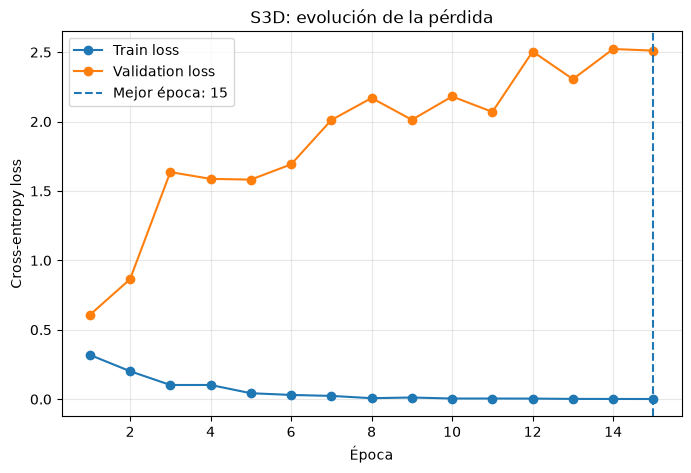

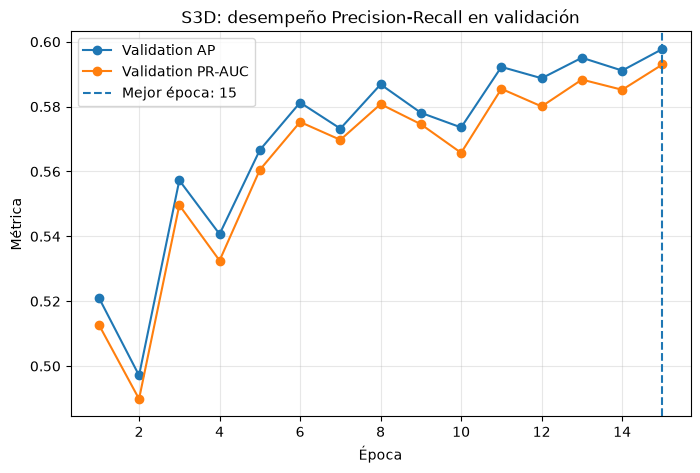

=== DIAGNÓSTICO S3D ===


,momento,epoch,train_loss,val_loss,val_AP,val_PR_AUC
0,primera_epoca,1,0.3193,0.6067,0.5211,0.5128
1,mejor_epoca,15,0.0013,2.5110,0.5978,0.5930


In [48]:
# ============================================================
# Diagnóstico del entrenamiento S3D
# ============================================================

historial_s3d = resultado_s3d[
    "historial"
].copy()


mejor_epoca_s3d = int(
    resultado_s3d[
        "resumen"
    ][
        "mejor_epoca"
    ]
)


# ------------------------------------------------------------
# Evolución de pérdidas
# ------------------------------------------------------------

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    historial_s3d["epoch"],
    historial_s3d["train_loss"],
    marker="o",
    label="Train loss"
)

plt.plot(
    historial_s3d["epoch"],
    historial_s3d["val_loss"],
    marker="o",
    label="Validation loss"
)

plt.axvline(
    mejor_epoca_s3d,
    linestyle="--",
    label=f"Mejor época: {mejor_epoca_s3d}"
)

plt.xlabel(
    "Época"
)

plt.ylabel(
    "Cross-entropy loss"
)

plt.title(
    "S3D: evolución de la pérdida"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.show()


# ------------------------------------------------------------
# Evolución de métricas Precision-Recall
# ------------------------------------------------------------

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    historial_s3d["epoch"],
    historial_s3d[
        "val_average_precision"
    ],
    marker="o",
    label="Validation AP"
)

plt.plot(
    historial_s3d["epoch"],
    historial_s3d[
        "val_pr_auc"
    ],
    marker="o",
    label="Validation PR-AUC"
)

plt.axvline(
    mejor_epoca_s3d,
    linestyle="--",
    label=f"Mejor época: {mejor_epoca_s3d}"
)

plt.xlabel(
    "Época"
)

plt.ylabel(
    "Métrica"
)

plt.title(
    "S3D: desempeño Precision-Recall en validación"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.show()


# ------------------------------------------------------------
# Resumen cuantitativo
# ------------------------------------------------------------

fila_inicial_s3d = historial_s3d.iloc[
    0
]


fila_mejor_s3d = historial_s3d.loc[
    historial_s3d[
        "epoch"
    ]
    == mejor_epoca_s3d
].iloc[0]


diagnostico_s3d = pd.DataFrame(
    [
        {
            "momento": "primera_epoca",
            "epoch": int(
                fila_inicial_s3d[
                    "epoch"
                ]
            ),
            "train_loss": (
                fila_inicial_s3d[
                    "train_loss"
                ]
            ),
            "val_loss": (
                fila_inicial_s3d[
                    "val_loss"
                ]
            ),
            "val_AP": (
                fila_inicial_s3d[
                    "val_average_precision"
                ]
            ),
            "val_PR_AUC": (
                fila_inicial_s3d[
                    "val_pr_auc"
                ]
            )
        },
        {
            "momento": "mejor_epoca",
            "epoch": int(
                fila_mejor_s3d[
                    "epoch"
                ]
            ),
            "train_loss": (
                fila_mejor_s3d[
                    "train_loss"
                ]
            ),
            "val_loss": (
                fila_mejor_s3d[
                    "val_loss"
                ]
            ),
            "val_AP": (
                fila_mejor_s3d[
                    "val_average_precision"
                ]
            ),
            "val_PR_AUC": (
                fila_mejor_s3d[
                    "val_pr_auc"
                ]
            )
        }
    ]
)


print(
    "=== DIAGNÓSTICO S3D ==="
)

display(
    diagnostico_s3d.round(4)
)

#### Conclusiones de 8.3.4 S3D

S3D alcanzó su mayor Average Precision en la época 15, con un valor cercano a 0.598 y un PR-AUC aproximado de 0.593. Debido a que Average Precision es la métrica principal definida para la comparación inicial, se conserva este checkpoint como representante del modelo.

El historial de entrenamiento muestra una separación marcada entre el comportamiento de la pérdida y las métricas basadas en ranking. La pérdida de entrenamiento disminuyó desde aproximadamente 0.319 en la primera época hasta un valor cercano a cero, mientras que la pérdida de validación aumentó de aproximadamente 0.607 a 2.511. Al mismo tiempo, el Average Precision mejoró de alrededor de 0.521 a 0.598 y el PR-AUC de aproximadamente 0.513 a 0.593.

Este comportamiento indica que el modelo mejoró parcialmente su capacidad para ordenar ejemplos positivos y negativos, aunque algunas predicciones incorrectas fueron penalizadas con mayor intensidad por la función de pérdida. El patrón es compatible con predicciones erróneas de alta confianza, aunque la calibración probabilística no fue evaluada directamente en esta etapa.

El checkpoint seleccionado obtuvo un ROC-AUC cercano a 0.660 y un EER aproximado de 0.403. Con el umbral provisional de 0.5, la precisión fue aproximadamente 0.833, pero el recall fue cercano a 0.167 y el F1 alrededor de 0.278. Bajo este umbral, S3D detecta solamente una fracción pequeña de los casos positivos de validación, comportamiento poco favorable para un sistema orientado a generar alertas de ocultamiento.

El entrenamiento completo requirió aproximadamente 65 minutos y registró un pico de memoria CUDA cercano a 3.22 GB. La evaluación de validación procesó alrededor de 3.02 clips por segundo bajo el procedimiento actual de inferencia.

Dentro de las cuatro arquitecturas evaluadas hasta este punto, S3D presenta el menor Average Precision y además requiere más memoria GPU que R3D-18, MC3-18 y R(2+1)D-18. Por estas razones, sus resultados iniciales son menos competitivos para avanzar a la etapa de ajuste, aunque la decisión se realizará después de completar la evaluación de todas las arquitecturas RGB.

#### 8.3.5 MViT-V2-S

MViT-V2-S se evalúa como quinta arquitectura RGB y representa una familia distinta a las redes convolucionales utilizadas en los experimentos anteriores. El modelo emplea una arquitectura Transformer multiescala para video, capaz de representar relaciones espaciales y temporales mediante mecanismos de atención.

La comparación mantiene las mismas particiones del dataset v2, 16 frames por clip, el mismo tamaño de batch, las mismas tasas de aprendizaje iniciales, el mismo número máximo de épocas y Average Precision como métrica principal para seleccionar el checkpoint. La transformación espacial utiliza resolución de 224 × 224 de acuerdo con los requerimientos de los pesos preentrenados de MViT-V2-S.

Además del desempeño predictivo, este experimento permitirá evaluar el costo computacional de una arquitectura Transformer sobre el hardware disponible. La partición de prueba permanece reservada para la etapa posterior de selección y ajuste de modelos.

In [49]:
# ============================================================
# Identidad experimental de MViT-V2-S
# ============================================================

NOMBRE_MODELO_MVIT = "MViT-V2-S"

CHECKPOINT_MVIT_AVANCE4 = (
    CHECKPOINT_DIR
    / "mvit_v2_s_avance4_inicial.pt"
)

HISTORIAL_MVIT_AVANCE4 = (
    CHECKPOINT_DIR
    / "mvit_v2_s_avance4_inicial_history.csv"
)

BATCH_MVIT = CONFIG_BATCH_RGB[
    NOMBRE_MODELO_MVIT
]["batch_size"]


CONFIG_IDENTIDAD_MVIT = {
    "schema_version": 1,
    "modelo": NOMBRE_MODELO_MVIT,
    "seed": SEED,
    "batch_size": BATCH_MVIT,
    "max_epochs": MAX_EPOCHS_RGB,
    "lr_representacion": LR_REPRESENTACION_RGB,
    "lr_clasificador": LR_CLASIFICADOR_RGB,
    "weight_decay": WEIGHT_DECAY_RGB,
    "metrica_checkpoint": METRICA_CHECKPOINT_RGB,
    "dataset_v2_sha256": DATASET_V2_SHA256,
    "n_train": len(df_train_v2),
    "n_validation": len(df_val_v2),
    "num_frames": 16,
    "transformacion": repr(
        TRANSFORMS_RGB[
            NOMBRE_MODELO_MVIT
        ]
    ),
    "bloques_entrenables": [
        "blocks.14",
        "blocks.15",
        "norm",
        "head"
    ]
}


# ------------------------------------------------------------
# Verificaciones
# ------------------------------------------------------------

assert (
    CONFIG_IDENTIDAD_MVIT[
        "dataset_v2_sha256"
    ]
    == DATASET_V2_SHA256
)

assert (
    CONFIG_IDENTIDAD_MVIT[
        "n_train"
    ]
    == 702
)

assert (
    CONFIG_IDENTIDAD_MVIT[
        "n_validation"
    ]
    == 136
)

assert (
    BATCH_MVIT
    == 16
)


# ------------------------------------------------------------
# Resumen
# ------------------------------------------------------------

resumen_identidad_mvit = pd.DataFrame(
    [
        {
            "modelo":
                NOMBRE_MODELO_MVIT,

            "seed":
                SEED,

            "batch":
                BATCH_MVIT,

            "max_epochs":
                MAX_EPOCHS_RGB,

            "lr_representacion":
                LR_REPRESENTACION_RGB,

            "lr_clasificador":
                LR_CLASIFICADOR_RGB,

            "weight_decay":
                WEIGHT_DECAY_RGB,

            "metrica":
                METRICA_CHECKPOINT_RGB,

            "n_train":
                len(df_train_v2),

            "n_validation":
                len(df_val_v2)
        }
    ]
)


display(
    resumen_identidad_mvit
)

print(
    "Dataset v2 SHA-256:",
    DATASET_V2_SHA256
)

print(
    "Checkpoint:",
    CHECKPOINT_MVIT_AVANCE4.relative_to(
        REPO_DIR
    )
)

print(
    "Historial:",
    HISTORIAL_MVIT_AVANCE4.relative_to(
        REPO_DIR
    )
)

,modelo,seed,batch,max_epochs,lr_representacion,lr_clasificador,weight_decay,metrica,n_train,n_validation
0,MViT-V2-S,42,16,15,0.0001,0.001,0.0001,average_precision,702,136


Dataset v2 SHA-256: b85d6b55e8c32420a4df5a0fb9a10e558105beee47f1d4a98ad83d63fcbda21e
Checkpoint: Notebooks/checkpoints/mvit_v2_s_avance4_inicial.pt
Historial: Notebooks/checkpoints/mvit_v2_s_avance4_inicial_history.csv


In [50]:
# ============================================================
# Ejecución protegida del experimento MViT-V2-S
# ============================================================

validacion_mvit = validar_artefactos_rgb(
    checkpoint_path=CHECKPOINT_MVIT_AVANCE4,
    historial_path=HISTORIAL_MVIT_AVANCE4,
    configuracion_esperada=CONFIG_IDENTIDAD_MVIT
)


# ------------------------------------------------------------
# Bloqueo de entrenamiento automático
# ------------------------------------------------------------

if (
    validacion_mvit["estado"] != "validos"
    and not FORCE_RETRAIN_RGB
):
    motivos_mvit = validacion_mvit.get(
        "motivos",
        []
    )

    detalle_mvit = (
        "\n".join(
            f"- {motivo}"
            for motivo in motivos_mvit
        )
        if motivos_mvit
        else "- No hay artefactos válidos disponibles."
    )

    raise RuntimeError(
        "MViT-V2-S no dispone de artefactos válidos "
        "para la configuración actual.\n"
        f"Estado: {validacion_mvit['estado']}\n"
        "El entrenamiento automático está bloqueado.\n\n"
        f"{detalle_mvit}\n\n"
        "Para ejecutar deliberadamente un nuevo entrenamiento, "
        "establezca FORCE_RETRAIN_RGB=True."
    )

# ============================================================
# Reutilizar experimento existente
# ============================================================

if (
    validacion_mvit["estado"] == "validos"
    and not FORCE_RETRAIN_RGB
):

    checkpoint_mvit = validacion_mvit[
        "checkpoint"
    ]

    historial_mvit = validacion_mvit[
        "historial"
    ].copy()


    modelo_mvit_oficial = crear_modelo_rgb(
        NOMBRE_MODELO_MVIT,
        num_classes=2,
        pretrained=True
    )

    modelo_mvit_oficial = (
        configurar_parametros_entrenables(
            modelo_mvit_oficial,
            NOMBRE_MODELO_MVIT
        )
    )

    modelo_mvit_oficial.load_state_dict(
        checkpoint_mvit[
            "model_state_dict"
        ]
    )

    modelo_mvit_oficial = (
        modelo_mvit_oficial.to(
            DEVICE
        )
    )


    resultado_mvit = {
        "modelo":
            modelo_mvit_oficial,

        "historial":
            historial_mvit,

        "resumen":
            checkpoint_mvit[
                "experiment_summary"
            ],

        "checkpoint_path":
            CHECKPOINT_MVIT_AVANCE4,

        "historial_path":
            HISTORIAL_MVIT_AVANCE4
    }


    print(
        "=== MViT-V2-S REUTILIZADO ==="
    )

    print(
        "Entrenamiento omitido: "
        "los artefactos existentes son válidos."
    )


# ============================================================
# Ejecutar entrenamiento
# ============================================================

else:

    if FORCE_RETRAIN_RGB:

        motivo_entrenamiento = (
            "reentrenamiento solicitado explícitamente"
        )

    else:

        motivo_entrenamiento = (
            "artefactos ausentes"
        )


    print(
        "=== MViT-V2-S SERÁ ENTRENADO ==="
    )

    print(
        "Motivo:",
        motivo_entrenamiento
    )


    # --------------------------------------------------------
    # Liberación preventiva de VRAM
    # --------------------------------------------------------

    resultados_previos = [
        "resultado_r3d",
        "resultado_mc3",
        "resultado_r2plus1d",
        "resultado_s3d"
    ]


    for nombre_resultado in resultados_previos:

        if nombre_resultado in globals():

            resultado_previo = globals()[
                nombre_resultado
            ]

            if (
                isinstance(
                    resultado_previo,
                    dict
                )
                and "modelo"
                in resultado_previo
            ):
                resultado_previo[
                    "modelo"
                ] = (
                    resultado_previo[
                        "modelo"
                    ].to(
                        "cpu"
                    )
                )


    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


    # --------------------------------------------------------
    # Reproducibilidad
    # --------------------------------------------------------

    random.seed(
        SEED
    )

    np.random.seed(
        SEED
    )

    torch.manual_seed(
        SEED
    )

    if torch.cuda.is_available():

        torch.cuda.manual_seed_all(
            SEED
        )


    # --------------------------------------------------------
    # Modelo
    # --------------------------------------------------------

    modelo_mvit_oficial = crear_modelo_rgb(
        NOMBRE_MODELO_MVIT,
        num_classes=2,
        pretrained=True
    )

    modelo_mvit_oficial = (
        configurar_parametros_entrenables(
            modelo_mvit_oficial,
            NOMBRE_MODELO_MVIT
        )
    )

    modelo_mvit_oficial = (
        modelo_mvit_oficial.to(
            DEVICE
        )
    )


    # --------------------------------------------------------
    # Optimizador
    # --------------------------------------------------------

    parametros_representacion_mvit = (
        list(
            modelo_mvit_oficial
            .blocks[14]
            .parameters()
        )
        +
        list(
            modelo_mvit_oficial
            .blocks[15]
            .parameters()
        )
        +
        list(
            modelo_mvit_oficial
            .norm
            .parameters()
        )
    )


    optimizador_mvit_oficial = optim.AdamW(
        [
            {
                "params":
                    parametros_representacion_mvit,

                "lr":
                    LR_REPRESENTACION_RGB
            },
            {
                "params":
                    modelo_mvit_oficial
                    .head
                    .parameters(),

                "lr":
                    LR_CLASIFICADOR_RGB
            }
        ],
        weight_decay=WEIGHT_DECAY_RGB
    )


    # --------------------------------------------------------
    # Pérdida y precisión mixta
    # --------------------------------------------------------

    criterio_mvit_oficial = (
        nn.CrossEntropyLoss()
    )


    scaler_mvit_oficial = (
        torch.amp.GradScaler(
            "cuda",
            enabled=(
                USAR_AMP_RGB
                and DEVICE.type == "cuda"
            )
        )
    )


    # --------------------------------------------------------
    # Entrenamiento completo
    # --------------------------------------------------------

    resultado_mvit = entrenar_experimento_rgb(
        modelo=modelo_mvit_oficial,
        nombre_modelo=NOMBRE_MODELO_MVIT,

        loader_train=loaders_rgb[
            NOMBRE_MODELO_MVIT
        ]["train"],

        loader_val=loaders_rgb[
            NOMBRE_MODELO_MVIT
        ]["val"],

        criterio=criterio_mvit_oficial,
        optimizador=optimizador_mvit_oficial,
        scaler=scaler_mvit_oficial,

        device=DEVICE,

        max_epochs=MAX_EPOCHS_RGB,

        checkpoint_path=(
            CHECKPOINT_MVIT_AVANCE4
        ),

        historial_path=(
            HISTORIAL_MVIT_AVANCE4
        ),

        experiment_config=(
            CONFIG_IDENTIDAD_MVIT
        ),

        usar_amp=USAR_AMP_RGB
    )


    # --------------------------------------------------------
    # Validación de artefactos generados
    # --------------------------------------------------------

    validacion_posterior_mvit = (
        validar_artefactos_rgb(
            checkpoint_path=(
                CHECKPOINT_MVIT_AVANCE4
            ),

            historial_path=(
                HISTORIAL_MVIT_AVANCE4
            ),

            configuracion_esperada=(
                CONFIG_IDENTIDAD_MVIT
            )
        )
    )


    if (
        validacion_posterior_mvit[
            "estado"
        ]
        != "validos"
    ):
        detalle = "\n".join(
            f"- {motivo}"
            for motivo
            in validacion_posterior_mvit[
                "motivos"
            ]
        )

        raise RuntimeError(
            "El experimento terminó, pero los "
            "artefactos generados no superaron "
            "la validación.\n\n"
            f"{detalle}"
        )


# ============================================================
# Resumen común
# ============================================================

resumen_mvit_oficial = pd.DataFrame(
    [
        resultado_mvit[
            "resumen"
        ]
    ]
)


print(
    "\n=== RESUMEN MViT-V2-S ==="
)

display(
    resumen_mvit_oficial
)

print(
    "Checkpoint:",
    CHECKPOINT_MVIT_AVANCE4.relative_to(
        REPO_DIR
    )
)

print(
    "Historial:",
    HISTORIAL_MVIT_AVANCE4.relative_to(
        REPO_DIR
    )
)

=== MViT-V2-S REUTILIZADO ===
Entrenamiento omitido: los artefactos existentes son válidos.

=== RESUMEN MViT-V2-S ===


,modelo,epocas_ejecutadas,mejor_epoca,mejor_val_ap,tiempo_entrenamiento_s,gpu_peak_gb
0,MViT-V2-S,15,9,0.647266,4961.575517,5.601562


Checkpoint: Notebooks/checkpoints/mvit_v2_s_avance4_inicial.pt
Historial: Notebooks/checkpoints/mvit_v2_s_avance4_inicial_history.csv


In [51]:
# ============================================================
# Evaluación del mejor checkpoint MViT-V2-S sobre validation
# ============================================================

modelo_mvit_mejor = resultado_mvit[
    "modelo"
]


criterio_mvit_evaluacion = nn.CrossEntropyLoss()


if DEVICE.type == "cuda":
    torch.cuda.synchronize()


inicio_inferencia_mvit = time.perf_counter()


resultado_val_mvit = evaluar_modelo_rgb(
    modelo=modelo_mvit_mejor,
    loader=loaders_rgb[
        NOMBRE_MODELO_MVIT
    ]["val"],
    criterio=criterio_mvit_evaluacion,
    device=DEVICE,
    usar_amp=USAR_AMP_RGB,
    threshold=0.5
)


if DEVICE.type == "cuda":
    torch.cuda.synchronize()


tiempo_inferencia_mvit = (
    time.perf_counter()
    - inicio_inferencia_mvit
)


inferencia_clips_s_mvit = (
    len(df_val_v2)
    / tiempo_inferencia_mvit
)


metricas_val_mvit = resultado_val_mvit[
    "metricas"
]


historial_mvit = resultado_mvit[
    "historial"
].copy()


indice_mejor_mvit = historial_mvit[
    "val_average_precision"
].idxmax()


fila_mejor_mvit = historial_mvit.loc[
    indice_mejor_mvit
]


# ------------------------------------------------------------
# Verificaciones de coherencia
# ------------------------------------------------------------

assert (
    int(
        fila_mejor_mvit[
            "epoch"
        ]
    )
    == 9
)

assert np.isclose(
    metricas_val_mvit[
        "average_precision"
    ],
    resultado_mvit[
        "resumen"
    ][
        "mejor_val_ap"
    ]
)


# ------------------------------------------------------------
# Resumen del checkpoint seleccionado
# ------------------------------------------------------------

resumen_checkpoint_mvit = pd.DataFrame(
    [
        {
            "modelo":
                NOMBRE_MODELO_MVIT,

            "mejor_epoca":
                int(
                    fila_mejor_mvit[
                        "epoch"
                    ]
                ),

            "val_loss":
                resultado_val_mvit[
                    "loss"
                ],

            "val_average_precision":
                metricas_val_mvit[
                    "average_precision"
                ],

            "val_pr_auc":
                metricas_val_mvit[
                    "pr_auc"
                ],

            "val_roc_auc":
                metricas_val_mvit[
                    "roc_auc"
                ],

            "val_eer":
                metricas_val_mvit[
                    "eer"
                ],

            "val_precision_05":
                metricas_val_mvit[
                    "precision"
                ],

            "val_recall_05":
                metricas_val_mvit[
                    "recall"
                ],

            "val_specificity_05":
                metricas_val_mvit[
                    "specificity"
                ],

            "val_f1_05":
                metricas_val_mvit[
                    "f1"
                ],

            "inferencia_clips_s":
                inferencia_clips_s_mvit
        }
    ]
)


print(
    "=== MEJOR CHECKPOINT MViT-V2-S ==="
)

display(
    resumen_checkpoint_mvit.round(4)
)

=== MEJOR CHECKPOINT MViT-V2-S ===


,modelo,mejor_epoca,val_loss,val_average_precision,val_pr_auc,val_roc_auc,val_eer,val_precision_05,val_recall_05,val_specificity_05,val_f1_05,inferencia_clips_s
0,MViT-V2-S,9,0.7369,0.6473,0.6578,0.7473,0.3767,0.5278,0.6333,0.8396,0.5758,2.2751


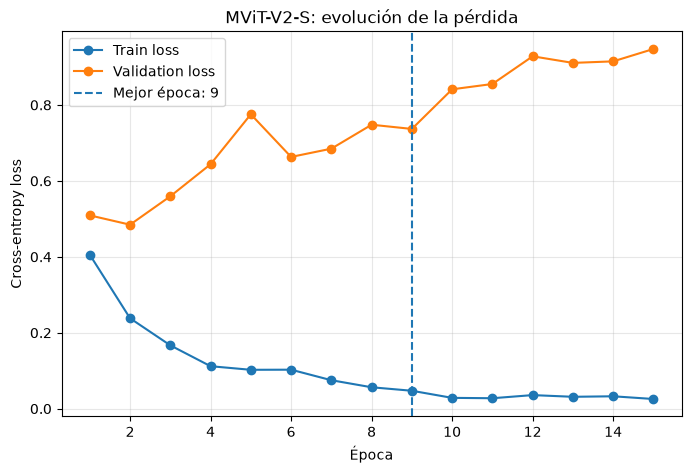

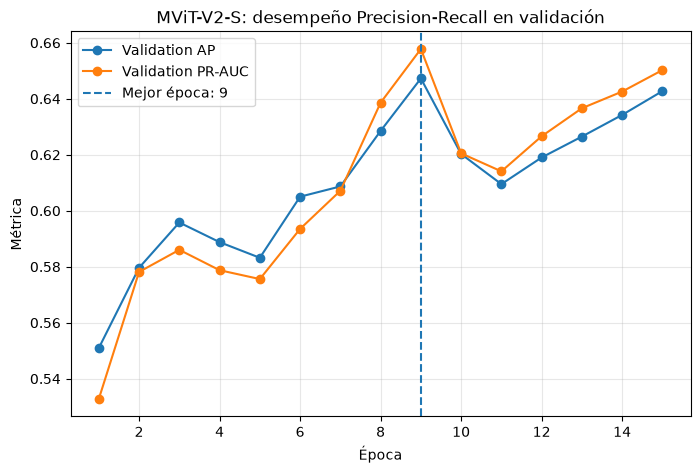

=== DIAGNÓSTICO MViT-V2-S ===


,momento,epoch,train_loss,val_loss,val_AP,val_PR_AUC
0,mejor_epoca,9,0.0472,0.7369,0.6473,0.6578
1,ultima_epoca,15,0.0256,0.9474,0.6427,0.6503


In [52]:
# ============================================================
# Diagnóstico del entrenamiento MViT-V2-S
# ============================================================

historial_mvit = resultado_mvit[
    "historial"
].copy()


mejor_epoca_mvit = int(
    resultado_mvit[
        "resumen"
    ][
        "mejor_epoca"
    ]
)


# ------------------------------------------------------------
# Evolución de pérdidas
# ------------------------------------------------------------

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    historial_mvit["epoch"],
    historial_mvit["train_loss"],
    marker="o",
    label="Train loss"
)

plt.plot(
    historial_mvit["epoch"],
    historial_mvit["val_loss"],
    marker="o",
    label="Validation loss"
)

plt.axvline(
    mejor_epoca_mvit,
    linestyle="--",
    label=f"Mejor época: {mejor_epoca_mvit}"
)

plt.xlabel(
    "Época"
)

plt.ylabel(
    "Cross-entropy loss"
)

plt.title(
    "MViT-V2-S: evolución de la pérdida"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.show()


# ------------------------------------------------------------
# Evolución de métricas Precision-Recall
# ------------------------------------------------------------

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    historial_mvit["epoch"],
    historial_mvit[
        "val_average_precision"
    ],
    marker="o",
    label="Validation AP"
)

plt.plot(
    historial_mvit["epoch"],
    historial_mvit[
        "val_pr_auc"
    ],
    marker="o",
    label="Validation PR-AUC"
)

plt.axvline(
    mejor_epoca_mvit,
    linestyle="--",
    label=f"Mejor época: {mejor_epoca_mvit}"
)

plt.xlabel(
    "Época"
)

plt.ylabel(
    "Métrica"
)

plt.title(
    "MViT-V2-S: desempeño Precision-Recall en validación"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.show()


# ------------------------------------------------------------
# Resumen cuantitativo
# ------------------------------------------------------------

fila_mejor_mvit = historial_mvit.loc[
    historial_mvit[
        "epoch"
    ]
    == mejor_epoca_mvit
].iloc[0]


fila_final_mvit = historial_mvit.iloc[
    -1
]


diagnostico_mvit = pd.DataFrame(
    [
        {
            "momento": "mejor_epoca",
            "epoch": int(
                fila_mejor_mvit[
                    "epoch"
                ]
            ),
            "train_loss": (
                fila_mejor_mvit[
                    "train_loss"
                ]
            ),
            "val_loss": (
                fila_mejor_mvit[
                    "val_loss"
                ]
            ),
            "val_AP": (
                fila_mejor_mvit[
                    "val_average_precision"
                ]
            ),
            "val_PR_AUC": (
                fila_mejor_mvit[
                    "val_pr_auc"
                ]
            )
        },
        {
            "momento": "ultima_epoca",
            "epoch": int(
                fila_final_mvit[
                    "epoch"
                ]
            ),
            "train_loss": (
                fila_final_mvit[
                    "train_loss"
                ]
            ),
            "val_loss": (
                fila_final_mvit[
                    "val_loss"
                ]
            ),
            "val_AP": (
                fila_final_mvit[
                    "val_average_precision"
                ]
            ),
            "val_PR_AUC": (
                fila_final_mvit[
                    "val_pr_auc"
                ]
            )
        }
    ]
)


print(
    "=== DIAGNÓSTICO MViT-V2-S ==="
)

display(
    diagnostico_mvit.round(4)
)

#### Conclusiones de 8.3.5 MViT-V2-S

MViT-V2-S alcanzó su mejor desempeño de validación en la época 9, con un Average Precision cercano a 0.647 y un PR-AUC aproximado de 0.658. Este checkpoint se conserva como representante del modelo debido a que Average Precision es la métrica principal definida para la comparación inicial.

El historial muestra evidencia de sobreajuste después de la mejor época. En la época 9, la pérdida de entrenamiento era aproximadamente 0.047 y la pérdida de validación alrededor de 0.737. Al finalizar las 15 épocas, la pérdida de entrenamiento disminuyó a aproximadamente 0.026 mientras que la pérdida de validación aumentó hasta cerca de 0.947.

Las métricas basadas en ranking se mantuvieron relativamente estables después de la mejor época. El Average Precision disminuyó ligeramente de aproximadamente 0.647 a 0.643 y el PR-AUC de alrededor de 0.658 a 0.650. Esto indica que el deterioro posterior afectó con mayor intensidad la pérdida que la capacidad relativa de ordenar ejemplos positivos y negativos.

El checkpoint seleccionado obtuvo un ROC-AUC cercano a 0.747 y un EER aproximado de 0.377. Con el umbral provisional de 0.5, la precisión fue alrededor de 0.528, el recall aproximadamente 0.633 y el F1 cercano a 0.576. La optimización del umbral se mantiene fuera de esta etapa inicial.

El entrenamiento completo requirió aproximadamente 83 minutos y registró un pico de memoria CUDA cercano a 5.6 GB. La evaluación de validación procesó alrededor de 2.26 clips por segundo. Estas mediciones muestran que MViT-V2-S es la arquitectura con mayor demanda computacional entre los cinco modelos RGB evaluados.

Por Average Precision, MViT-V2-S ocupa provisionalmente el segundo lugar de la comparación inicial. Su desempeño predictivo es competitivo, aunque su mayor consumo de memoria, mayor tiempo de entrenamiento y menor velocidad de inferencia deberán considerarse junto con las métricas al seleccionar los modelos candidatos para ajuste de hiperparámetros.

### 8.4 Comparación inicial de arquitecturas RGB

Después de entrenar y evaluar las cinco arquitecturas RGB bajo un protocolo común, se realiza una comparación conjunta sobre la partición de validación del dataset v2.

Average Precision se mantiene como métrica principal debido al desbalance entre las clases y a su capacidad para resumir el comportamiento Precision-Recall sin depender de un único umbral de decisión. Como métricas secundarias se consideran PR-AUC, ROC-AUC y EER. Las métricas calculadas con umbral 0.5 se conservan como referencia descriptiva, pero no determinan por sí solas la selección de modelos.

La comparación también incorpora indicadores de costo computacional, incluyendo tiempo de entrenamiento, pico de memoria CUDA y velocidad de inferencia. Estos factores son relevantes para el proyecto debido a las restricciones del hardware disponible y a la posible evaluación posterior de alternativas para despliegue.

Esta sección compara únicamente las cinco arquitecturas RGB bajo condiciones directamente comparables. La selección de los dos candidatos para ajuste de hiperparámetros se realizará después de incorporar el experimento basado en pose y revisar las diferencias metodológicas entre ambos tipos de representación.

In [53]:
# ============================================================
# Comparación inicial de los cinco modelos RGB
# ============================================================

experimentos_rgb = [
    {
        "resultado":
            resultado_r3d,

        "metricas":
            resumen_checkpoint_r3d.iloc[0]
    },
    {
        "resultado":
            resultado_mc3,

        "metricas":
            resumen_checkpoint_mc3.iloc[0]
    },
    {
        "resultado":
            resultado_r2plus1d,

        "metricas":
            resumen_checkpoint_r2plus1d.iloc[0]
    },
    {
        "resultado":
            resultado_s3d,

        "metricas":
            resumen_checkpoint_s3d.iloc[0]
    },
    {
        "resultado":
            resultado_mvit,

        "metricas":
            resumen_checkpoint_mvit.iloc[0]
    }
]


filas_comparacion_rgb = []


for experimento in experimentos_rgb:

    resultado = experimento[
        "resultado"
    ]

    metricas = experimento[
        "metricas"
    ]

    modelo = resultado[
        "modelo"
    ]

    resumen = resultado[
        "resumen"
    ]


    parametros_totales = sum(
        p.numel()
        for p in modelo.parameters()
    )


    parametros_entrenables = sum(
        p.numel()
        for p in modelo.parameters()
        if p.requires_grad
    )


    porcentaje_entrenable = (
        100
        * parametros_entrenables
        / parametros_totales
    )


    filas_comparacion_rgb.append(
        {
            "modelo":
                metricas[
                    "modelo"
                ],

            "parametros_totales":
                parametros_totales,

            "parametros_entrenables":
                parametros_entrenables,

            "porcentaje_entrenable":
                porcentaje_entrenable,

            "mejor_epoca":
                int(
                    metricas[
                        "mejor_epoca"
                    ]
                ),

            "val_average_precision":
                metricas[
                    "val_average_precision"
                ],

            "val_pr_auc":
                metricas[
                    "val_pr_auc"
                ],

            "val_roc_auc":
                metricas[
                    "val_roc_auc"
                ],

            "val_eer":
                metricas[
                    "val_eer"
                ],

            "val_precision_05":
                metricas[
                    "val_precision_05"
                ],

            "val_recall_05":
                metricas[
                    "val_recall_05"
                ],

            "val_specificity_05":
                metricas[
                    "val_specificity_05"
                ],

            "val_f1_05":
                metricas[
                    "val_f1_05"
                ],

            "tiempo_entrenamiento_s":
                resumen[
                    "tiempo_entrenamiento_s"
                ],

            "gpu_peak_gb":
                resumen[
                    "gpu_peak_gb"
                ],

            "inferencia_clips_s":
                metricas[
                    "inferencia_clips_s"
                ]
        }
    )


comparacion_rgb = pd.DataFrame(
    filas_comparacion_rgb
)


comparacion_rgb = (
    comparacion_rgb
    .sort_values(
        by="val_average_precision",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)


comparacion_rgb.insert(
    0,
    "ranking_ap",
    range(
        1,
        len(comparacion_rgb) + 1
    )
)


# ------------------------------------------------------------
# Verificaciones
# ------------------------------------------------------------

assert (
    len(
        comparacion_rgb
    )
    == 5
)

assert (
    comparacion_rgb[
        "val_average_precision"
    ]
    .is_monotonic_decreasing
)

assert (
    comparacion_rgb[
        "modelo"
    ]
    .nunique()
    == 5
)


print(
    "=== COMPARACIÓN INICIAL DE MODELOS RGB ==="
)

display(
    comparacion_rgb
)

=== COMPARACIÓN INICIAL DE MODELOS RGB ===


,ranking_ap,modelo,parametros_totales,parametros_entrenables,porcentaje_entrenable,mejor_epoca,val_average_precision,val_pr_auc,val_roc_auc,val_eer,val_precision_05,val_recall_05,val_specificity_05,val_f1_05,tiempo_entrenamiento_s,gpu_peak_gb,inferencia_clips_s
0,1,R(2+1)D-18,31301151,14163458,45.249001,4,0.673027,0.669550,0.738679,0.322327,0.782609,0.600000,0.952830,0.679245,3781.225018,2.320312,3.071819
1,2,MViT-V2-S,34231682,13616258,39.776772,9,0.647266,0.657785,0.747327,0.376730,0.527778,0.633333,0.839623,0.575758,4961.575517,5.601562,2.275130
2,3,MC3-18,11491266,4721666,41.089172,7,0.644193,0.641329,0.749214,0.310377,0.486486,0.600000,0.820755,0.537313,3736.294595,1.269531,3.199691
3,4,R3D-18,33167298,14158850,42.689187,2,0.615926,0.611003,0.703774,0.381447,0.823529,0.466667,0.971698,0.595745,3975.562664,1.185547,3.342274
4,5,S3D,7912098,3177826,40.164139,15,0.597776,0.592998,0.660377,0.402830,0.833333,0.166667,0.990566,0.277778,3929.891396,3.222656,3.052835


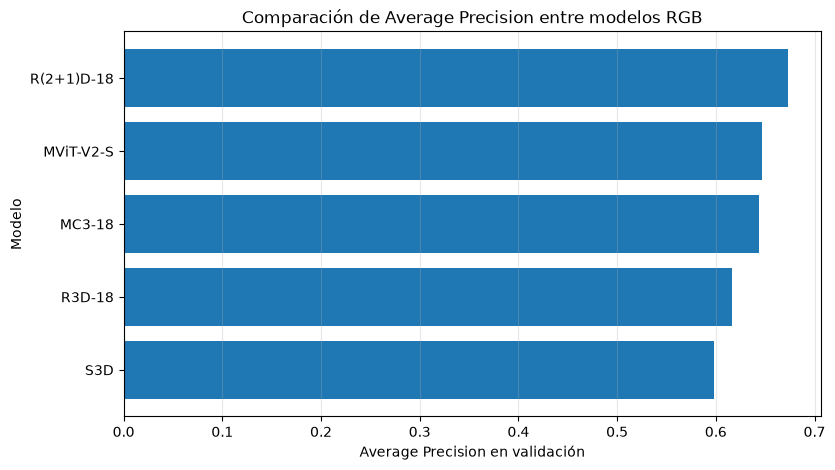

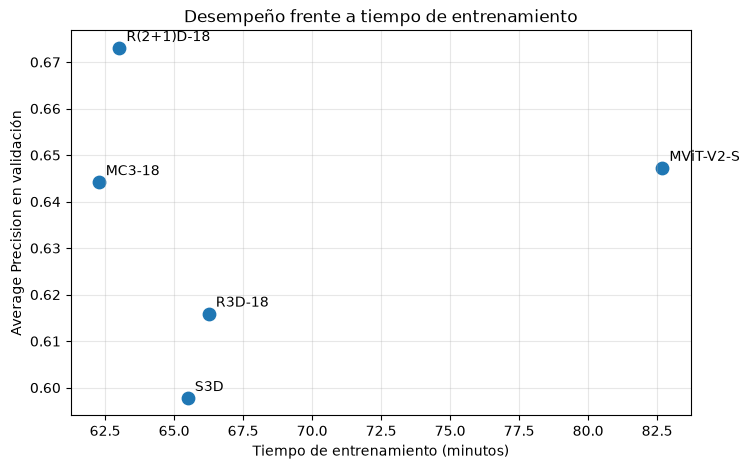

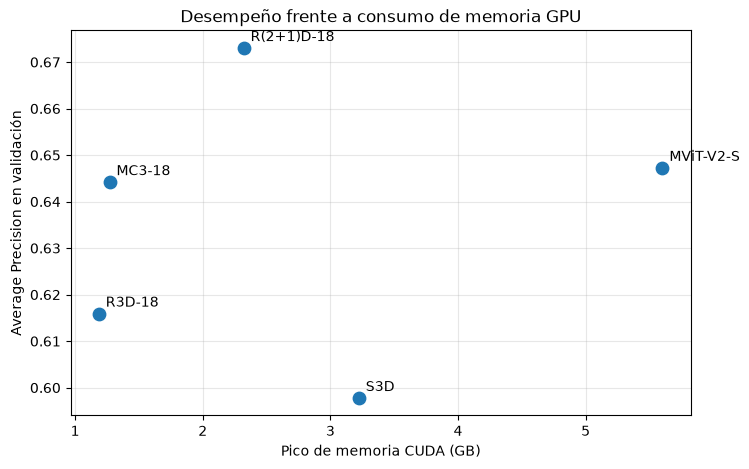

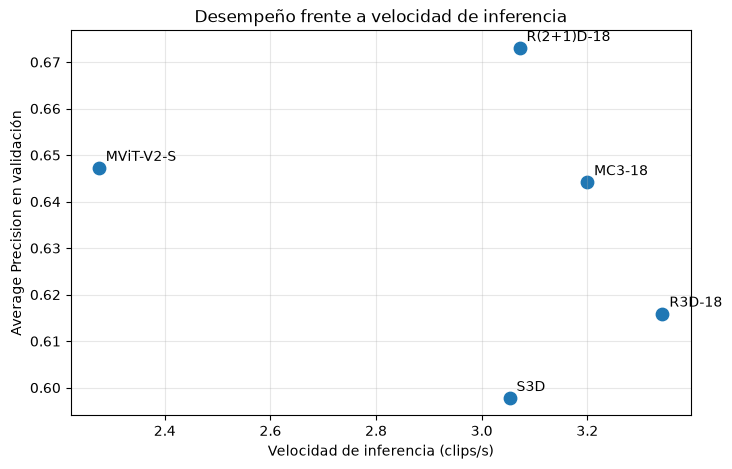

In [54]:
# ============================================================
# Visualización comparativa de desempeño y costo computacional
# ============================================================

comparacion_rgb_plot = comparacion_rgb.copy()


# ------------------------------------------------------------
# Ranking por Average Precision
# ------------------------------------------------------------

plt.figure(
    figsize=(9, 5)
)

orden_ap = (
    comparacion_rgb_plot
    .sort_values(
        "val_average_precision",
        ascending=True
    )
)

plt.barh(
    orden_ap["modelo"],
    orden_ap["val_average_precision"]
)

plt.xlabel(
    "Average Precision en validación"
)

plt.ylabel(
    "Modelo"
)

plt.title(
    "Comparación de Average Precision entre modelos RGB"
)

plt.grid(
    axis="x",
    alpha=0.3
)

plt.show()


# ------------------------------------------------------------
# Average Precision frente a tiempo de entrenamiento
# ------------------------------------------------------------

plt.figure(
    figsize=(8, 5)
)

tiempo_min_rgb = (
    comparacion_rgb_plot[
        "tiempo_entrenamiento_s"
    ]
    / 60
)

plt.scatter(
    tiempo_min_rgb,
    comparacion_rgb_plot[
        "val_average_precision"
    ],
    s=80
)

for _, fila in comparacion_rgb_plot.iterrows():

    plt.annotate(
        fila["modelo"],
        (
            fila[
                "tiempo_entrenamiento_s"
            ]
            / 60,
            fila[
                "val_average_precision"
            ]
        ),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.xlabel(
    "Tiempo de entrenamiento (minutos)"
)

plt.ylabel(
    "Average Precision en validación"
)

plt.title(
    "Desempeño frente a tiempo de entrenamiento"
)

plt.grid(
    alpha=0.3
)

plt.show()


# ------------------------------------------------------------
# Average Precision frente a memoria GPU
# ------------------------------------------------------------

plt.figure(
    figsize=(8, 5)
)

plt.scatter(
    comparacion_rgb_plot[
        "gpu_peak_gb"
    ],
    comparacion_rgb_plot[
        "val_average_precision"
    ],
    s=80
)

for _, fila in comparacion_rgb_plot.iterrows():

    plt.annotate(
        fila["modelo"],
        (
            fila[
                "gpu_peak_gb"
            ],
            fila[
                "val_average_precision"
            ]
        ),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.xlabel(
    "Pico de memoria CUDA (GB)"
)

plt.ylabel(
    "Average Precision en validación"
)

plt.title(
    "Desempeño frente a consumo de memoria GPU"
)

plt.grid(
    alpha=0.3
)

plt.show()


# ------------------------------------------------------------
# Average Precision frente a velocidad de inferencia
# ------------------------------------------------------------

plt.figure(
    figsize=(8, 5)
)

plt.scatter(
    comparacion_rgb_plot[
        "inferencia_clips_s"
    ],
    comparacion_rgb_plot[
        "val_average_precision"
    ],
    s=80
)

for _, fila in comparacion_rgb_plot.iterrows():

    plt.annotate(
        fila["modelo"],
        (
            fila[
                "inferencia_clips_s"
            ],
            fila[
                "val_average_precision"
            ]
        ),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.xlabel(
    "Velocidad de inferencia (clips/s)"
)

plt.ylabel(
    "Average Precision en validación"
)

plt.title(
    "Desempeño frente a velocidad de inferencia"
)

plt.grid(
    alpha=0.3
)

plt.show()

#### Conclusiones de 8.4 Comparación inicial de arquitecturas RGB

La comparación conjunta muestra diferencias tanto en desempeño predictivo como en costo computacional entre las cinco arquitecturas RGB evaluadas.

R(2+1)D-18 obtuvo el mayor Average Precision de validación, con un valor cercano a 0.673. Además, mantuvo un tiempo de entrenamiento similar al de las arquitecturas convolucionales restantes, un consumo de memoria intermedio y una velocidad de inferencia cercana a 3.19 clips por segundo. Dentro de esta comparación inicial, presenta el mejor equilibrio entre la métrica principal y los recursos utilizados.

MViT-V2-S y MC3-18 ocuparon las siguientes posiciones por Average Precision, con valores cercanos a 0.647 y 0.644 respectivamente. La diferencia entre ambos es pequeña, mientras que su costo computacional es considerablemente distinto. MViT-V2-S requirió aproximadamente 5.6 GB de memoria CUDA y alrededor de 83 minutos de entrenamiento, mientras que MC3-18 utilizó aproximadamente 1.27 GB y alrededor de 62 minutos. MC3-18 también obtuvo el mayor ROC-AUC y el menor EER entre las cinco arquitecturas.

R3D-18 alcanzó un Average Precision cercano a 0.616. Aunque presentó el menor pico de memoria CUDA y la mayor velocidad de inferencia observada, su desempeño predictivo quedó por debajo de R(2+1)D-18, MViT-V2-S y MC3-18.

S3D obtuvo el menor Average Precision, cercano a 0.598, y tampoco mostró una ventaja computacional suficiente para compensar esa diferencia. Su comportamiento con el umbral provisional de 0.5 también presentó un recall particularmente bajo.

Las visualizaciones muestran que una mayor complejidad arquitectónica o un mayor consumo de recursos no se traducen necesariamente en mejor desempeño. En particular, el Transformer MViT-V2-S presenta un costo considerablemente mayor que MC3-18 para una diferencia pequeña en Average Precision.

Por el momento no se seleccionan los dos modelos finalistas. Esta comparación corresponde únicamente a las arquitecturas RGB directamente comparables. La decisión se realizará después de incorporar el experimento basado en pose y analizar las diferencias metodológicas entre ambas representaciones.

### 8.5 Preparación de RetailS para STG-NF

El sexto experimento utiliza STG-NF, un modelo de detección de anomalías basado en secuencias de pose y normalizing flows sobre grafos espacio-temporales (Hirschorn & Avidan, 2023). RetailS requiere una preparación distinta a la utilizada por los cinco modelos RGB, por lo que se implementó un pipeline específico y reproducible antes del entrenamiento.

Los archivos originales de RetailS representan cada observación mediante 17 articulaciones COCO con coordenadas `x`, `y` y confianza. La implementación oficial de STG-NF contempla la conversión de esqueletos COCO17 a COCO18 mediante la incorporación del punto de cuello, calculado a partir de los hombros, y un reordenamiento posterior de las articulaciones. Esta misma convención se conserva en el experimento del proyecto.

A partir de la validación estructural, temporal y numérica realizada sobre RetailS se definió la siguiente preparación:

| Elemento | Configuración |
|---|---|
| Representación original | COCO17 con `x`, `y` y confianza |
| Representación para STG-NF | COCO18 |
| Canales predictivos | `x`, `y` |
| Longitud temporal | 16 cuadros |
| Stride de entrenamiento | 8 |
| Stride de evaluación | 1 |
| Resolución de referencia | 1080 × 1920 |
| Normalización | Normalización espacial compatible con STG-NF por ventana |
| Unidad temporal | Ventanas consecutivas de una misma persona |
| Formato persistente | NPZ sin compresión |

La conversión COCO17 a COCO18 y la estructura de entrada siguen la representación utilizada por la implementación oficial de STG-NF. La longitud temporal, los strides, la persistencia en NPZ y la estrategia de construcción de ventanas corresponden a decisiones experimentales adoptadas para RetailS después de revisar su estructura y las condiciones de ejecución disponibles.

Las ventanas se construyen únicamente dentro de trayectorias temporalmente consecutivas de una misma persona, evitando combinar identidades o atravesar interrupciones de cuadros.

La preparación detallada se implementó en scripts independientes dentro de `Datos/Preparacion_Datasets/scripts`. Estos scripts cubren la validación estructural y numérica, alineación temporal, análisis de trayectorias, selección de longitud y stride, transformación COCO17 a COCO18, normalización espacial, construcción del índice temporal, análisis del acceso a los datos, muestreo por bloques y generación y validación de la representación NPZ.

El script `orquestar_preparacion_retails_stgnf.py` proporciona una comprobación integrada del estado final del conjunto preparado y permite repetir las validaciones detalladas cuando sea necesario, sin incorporar toda esa lógica operativa al notebook.

**Referencias utilizadas en esta sección**

- Hirschorn, O., & Avidan, S. (2023). *Normalizing Flows for Human Pose Anomaly Detection*. Proceedings of the IEEE/CVF International Conference on Computer Vision, 13545-13554. https://openaccess.thecvf.com/content/ICCV2023/html/Hirschorn_Normalizing_Flows_for_Human_Pose_Anomaly_Detection_ICCV_2023_paper.html
- Hirschorn, O., & Avidan, S. (2023). *STG-NF: Official PyTorch implementation*. Archivo `dataset.py`, commit `edb5f3220332e160e4d20ce258787d5e2d7e0200`. https://github.com/orhir/STG-NF/blob/edb5f3220332e160e4d20ce258787d5e2d7e0200/dataset.py

In [55]:
# ============================================================
# Estado de la preparación de RetailS para STG-NF
# ============================================================

import importlib

import Datos.Preparacion_Datasets.scripts.orquestar_preparacion_retails_stgnf as preparacion_retails_stgnf

preparacion_retails_stgnf = importlib.reload(
    preparacion_retails_stgnf
)

estado_preparacion_stgnf = (
    preparacion_retails_stgnf.mostrar_estado()
)

assert estado_preparacion_stgnf["listo"], (
    "La preparación de RetailS para STG-NF "
    "requiere revisión."
)

=== PREPARACIÓN RETAILS PARA STG-NF ===
Representación: COCO18 XY
Ventana temporal: 16 frames
Stride entrenamiento: 8
Stride evaluación: 1

Ventanas:
  RetailS_train: 909689
  RetailS_test_staged: 33857
  RetailS_test_realworld: 3501
  Total: 947047
  Duplicados: 0

Caché NPZ:
  train: 942
  staged: 624
  realworld: 47
  Total: 1613

Estado: LISTO PARA STG-NF


In [56]:
# ============================================================
# Equivalencia entre la fuente JSON y la caché NPZ
# ============================================================

import importlib

import Datos.Preparacion_Datasets.scripts.dataset_retails_stgnf_npz as dataset_retails_npz

dataset_retails_npz = importlib.reload(
    dataset_retails_npz
)

tabla_equivalencia_stgnf = (
    dataset_retails_npz.validar_equivalencia_json_npz()
)

display(
    tabla_equivalencia_stgnf
)

assert bool(
    tabla_equivalencia_stgnf[
        "equivalente"
    ].all()
), (
    "La representación NPZ no es "
    "equivalente a la fuente JSON."
)

assert bool(
    tabla_equivalencia_stgnf[
        "finito"
    ].all()
), (
    "La representación NPZ contiene "
    "valores no finitos."
)

,particion,shape_json,shape_npz,diferencia_maxima,equivalente,finito
0,RetailS_train,"(2, 16, 18)","(2, 16, 18)",0.0,True,True
1,RetailS_test_staged,"(2, 16, 18)","(2, 16, 18)",0.0,True,True
2,RetailS_test_realworld,"(2, 16, 18)","(2, 16, 18)",0.0,True,True


#### Resultado de la preparación de RetailS

La preparación generó **947,047 ventanas temporales**: 909,689 para entrenamiento, 33,857 para `RetailS_test_staged` y 3,501 para `RetailS_test_realworld`. El índice no presenta duplicados.

La representación persistente contiene **1,613 archivos NPZ**: 942 de entrenamiento, 624 de evaluación staged y 47 de evaluación real-world. La comprobación del estado no identificó archivos faltantes, incompatibles ni huérfanos.

Como verificación de la transformación, se comparó una ventana representativa de cada partición obtenida directamente desde los archivos JSON con la misma ventana reconstruida desde NPZ. En los tres casos se obtuvo un tensor de forma `(2, 16, 18)`, todos los valores fueron finitos y la diferencia máxima observada fue `0.0`.

Estos resultados documentan que la representación NPZ utilizada como entrada de STG-NF conserva numéricamente las ventanas generadas a partir de los datos fuente y que las tres particiones requeridas se encuentran disponibles para las siguientes etapas del experimento.

### 8.6 Experimento 6: STG-NF sobre RetailS

#### 8.6.1 Arquitectura y configuración base

El sexto experimento utiliza STG-NF como modelo de detección de anomalías basado exclusivamente en pose. El método propuesto por Hirschorn y Avidan (2023) combina normalizing flows con bloques de convolución sobre grafos espacio-temporales para modelar la distribución de secuencias de pose consideradas normales.

La configuración inicial conserva los principales parámetros de la implementación oficial de STG-NF utilizada como referencia en este experimento: ocho pasos de flujo por nivel (`K = 8`), un nivel (`L = 1`), bloques ST-GCN, acoplamiento afín, normalización ActNorm y permutación de canales. La implementación empleada se fija posteriormente a un commit específico para asegurar que la arquitectura utilizada pueda reproducirse.

La entrada validada para este proyecto tiene dimensiones `2 × 16 × 18`, correspondientes a coordenadas `x` e `y`, 16 cuadros consecutivos y 18 articulaciones en el orden requerido por STG-NF. El canal de confianza no se utilizará como variable predictiva en este experimento inicial.

Como configuración base se toman también como referencia los hiperparámetros utilizados por la implementación seleccionada: optimizador Adamax, tasa de aprendizaje inicial de `5e-4`, regularización por peso de `5e-5` y ocho épocas. El tamaño de batch no se adopta directamente de la referencia, sino que se determina experimentalmente con el hardware disponible y el pipeline preparado para RetailS.

Este experimento se evaluará de forma independiente de los modelos RGB porque utiliza otro conjunto de datos, otra representación de entrada y una formulación de detección de anomalías. Sus resultados servirán para valorar la viabilidad del enfoque basado en pose dentro del alcance del proyecto.

**Referencias utilizadas en esta sección**

- Hirschorn, O., & Avidan, S. (2023). *Normalizing Flows for Human Pose Anomaly Detection*. Proceedings of the IEEE/CVF International Conference on Computer Vision, 13545-13554. https://openaccess.thecvf.com/content/ICCV2023/html/Hirschorn_Normalizing_Flows_for_Human_Pose_Anomaly_Detection_ICCV_2023_paper.html
- Hirschorn, O., & Avidan, S. (2023). *STG-NF: Official PyTorch implementation*. Commit `edb5f3220332e160e4d20ce258787d5e2d7e0200`. https://github.com/orhir/STG-NF/tree/edb5f3220332e160e4d20ce258787d5e2d7e0200

In [57]:
# ============================================================
# Datos preparados y componentes de entrada para STG-NF
# ============================================================

from Datos.Preparacion_Datasets.scripts.construir_cache_retails_stgnf import (
    VERSION_CACHE_STGNF
)

from Datos.Preparacion_Datasets.scripts.dataset_retails_stgnf_npz import (
    RetailSSTGNFDatasetNPZ,
    SEG_LEN_STGNF,
    VID_RES_RETAILS,
    cargar_indice,
    obtener_particiones_cache
)

from Datos.Preparacion_Datasets.scripts.muestreo_stgnf import (
    MuestreadorBloquesArchivo
)

from Datos.Preparacion_Datasets.scripts.preparar_retails_stgnf import (
    normalizar_pose_stgnf
)


SEG_STRIDE_TRAIN_STGNF = 8
SEG_STRIDE_TEST_STGNF = 1

MODEL_CONFIDENCE_STGNF = False

SEMILLA_MUESTREO_STGNF = 42


indice_validado_stgnf = (
    cargar_indice()
)

indice_train_stgnf = (
    indice_validado_stgnf[
        indice_validado_stgnf[
            "particion"
        ]
        == "RetailS_train"
    ]
    .reset_index(
        drop=True
    )
    .copy()
)

PARTICIONES_CACHE_DATASET_STGNF = (
    obtener_particiones_cache()
)


assert len(
    indice_validado_stgnf
) == 947047

assert len(
    indice_train_stgnf
) == 909689

assert SEG_LEN_STGNF == 16

assert tuple(
    VID_RES_RETAILS.tolist()
) == (
    1080.0,
    1920.0
)


print(
    "Ventanas totales:",
    len(
        indice_validado_stgnf
    )
)

print(
    "Ventanas entrenamiento:",
    len(
        indice_train_stgnf
    )
)

print(
    "Entrada STG-NF:",
    (
        2,
        SEG_LEN_STGNF,
        18
    )
)

print(
    "Stride train/test:",
    (
        SEG_STRIDE_TRAIN_STGNF,
        SEG_STRIDE_TEST_STGNF
    )
)

print(
    "Sampler:",
    "bloques de 16, semilla 42"
)

print(
    "Versión caché:",
    VERSION_CACHE_STGNF
)

Ventanas totales: 947047
Ventanas entrenamiento: 909689
Entrada STG-NF: (2, 16, 18)
Stride train/test: (8, 1)
Sampler: bloques de 16, semilla 42
Versión caché: 1


#### 8.6.2 Incorporación reproducible de la implementación oficial

Para conservar fidelidad con STG-NF se utiliza la implementación pública proporcionada por los autores en el repositorio oficial `orhir/STG-NF`, en lugar de reproducir manualmente la arquitectura dentro del notebook.

La dependencia se fija al commit:

`edb5f3220332e160e4d20ce258787d5e2d7e0200`

De esta forma, la arquitectura y el comportamiento del modelo utilizados en el experimento quedan asociados a una versión concreta del código. Esto evita que modificaciones posteriores del repositorio original alteren silenciosamente la ejecución o dificulten la reproducción de los resultados.

La separación entre código externo y código desarrollado para el proyecto también permite identificar con claridad el origen de cada componente. La definición de STG-NF se conserva a partir de la implementación oficial, mientras que la preparación de RetailS, construcción de ventanas, almacenamiento NPZ, estrategia de acceso, muestreo por bloques, protección del entrenamiento y adaptación del procedimiento de evaluación corresponden al pipeline desarrollado para este experimento.

Antes de utilizar la dependencia se verifican tres condiciones:

1. el repositorio se encuentra disponible
2. el commit cargado coincide con el commit fijado para el experimento
3. la clase `STG_NF` puede importarse y ejecutar un `forward` válido utilizando una muestra real de RetailS

Estas comprobaciones permiten relacionar los resultados posteriores con una versión determinada tanto de los datos preparados como de la implementación externa utilizada.

**Referencia de implementación**

- Hirschorn, O., & Avidan, S. (2023). *STG-NF: Official PyTorch implementation*. Commit `edb5f3220332e160e4d20ce258787d5e2d7e0200`. https://github.com/orhir/STG-NF/tree/edb5f3220332e160e4d20ce258787d5e2d7e0200

In [58]:
# ============================================================
# Dependencia reproducible de STG-NF
# Versión corregida para Run All
# ============================================================

import importlib
import shutil
import subprocess
import sys
from pathlib import Path


STGNF_REPO_URL = (
    "https://github.com/orhir/STG-NF.git"
)

STGNF_COMMIT = (
    "edb5f3220332e160e4d20ce258787d5e2d7e0200"
)

STGNF_REPO_DIR = (
    REPO_DIR
    / "Dependencias"
    / "STG-NF"
)


def ejecutar_git_stgnf(
    argumentos,
    cwd=None
):

    resultado = subprocess.run(
        [
            "git",
            *argumentos
        ],
        cwd=cwd,
        capture_output=True,
        text=True
    )


    if resultado.returncode != 0:

        raise RuntimeError(
            "Falló una operación Git necesaria "
            "para preparar la dependencia STG-NF."
        )


    return resultado.stdout.strip()


# ------------------------------------------------------------
# Verificar disponibilidad de Git
# ------------------------------------------------------------

if shutil.which(
    "git"
) is None:

    raise RuntimeError(
        "Git no está disponible en el entorno."
    )


# ------------------------------------------------------------
# Recuperar automáticamente un clon incompleto generado
# por la versión anterior de esta celda
# ------------------------------------------------------------

if STGNF_REPO_DIR.exists():

    contiene_git = (
        STGNF_REPO_DIR
        / ".git"
    ).exists()


    elementos_no_git = [
        elemento
        for elemento
        in STGNF_REPO_DIR.iterdir()
        if elemento.name != ".git"
    ]


    if (
        contiene_git
        and len(
            elementos_no_git
        ) == 0
    ):

        shutil.rmtree(
            STGNF_REPO_DIR
        )


# ------------------------------------------------------------
# Clonar normalmente si todavía no existe
# ------------------------------------------------------------

if not STGNF_REPO_DIR.exists():

    STGNF_REPO_DIR.parent.mkdir(
        parents=True,
        exist_ok=True
    )


    ejecutar_git_stgnf(
        [
            "clone",
            STGNF_REPO_URL,
            str(
                STGNF_REPO_DIR
            )
        ]
    )


# ------------------------------------------------------------
# Validar repositorio
# ------------------------------------------------------------

if not (
    STGNF_REPO_DIR
    / ".git"
).exists():

    raise RuntimeError(
        "La carpeta de dependencia STG-NF existe, "
        "pero no contiene un repositorio Git válido."
    )


origen_stgnf = ejecutar_git_stgnf(
    [
        "remote",
        "get-url",
        "origin"
    ],
    cwd=STGNF_REPO_DIR
)


if "orhir/STG-NF" not in origen_stgnf:

    raise RuntimeError(
        "La dependencia existente no corresponde "
        "al repositorio oficial orhir/STG-NF."
    )


# ------------------------------------------------------------
# Proteger cambios locales reales
# ------------------------------------------------------------

estado_local_stgnf = ejecutar_git_stgnf(
    [
        "status",
        "--porcelain"
    ],
    cwd=STGNF_REPO_DIR
)


if estado_local_stgnf:

    raise RuntimeError(
        "La dependencia STG-NF contiene cambios locales reales. "
        "No se modificará automáticamente."
    )


# ------------------------------------------------------------
# Verificar disponibilidad local del commit requerido
# ------------------------------------------------------------

resultado_commit = subprocess.run(
    [
        "git",
        "cat-file",
        "-e",
        f"{STGNF_COMMIT}^{{commit}}"
    ],
    cwd=STGNF_REPO_DIR,
    capture_output=True,
    text=True
)


if resultado_commit.returncode != 0:

    ejecutar_git_stgnf(
        [
            "fetch",
            "origin",
            STGNF_COMMIT
        ],
        cwd=STGNF_REPO_DIR
    )


# ------------------------------------------------------------
# Fijar exactamente el commit del experimento
# ------------------------------------------------------------

commit_actual_stgnf = ejecutar_git_stgnf(
    [
        "rev-parse",
        "HEAD"
    ],
    cwd=STGNF_REPO_DIR
)


if commit_actual_stgnf != STGNF_COMMIT:

    ejecutar_git_stgnf(
        [
            "checkout",
            "--detach",
            STGNF_COMMIT
        ],
        cwd=STGNF_REPO_DIR
    )


commit_cargado_stgnf = ejecutar_git_stgnf(
    [
        "rev-parse",
        "HEAD"
    ],
    cwd=STGNF_REPO_DIR
)


if commit_cargado_stgnf != STGNF_COMMIT:

    raise RuntimeError(
        "No fue posible fijar STG-NF "
        "al commit requerido."
    )


# ------------------------------------------------------------
# Incorporar al entorno de importación
# ------------------------------------------------------------

ruta_import_stgnf = str(
    STGNF_REPO_DIR.resolve()
)


if ruta_import_stgnf not in sys.path:

    sys.path.insert(
        0,
        ruta_import_stgnf
    )


# ------------------------------------------------------------
# Importar implementación oficial
# ------------------------------------------------------------

modulo_modelo_stgnf = importlib.import_module(
    "models.STG_NF.model_pose"
)

STG_NF = modulo_modelo_stgnf.STG_NF


print(
    "=== DEPENDENCIA OFICIAL STG-NF ==="
)

print(
    "Repositorio disponible:",
    STGNF_REPO_DIR.exists()
)

print(
    "Commit esperado:",
    STGNF_COMMIT[
        :12
    ]
)

print(
    "Commit cargado:",
    commit_cargado_stgnf[
        :12
    ]
)

print(
    "Commit correcto:",
    commit_cargado_stgnf
    == STGNF_COMMIT
)

print(
    "Árbol de trabajo limpio:",
    ejecutar_git_stgnf(
        [
            "status",
            "--porcelain"
        ],
        cwd=STGNF_REPO_DIR
    )
    == ""
)

print(
    "Importación STG_NF:",
    "OK"
)

print(
    "Clase importada:",
    STG_NF.__name__
)

=== DEPENDENCIA OFICIAL STG-NF ===
Repositorio disponible: True
Commit esperado: edb5f3220332
Commit cargado: edb5f3220332
Commit correcto: True
Árbol de trabajo limpio: True
Importación STG_NF: OK
Clase importada: STG_NF


In [59]:
# ============================================================
# Instanciación y forward de validación de STG-NF
# ============================================================

DEVICE_STGNF = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)


CONFIG_MODELO_BASE_STGNF = {
    "pose_shape":
        (
            2,
            SEG_LEN_STGNF,
            18
        ),

    "hidden_channels":
        0,

    "K":
        8,

    "L":
        1,

    "R":
        3.0,

    "actnorm_scale":
        1.0,

    "flow_permutation":
        "permute",

    "flow_coupling":
        "affine",

    "LU_decomposed":
        True,

    "learn_top":
        False,

    "edge_importance":
        False,

    "temporal_kernel_size":
        None,

    "strategy":
        "uniform",

    "max_hops":
        8,

    "device":
        str(
            DEVICE_STGNF
        )
}


torch.manual_seed(
    42
)

if torch.cuda.is_available():

    torch.cuda.manual_seed_all(
        42
    )


modelo_validacion_stgnf = STG_NF(
    **CONFIG_MODELO_BASE_STGNF
).to(
    DEVICE_STGNF
)


parametros_totales_stgnf = sum(
    parametro.numel()
    for parametro
    in modelo_validacion_stgnf.parameters()
)

# ------------------------------------------------------------
# Muestra real desde la representación NPZ
# ------------------------------------------------------------

indice_muestra_stgnf = (
    indice_train_stgnf
    .iloc[
        [
            0
        ]
    ]
    .reset_index(
        drop=True
    )
)

dataset_muestra_stgnf = (
    RetailSSTGNFDatasetNPZ(
        indice_muestra_stgnf,
        PARTICIONES_CACHE_DATASET_STGNF,
        cache_max_archivos=1
    )
)

tensor_muestra_stgnf, meta_muestra_stgnf = (
    dataset_muestra_stgnf[
        0
    ]
)

assert tuple(
    tensor_muestra_stgnf.shape
) == (
    2,
    SEG_LEN_STGNF,
    18
)

assert bool(
    torch.isfinite(
        tensor_muestra_stgnf
    ).all()
)

entrada_forward_stgnf = (
    tensor_muestra_stgnf
    .unsqueeze(
        0
    )
    .to(
        DEVICE_STGNF
    )
)


label_normal_stgnf = torch.ones(
    entrada_forward_stgnf.shape[
        0
    ],
    dtype=torch.float32,
    device=DEVICE_STGNF
)


# ActNorm necesita inicializarse en modo train.
# No se realiza optimización ni backward.
modelo_validacion_stgnf.train()


with torch.no_grad():

    z_stgnf, nll_stgnf = (
        modelo_validacion_stgnf(
            entrada_forward_stgnf,
            label=label_normal_stgnf
        )
    )


print(
    "=== FORWARD DE VALIDACIÓN STG-NF ==="
)

print(
    "Dispositivo:",
    DEVICE_STGNF
)

print(
    "Shape entrada:",
    tuple(
        entrada_forward_stgnf.shape
    )
)

print(
    "Shape latente:",
    tuple(
        z_stgnf.shape
    )
)

print(
    "Shape NLL:",
    tuple(
        nll_stgnf.shape
    )
)

print(
    "NLL finito:",
    bool(
        torch.isfinite(
            nll_stgnf
        ).all()
    )
)

print(
    "NLL muestra:",
    float(
        nll_stgnf[
            0
        ].detach().cpu()
    )
)

print(
    "Parámetros totales:",
    parametros_totales_stgnf
)

print(
    "Gradientes calculados:",
    any(
        parametro.grad is not None
        for parametro
        in modelo_validacion_stgnf.parameters()
    )
)

=== FORWARD DE VALIDACIÓN STG-NF ===
Dispositivo: cuda
Shape entrada: (1, 2, 16, 18)
Shape latente: (1, 2, 16, 18)
Shape NLL: (1,)
NLL finito: True
NLL muestra: 9.074433326721191
Parámetros totales: 488
Gradientes calculados: False


#### Conclusiones de 8.6.2 Incorporación y validación del modelo

La implementación oficial de STG-NF se fijó a un commit específico del repositorio de los autores y pudo importarse correctamente como una dependencia separada del código desarrollado para la preparación de RetailS.

La arquitectura aceptó la representación definida para este experimento. Una muestra real con dimensiones `1 × 2 × 16 × 18` produjo una representación latente con las mismas dimensiones y un valor de NLL finito durante una ejecución en GPU.

La validación se realizó sin `backward` ni actualización mediante optimizador. El modelo se mantuvo en modo de entrenamiento durante el `forward` para permitir la inicialización requerida por ActNorm. Por esta razón, el NLL obtenido en esta prueba verifica el funcionamiento numérico del pipeline, pero no se interpreta como una medida de desempeño del modelo.

La instancia utilizada contiene 488 parámetros totales con la configuración base definida para el experimento, que incluye dos canales de entrada, `hidden_channels = 0`, un nivel y ocho pasos de flujo.

Esta prueba verifica que la representación preparada de RetailS puede procesarse con la implementación seleccionada de STG-NF y produce una salida numéricamente válida.

#### 8.6.3 Selección de batch y rendimiento end-to-end

Una vez validada la representación NPZ, se evaluó el rendimiento completo del pipeline utilizado para el entrenamiento de STG-NF. La medición incluye recuperación de las ventanas, construcción de los batches y ejecución de `forward` y `backward`.

Se compararon tamaños de batch de 128, 256 y 512 utilizando 1,024 ventanas reales de `RetailS_train`. Para cada configuración se utilizó una instancia nueva del modelo y el mismo esquema reproducible de muestreo por bloques.

El objetivo de esta prueba es seleccionar un tamaño de batch que mantenga un uso moderado de memoria y un throughput adecuado para entrenar las 909,689 ventanas disponibles.

In [60]:
# ============================================================
# Benchmark end-to-end STG-NF usando caché NPZ
# ============================================================

import gc
import time

import numpy as np
import pandas as pd
import torch

from IPython.display import display


BATCHES_END_TO_END_NPZ_STGNF = [
    128,
    256,
    512
]

MUESTRAS_BENCHMARK_NPZ_STGNF = 1024


resultados_end_to_end_npz_stgnf = []


for batch_size in BATCHES_END_TO_END_NPZ_STGNF:

    if (
        MUESTRAS_BENCHMARK_NPZ_STGNF
        % batch_size
        != 0
    ):

        raise ValueError(
            "El número de muestras del benchmark "
            "debe ser divisible entre cada batch size."
        )


    numero_batches = (
        MUESTRAS_BENCHMARK_NPZ_STGNF
        // batch_size
    )


    # --------------------------------------------------------
    # Dataset NPZ y sampler nuevos para cada configuración
    # --------------------------------------------------------

    dataset_benchmark_npz = (
        RetailSSTGNFDatasetNPZ(
            indice_train_stgnf,
            PARTICIONES_CACHE_DATASET_STGNF,
            cache_max_archivos=2
        )
    )


    sampler_benchmark_npz = (
        MuestreadorBloquesArchivo(
            indice_train_stgnf,
            tamano_bloque=16,
            semilla=SEMILLA_MUESTREO_STGNF
        )
    )


    sampler_benchmark_npz.set_epoch(
        0
    )


    loader_benchmark_npz = (
        torch.utils.data.DataLoader(
            dataset_benchmark_npz,
            batch_size=batch_size,
            sampler=sampler_benchmark_npz,
            num_workers=0,
            drop_last=False
        )
    )


    dataset_benchmark_npz.limpiar_cache()


    # --------------------------------------------------------
    # Modelo nuevo para cada batch
    # --------------------------------------------------------

    gc.collect()

    if torch.cuda.is_available():

        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()


    torch.manual_seed(
        42
    )

    if torch.cuda.is_available():

        torch.cuda.manual_seed_all(
            42
        )


    modelo_benchmark_npz = STG_NF(
        **CONFIG_MODELO_BASE_STGNF
    ).to(
        DEVICE_STGNF
    )


    modelo_benchmark_npz.train()


    iterador_benchmark_npz = iter(
        loader_benchmark_npz
    )


    tiempo_carga_total = 0.0
    tiempo_gpu_total = 0.0
    nll_finitos = True


    # --------------------------------------------------------
    # Procesar exactamente 1024 ventanas
    # --------------------------------------------------------

    for _ in range(
        numero_batches
    ):

        inicio_carga = time.perf_counter()


        tensores, _ = next(
            iterador_benchmark_npz
        )


        tiempo_carga_total += (
            time.perf_counter()
            - inicio_carga
        )


        tensores = tensores.to(
            DEVICE_STGNF,
            non_blocking=False
        )


        labels = torch.ones(
            tensores.shape[
                0
            ],
            dtype=torch.float32,
            device=DEVICE_STGNF
        )


        modelo_benchmark_npz.zero_grad(
            set_to_none=True
        )


        if torch.cuda.is_available():

            torch.cuda.synchronize()


        inicio_gpu = time.perf_counter()


        _, nll = modelo_benchmark_npz(
            tensores,
            label=labels
        )


        loss = nll.mean()


        nll_finitos = (
            nll_finitos
            and bool(
                torch.isfinite(
                    nll
                ).all()
            )
        )


        loss.backward()


        if torch.cuda.is_available():

            torch.cuda.synchronize()


        tiempo_gpu_total += (
            time.perf_counter()
            - inicio_gpu
        )


    # --------------------------------------------------------
    # Métricas
    # --------------------------------------------------------

    tiempo_total = (
        tiempo_carga_total
        + tiempo_gpu_total
    )


    throughput_total = (
        MUESTRAS_BENCHMARK_NPZ_STGNF
        / tiempo_total
    )


    throughput_gpu = (
        MUESTRAS_BENCHMARK_NPZ_STGNF
        / tiempo_gpu_total
    )


    accesos_cache = (
        dataset_benchmark_npz.cache_hits
        + dataset_benchmark_npz.cache_misses
    )


    tasa_cache_hits = (
        100
        * dataset_benchmark_npz.cache_hits
        / accesos_cache
        if accesos_cache > 0
        else 0.0
    )


    if torch.cuda.is_available():

        memoria_max_mb = (
            torch.cuda.max_memory_allocated()
            / (
                1024 ** 2
            )
        )

    else:

        memoria_max_mb = np.nan


    tiempo_epoca_estimado_min = (
        len(
            indice_train_stgnf
        )
        / throughput_total
        / 60
    )


    resultados_end_to_end_npz_stgnf.append(
        {
            "batch_size":
                batch_size,

            "batches":
                numero_batches,

            "muestras":
                MUESTRAS_BENCHMARK_NPZ_STGNF,

            "tiempo_carga_s":
                float(
                    tiempo_carga_total
                ),

            "tiempo_gpu_s":
                float(
                    tiempo_gpu_total
                ),

            "tiempo_total_s":
                float(
                    tiempo_total
                ),

            "muestras_s_end_to_end":
                float(
                    throughput_total
                ),

            "muestras_s_gpu":
                float(
                    throughput_gpu
                ),

            "pct_tiempo_carga":
                float(
                    100
                    * tiempo_carga_total
                    / tiempo_total
                ),

            "cache_hits_pct":
                float(
                    tasa_cache_hits
                ),

            "memoria_max_mb":
                float(
                    memoria_max_mb
                ),

            "epoca_estimada_min":
                float(
                    tiempo_epoca_estimado_min
                ),

            "nll_finito":
                bool(
                    nll_finitos
                )
        }
    )


    # --------------------------------------------------------
    # Liberar recursos
    # --------------------------------------------------------

    del modelo_benchmark_npz
    del loader_benchmark_npz
    del dataset_benchmark_npz
    del sampler_benchmark_npz
    del iterador_benchmark_npz
    del tensores
    del labels
    del nll
    del loss

    gc.collect()

    if torch.cuda.is_available():

        torch.cuda.empty_cache()


benchmark_end_to_end_npz_stgnf = pd.DataFrame(
    resultados_end_to_end_npz_stgnf
)


print(
    "=== BENCHMARK END-TO-END NPZ STG-NF ==="
)

display(
    benchmark_end_to_end_npz_stgnf
)

=== BENCHMARK END-TO-END NPZ STG-NF ===


,batch_size,batches,muestras,tiempo_carga_s,tiempo_gpu_s,tiempo_total_s,muestras_s_end_to_end,muestras_s_gpu,pct_tiempo_carga,cache_hits_pct,memoria_max_mb,epoca_estimada_min,nll_finito
0,128,8,1024,2.335372,0.560307,2.895679,353.630416,1827.570432,80.650244,93.652344,657.741211,42.873810,True
1,256,4,1024,2.377907,0.354231,2.732138,374.798008,2890.766415,87.034649,93.652344,677.992676,40.452412,True
2,512,2,1024,2.419065,0.311344,2.730409,375.035423,3288.969756,88.597176,93.652344,720.245605,40.426803,True


##### Resultados de la selección de batch

Los tres tamaños evaluados completaron correctamente el procesamiento de 1,024 ventanas de `RetailS_train` y produjeron valores de NLL finitos.

El throughput end-to-end aumentó de aproximadamente 311 muestras por segundo con batch 128 a 384 con batch 256 y 392 con batch 512. Los tiempos estimados por época fueron de aproximadamente 48.7, 39.4 y 38.7 minutos, respectivamente.

La diferencia entre batch 256 y 512 fue reducida. Batch 512 incrementó el throughput aproximadamente 2 % y redujo el tiempo estimado por época en menos de un minuto, mientras que presentó un mayor consumo de memoria durante la prueba.

Para el experimento base se mantiene `batch_size = 256`. Esta configuración conserva un rendimiento cercano al máximo observado, utiliza menos memoria y coincide con el tamaño de batch de referencia considerado para la implementación de STG-NF.

La preparación y carga de datos continuó representando la mayor proporción del tiempo end-to-end, por lo que el aumento del batch por encima de 256 aporta una mejora limitada al rendimiento total del pipeline.

#### 8.6.4 Configuración final del entrenamiento base de STG-NF

Antes de iniciar el entrenamiento se congela la configuración experimental utilizada por STG-NF. El objetivo es que los artefactos generados puedan relacionarse de manera inequívoca con los datos, la arquitectura, los hiperparámetros y la versión del código utilizados.

La configuración combina parámetros tomados de la implementación de referencia con decisiones específicas del experimento sobre RetailS.

**Configuración derivada de STG-NF**

La arquitectura base conserva la configuración utilizada por la implementación oficial: `K = 8`, `L = 1`, `R = 3`, acoplamiento afín, permutación `permute` y estrategia de adyacencia `uniform`. El entrenamiento utiliza Adamax con `learning_rate = 5e-4`, `weight_decay = 5e-5` y ocho épocas. Estos valores se mantienen como punto de partida para conservar cercanía con la configuración propuesta por los autores.

**Configuración adaptada a RetailS**

El experimento utiliza ventanas de 16 cuadros con stride 8 durante entrenamiento y stride 1 durante evaluación. Las poses se representan mediante coordenadas `x` e `y` en el orden COCO18 requerido por STG-NF y se normalizan mediante el procedimiento validado durante la preparación del conjunto.

El acceso a los datos utiliza la representación persistente NPZ desarrollada para este proyecto. Esta decisión corresponde a una adaptación de ingeniería para RetailS y no forma parte de la implementación original de STG-NF.

**Configuración seleccionada experimentalmente**

El tamaño de batch se fija en 256 después de evaluar capacidad de GPU y rendimiento end-to-end con ventanas reales de `RetailS_train`. Por tanto, este valor se considera una decisión experimental del proyecto y no un hiperparámetro heredado directamente de la referencia.

Antes de permitir el entrenamiento se calculan hashes separados para la configuración de datos y para la configuración experimental completa. Los checkpoints únicamente pueden reutilizarse cuando estos identificadores coinciden con la configuración activa y los artefactos requeridos se encuentran completos.

**Referencia de implementación**

- Hirschorn, O., & Avidan, S. (2023). *STG-NF: Official PyTorch implementation*. Commit `edb5f3220332e160e4d20ce258787d5e2d7e0200`. https://github.com/orhir/STG-NF/tree/edb5f3220332e160e4d20ce258787d5e2d7e0200

In [61]:
# ============================================================
# Configuración final y protección del entrenamiento STG-NF
# ============================================================

import hashlib
import json

from Datos.Preparacion_Datasets.scripts.dataset_retails_stgnf_npz import (
    localizar_raiz_repositorio
)


# ------------------------------------------------------------
# Control explícito de entrenamiento
# ------------------------------------------------------------

FORCE_RETRAIN_STGNF = False


# ------------------------------------------------------------
# Hash reproducible del índice real de entrenamiento
# ------------------------------------------------------------

COLUMNAS_HASH_INDICE_STGNF = [
    "particion",
    "ruta_json_relativa",
    "persona_id",
    "frame_inicio",
    "frame_fin",
    "frame_score",
    "stride"
]


indice_hash_stgnf = (
    indice_train_stgnf[
        COLUMNAS_HASH_INDICE_STGNF
    ]
    .copy()
    .reset_index(
        drop=True
    )
)


for columna in [
    "particion",
    "ruta_json_relativa",
    "persona_id"
]:

    indice_hash_stgnf[
        columna
    ] = (
        indice_hash_stgnf[
            columna
        ]
        .astype(
            str
        )
    )


hash_filas_indice_stgnf = (
    pd.util.hash_pandas_object(
        indice_hash_stgnf,
        index=False
    )
    .to_numpy(
        dtype=np.uint64
    )
)


objeto_hash_indice_stgnf = hashlib.sha256()

objeto_hash_indice_stgnf.update(
    "|".join(
        COLUMNAS_HASH_INDICE_STGNF
    ).encode(
        "utf-8"
    )
)

objeto_hash_indice_stgnf.update(
    hash_filas_indice_stgnf.tobytes()
)


HASH_INDICE_TRAIN_STGNF = (
    objeto_hash_indice_stgnf.hexdigest()
)


# ------------------------------------------------------------
# Configuración de datos
# ------------------------------------------------------------

CONFIG_DATOS_STGNF_FINAL = {
    "dataset":
        "RetailS",

    "representacion_origen":
        "COCO17_XYC",

    "representacion_modelo":
        "COCO18_STGNF",

    "canales_predictivos":
        [
            "x",
            "y"
        ],

    "model_confidence":
        bool(
            MODEL_CONFIDENCE_STGNF
        ),

    "segment_length":
        int(
            SEG_LEN_STGNF
        ),

    "segment_stride_train":
        int(
            SEG_STRIDE_TRAIN_STGNF
        ),

    "segment_stride_test":
        int(
            SEG_STRIDE_TEST_STGNF
        ),

    "video_resolution_normalization":
        [
            float(
                VID_RES_RETAILS[
                    0
                ]
            ),
            float(
                VID_RES_RETAILS[
                    1
                ]
            )
        ],

    "normalizacion":
        "STG-NF por ventana",

    "cache_format":
        "NPZ_sin_compresion",

    "cache_version":
        int(
            VERSION_CACHE_STGNF
        ),

    "train_windows":
        int(
            len(
                indice_train_stgnf
            )
        ),

    "hash_indice_train":
        HASH_INDICE_TRAIN_STGNF
}


# ------------------------------------------------------------
# Configuración de arquitectura
# ------------------------------------------------------------

CONFIG_MODELO_STGNF_FINAL = {
    "implementacion":
        "orhir/STG-NF",

    "commit":
        STGNF_COMMIT,

    "pose_shape":
        [
            2,
            int(
                SEG_LEN_STGNF
            ),
            18
        ],

    "hidden_channels":
        0,

    "K":
        8,

    "L":
        1,

    "R":
        3.0,

    "actnorm_scale":
        1.0,

    "flow_permutation":
        "permute",

    "flow_coupling":
        "affine",

    "LU_decomposed":
        True,

    "learn_top":
        False,

    "edge_importance":
        False,

    "temporal_kernel_size":
        None,

    "strategy":
        "uniform",

    "max_hops":
        8
}


# ------------------------------------------------------------
# Configuración de entrenamiento
# ------------------------------------------------------------

CONFIG_ENTRENAMIENTO_STGNF_FINAL = {
    "optimizer":
        "Adamax",

    "learning_rate":
        5e-4,

    "weight_decay":
        5e-5,

    "lr_decay":
        0.99,

    "epochs":
        8,

    "batch_size":
        256,

    "gradient_clip_norm":
        100.0,

    "num_workers":
        0,

    "sampler":
        "MuestreadorBloquesArchivo",

    "sampler_block_size":
        16,

    "sampler_seed":
        int(
            SEMILLA_MUESTREO_STGNF
        )
}


# ------------------------------------------------------------
# Función común de hash
# ------------------------------------------------------------

def calcular_hash_config_stgnf(
    configuracion
):

    texto = json.dumps(
        configuracion,
        sort_keys=True,
        ensure_ascii=False,
        separators=(
            ",",
            ":"
        )
    )


    return hashlib.sha256(
        texto.encode(
            "utf-8"
        )
    ).hexdigest()


HASH_CONFIG_DATOS_STGNF_FINAL = (
    calcular_hash_config_stgnf(
        CONFIG_DATOS_STGNF_FINAL
    )
)


CONFIG_COMPLETA_STGNF_FINAL = {
    "datos":
        CONFIG_DATOS_STGNF_FINAL,

    "modelo":
        CONFIG_MODELO_STGNF_FINAL,

    "entrenamiento":
        CONFIG_ENTRENAMIENTO_STGNF_FINAL
}


HASH_CONFIG_COMPLETA_STGNF_FINAL = (
    calcular_hash_config_stgnf(
        CONFIG_COMPLETA_STGNF_FINAL
    )
)


# ------------------------------------------------------------
# Artefactos protegidos
# ------------------------------------------------------------

ARTEFACTOS_STGNF_DIR_FINAL = (
    localizar_raiz_repositorio()
    / "Notebooks"
    / "checkpoints"
    / "stgnf_retails"
)


CHECKPOINT_STGNF_FINAL = (
    ARTEFACTOS_STGNF_DIR_FINAL
    / "stgnf_retails_best.pt"
)


HISTORIA_STGNF_FINAL = (
    ARTEFACTOS_STGNF_DIR_FINAL
    / "stgnf_retails_history.json"
)


CONFIG_STGNF_FINAL = (
    ARTEFACTOS_STGNF_DIR_FINAL
    / "stgnf_retails_config.json"
)


rutas_artefactos_stgnf = [
    CHECKPOINT_STGNF_FINAL,
    HISTORIA_STGNF_FINAL,
    CONFIG_STGNF_FINAL
]


existen_artefactos_stgnf = [
    ruta.exists()
    for ruta
    in rutas_artefactos_stgnf
]


ARTEFACTOS_REUTILIZABLES_STGNF = False


# ------------------------------------------------------------
# Validar artefactos existentes sin modificarlos
# ------------------------------------------------------------

if not any(
    existen_artefactos_stgnf
):

    ESTADO_ARTEFACTOS_STGNF = (
        "SIN_ARTEFACTOS"
    )


elif not all(
    existen_artefactos_stgnf
):

    ESTADO_ARTEFACTOS_STGNF = (
        "ARTEFACTOS_INCOMPLETOS"
    )


else:

    try:

        with open(
            CONFIG_STGNF_FINAL,
            "r",
            encoding="utf-8"
        ) as archivo:

            config_guardada_stgnf = (
                json.load(
                    archivo
                )
            )


        with open(
            HISTORIA_STGNF_FINAL,
            "r",
            encoding="utf-8"
        ) as archivo:

            _ = json.load(
                archivo
            )


        _ = torch.load(
            CHECKPOINT_STGNF_FINAL,
            map_location="cpu",
            weights_only=False
        )


        hash_datos_guardado = (
            config_guardada_stgnf.get(
                "hash_config_datos"
            )
        )


        hash_completo_guardado = (
            config_guardada_stgnf.get(
                "hash_config_completa"
            )
        )


        if (
            hash_datos_guardado
            == HASH_CONFIG_DATOS_STGNF_FINAL
            and hash_completo_guardado
            == HASH_CONFIG_COMPLETA_STGNF_FINAL
        ):

            ESTADO_ARTEFACTOS_STGNF = (
                "ARTEFACTOS_VALIDOS"
            )

            ARTEFACTOS_REUTILIZABLES_STGNF = (
                True
            )


        else:

            ESTADO_ARTEFACTOS_STGNF = (
                "ARTEFACTOS_INCOMPATIBLES"
            )


    except Exception:

        ESTADO_ARTEFACTOS_STGNF = (
            "ARTEFACTOS_CORRUPTOS"
        )


# ------------------------------------------------------------
# Resolver acción
# ------------------------------------------------------------

if FORCE_RETRAIN_STGNF:

    ACCION_STGNF = (
        "ENTRENAR_AUTORIZADO"
    )


elif ARTEFACTOS_REUTILIZABLES_STGNF:

    ACCION_STGNF = (
        "REUTILIZAR"
    )


else:

    ACCION_STGNF = (
        "ENTRENAMIENTO_BLOQUEADO"
    )


# ------------------------------------------------------------
# Resumen
# ------------------------------------------------------------

print(
    "=== CONFIGURACIÓN FINAL STG-NF ==="
)

print(
    "Ventanas train:",
    len(
        indice_train_stgnf
    )
)

print(
    "Batch size:",
    CONFIG_ENTRENAMIENTO_STGNF_FINAL[
        "batch_size"
    ]
)

print(
    "Épocas:",
    CONFIG_ENTRENAMIENTO_STGNF_FINAL[
        "epochs"
    ]
)

print(
    "Optimizador:",
    CONFIG_ENTRENAMIENTO_STGNF_FINAL[
        "optimizer"
    ]
)

print(
    "Learning rate:",
    CONFIG_ENTRENAMIENTO_STGNF_FINAL[
        "learning_rate"
    ]
)

print(
    "Commit STG-NF:",
    STGNF_COMMIT[
        :12
    ]
)

print(
    "Hash índice:",
    HASH_INDICE_TRAIN_STGNF[
        :12
    ]
)

print(
    "Hash datos:",
    HASH_CONFIG_DATOS_STGNF_FINAL[
        :12
    ]
)

print(
    "Hash completo:",
    HASH_CONFIG_COMPLETA_STGNF_FINAL[
        :12
    ]
)

print(
    "Estado artefactos:",
    ESTADO_ARTEFACTOS_STGNF
)

print(
    "Artefactos reutilizables:",
    ARTEFACTOS_REUTILIZABLES_STGNF
)

print(
    "FORCE_RETRAIN_STGNF:",
    FORCE_RETRAIN_STGNF
)

print(
    "Acción:",
    ACCION_STGNF
)

=== CONFIGURACIÓN FINAL STG-NF ===
Ventanas train: 909689
Batch size: 256
Épocas: 8
Optimizador: Adamax
Learning rate: 0.0005
Commit STG-NF: edb5f3220332
Hash índice: 926557ca7cb5
Hash datos: 44ec03e08bea
Hash completo: 7cd82a305f9b
Estado artefactos: ARTEFACTOS_VALIDOS
Artefactos reutilizables: True
FORCE_RETRAIN_STGNF: False
Acción: REUTILIZAR


#### Conclusiones de 8.6.4 Configuración final del entrenamiento

La configuración del experimento base de STG-NF quedó congelada antes de iniciar el entrenamiento. Se utilizaron 909,689 ventanas de RetailS, batch 256, ocho épocas y el optimizador Adamax con tasa de aprendizaje inicial de `5e-4`, `weight_decay = 5e-5` y decaimiento de `0.99`.

La reproducibilidad se controla mediante tres identificadores. El primero representa el contenido efectivo del índice de entrenamiento, el segundo la configuración de datos y el tercero la configuración experimental completa, incluyendo arquitectura, hiperparámetros y el commit específico de la implementación oficial de STG-NF.

Los identificadores obtenidos fueron `926557ca7cb5` para el índice de entrenamiento, `44ec03e08bea` para la configuración de datos y `7cd82a305f9b` para la configuración experimental completa. Estos valores permiten comprobar posteriormente que los artefactos utilizados corresponden exactamente a la configuración definida para este experimento.

La configuración conserva además el criterio de la implementación de STG-NF según el cual las muestras normales reciben la etiqueta `1`. Esta convención se utiliza durante el entrenamiento sobre `RetailS_train`.

#### 8.6.5 Implementación del entrenamiento protegido de STG-NF

El entrenamiento de STG-NF se implementa de forma separada de su ejecución. Esta sección define las funciones necesarias para procesar una época, actualizar el modelo y preservar de forma reproducible el estado del experimento.

**Lógica conservada de la implementación de referencia**

La implementación oficial asigna la etiqueta `1` a las muestras normales cuando el conjunto de entrenamiento contiene únicamente comportamiento normal. Esta convención se mantiene para las ventanas de `RetailS_train`.

Para cada batch, el modelo produce el NLL asociado a las secuencias de pose. La función objetivo corresponde al promedio de estos valores:

$$
\mathcal{L} =
\frac{1}{N}
\sum_{i=1}^{N}
\mathrm{NLL}_i
$$

El entrenamiento conserva también el clipping de gradiente utilizado por la implementación de referencia, con norma máxima de `100`. La optimización utiliza Adamax y la actualización programada de la tasa de aprendizaje se realiza al finalizar cada época.

**Adaptaciones de reproducibilidad del experimento**

El orden de las ventanas se controla mediante el muestreador reproducible por bloques desarrollado para RetailS. En cada época se actualiza de manera determinista el estado del muestreador, permitiendo modificar el orden de procesamiento sin perder reproducibilidad.

Durante el entrenamiento se registran por época el NLL medio, learning rate, tiempo de ejecución, throughput, memoria máxima de GPU y porcentaje de accesos resueltos mediante la caché.

Además, se mantiene un artefacto temporal de recuperación que permite continuar una ejecución interrumpida. Este checkpoint de recuperación se mantiene separado de los artefactos finales del experimento.

El checkpoint, historial y configuración finales únicamente se consideran válidos después de completar las ocho épocas. De esta manera, una interrupción durante un reentrenamiento no sustituye los resultados completos previamente disponibles por artefactos parciales.

La ejecución efectiva del entrenamiento se controla mediante `FORCE_RETRAIN_STGNF`. Su valor normal permanece en `False`, de forma que una ejecución secuencial del notebook reutiliza los artefactos compatibles existentes y no inicia accidentalmente un nuevo entrenamiento.

**Referencia de implementación**

- Hirschorn, O., & Avidan, S. (2023). *STG-NF: Official PyTorch implementation*. Archivos `dataset.py` y `models/training.py`, commit `edb5f3220332e160e4d20ce258787d5e2d7e0200`. https://github.com/orhir/STG-NF/tree/edb5f3220332e160e4d20ce258787d5e2d7e0200

In [62]:
# ============================================================
# Funciones de entrenamiento protegido STG-NF
# No inicia el entrenamiento
# ============================================================

import gc
import os
import time

# ------------------------------------------------------------
# Hiperparámetros congelados del entrenamiento
# ------------------------------------------------------------

BATCH_SIZE_STGNF_FINAL = int(
    CONFIG_ENTRENAMIENTO_STGNF_FINAL[
        "batch_size"
    ]
)

EPOCHS_STGNF_FINAL = int(
    CONFIG_ENTRENAMIENTO_STGNF_FINAL[
        "epochs"
    ]
)

LR_STGNF_FINAL = float(
    CONFIG_ENTRENAMIENTO_STGNF_FINAL[
        "learning_rate"
    ]
)

WEIGHT_DECAY_STGNF_FINAL = float(
    CONFIG_ENTRENAMIENTO_STGNF_FINAL[
        "weight_decay"
    ]
)

LR_DECAY_STGNF_FINAL = float(
    CONFIG_ENTRENAMIENTO_STGNF_FINAL[
        "lr_decay"
    ]
)

GRAD_CLIP_STGNF_FINAL = float(
    CONFIG_ENTRENAMIENTO_STGNF_FINAL[
        "gradient_clip_norm"
    ]
)

NUM_WORKERS_STGNF_FINAL = int(
    CONFIG_ENTRENAMIENTO_STGNF_FINAL[
        "num_workers"
    ]
)

BLOQUE_SAMPLER_STGNF_FINAL = int(
    CONFIG_ENTRENAMIENTO_STGNF_FINAL[
        "sampler_block_size"
    ]
)


def ajustar_lr_stgnf(
    optimizador,
    epoca
):
    nuevo_lr = (
        LR_STGNF_FINAL
        * (
            LR_DECAY_STGNF_FINAL
            ** epoca
        )
    )

    for grupo in optimizador.param_groups:
        grupo["lr"] = nuevo_lr

    return nuevo_lr

# ------------------------------------------------------------
# Artefacto temporal de recuperación
# ------------------------------------------------------------

RESUME_STGNF_FINAL = (
    ARTEFACTOS_STGNF_DIR_FINAL
    / "stgnf_retails_resume.pt"
)


# ------------------------------------------------------------
# Guardado atómico
# ------------------------------------------------------------

def guardar_torch_atomico_stgnf(
    objeto,
    ruta_destino
):

    ruta_destino.parent.mkdir(
        parents=True,
        exist_ok=True
    )


    ruta_temporal = (
        ruta_destino.parent
        / (
            "."
            + ruta_destino.name
            + ".tmp"
        )
    )


    try:

        torch.save(
            objeto,
            ruta_temporal
        )


        os.replace(
            ruta_temporal,
            ruta_destino
        )


    finally:

        if ruta_temporal.exists():

            ruta_temporal.unlink()


def guardar_json_atomico_stgnf(
    objeto,
    ruta_destino
):

    ruta_destino.parent.mkdir(
        parents=True,
        exist_ok=True
    )


    ruta_temporal = (
        ruta_destino.parent
        / (
            "."
            + ruta_destino.name
            + ".tmp"
        )
    )


    try:

        with open(
            ruta_temporal,
            "w",
            encoding="utf-8"
        ) as archivo:

            json.dump(
                objeto,
                archivo,
                ensure_ascii=False,
                indent=2
            )


        os.replace(
            ruta_temporal,
            ruta_destino
        )


    finally:

        if ruta_temporal.exists():

            ruta_temporal.unlink()


# ------------------------------------------------------------
# Validación del checkpoint de recuperación
# ------------------------------------------------------------

def cargar_resume_stgnf_si_compatible(
    ruta_resume,
    modelo,
    optimizador
):

    if not ruta_resume.exists():

        return {
            "compatible":
                False,

            "motivo":
                "sin_resume",

            "epoca_completada":
                0,

            "historial":
                []
        }


    try:

        estado = torch.load(
            ruta_resume,
            map_location="cpu",
            weights_only=False
        )


    except Exception:

        return {
            "compatible":
                False,

            "motivo":
                "resume_corrupto",

            "epoca_completada":
                0,

            "historial":
                []
        }


    if (
        estado.get(
            "hash_config_datos"
        )
        != HASH_CONFIG_DATOS_STGNF_FINAL
    ):

        return {
            "compatible":
                False,

            "motivo":
                "hash_datos_distinto",

            "epoca_completada":
                0,

            "historial":
                []
        }


    if (
        estado.get(
            "hash_config_completa"
        )
        != HASH_CONFIG_COMPLETA_STGNF_FINAL
    ):

        return {
            "compatible":
                False,

            "motivo":
                "hash_completo_distinto",

            "epoca_completada":
                0,

            "historial":
                []
        }


    epoca_completada = int(
        estado.get(
            "epoca_completada",
            0
        )
    )


    if not (
        0
        <= epoca_completada
        <= EPOCHS_STGNF_FINAL
    ):

        return {
            "compatible":
                False,

            "motivo":
                "epoca_invalida",

            "epoca_completada":
                0,

            "historial":
                []
        }


    modelo.load_state_dict(
        estado[
            "model_state_dict"
        ]
    )


    # ActNorm conserva parámetros y debe marcarse
    # como inicializado después de recuperar pesos.
    if hasattr(
        modelo,
        "set_actnorm_init"
    ):

        modelo.set_actnorm_init()


    optimizador.load_state_dict(
        estado[
            "optimizer_state_dict"
        ]
    )


    for estado_opt in (
        optimizador.state.values()
    ):

        for clave, valor in (
            estado_opt.items()
        ):

            if torch.is_tensor(
                valor
            ):

                estado_opt[
                    clave
                ] = valor.to(
                    DEVICE_STGNF
                )


    historial = estado.get(
        "historial",
        []
    )


    return {
        "compatible":
            True,

        "motivo":
            "resume_compatible",

        "epoca_completada":
            epoca_completada,

        "historial":
            historial
    }


# ------------------------------------------------------------
# Entrenar exactamente una época
# ------------------------------------------------------------

def entrenar_una_epoca_stgnf(
    modelo,
    optimizador,
    loader,
    sampler,
    numero_epoca
):

    modelo.train()


    sampler.set_epoch(
        numero_epoca
    )


    dataset = loader.dataset


    if hasattr(
        dataset,
        "limpiar_cache"
    ):

        dataset.limpiar_cache()


    if torch.cuda.is_available():

        torch.cuda.reset_peak_memory_stats()


    perdida_acumulada = 0.0

    muestras_procesadas = 0

    batches_procesados = 0


    inicio_epoca = time.perf_counter()


    for numero_batch, (
        tensores,
        _
    ) in enumerate(
        loader,
        start=1
    ):

        tensores = tensores.to(
            DEVICE_STGNF,
            non_blocking=False
        )


        labels = torch.ones(
            tensores.shape[
                0
            ],
            dtype=torch.float32,
            device=DEVICE_STGNF
        )


        optimizador.zero_grad(
            set_to_none=True
        )


        _, nll = modelo(
            tensores.float(),
            label=labels
        )


        if not torch.isfinite(
            nll
        ).all():

            raise RuntimeError(
                "Se detectó un NLL no finito "
                "durante el entrenamiento de STG-NF."
            )


        loss = nll.mean()


        loss.backward()


        norma_gradiente = (
            torch.nn.utils.clip_grad_norm_(
                modelo.parameters(),
                GRAD_CLIP_STGNF_FINAL
            )
        )


        if not torch.isfinite(
            norma_gradiente
        ):

            raise RuntimeError(
                "Se detectó una norma de gradiente "
                "no finita durante STG-NF."
            )


        optimizador.step()


        tamano_batch_real = int(
            tensores.shape[
                0
            ]
        )


        perdida_acumulada += (
            float(
                loss.detach().cpu()
            )
            * tamano_batch_real
        )


        muestras_procesadas += (
            tamano_batch_real
        )


        batches_procesados += 1


        if (
            numero_batch == 1
            or numero_batch % 500 == 0
            or numero_batch == len(
                loader
            )
        ):

            transcurrido = (
                time.perf_counter()
                - inicio_epoca
            )


            throughput_parcial = (
                muestras_procesadas
                / transcurrido
            )


            print(
                f"Época {numero_epoca + 1}/"
                f"{EPOCHS_STGNF_FINAL}"
                f" | batch {numero_batch}/"
                f"{len(loader)}"
                f" | NLL "
                f"{perdida_acumulada / muestras_procesadas:.6f}"
                f" | {throughput_parcial:.1f} muestras/s",
                flush=True
            )


    if muestras_procesadas != len(
        dataset
    ):

        raise RuntimeError(
            "La época no procesó exactamente "
            "todas las ventanas esperadas."
        )


    tiempo_epoca_s = (
        time.perf_counter()
        - inicio_epoca
    )


    perdida_media = (
        perdida_acumulada
        / muestras_procesadas
    )


    throughput = (
        muestras_procesadas
        / tiempo_epoca_s
    )


    if torch.cuda.is_available():

        memoria_max_mb = (
            torch.cuda.max_memory_allocated()
            / (
                1024 ** 2
            )
        )

    else:

        memoria_max_mb = None


    accesos_cache = (
        dataset.cache_hits
        + dataset.cache_misses
        if hasattr(
            dataset,
            "cache_hits"
        )
        else 0
    )


    cache_hits_pct = (
        100
        * dataset.cache_hits
        / accesos_cache
        if accesos_cache > 0
        else None
    )


    lr_usado = float(
        optimizador.param_groups[
            0
        ][
            "lr"
        ]
    )


    return {
        "epoca":
            int(
                numero_epoca
                + 1
            ),

        "nll_train":
            float(
                perdida_media
            ),

        "learning_rate":
            lr_usado,

        "tiempo_s":
            float(
                tiempo_epoca_s
            ),

        "throughput_muestras_s":
            float(
                throughput
            ),

        "memoria_max_mb":
            (
                float(
                    memoria_max_mb
                )
                if memoria_max_mb is not None
                else None
            ),

        "cache_hits_pct":
            (
                float(
                    cache_hits_pct
                )
                if cache_hits_pct is not None
                else None
            ),

        "muestras":
            int(
                muestras_procesadas
            ),

        "batches":
            int(
                batches_procesados
            )
    }


# ------------------------------------------------------------
# Ejecución completa protegida
# ------------------------------------------------------------

def ejecutar_entrenamiento_stgnf():

    if not FORCE_RETRAIN_STGNF:

        raise RuntimeError(
            "El entrenamiento STG-NF está bloqueado. "
            "FORCE_RETRAIN_STGNF debe ser True "
            "para autorizar una nueva ejecución."
        )


    if ACCION_STGNF != "ENTRENAR_AUTORIZADO":

        raise RuntimeError(
            "La acción activa no autoriza "
            "el entrenamiento STG-NF."
        )


    ARTEFACTOS_STGNF_DIR_FINAL.mkdir(
        parents=True,
        exist_ok=True
    )


    estado_resume = (
        cargar_resume_stgnf_si_compatible(
            RESUME_STGNF_FINAL,
            modelo_train_stgnf,
            optimizador_stgnf
        )
    )


    if estado_resume[
        "compatible"
    ]:

        epoca_inicial = int(
            estado_resume[
                "epoca_completada"
            ]
        )


        historial = list(
            estado_resume[
                "historial"
            ]
        )


        print(
            "Checkpoint de recuperación compatible."
        )

        print(
            "Épocas ya completadas:",
            epoca_inicial
        )


    else:

        epoca_inicial = 0

        historial = []


        if RESUME_STGNF_FINAL.exists():

            raise RuntimeError(
                "Existe un checkpoint de recuperación "
                "incompatible. No se sobrescribirá "
                "automáticamente."
            )


        print(
            "Entrenamiento iniciado desde época 1."
        )


    inicio_total = time.perf_counter()


    for epoca in range(
        epoca_inicial,
        EPOCHS_STGNF_FINAL
    ):

        # El LR utilizado durante la época ya quedó
        # determinado por el estado previo del optimizador.

        resultado_epoca = (
            entrenar_una_epoca_stgnf(
                modelo_train_stgnf,
                optimizador_stgnf,
                loader_train_stgnf_final,
                sampler_train_stgnf_final,
                epoca
            )
        )


        historial.append(
            resultado_epoca
        )


        # Igual que en la implementación oficial,
        # el ajuste se realiza al finalizar la época.
        nuevo_lr = ajustar_lr_stgnf(
            optimizador_stgnf,
            epoca
        )


        estado_resume_guardar = {
            "epoca_completada":
                int(
                    epoca
                    + 1
                ),

            "model_state_dict":
                modelo_train_stgnf.state_dict(),

            "optimizer_state_dict":
                optimizador_stgnf.state_dict(),

            "historial":
                historial,

            "learning_rate_siguiente":
                float(
                    nuevo_lr
                ),

            "hash_config_datos":
                HASH_CONFIG_DATOS_STGNF_FINAL,

            "hash_config_completa":
                HASH_CONFIG_COMPLETA_STGNF_FINAL
        }


        guardar_torch_atomico_stgnf(
            estado_resume_guardar,
            RESUME_STGNF_FINAL
        )

        print(
            f"Época {epoca + 1} completada"
            f" | NLL: "
            f"{resultado_epoca['nll_train']:.6f}"
            f" | siguiente LR: {nuevo_lr:.8f}",
            flush=True
        )


    tiempo_total_s = (
        time.perf_counter()
        - inicio_total
    )


    checkpoint_final = {
        "epoch":
            EPOCHS_STGNF_FINAL,

        "model_state_dict":
            modelo_train_stgnf.state_dict(),

        "optimizer_state_dict":
            optimizador_stgnf.state_dict(),

        "hash_config_datos":
            HASH_CONFIG_DATOS_STGNF_FINAL,

        "hash_config_completa":
            HASH_CONFIG_COMPLETA_STGNF_FINAL,

        "commit_stgnf":
            STGNF_COMMIT,

        "historial":
            historial,

        "tiempo_total_s":
            float(
                tiempo_total_s
            )
    }


    guardar_torch_atomico_stgnf(
        checkpoint_final,
        CHECKPOINT_STGNF_FINAL
    )

    guardar_json_atomico_stgnf(
        historial,
        HISTORIA_STGNF_FINAL
    )

    configuracion_guardada = {
        "hash_config_datos":
            HASH_CONFIG_DATOS_STGNF_FINAL,

        "hash_config_completa":
            HASH_CONFIG_COMPLETA_STGNF_FINAL,

        "configuracion":
            CONFIG_COMPLETA_STGNF_FINAL,

        "commit_stgnf":
            STGNF_COMMIT,

        "epocas_completadas":
            EPOCHS_STGNF_FINAL
    }


    guardar_json_atomico_stgnf(
        configuracion_guardada,
        CONFIG_STGNF_FINAL
    )


    if RESUME_STGNF_FINAL.exists():

        RESUME_STGNF_FINAL.unlink()


    return {
        "historial":
            historial,

        "tiempo_total_s":
            float(
                tiempo_total_s
            )
    }


print(
    "=== FUNCIONES DE ENTRENAMIENTO STG-NF ==="
)

print(
    "Función de época:",
    callable(
        entrenar_una_epoca_stgnf
    )
)

print(
    "Guardado atómico:",
    callable(
        guardar_torch_atomico_stgnf
    )
    and callable(
        guardar_json_atomico_stgnf
    )
)

print(
    "Recuperación por época:",
    callable(
        cargar_resume_stgnf_si_compatible
    )
)

print(
    "Entrenamiento completo:",
    callable(
        ejecutar_entrenamiento_stgnf
    )
)

print(
    "FORCE_RETRAIN_STGNF:",
    FORCE_RETRAIN_STGNF
)

print(
    "Acción actual:",
    ACCION_STGNF
)

print(
    "Entrenamiento ejecutado:",
    False
)

=== FUNCIONES DE ENTRENAMIENTO STG-NF ===
Función de época: True
Guardado atómico: True
Recuperación por época: True
Entrenamiento completo: True
FORCE_RETRAIN_STGNF: False
Acción actual: REUTILIZAR
Entrenamiento ejecutado: False


#### 8.6.6 Ejecución controlada y reutilización del entrenamiento base

La ejecución de STG-NF se controla mediante `FORCE_RETRAIN_STGNF`. El valor se mantiene en `False` durante el uso normal del notebook, de manera que los artefactos compatibles del entrenamiento base se cargan directamente y las ocho épocas no se repiten durante una ejecución completa.

Cuando se requiere repetir deliberadamente el experimento, `FORCE_RETRAIN_STGNF = True` habilita la construcción del `Dataset`, muestreador, `DataLoader`, modelo y optimizador utilizados por el entrenamiento. Si existe un checkpoint temporal compatible, la función de entrenamiento puede continuar desde la última época completada.

Con `FORCE_RETRAIN_STGNF = False`, la ausencia de artefactos finales compatibles produce una detención explícita en lugar de iniciar automáticamente un entrenamiento. Esta condición protege el notebook frente a ejecuciones accidentales de un proceso de varias horas.

Después de entrenar o reutilizar, se carga el checkpoint final con la misma arquitectura utilizada en el experimento, se establece el modelo en modo de evaluación y se recupera el historial persistido de las ocho épocas. Estos objetos constituyen el punto de partida para la evaluación posterior de STG-NF sobre las particiones de RetailS.

In [63]:
# ============================================================
# Ejecución controlada o reutilización de STG-NF
# ============================================================

import gc
import json

import pandas as pd
import torch


# ------------------------------------------------------------
# Construcción de objetos solo cuando se solicita entrenamiento
# ------------------------------------------------------------

def crear_objetos_entrenamiento_stgnf():
    global dataset_train_stgnf_final
    global sampler_train_stgnf_final
    global loader_train_stgnf_final
    global modelo_train_stgnf
    global optimizador_stgnf

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    torch.manual_seed(
        42
    )

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(
            42
        )

    dataset_train_stgnf_final = (
        RetailSSTGNFDatasetNPZ(
            indice_train_stgnf,
            PARTICIONES_CACHE_DATASET_STGNF,
            cache_max_archivos=2
        )
    )

    sampler_train_stgnf_final = (
        MuestreadorBloquesArchivo(
            indice_train_stgnf,
            tamano_bloque=BLOQUE_SAMPLER_STGNF_FINAL,
            semilla=SEMILLA_MUESTREO_STGNF
        )
    )

    sampler_train_stgnf_final.set_epoch(
        0
    )

    loader_train_stgnf_final = (
        torch.utils.data.DataLoader(
            dataset_train_stgnf_final,
            batch_size=BATCH_SIZE_STGNF_FINAL,
            sampler=sampler_train_stgnf_final,
            num_workers=NUM_WORKERS_STGNF_FINAL,
            drop_last=False,
            pin_memory=False
        )
    )

    modelo_train_stgnf = STG_NF(
        **CONFIG_MODELO_BASE_STGNF
    ).to(
        DEVICE_STGNF
    )

    optimizador_stgnf = (
        torch.optim.Adamax(
            modelo_train_stgnf.parameters(),
            lr=LR_STGNF_FINAL,
            weight_decay=WEIGHT_DECAY_STGNF_FINAL
        )
    )


# ------------------------------------------------------------
# Carga del modelo final para evaluación
# ------------------------------------------------------------

def cargar_modelo_final_stgnf():
    checkpoint = torch.load(
        CHECKPOINT_STGNF_FINAL,
        map_location=DEVICE_STGNF,
        weights_only=False
    )

    if (
        checkpoint.get(
            "hash_config_datos"
        )
        != HASH_CONFIG_DATOS_STGNF_FINAL
    ):
        raise RuntimeError(
            "El checkpoint STG-NF no corresponde "
            "a la configuración de datos activa."
        )

    if (
        checkpoint.get(
            "hash_config_completa"
        )
        != HASH_CONFIG_COMPLETA_STGNF_FINAL
    ):
        raise RuntimeError(
            "El checkpoint STG-NF no corresponde "
            "a la configuración experimental activa."
        )

    if int(
        checkpoint.get(
            "epoch",
            -1
        )
    ) != EPOCHS_STGNF_FINAL:
        raise RuntimeError(
            "El checkpoint STG-NF no contiene "
            "el número esperado de épocas."
        )

    modelo = STG_NF(
        **CONFIG_MODELO_BASE_STGNF
    ).to(
        DEVICE_STGNF
    )

    modelo.load_state_dict(
        checkpoint[
            "model_state_dict"
        ]
    )

    if hasattr(
        modelo,
        "set_actnorm_init"
    ):
        modelo.set_actnorm_init()

    modelo.eval()

    return modelo, checkpoint


# ------------------------------------------------------------
# Ruta 1: entrenamiento o reanudación explícita
# ------------------------------------------------------------

if FORCE_RETRAIN_STGNF:
    ACCION_STGNF = (
        "ENTRENAR_AUTORIZADO"
    )

    crear_objetos_entrenamiento_stgnf()

    resultado_entrenamiento_stgnf = (
        ejecutar_entrenamiento_stgnf()
    )

    accion_realizada_stgnf = (
        "ENTRENADO"
    )


# ------------------------------------------------------------
# Ruta 2: reutilización segura
# ------------------------------------------------------------

else:
    if not ARTEFACTOS_REUTILIZABLES_STGNF:
        raise RuntimeError(
            "No existen artefactos STG-NF compatibles. "
            "El entrenamiento automático está bloqueado. "
            "Para ejecutar deliberadamente el entrenamiento, "
            "establece FORCE_RETRAIN_STGNF = True."
        )

    accion_realizada_stgnf = (
        "REUTILIZADO"
    )


# ------------------------------------------------------------
# Cargar resultado final
# ------------------------------------------------------------

modelo_stgnf_final, checkpoint_final_stgnf = (
    cargar_modelo_final_stgnf()
)


with open(
    HISTORIA_STGNF_FINAL,
    "r",
    encoding="utf-8"
) as archivo:
    historial_final_stgnf = json.load(
        archivo
    )


tabla_historial_stgnf = pd.DataFrame(
    historial_final_stgnf
)


if len(
    tabla_historial_stgnf
) != EPOCHS_STGNF_FINAL:
    raise RuntimeError(
        "El historial STG-NF no contiene "
        "el número esperado de épocas."
    )


# ------------------------------------------------------------
# Estado final
# ------------------------------------------------------------

print(
    "=== STG-NF ==="
)

print(
    "Acción realizada:",
    accion_realizada_stgnf
)

print(
    "FORCE_RETRAIN_STGNF:",
    FORCE_RETRAIN_STGNF
)

print(
    "Checkpoint compatible:",
    True
)

print(
    "Épocas completadas:",
    len(
        tabla_historial_stgnf
    )
)

print(
    "Modelo en evaluación:",
    not modelo_stgnf_final.training
)

print(
    "Entrenamiento ejecutado:",
    accion_realizada_stgnf == "ENTRENADO"
)

print(
    "\n=== HISTORIAL DE ENTRENAMIENTO STG-NF ==="
)

display(
    tabla_historial_stgnf
)

=== STG-NF ===
Acción realizada: REUTILIZADO
FORCE_RETRAIN_STGNF: False
Checkpoint compatible: True
Épocas completadas: 8
Modelo en evaluación: True
Entrenamiento ejecutado: False

=== HISTORIAL DE ENTRENAMIENTO STG-NF ===


,epoca,nll_train,learning_rate,tiempo_s,throughput_muestras_s,memoria_max_mb,cache_hits_pct,muestras,batches
0,1,3.686128,0.000500,2586.481517,351.709067,682.892578,93.722690,909689,3554
1,2,3.130803,0.000500,3028.124659,300.413326,682.794434,93.723789,909689,3554
2,3,3.090557,0.000495,3885.277329,234.137469,682.794434,93.721591,909689,3554
3,4,3.076004,0.000490,3775.680266,240.933802,682.794434,93.722140,909689,3554
4,5,3.064416,0.000485,3756.851416,242.141330,682.794434,93.722580,909689,3554
5,6,3.053194,0.000480,3677.417073,247.371724,682.794434,93.722250,909689,3554
6,7,3.042889,0.000475,3520.895492,258.368646,682.794434,93.723789,909689,3554
7,8,3.035436,0.000471,7758.698840,117.247623,682.794434,93.724449,909689,3554


#### Resultados del entrenamiento base de STG-NF

El entrenamiento base de STG-NF completó las ocho épocas definidas sobre 909,689 ventanas de `RetailS_train`, con 3,554 batches procesados en cada época.

El NLL medio de entrenamiento disminuyó de 3.686 en la primera época a 3.035 en la octava. La mayor reducción ocurrió entre las dos primeras épocas y posteriormente el descenso fue más gradual.

El consumo máximo de memoria GPU se mantuvo cercano a 683 MB durante todas las épocas y la proporción de accesos resueltos mediante la caché permaneció alrededor de 93.7 %.

El throughput presentó variaciones entre épocas. Durante las primeras siete se observaron valores aproximados entre 234 y 352 muestras por segundo, mientras que la octava registró aproximadamente 117 muestras por segundo. Esta diferencia se conserva como parte del registro experimental y no se atribuye a una causa específica con la evidencia disponible.

Estos resultados describen el comportamiento de optimización sobre el conjunto de entrenamiento. La capacidad de STG-NF para separar comportamiento normal y anómalo se evaluará posteriormente sobre las particiones de evaluación de RetailS mediante sus scores de anomalía y métricas frame-level.

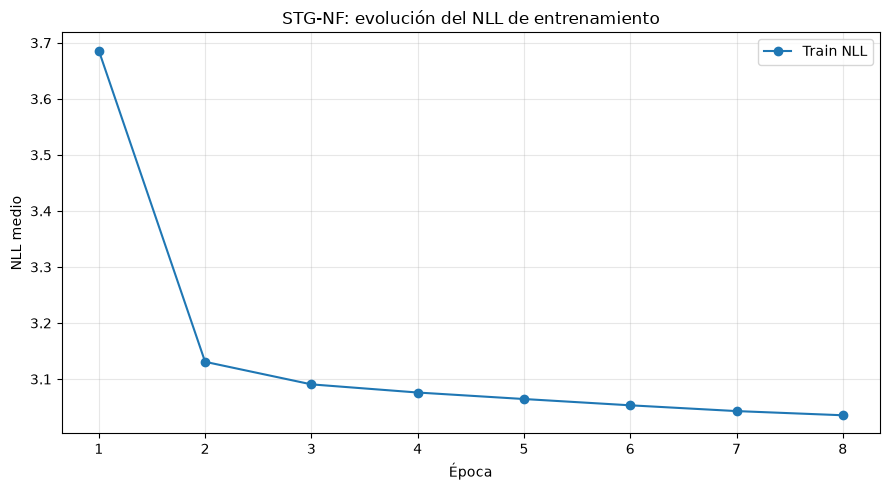

In [64]:
# ============================================================
# STG-NF: evolución del NLL de entrenamiento
# ============================================================

plt.figure(
    figsize=(9, 5)
)

plt.plot(
    tabla_historial_stgnf["epoca"],
    tabla_historial_stgnf["nll_train"],
    marker="o",
    label="Train NLL"
)

plt.xlabel("Época")
plt.ylabel("NLL medio")
plt.title(
    "STG-NF: evolución del NLL de entrenamiento"
)

plt.xticks(
    tabla_historial_stgnf["epoca"]
)

plt.grid(
    alpha=0.3
)

plt.legend()
plt.tight_layout()
plt.show()

### 8.7 Evaluación de STG-NF sobre RetailS

STG-NF aprende la distribución de secuencias de pose consideradas normales y utiliza el *Negative Log-Likelihood* (NLL) para identificar desviaciones respecto a ese comportamiento. En este experimento se utiliza directamente el NLL como score de anomalía, por lo que valores mayores representan mayor anomalía.

La evaluación sigue el procedimiento definido por la implementación de referencia de STG-NF. El score de cada ventana temporal se asigna a su frame central. Cuando varias personas generan un score para el mismo frame, se conserva el mayor NLL, equivalente a seleccionar la observación con menor normalidad bajo la convención original del modelo.

Posteriormente se reconstruye la cobertura temporal completa de cada secuencia. Los frames que no generan una ventana válida reciben el menor NLL finito observado, equivalente al tratamiento de máxima normalidad utilizado por la implementación de referencia. Finalmente, los scores se suavizan temporalmente mediante filtros gaussianos sucesivos con valores de $\sigma$ de 1 a 6.

`RetailS_test_staged` se utiliza para verificar este procedimiento, comprobar la alineación entre scores y ground truth y fijar el protocolo de evaluación antes de utilizar `RetailS_test_realworld`. De esta forma, las decisiones de postprocesamiento quedan definidas antes de evaluar la partición reservada.

**Referencia:** Hirschorn, O. y Avidan, S. (2023), *Normalizing Flows for Human Pose Anomaly Detection*. Implementación oficial STG-NF.

In [65]:
# ============================================================
# Evaluación STG-NF sobre RetailS_test_staged
# ============================================================

from pathlib import Path
import importlib
import numpy as np
import pandas as pd

import Scripts.evaluar_stgnf as evaluar_stgnf


evaluar_stgnf = importlib.reload(
    evaluar_stgnf
)


RAIZ_RETAILS_BNEXT = (
    Path.home()
    / "mnt"
    / "bnext_retails"
)


# Partición utilizada para validar el protocolo STG-NF
indice_staged_stgnf = (
    indice_validado_stgnf.loc[
        indice_validado_stgnf["particion"]
        == "RetailS_test_staged"
    ]
    .reset_index(drop=True)
    .copy()
)


# Inferencia por ventana
resultados_ventana_staged_stgnf, resumen_inferencia_staged_stgnf = (
    evaluar_stgnf.inferir_ventanas_stgnf(
        modelo=modelo_stgnf_final,
        indice=indice_staged_stgnf,
        particiones_cache=PARTICIONES_CACHE_DATASET_STGNF,
        device=DEVICE_STGNF,
        batch_size=256,
        cache_max_archivos=2,
        num_workers=0
    )
)

evaluar_stgnf.validar_resultados_inferencia(
    resultados_ventana_staged_stgnf,
    resumen_inferencia_staged_stgnf
)


# Agregación de ventanas a frame
resultados_frame_staged_stgnf, _ = (
    evaluar_stgnf.agregar_scores_frame_stgnf(
        resultados_ventana_staged_stgnf
    )
)


# Cobertura temporal completa
cobertura_staged_stgnf, _ = (
    evaluar_stgnf.construir_cobertura_completa_stgnf(
        resultados_frame=resultados_frame_staged_stgnf,
        raiz_particion=(
            RAIZ_RETAILS_BNEXT
            / "RetailS_test_staged"
        )
    )
)


# Suavizado temporal definido por STG-NF
resultados_frame_suavizados_staged_stgnf, _ = (
    evaluar_stgnf.aplicar_suavizado_temporal_stgnf(
        cobertura=cobertura_staged_stgnf,
        sigmas=(1, 2, 3, 4, 5, 6)
    )
)


# Métricas frame-level
metricas_staged_stgnf = (
    evaluar_stgnf.calcular_metricas_ranking_stgnf(
        y_true=(
            resultados_frame_suavizados_staged_stgnf[
                "etiqueta"
            ]
        ),
        scores=(
            resultados_frame_suavizados_staged_stgnf[
                "score_anomalia_suavizado"
            ]
        )
    )
)

# Umbral fijado mediante EER en RetailS_test_staged
UMBRAL_STGNF = metricas_staged_stgnf[
    "threshold_eer"
]


# Métricas operativas con el umbral congelado
metricas_umbral_staged_stgnf = (
    evaluar_stgnf.calcular_metricas_umbral_stgnf(
        y_true=(
            resultados_frame_suavizados_staged_stgnf[
                "etiqueta"
            ]
        ),
        scores=(
            resultados_frame_suavizados_staged_stgnf[
                "score_anomalia_suavizado"
            ]
        ),
        threshold=UMBRAL_STGNF
    )
)

# Resumen del experimento
tabla_staged_stgnf = pd.DataFrame(
    {
        "Indicador": [
            "Fuentes evaluadas",
            "Frames evaluados",
            "Average Precision",
            "PR-AUC",
            "ROC-AUC",
            "EER",
            "Umbral EER",
            "Accuracy",
            "Precision",
            "Recall",
            "Specificity",
            "F1"
        ],
        "Resultado": [
            f"{cobertura_staged_stgnf['fuente'].nunique():,}",
            f"{len(resultados_frame_suavizados_staged_stgnf):,}",
            f"{metricas_staged_stgnf['average_precision']:.4f}",
            f"{metricas_staged_stgnf['pr_auc']:.4f}",
            f"{metricas_staged_stgnf['roc_auc']:.4f}",
            f"{metricas_staged_stgnf['eer']:.4f}",
            f"{UMBRAL_STGNF:.6f}",
            f"{metricas_umbral_staged_stgnf['accuracy']:.4f}",
            f"{metricas_umbral_staged_stgnf['precision']:.4f}",
            f"{metricas_umbral_staged_stgnf['recall']:.4f}",
            f"{metricas_umbral_staged_stgnf['specificity']:.4f}",
            f"{metricas_umbral_staged_stgnf['f1']:.4f}"
        ]
    }
)


print(
    "=== STG-NF: RetailS_test_staged ==="
)

display(
    tabla_staged_stgnf
)

=== STG-NF: RetailS_test_staged ===


,Indicador,Resultado
0,Fuentes evaluadas,624
1,Frames evaluados,"40,913"
2,Average Precision,0.7130
3,PR-AUC,0.7130
4,ROC-AUC,0.7193
5,EER,0.3464
6,Umbral EER,2.820213
7,Accuracy,0.6536
8,Precision,0.6509
9,Recall,0.6536


#### Resultado de la evaluación sobre `RetailS_test_staged`

STG-NF se evaluó sobre 624 fuentes y 40,913 frames de `RetailS_test_staged` siguiendo el protocolo de evaluación de la implementación de referencia. El modelo obtuvo un Average Precision cercano a 0.713, PR-AUC de aproximadamente 0.713, ROC-AUC de 0.719 y EER de 0.346.

A partir de la curva ROC de esta partición se fijó un umbral de NLL de `2.820213` en el punto correspondiente al EER. Con este punto de operación se obtuvo una precision aproximada de 0.651, recall de 0.654, specificity de 0.654 y F1 de 0.652.

Este umbral queda definido antes de la evaluación de `RetailS_test_realworld` y se utilizará posteriormente sin reajustarlo con información de esa partición.

### 8.8 Evaluación de STG-NF sobre `RetailS_test_realworld`

Después de fijar el protocolo de evaluación y el umbral operativo utilizando `RetailS_test_staged`, STG-NF se evalúa sobre `RetailS_test_realworld` como partición reservada.

Se conserva sin cambios el procedimiento utilizado previamente: inferencia por ventanas de pose, agregación de scores a nivel de frame, reconstrucción de la cobertura temporal completa y suavizado temporal conforme a la implementación de referencia.

Para las métricas dependientes de umbral se utiliza el valor fijado previamente:
$$
\tau_{\mathrm{STG-NF}} = 2.820213
$$
Este valor no se recalcula ni se ajusta con información de `RetailS_test_realworld`. La evaluación de esta partición tiene como objetivo medir la capacidad de generalización del modelo bajo el protocolo previamente definido.

In [66]:
# ============================================================
# Evaluación STG-NF sobre RetailS_test_realworld
# ============================================================

indice_realworld_stgnf = (
    indice_validado_stgnf.loc[
        indice_validado_stgnf["particion"]
        == "RetailS_test_realworld"
    ]
    .reset_index(drop=True)
    .copy()
)


# Inferencia por ventana
resultados_ventana_realworld_stgnf, resumen_inferencia_realworld_stgnf = (
    evaluar_stgnf.inferir_ventanas_stgnf(
        modelo=modelo_stgnf_final,
        indice=indice_realworld_stgnf,
        particiones_cache=PARTICIONES_CACHE_DATASET_STGNF,
        device=DEVICE_STGNF,
        batch_size=256,
        cache_max_archivos=2,
        num_workers=0
    )
)

evaluar_stgnf.validar_resultados_inferencia(
    resultados_ventana_realworld_stgnf,
    resumen_inferencia_realworld_stgnf
)


# Agregación a frame
resultados_frame_realworld_stgnf, _ = (
    evaluar_stgnf.agregar_scores_frame_stgnf(
        resultados_ventana_realworld_stgnf
    )
)


# Cobertura completa
cobertura_realworld_stgnf, _ = (
    evaluar_stgnf.construir_cobertura_completa_stgnf(
        resultados_frame=resultados_frame_realworld_stgnf,
        raiz_particion=(
            RAIZ_RETAILS_BNEXT
            / "RetailS_test_realworld"
        )
    )
)


# Suavizado temporal
resultados_frame_suavizados_realworld_stgnf, _ = (
    evaluar_stgnf.aplicar_suavizado_temporal_stgnf(
        cobertura=cobertura_realworld_stgnf,
        sigmas=(1, 2, 3, 4, 5, 6)
    )
)


# Métricas independientes de umbral
metricas_realworld_stgnf = (
    evaluar_stgnf.calcular_metricas_ranking_stgnf(
        y_true=(
            resultados_frame_suavizados_realworld_stgnf[
                "etiqueta"
            ]
        ),
        scores=(
            resultados_frame_suavizados_realworld_stgnf[
                "score_anomalia_suavizado"
            ]
        )
    )
)


# Métricas con el umbral congelado en staged
metricas_umbral_realworld_stgnf = (
    evaluar_stgnf.calcular_metricas_umbral_stgnf(
        y_true=(
            resultados_frame_suavizados_realworld_stgnf[
                "etiqueta"
            ]
        ),
        scores=(
            resultados_frame_suavizados_realworld_stgnf[
                "score_anomalia_suavizado"
            ]
        ),
        threshold=UMBRAL_STGNF
    )
)


tabla_realworld_stgnf = pd.DataFrame(
    {
        "Indicador": [
            "Fuentes evaluadas",
            "Frames evaluados",
            "Average Precision",
            "PR-AUC",
            "ROC-AUC",
            "EER",
            "Umbral aplicado",
            "Accuracy",
            "Precision",
            "Recall",
            "Specificity",
            "F1",
            "Frames positivos",
            "Frames negativos",
            "Prevalencia positiva",
        ],
        "Resultado": [
            f"{cobertura_realworld_stgnf['fuente'].nunique():,}",
            f"{len(resultados_frame_suavizados_realworld_stgnf):,}",
            f"{metricas_realworld_stgnf['average_precision']:.4f}",
            f"{metricas_realworld_stgnf['pr_auc']:.4f}",
            f"{metricas_realworld_stgnf['roc_auc']:.4f}",
            f"{metricas_realworld_stgnf['eer']:.4f}",
            f"{UMBRAL_STGNF:.6f}",
            f"{metricas_umbral_realworld_stgnf['accuracy']:.4f}",
            f"{metricas_umbral_realworld_stgnf['precision']:.4f}",
            f"{metricas_umbral_realworld_stgnf['recall']:.4f}",
            f"{metricas_umbral_realworld_stgnf['specificity']:.4f}",
            f"{metricas_umbral_realworld_stgnf['f1']:.4f}",
            f"{metricas_realworld_stgnf['positivos']:,}",
            f"{metricas_realworld_stgnf['negativos']:,}",
            f"{metricas_realworld_stgnf['positivos'] / metricas_realworld_stgnf['observaciones']:.4f}",
        ]
    }
)


print(
    "=== STG-NF: RetailS_test_realworld ==="
)

display(
    tabla_realworld_stgnf
)

=== STG-NF: RetailS_test_realworld ===


,Indicador,Resultado
0,Fuentes evaluadas,47
1,Frames evaluados,"4,846"
2,Average Precision,0.4066
3,PR-AUC,0.4064
4,ROC-AUC,0.6282
5,EER,0.4340
6,Umbral aplicado,2.820213
7,Accuracy,0.5660
8,Precision,0.3788
9,Recall,0.5795


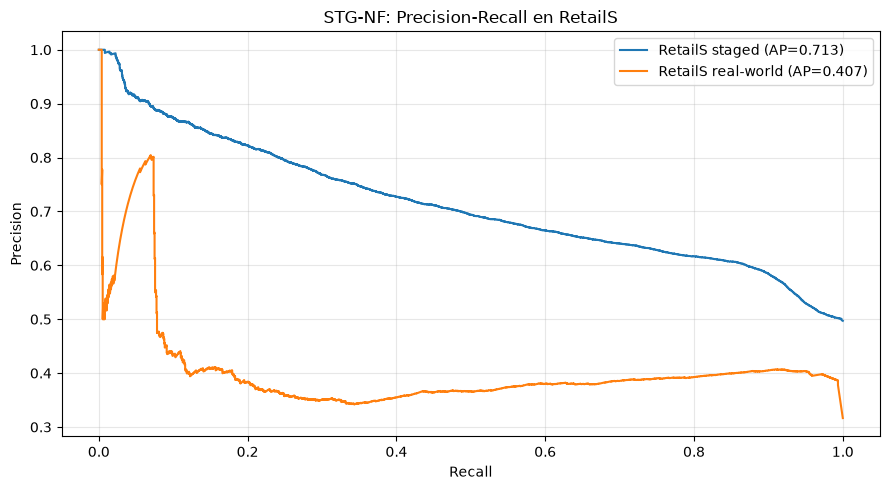

In [67]:
# ============================================================
# STG-NF: curvas Precision-Recall
# staged vs. real-world
# ============================================================

from sklearn.metrics import precision_recall_curve


# RetailS_test_staged
precision_staged, recall_staged, _ = (
    precision_recall_curve(
        resultados_frame_suavizados_staged_stgnf[
            "etiqueta"
        ],
        resultados_frame_suavizados_staged_stgnf[
            "score_anomalia_suavizado"
        ]
    )
)


# RetailS_test_realworld
precision_realworld, recall_realworld, _ = (
    precision_recall_curve(
        resultados_frame_suavizados_realworld_stgnf[
            "etiqueta"
        ],
        resultados_frame_suavizados_realworld_stgnf[
            "score_anomalia_suavizado"
        ]
    )
)


plt.figure(
    figsize=(9, 5)
)

plt.plot(
    recall_staged,
    precision_staged,
    label=(
        "RetailS staged "
        f"(AP={metricas_staged_stgnf['average_precision']:.3f})"
    )
)

plt.plot(
    recall_realworld,
    precision_realworld,
    label=(
        "RetailS real-world "
        f"(AP={metricas_realworld_stgnf['average_precision']:.3f})"
    )
)

plt.xlabel("Recall")
plt.ylabel("Precision")

plt.title(
    "STG-NF: Precision-Recall en RetailS"
)

plt.grid(
    alpha=0.3
)

plt.legend()
plt.tight_layout()
plt.show()

#### Resultado de la evaluación sobre `RetailS_test_realworld`

STG-NF se evaluó sobre 47 fuentes y 4,846 frames de `RetailS_test_realworld` utilizando sin cambios el protocolo y el umbral de NLL `2.820213` definidos previamente con `RetailS_test_staged`.

El modelo obtuvo un Average Precision cercano a 0.407 frente a una prevalencia positiva de aproximadamente 0.317, además de un PR-AUC de 0.406, ROC-AUC de 0.628 y EER de 0.434. Con el umbral previamente fijado, obtuvo una precision aproximada de 0.379, recall de 0.580, specificity de 0.560 y F1 de 0.458.

El desempeño es inferior al observado en `RetailS_test_staged`, donde el Average Precision fue aproximadamente 0.713 y ROC-AUC 0.719. La disminución de ROC-AUC y el incremento de EER indican que la diferencia no se explica únicamente por el menor porcentaje de frames positivos en `RetailS_test_realworld`, sino que existe una pérdida de capacidad de discriminación al pasar al escenario real-world.

Este resultado evidencia una limitación de generalización de STG-NF entre ambos subconjuntos de RetailS y deberá considerarse al comparar este enfoque basado en pose con los modelos RGB evaluados en el avance.

### 8.9 Síntesis de los seis modelos evaluados

Los seis modelos considerados en el avance representan dos enfoques experimentales diferentes. R3D-18, MC3-18, R(2+1)D-18, S3D y MViT-V2-S utilizan información RGB y fueron evaluados bajo un protocolo común de clasificación binaria, por lo que sus métricas permiten una comparación directa entre arquitecturas.

STG-NF utiliza secuencias de pose y formula el problema como detección de anomalías. Además, su evaluación se realiza a nivel de frame sobre RetailS. Por esta razón, sus métricas se presentan como evidencia complementaria y no se incorporan directamente al ranking numérico de los modelos RGB.

La síntesis separará ambos grupos para distinguir el desempeño relativo de las arquitecturas RGB de la capacidad de generalización observada en el enfoque basado en pose.

In [68]:
# ============================================================
# Síntesis comparativa de los seis modelos evaluados
# ============================================================

# ------------------------------------------------------------
# Modelos RGB: protocolo comparable sobre validation
# ------------------------------------------------------------

tabla_comparativa_rgb = (
    comparacion_rgb[
        [
            "ranking_ap",
            "modelo",
            "val_average_precision",
            "val_pr_auc",
            "val_roc_auc",
            "val_eer",
            "val_f1_05",
            "tiempo_entrenamiento_s"
        ]
    ]
    .rename(
        columns={
            "ranking_ap": "Ranking AP comparable",
            "modelo": "Modelo",
            "val_average_precision": "AP",
            "val_pr_auc": "PR-AUC",
            "val_roc_auc": "ROC-AUC",
            "val_eer": "EER",
            "val_f1_05": "F1",
            "tiempo_entrenamiento_s": "Entrenamiento (s)"
        }
    )
    .copy()
)

tabla_comparativa_rgb["Representación"] = "RGB"
tabla_comparativa_rgb["Dataset / partición"] = (
    "Dataset v2 / validation"
)
tabla_comparativa_rgb["Unidad de evaluación"] = (
    "Clip RGB de 16 frames"
)
tabla_comparativa_rgb["Entrenamiento (min)"] = (
    tabla_comparativa_rgb["Entrenamiento (s)"] / 60.0
)

tabla_comparativa_rgb = tabla_comparativa_rgb.drop(
    columns=["Entrenamiento (s)"]
)


# ------------------------------------------------------------
# STG-NF: protocolo complementario sobre RetailS
# ------------------------------------------------------------

tiempo_entrenamiento_stgnf_min = (
    float(checkpoint_final_stgnf["tiempo_total_s"]) / 60.0
)

tabla_comparativa_stgnf = pd.DataFrame(
    [
        {
            "Ranking AP comparable": "Complementario",
            "Modelo": "STG-NF",
            "Representación": "Pose COCO18 XY",
            "Dataset / partición": "RetailS / test_staged",
            "Unidad de evaluación": (
                "Score por frame reconstruido "
                "desde ventanas de pose de 16 frames"
            ),
            "AP": metricas_staged_stgnf[
                "average_precision"
            ],
            "PR-AUC": metricas_staged_stgnf[
                "pr_auc"
            ],
            "ROC-AUC": metricas_staged_stgnf[
                "roc_auc"
            ],
            "EER": metricas_staged_stgnf[
                "eer"
            ],
            "F1": metricas_umbral_staged_stgnf[
                "f1"
            ],
            "Entrenamiento (min)": (
                tiempo_entrenamiento_stgnf_min
            )
        },
        {
            "Ranking AP comparable": "Complementario",
            "Modelo": "STG-NF",
            "Representación": "Pose COCO18 XY",
            "Dataset / partición": (
                "RetailS / test_realworld"
            ),
            "Unidad de evaluación": (
                "Score por frame reconstruido "
                "desde ventanas de pose de 16 frames"
            ),
            "AP": metricas_realworld_stgnf[
                "average_precision"
            ],
            "PR-AUC": metricas_realworld_stgnf[
                "pr_auc"
            ],
            "ROC-AUC": metricas_realworld_stgnf[
                "roc_auc"
            ],
            "EER": metricas_realworld_stgnf[
                "eer"
            ],
            "F1": metricas_umbral_realworld_stgnf[
                "f1"
            ],
            "Entrenamiento (min)": (
                tiempo_entrenamiento_stgnf_min
            )
        }
    ]
)


# ------------------------------------------------------------
# Tabla única
# ------------------------------------------------------------

columnas_sintesis = [
    "Ranking AP comparable",
    "Modelo",
    "Representación",
    "Dataset / partición",
    "Unidad de evaluación",
    "AP",
    "PR-AUC",
    "ROC-AUC",
    "EER",
    "F1",
    "Entrenamiento (min)"
]

tabla_sintesis_modelos = pd.concat(
    [
        tabla_comparativa_rgb[columnas_sintesis],
        tabla_comparativa_stgnf[columnas_sintesis]
    ],
    ignore_index=True
)

display(
    tabla_sintesis_modelos.style.format(
        {
            "AP": "{:.4f}",
            "PR-AUC": "{:.4f}",
            "ROC-AUC": "{:.4f}",
            "EER": "{:.4f}",
            "F1": "{:.4f}",
            "Entrenamiento (min)": "{:.1f}"
        }
    )
)

,Ranking AP comparable,Modelo,Representación,Dataset / partición,Unidad de evaluación,AP,PR-AUC,ROC-AUC,EER,F1,Entrenamiento (min)
0,1,R(2+1)D-18,RGB,Dataset v2 / validation,Clip RGB de 16 frames,0.6730,0.6695,0.7387,0.3223,0.6792,63.0
1,2,MViT-V2-S,RGB,Dataset v2 / validation,Clip RGB de 16 frames,0.6473,0.6578,0.7473,0.3767,0.5758,82.7
2,3,MC3-18,RGB,Dataset v2 / validation,Clip RGB de 16 frames,0.6442,0.6413,0.7492,0.3104,0.5373,62.3
3,4,R3D-18,RGB,Dataset v2 / validation,Clip RGB de 16 frames,0.6159,0.6110,0.7038,0.3814,0.5957,66.3
4,5,S3D,RGB,Dataset v2 / validation,Clip RGB de 16 frames,0.5978,0.5930,0.6604,0.4028,0.2778,65.5
5,Complementario,STG-NF,Pose COCO18 XY,RetailS / test_staged,Score por frame reconstruido desde ventanas de pose de 16 frames,0.7130,0.7130,0.7193,0.3464,0.6522,533.2
6,Complementario,STG-NF,Pose COCO18 XY,RetailS / test_realworld,Score por frame reconstruido desde ventanas de pose de 16 frames,0.4066,0.4064,0.6282,0.4340,0.4581,533.2


#### 8.9.1 Síntesis de resultados

La tabla anterior concentra los seis modelos individuales evaluados y hace explícitas las diferencias de dataset, representación y unidad de evaluación. Los cinco modelos RGB comparten el mismo protocolo experimental sobre `validation` del dataset v2, por lo que pueden ordenarse directamente utilizando Average Precision.

Entre los modelos RGB, R(2+1)D-18 obtuvo el mayor Average Precision y también presentó los mayores valores de PR-AUC y F1. MViT-V2-S y MC3-18 obtuvieron resultados cercanos en Average Precision, mientras que MC3-18 presentó el mayor ROC-AUC y el menor EER dentro de este grupo.

STG-NF se incluye como el sexto modelo, pero sus resultados se presentan como evidencia complementaria. Utiliza RetailS, una representación basada en pose y un objetivo de detección de anomalías. La inferencia se realiza sobre ventanas temporales de pose y el procedimiento de evaluación reconstruye posteriormente scores por frame. En `RetailS_test_staged` obtuvo un Average Precision cercano a 0.713, mientras que en `RetailS_test_realworld` disminuyó a aproximadamente 0.407.

Por estas diferencias de datos, representación, objetivo de aprendizaje y unidad de evaluación, los resultados de STG-NF no se utilizan para modificar el ranking numérico de los cinco clasificadores RGB. La selección de los candidatos para ajuste de hiperparámetros se realiza dentro del grupo RGB bajo condiciones experimentales comparables.

In [69]:
# ============================================================
# Candidatos RGB para ajuste de hiperparámetros
# ============================================================

candidatos_rgb = (
    comparacion_rgb.loc[
        comparacion_rgb["modelo"].isin(
            [
                "R(2+1)D-18",
                "MViT-V2-S",
                "MC3-18"
            ]
        ),
        [
            "modelo",
            "val_average_precision",
            "val_pr_auc",
            "val_roc_auc",
            "val_eer",
            "val_f1_05",
            "parametros_totales",
            "parametros_entrenables",
            "tiempo_entrenamiento_s",
            "gpu_peak_gb",
            "inferencia_clips_s"
        ]
    ]
    .copy()
)

candidatos_rgb = candidatos_rgb.rename(
    columns={
        "modelo": "Modelo",
        "val_average_precision": "AP",
        "val_pr_auc": "PR-AUC",
        "val_roc_auc": "ROC-AUC",
        "val_eer": "EER",
        "val_f1_05": "F1",
        "parametros_totales": "Parámetros",
        "parametros_entrenables": "Parámetros entrenables",
        "tiempo_entrenamiento_s": "Entrenamiento (s)",
        "gpu_peak_gb": "GPU pico (GB)",
        "inferencia_clips_s": "Inferencia (clips/s)"
    }
)

display(
    candidatos_rgb.style.format(
        {
            "AP": "{:.4f}",
            "PR-AUC": "{:.4f}",
            "ROC-AUC": "{:.4f}",
            "EER": "{:.4f}",
            "F1": "{:.4f}",
            "Parámetros": "{:,.0f}",
            "Parámetros entrenables": "{:,.0f}",
            "Entrenamiento (s)": "{:.1f}",
            "GPU pico (GB)": "{:.2f}",
            "Inferencia (clips/s)": "{:.2f}"
        }
    )
)

,Modelo,AP,PR-AUC,ROC-AUC,EER,F1,Parámetros,Parámetros entrenables,Entrenamiento (s),GPU pico (GB),Inferencia (clips/s)
0,R(2+1)D-18,0.6730,0.6695,0.7387,0.3223,0.6792,"31,301,151","14,163,458",3781.2,2.32,3.07
1,MViT-V2-S,0.6473,0.6578,0.7473,0.3767,0.5758,"34,231,682","13,616,258",4961.6,5.60,2.28
2,MC3-18,0.6442,0.6413,0.7492,0.3104,0.5373,"11,491,266","4,721,666",3736.3,1.27,3.20


#### 8.9.2 Selección de candidatos para ajuste de hiperparámetros

A partir de los resultados de validación se seleccionaron **R(2+1)D-18** y **MC3-18** para la etapa de ajuste de hiperparámetros.

R(2+1)D-18 presentó el mejor desempeño global entre los modelos RGB, con el mayor Average Precision, PR-AUC y F1. Por esta razón se selecciona como el primer candidato.

Para el segundo candidato se compararon MViT-V2-S y MC3-18. MViT-V2-S obtuvo un Average Precision ligeramente mayor, aproximadamente 0.647 frente a 0.644 de MC3-18. Sin embargo, MC3-18 presentó mejor ROC-AUC y EER, además de una demanda computacional considerablemente menor: aproximadamente 11.5 millones de parámetros y un pico de memoria GPU de 1.27 GB, frente a 34.2 millones de parámetros y 5.60 GB de MViT-V2-S. También presentó mayor velocidad de inferencia.

La diferencia reducida de Average Precision entre ambos modelos no compensa, en esta etapa experimental, el incremento de costo computacional de MViT-V2-S. Por este motivo, MC3-18 se selecciona como segundo candidato para el ajuste de hiperparámetros.

El presupuesto de búsqueda de hiperparámetros se mantuvo deliberadamente acotado. En el hardware utilizado, cada entrenamiento de los modelos candidatos requiere aproximadamente una hora y el conjunto de validation contiene 136 clips, de los cuales únicamente 30 corresponden a `ocultamiento`. Evaluar un número elevado de configuraciones sobre este mismo conjunto incrementaría tanto el costo computacional como el riesgo de seleccionar hiperparámetros demasiado ajustados a particularidades de validation. Por esta razón se definió un espacio reducido de búsqueda y la comparación de las configuraciones de ajuste se realizó utilizando `validation` como base para la selección.

In [70]:
# ============================================================
# Espacio de búsqueda para tuning RGB
# ============================================================

MODELOS_TUNING_RGB = [
    "R(2+1)D-18",
    "MC3-18"
]

ESPACIO_TUNING_RGB = {
    "H0": {
        "lr_representacion": 1e-4,
        "lr_clasificador": 1e-3,
        "weight_decay": 1e-4,
        "ejecutar": False
    },
    "H1": {
        "lr_representacion": 5e-5,
        "lr_clasificador": 5e-4,
        "weight_decay": 1e-4,
        "ejecutar": True
    },
    "H2": {
        "lr_representacion": 2e-4,
        "lr_clasificador": 2e-3,
        "weight_decay": 1e-4,
        "ejecutar": True
    },
    "H3": {
        "lr_representacion": 1e-4,
        "lr_clasificador": 1e-3,
        "weight_decay": 1e-5,
        "ejecutar": True
    },
    "H4": {
        "lr_representacion": 1e-4,
        "lr_clasificador": 1e-3,
        "weight_decay": 1e-3,
        "ejecutar": True
    },
    "H5": {
    "lr_representacion": 1e-4,
    "lr_clasificador": 1e-3,
    "weight_decay": 1e-4,
    "profundidad_finetuning": "layer4_completo",
    "ejecutar": True
    }
}


tabla_espacio_tuning = pd.DataFrame(
    [
        {
            "configuracion": nombre,
            **config,
            "ratio_lr": (
                config["lr_clasificador"]
                / config["lr_representacion"]
            )
        }
        for nombre, config
        in ESPACIO_TUNING_RGB.items()
    ]
)

display(
    tabla_espacio_tuning
)

,configuracion,lr_representacion,lr_clasificador,weight_decay,ejecutar,ratio_lr,profundidad_finetuning
0,H0,0.00010,0.0010,0.00010,False,10.0,NaN
1,H1,0.00005,0.0005,0.00010,True,10.0,NaN
2,H2,0.00020,0.0020,0.00010,True,10.0,NaN
3,H3,0.00010,0.0010,0.00001,True,10.0,NaN
4,H4,0.00010,0.0010,0.00100,True,10.0,NaN
5,H5,0.00010,0.0010,0.00010,True,10.0,layer4_completo


In [71]:
# ============================================================
# Protección de la ejecución del tuning RGB
# ============================================================

EJECUTAR_TUNING_RGB = False

FORCE_RETRAIN_TUNING_RGB = False

EXPERIMENTOS_TUNING_HABILITADOS = {
    #("R(2+1)D-18", "H2"),
    ("R(2+1)D-18", "H3"),
    ("R(2+1)D-18", "H4"),
    ("MC3-18", "H1"),
    ("MC3-18", "H2"),
    ("MC3-18", "H3"),
    ("MC3-18", "H4"),
    ("R(2+1)D-18", "H5"),
    ("MC3-18", "H5")
}


print(
    "=== CONTROL DE TUNING RGB ==="
)

print(
    "Permitir nuevos entrenamientos:",
    EJECUTAR_TUNING_RGB
)

print(
    "Forzar reentrenamiento:",
    FORCE_RETRAIN_TUNING_RGB
)

print(
    "Experimentos habilitados:",
    EXPERIMENTOS_TUNING_HABILITADOS
)


=== CONTROL DE TUNING RGB ===
Permitir nuevos entrenamientos: False
Forzar reentrenamiento: False
Experimentos habilitados: {('MC3-18', 'H3'), ('R(2+1)D-18', 'H4'), ('R(2+1)D-18', 'H3'), ('MC3-18', 'H2'), ('MC3-18', 'H1'), ('MC3-18', 'H5'), ('R(2+1)D-18', 'H5'), ('MC3-18', 'H4')}


In [72]:
# ============================================================
# Plan de experimentos de tuning RGB
# ============================================================

import importlib

import Scripts.tuning_rgb as tuning_rgb

importlib.reload(tuning_rgb)


plan_tuning_rgb = tuning_rgb.construir_plan_tuning_rgb(
    modelos=MODELOS_TUNING_RGB,
    espacio_tuning=ESPACIO_TUNING_RGB,
    config_batch=CONFIG_BATCH_RGB,
    checkpoint_dir=CHECKPOINT_DIR,
    repo_dir=REPO_DIR,
    seed=SEED,
    max_epochs=MAX_EPOCHS_RGB,
    dataset_sha256=DATASET_V2_SHA256,
    ejecutar_tuning=EJECUTAR_TUNING_RGB,
    force_retrain=FORCE_RETRAIN_TUNING_RGB,
    experimentos_habilitados=(
        EXPERIMENTOS_TUNING_HABILITADOS
    ),
    validar_artefactos_fn=validar_artefactos_rgb
)


tabla_plan_tuning_rgb = pd.DataFrame(
    plan_tuning_rgb
)

display(
    tabla_plan_tuning_rgb
)

,modelo,configuracion,lr_representacion,lr_clasificador,weight_decay,estado_artefactos,accion,checkpoint
0,R(2+1)D-18,H1,0.00005,0.0005,0.00010,validos,REUTILIZAR,Notebooks/checkpoints/r2plus1d_18_avance4_h1.pt
1,R(2+1)D-18,H2,0.00020,0.0020,0.00010,validos,REUTILIZAR,Notebooks/checkpoints/r2plus1d_18_avance4_h2.pt
2,R(2+1)D-18,H3,0.00010,0.0010,0.00001,validos,REUTILIZAR,Notebooks/checkpoints/r2plus1d_18_avance4_h3.pt
3,R(2+1)D-18,H4,0.00010,0.0010,0.00100,validos,REUTILIZAR,Notebooks/checkpoints/r2plus1d_18_avance4_h4.pt
4,R(2+1)D-18,H5,0.00010,0.0010,0.00010,validos,REUTILIZAR,Notebooks/checkpoints/r2plus1d_18_avance4_h5.pt
5,MC3-18,H1,0.00005,0.0005,0.00010,validos,REUTILIZAR,Notebooks/checkpoints/mc3_18_avance4_h1.pt
6,MC3-18,H2,0.00020,0.0020,0.00010,validos,REUTILIZAR,Notebooks/checkpoints/mc3_18_avance4_h2.pt
7,MC3-18,H3,0.00010,0.0010,0.00001,validos,REUTILIZAR,Notebooks/checkpoints/mc3_18_avance4_h3.pt
8,MC3-18,H4,0.00010,0.0010,0.00100,validos,REUTILIZAR,Notebooks/checkpoints/mc3_18_avance4_h4.pt
9,MC3-18,H5,0.00010,0.0010,0.00010,validos,REUTILIZAR,Notebooks/checkpoints/mc3_18_avance4_h5.pt


In [73]:
# ============================================================
# Ejecución protegida del tuning RGB
# ============================================================

import importlib
import Scripts.tuning_rgb as tuning_rgb

importlib.reload(tuning_rgb)

resultados_tuning_rgb = tuning_rgb.ejecutar_tuning_rgb(
    plan=plan_tuning_rgb,
    espacio_tuning=ESPACIO_TUNING_RGB,
    config_batch=CONFIG_BATCH_RGB,
    checkpoint_dir=CHECKPOINT_DIR,
    seed=SEED,
    device=DEVICE,
    usar_amp=USAR_AMP_RGB,
    max_epochs=MAX_EPOCHS_RGB,
    dataset_sha256=DATASET_V2_SHA256,
    loaders_rgb=loaders_rgb,
    crear_modelo_fn=crear_modelo_rgb,
    configurar_parametros_fn=(
        configurar_parametros_entrenables
    ),
    entrenar_experimento_fn=entrenar_experimento_rgb
)


tabla_ejecucion_tuning_rgb = pd.DataFrame(
    [
        {
            "modelo": resultado["modelo"],
            "configuracion": resultado["configuracion"],
            "accion": resultado["accion"],
            "entrenado": resultado["entrenado"]
        }
        for resultado in resultados_tuning_rgb
    ]
)

display(
    tabla_ejecucion_tuning_rgb
)

,modelo,configuracion,accion,entrenado
0,R(2+1)D-18,H1,REUTILIZAR,False
1,R(2+1)D-18,H2,REUTILIZAR,False
2,R(2+1)D-18,H3,REUTILIZAR,False
3,R(2+1)D-18,H4,REUTILIZAR,False
4,R(2+1)D-18,H5,REUTILIZAR,False
5,MC3-18,H1,REUTILIZAR,False
6,MC3-18,H2,REUTILIZAR,False
7,MC3-18,H3,REUTILIZAR,False
8,MC3-18,H4,REUTILIZAR,False
9,MC3-18,H5,REUTILIZAR,False


In [74]:
# ============================================================
# Comparación final del ajuste de hiperparámetros
# ============================================================

import importlib

import Scripts.tuning_rgb as tuning_rgb

importlib.reload(tuning_rgb)


tabla_resultados_tuning = (
    tuning_rgb.resumir_resultados_tuning(
        comparacion_rgb=comparacion_rgb,
        checkpoint_dir=CHECKPOINT_DIR,
        modelos=MODELOS_TUNING_RGB,
        configuraciones=[
            "H1",
            "H2",
            "H3",
            "H4",
            "H5"
        ]
    )
)


display(
    tabla_resultados_tuning.style.format(
        {
            "val_ap": "{:.4f}",
            "val_pr_auc": "{:.4f}",
            "val_roc_auc": "{:.4f}",
            "val_eer": "{:.4f}",
            "val_f1": "{:.4f}"
        }
    )
)

,modelo,configuracion,mejor_epoca,val_ap,val_pr_auc,val_roc_auc,val_eer,val_f1
0,MC3-18,H5,6,0.7134,0.7112,0.8302,0.2701,0.5763
1,MC3-18,H0,7,0.6442,0.6413,0.7492,0.3104,0.5373
2,MC3-18,H3,3,0.6315,0.6261,0.7447,0.3009,0.5556
3,MC3-18,H4,3,0.6315,0.6261,0.7447,0.3009,0.5556
4,MC3-18,H2,3,0.6266,0.6214,0.7305,0.3318,0.6154
5,MC3-18,H1,13,0.6253,0.6230,0.7263,0.3340,0.5714
6,R(2+1)D-18,H5,7,0.7554,0.7684,0.8668,0.2299,0.6133
7,R(2+1)D-18,H4,7,0.6867,0.6840,0.7465,0.3767,0.6383
8,R(2+1)D-18,H3,7,0.6834,0.6808,0.7377,0.4097,0.6939
9,R(2+1)D-18,H0,4,0.6730,0.6695,0.7387,0.3223,0.6792


### 8.9.3 Comparación de las configuraciones optimizadas

**Justificación del espacio de búsqueda.** La rúbrica solicita que el número de iteraciones o experimentos permita alcanzar una profundidad suficiente en el espacio de búsqueda, sin establecer un número mínimo de configuraciones o hiperparámetros que deban evaluarse. Para este proyecto, la profundidad se definió considerando simultáneamente la capacidad de explorar configuraciones relevantes, el tamaño de los datos disponibles y los recursos computacionales del equipo.

Cada entrenamiento de los modelos candidatos requería aproximadamente una hora en la **NVIDIA GeForce RTX 3050 Laptop de 6 GB** utilizada para los experimentos. Además, el conjunto de `validation` contiene **136 clips**, de los cuales únicamente **30 corresponden a la clase `ocultamiento`**. Incrementar considerablemente el número de configuraciones habría aumentado el costo de cómputo y tiempo, y también el riesgo de seleccionar hiperparámetros demasiado adaptados a las particularidades de una partición de validación relativamente pequeña.

Por estas razones se optó por una búsqueda controlada sobre los dos modelos finalistas. Para cada arquitectura se mantuvo **H0 como referencia** y se evaluaron cinco configuraciones adicionales, **H1-H5**. Las configuraciones H1-H4 modificaron las tasas de aprendizaje de la representación y del clasificador, así como `weight_decay`. La configuración **H5** incorporó una dimensión adicional al aumentar la profundidad del fine-tuning: en lugar de entrenar únicamente el bloque residual final `layer4[1]` y el clasificador, se habilitó el entrenamiento de `layer4` completo y del clasificador, manteniendo las tasas de aprendizaje y `weight_decay` de H0 para aislar el efecto de esta modificación.

En total se evaluaron **cinco configuraciones adicionales por arquitectura**, además de H0, manteniendo 15 épocas como presupuesto máximo de entrenamiento y utilizando Average Precision en `validation` como criterio principal para conservar el mejor checkpoint de cada configuración. El objetivo fue observar la sensibilidad de los modelos tanto a cambios en los hiperparámetros de optimización como a la profundidad del fine-tuning, manteniendo constantes las demás condiciones experimentales. Esta estrategia no pretende agotar el espacio global de hiperparámetros, sino realizar una exploración sistemática y reproducible compatible con los datos y recursos disponibles.

#### 8.9.3.1 Resultados del ajuste de hiperparámetros

Para **R(2+1)D-18**, la configuración **H5** obtuvo el mayor Average Precision en `validation`, con **0.7554** en la época 7, frente a **0.6730** de la configuración inicial H0. Esto representa una mejora de aproximadamente **0.0824 puntos absolutos**. Entre las configuraciones H1-H4, H4 alcanzó el mayor AP con **0.6867**, seguida por H3 con **0.6834**, mientras que H1 y H2 obtuvieron **0.6626** y **0.6712**, respectivamente. H5 también alcanzó un **PR-AUC de 0.7684**, superior al obtenido por H0-H4.

En **MC3-18**, H5 también produjo el mejor resultado, con un Average Precision de **0.7134** en la época 6, frente a **0.6442** de H0. Esto representa una mejora de aproximadamente **0.0692 puntos absolutos**. Las configuraciones H1-H4 no lograron superar H0: H3 y H4 alcanzaron un AP máximo de **0.6315**, mientras que H1 y H2 obtuvieron **0.6253** y **0.6266**, respectivamente. H5 alcanzó además un **PR-AUC de 0.7112**.

La selección de configuraciones utilizó **Average Precision en `validation`** como criterio principal. Para cada configuración se conservó el checkpoint correspondiente a la época con el mayor AP observado. En particular, los checkpoints seleccionados para H5 corresponden a la **época 7 en R(2+1)D-18** y a la **época 6 en MC3-18**.

Los valores anteriores resumen el mejor resultado obtenido por cada configuración. La evolución de estas métricas durante las 15 épocas se analiza a continuación para observar la sensibilidad de ambas arquitecturas tanto a los cambios en los hiperparámetros de optimización como a la mayor profundidad de fine-tuning evaluada en H5.

#### 8.9.3.2 Análisis descriptivo de sensibilidad a la configuración

Además de comparar el mejor resultado alcanzado por cada configuración, se revisa la evolución de Average Precision durante las 15 épocas de entrenamiento. El objetivo es observar cómo cambia la trayectoria de validación al modificar las tasas de aprendizaje y `weight_decay`, así como al incrementar la profundidad del fine-tuning en H5, utilizando los historiales generados para **H0-H5** en R(2+1)D-18 y MC3-18.

En H1-H4 se modificaron exclusivamente los hiperparámetros de optimización, mientras que H5 mantuvo las tasas de aprendizaje y `weight_decay` de H0 y amplió la cantidad de bloques entrenables de la representación. Esta configuración permite observar de manera separada el efecto de una adaptación más profunda del backbone respecto a la configuración inicial.

Este análisis es descriptivo. Cada configuración corresponde a una sola corrida con la semilla experimental definida, por lo que las diferencias observadas permiten analizar sensibilidad a las configuraciones evaluadas, pero no estimar variabilidad estadística entre múltiples entrenamientos ni demostrar que los resultados se mantendrían ante otras semillas o particiones de datos.

,Modelo,Configuración,Mejor época,Mejor AP
0,MC3-18,H0,7,0.6442
1,MC3-18,H1,13,0.6253
2,MC3-18,H2,3,0.6266
3,MC3-18,H3,3,0.6315
4,MC3-18,H4,3,0.6315
5,MC3-18,H5,6,0.7134
6,R(2+1)D-18,H0,4,0.6730
7,R(2+1)D-18,H1,8,0.6626
8,R(2+1)D-18,H2,6,0.6712
9,R(2+1)D-18,H3,7,0.6834


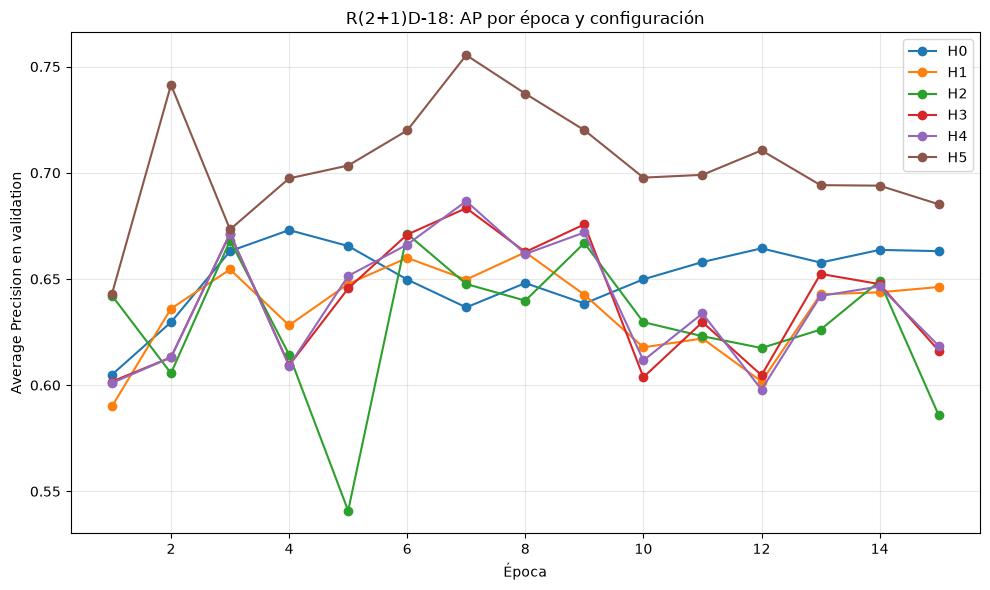

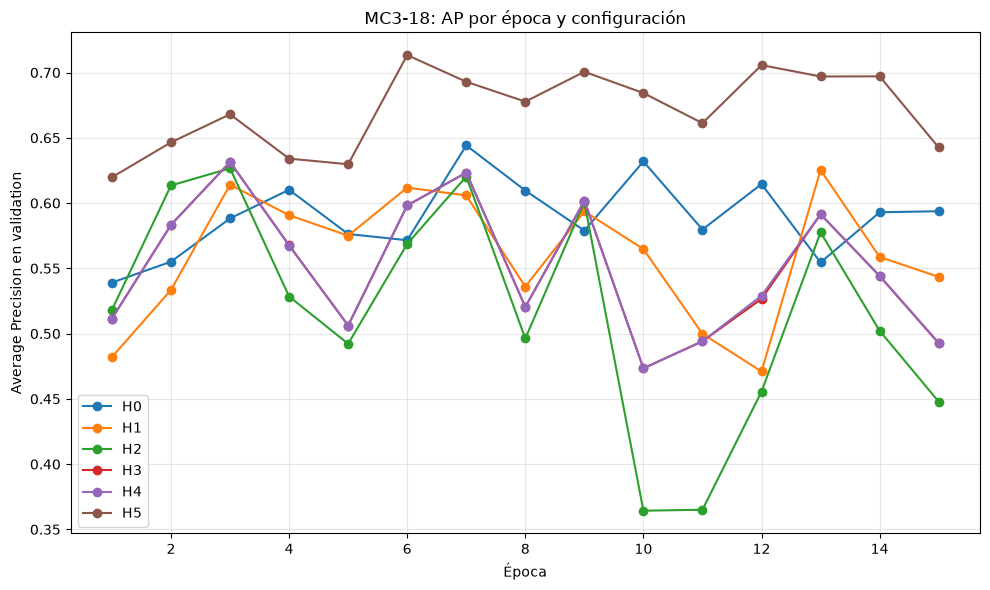

In [75]:
# ============================================================
# Sensibilidad de AP por época y configuración
# ============================================================

historiales_sensibilidad = []


# ------------------------------------------------------------
# H0: configuraciones iniciales
# ------------------------------------------------------------

historiales_h0 = {
    "R(2+1)D-18": HISTORIAL_R2PLUS1D_AVANCE4,
    "MC3-18": HISTORIAL_MC3_AVANCE4
}


for modelo, historial_path in historiales_h0.items():

    historial = pd.read_csv(
        historial_path
    ).copy()

    historial["modelo"] = modelo
    historial["configuracion"] = "H0"

    historiales_sensibilidad.append(
        historial
    )


# ------------------------------------------------------------
# H1-H5: historiales del tuning
# ------------------------------------------------------------

for _, experimento in tabla_plan_tuning_rgb.iterrows():

    modelo = experimento["modelo"]
    configuracion = experimento["configuracion"]

    checkpoint_path = (
        REPO_DIR
        / Path(
            experimento["checkpoint"]
        )
    )

    historial_path = checkpoint_path.with_name(
        checkpoint_path.stem
        + "_history.csv"
    )

    if not historial_path.exists():
        raise FileNotFoundError(
            f"No se encontró el historial: "
            f"{historial_path.relative_to(REPO_DIR)}"
        )

    historial = pd.read_csv(
        historial_path
    ).copy()

    historial["modelo"] = modelo
    historial["configuracion"] = configuracion

    historiales_sensibilidad.append(
        historial
    )


# ------------------------------------------------------------
# Consolidación y validación
# ------------------------------------------------------------

historial_sensibilidad_rgb = pd.concat(
    historiales_sensibilidad,
    ignore_index=True
)


assert set(
    historial_sensibilidad_rgb[
        "modelo"
    ].unique()
) == {
    "R(2+1)D-18",
    "MC3-18"
}


assert set(
    historial_sensibilidad_rgb[
        "configuracion"
    ].unique()
) == {
    "H0",
    "H1",
    "H2",
    "H3",
    "H4",
    "H5"
}


assert (
    historial_sensibilidad_rgb[
        ["modelo", "configuracion"]
    ]
    .drop_duplicates()
    .shape[0]
    == 12
)


# ------------------------------------------------------------
# Resumen: mejor época y mejor AP
# ------------------------------------------------------------

indices_mejor_ap = (
    historial_sensibilidad_rgb
    .groupby(
        ["modelo", "configuracion"]
    )["val_average_precision"]
    .idxmax()
)


tabla_sensibilidad_ap = (
    historial_sensibilidad_rgb
    .loc[
        indices_mejor_ap,
        [
            "modelo",
            "configuracion",
            "epoch",
            "val_average_precision"
        ]
    ]
    .rename(
        columns={
            "modelo": "Modelo",
            "configuracion": "Configuración",
            "epoch": "Mejor época",
            "val_average_precision": "Mejor AP"
        }
    )
    .sort_values(
        ["Modelo", "Configuración"]
    )
    .reset_index(drop=True)
)


display(
    tabla_sensibilidad_ap.style.format(
        {
            "Mejor AP": "{:.4f}"
        }
    )
)


# ------------------------------------------------------------
# Curva R(2+1)D-18
# ------------------------------------------------------------

plt.figure(
    figsize=(10, 6)
)

for configuracion in [
    "H0",
    "H1",
    "H2",
    "H3",
    "H4",
    "H5"
]:

    datos = historial_sensibilidad_rgb[
        (
            historial_sensibilidad_rgb["modelo"]
            == "R(2+1)D-18"
        )
        &
        (
            historial_sensibilidad_rgb["configuracion"]
            == configuracion
        )
    ]

    plt.plot(
        datos["epoch"],
        datos["val_average_precision"],
        marker="o",
        label=configuracion
    )


plt.xlabel("Época")
plt.ylabel("Average Precision en validation")

plt.title(
    "R(2+1)D-18: AP por época y configuración"
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Curva MC3-18
# ------------------------------------------------------------

plt.figure(
    figsize=(10, 6)
)

for configuracion in [
    "H0",
    "H1",
    "H2",
    "H3",
    "H4",
    "H5"
]:

    datos = historial_sensibilidad_rgb[
        (
            historial_sensibilidad_rgb["modelo"]
            == "MC3-18"
        )
        &
        (
            historial_sensibilidad_rgb["configuracion"]
            == configuracion
        )
    ]

    plt.plot(
        datos["epoch"],
        datos["val_average_precision"],
        marker="o",
        label=configuracion
    )


plt.xlabel("Época")
plt.ylabel("Average Precision en validation")

plt.title(
    "MC3-18: AP por época y configuración"
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### Interpretación de las curvas de sensibilidad

Las curvas muestran que el efecto de las configuraciones evaluadas fue diferente entre ambas arquitecturas y que la incorporación de **H5** produjo el cambio más importante observado durante el ajuste. En **R(2+1)D-18**, H5 alcanzó el mayor Average Precision, con **0.7554 en la época 7**, frente a **0.6867 de H4** y **0.6730 de H0**. Aunque su trayectoria presenta variación entre épocas, H5 mantiene valores de AP superiores a las configuraciones H0-H4 durante buena parte del entrenamiento. Las configuraciones H3 y H4 continúan mostrando resultados cercanos entre sí, pero quedan claramente por debajo del máximo alcanzado por H5.

En **MC3-18** se observa un comportamiento similar. H5 alcanzó un AP máximo de **0.7134 en la época 6**, superando a **H0, con 0.6442**, que previamente había sido la mejor configuración. Las configuraciones H1-H4 permanecieron por debajo de H0 en sus mejores épocas, mientras que H5 produjo una mejora clara al aumentar la profundidad del fine-tuning.

Estos resultados modifican la interpretación obtenida inicialmente con H1-H4. La exploración limitada a tasas de aprendizaje y `weight_decay` sugería rendimientos decrecientes y una sensibilidad relativamente pequeña alrededor de H0. Al incorporar en H5 una dimensión diferente del espacio de búsqueda, la **profundidad del fine-tuning**, se obtuvieron mejoras de **0.0824 puntos de AP respecto a H0 en R(2+1)D-18** y de **0.0692 puntos en MC3-18**. Por lo tanto, la aparente estabilización observada con H1-H4 correspondía al espacio local explorado por esos hiperparámetros y no a una saturación del espacio de ajuste del modelo.

En ambas arquitecturas, el mejor desempeño de H5 ocurre antes de la última época y posteriormente el Average Precision disminuye. Esto respalda la decisión de conservar para cada configuración el checkpoint correspondiente al mayor AP observado en `validation`, en lugar de utilizar automáticamente los pesos de la última época. El análisis continúa siendo descriptivo: existe una sola corrida por configuración y una única partición de `validation`, por lo que los resultados no permiten estimar variabilidad estadística ni garantizar que las mismas diferencias se mantengan con otras semillas o particiones.

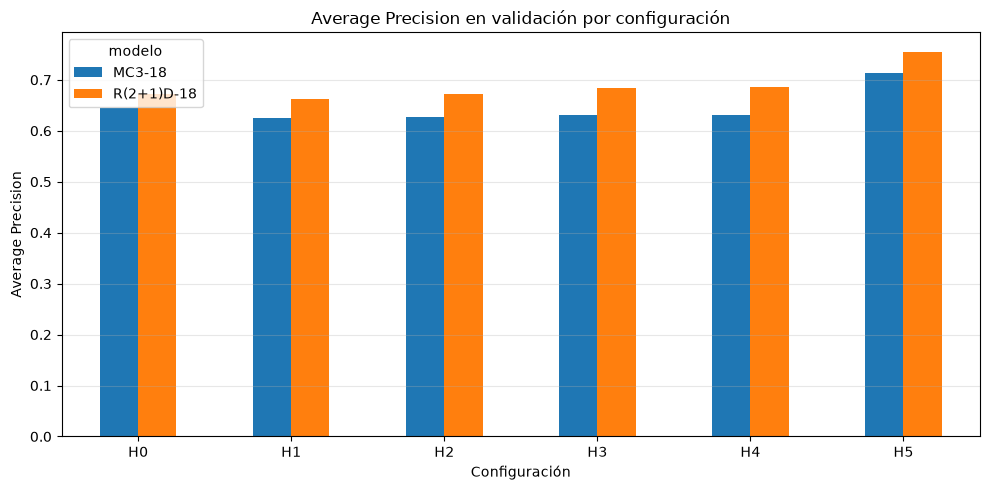

In [76]:
# ============================================================
# Gráfica: Comparación final de AP por configuración y modelo
# ============================================================

fig, ax = plt.subplots(figsize=(10, 5))

tabla_plot = tabla_resultados_tuning.pivot(
    index="configuracion",
    columns="modelo",
    values="val_ap"
).loc[["H0", "H1", "H2", "H3", "H4", "H5"]]

tabla_plot.plot(
    kind="bar",
    ax=ax
)

ax.set_title("Average Precision en validación por configuración")
ax.set_xlabel("Configuración")
ax.set_ylabel("Average Precision")
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

#### 8.9.3.3 Interpretación de la gráfica de comparación final de AP por configuración y modelo

En **R(2+1)D-18**, la configuración **H5** alcanzó el mayor Average Precision en `validation`, con **0.7554**, superando a H4 (**0.6867**), H3 (**0.6834**) y a la configuración inicial H0 (**0.6730**). Las configuraciones H1 y H2 permanecieron por debajo de H0. La mejora de H5 respecto a H0 fue de **0.0824 puntos absolutos de AP**.

En **MC3-18**, H5 también obtuvo el mejor resultado, con un Average Precision de **0.7134**, frente a **0.6442 de H0**. Las configuraciones H1-H4 no lograron superar la referencia inicial, por lo que la mejora observada con H5 muestra que aumentar la profundidad del fine-tuning tuvo un efecto diferente y más favorable que modificar únicamente las tasas de aprendizaje y `weight_decay`. La mejora de H5 respecto a H0 fue de **0.0692 puntos absolutos de AP**.

En conjunto, la configuración **H5** produjo el mejor Average Precision para las dos arquitecturas evaluadas. Por este motivo, **R(2+1)D-18/H5** y **MC3-18/H5** se conservan como las configuraciones optimizadas de sus respectivas arquitecturas para la comparación entre los dos finalistas. La selección entre H0-H5 se realizó utilizando exclusivamente **Average Precision en `validation`** como métrica principal.

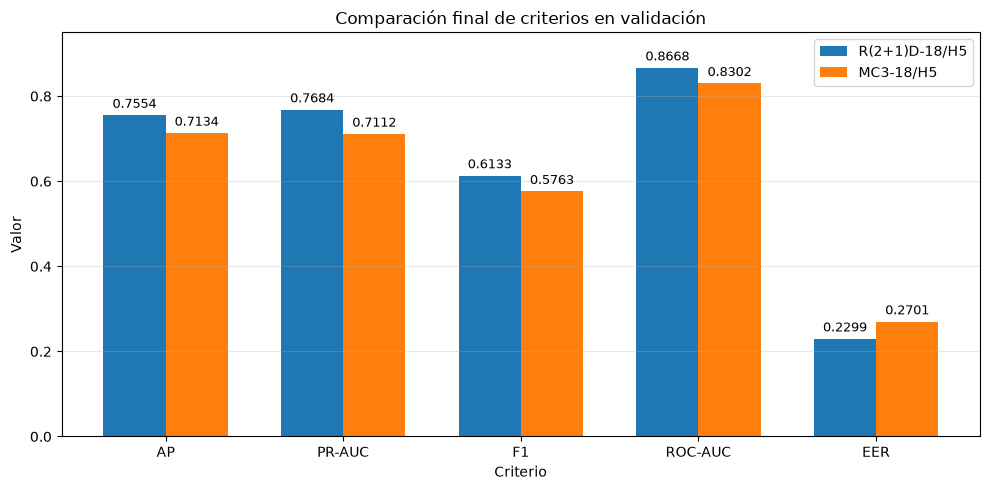

In [77]:
# ============================================================
# Gráfica final de comparación entre los dos modelos finalistas
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# Valores en validación
metricas_finalistas = {
    "AP": {
        "R(2+1)D-18/H5": 0.7554,
        "MC3-18/H5": 0.7134,
    },
    "PR-AUC": {
        "R(2+1)D-18/H5": 0.7684,
        "MC3-18/H5": 0.7112,
    },
    "F1": {
        "R(2+1)D-18/H5": 0.6133,
        "MC3-18/H5": 0.5763,
    },
    "ROC-AUC": {
        "R(2+1)D-18/H5": 0.8668,
        "MC3-18/H5": 0.8302,
    },
    "EER": {
        "R(2+1)D-18/H5": 0.2299,
        "MC3-18/H5": 0.2701,
    },
}

criterios = list(metricas_finalistas.keys())
modelo_a = "R(2+1)D-18/H5"
modelo_b = "MC3-18/H5"

valores_a = [
    metricas_finalistas[c][modelo_a]
    for c in criterios
]

valores_b = [
    metricas_finalistas[c][modelo_b]
    for c in criterios
]

x = np.arange(len(criterios))
ancho = 0.35

fig, ax = plt.subplots(figsize=(10, 5))

barras_a = ax.bar(
    x - ancho / 2,
    valores_a,
    width=ancho,
    label=modelo_a
)

barras_b = ax.bar(
    x + ancho / 2,
    valores_b,
    width=ancho,
    label=modelo_b
)

ax.set_title("Comparación final de criterios en validación")
ax.set_xlabel("Criterio")
ax.set_ylabel("Valor")
ax.set_xticks(x)
ax.set_xticklabels(criterios)
ax.set_ylim(0, 0.95)
ax.grid(axis="y", alpha=0.3)
ax.legend()

for barras in [barras_a, barras_b]:
    for barra in barras:
        altura = barra.get_height()
        ax.text(
            barra.get_x() + barra.get_width() / 2,
            altura + 0.01,
            f"{altura:.4f}",
            ha="center",
            va="bottom",
            fontsize=9
        )

plt.tight_layout()
plt.show()

### 8.9.4 Selección del modelo final

La selección entre las configuraciones H0-H5 se realizó utilizando **Average Precision en `validation`** como métrica principal, complementada con PR-AUC, F1, ROC-AUC y EER.

Una vez identificadas las mejores configuraciones de cada arquitectura, la comparación se redujo a **R(2+1)D-18/H5** y **MC3-18/H5**. Como se observa en la gráfica comparativa, R(2+1)D-18/H5 obtuvo mejores resultados en todas las métricas consideradas. Alcanzó un **Average Precision de 0.7554**, un **PR-AUC de 0.7684**, un **F1 de 0.6133** y un **ROC-AUC de 0.8668**, frente a **0.7134**, **0.7112**, **0.5763** y **0.8302**, respectivamente, para MC3-18/H5. En EER, donde un valor menor representa un mejor resultado, R(2+1)D-18/H5 obtuvo **0.2299**, frente a **0.2701** de MC3-18/H5.

La diferencia en la métrica principal fue de aproximadamente **0.0420 puntos absolutos de Average Precision** a favor de R(2+1)D-18/H5. La ventaja observada también se mantiene en PR-AUC, F1, ROC-AUC y EER, por lo que la selección no depende únicamente de la métrica principal.

Desde el punto de vista computacional, MC3-18 conserva ventajas estructurales respecto a R(2+1)D-18, principalmente por su menor número total de parámetros y menor consumo de memoria observado en la comparación inicial de arquitecturas. Sin embargo, ambas configuraciones H5 aumentan la profundidad del fine-tuning respecto a sus configuraciones iniciales. En R(2+1)D-18/H5 se entrenó aproximadamente **75.07% de los parámetros**, mientras que en MC3-18/H5 se entrenó aproximadamente **73.05%**. En el hardware utilizado, el tiempo de entrenamiento de ambas arquitecturas se mantuvo en un orden de magnitud similar, por lo que la diferencia de desempeño en `validation` tuvo mayor peso en la decisión.

La interpretabilidad continúa siendo una limitación de la alternativa seleccionada. R(2+1)D-18 es una red convolucional 3D que produce una puntuación de clasificación a partir del contenido espacio-temporal del clip, pero no proporciona de forma intrínseca una explicación legible de qué regiones, movimientos u objetos determinaron cada predicción. Una eventual implementación requeriría complementar las métricas de desempeño con análisis post hoc de errores o técnicas específicas de explicación si BNext necesitara justificar individualmente las alertas generadas.

Con base en estos resultados, se seleccionó **R(2+1)D-18 con la configuración H5** como el modelo individual con mejor desempeño en `validation` entre las alternativas evaluadas. La decisión prioriza Average Precision como métrica principal y se encuentra respaldada por mejores valores de PR-AUC, F1 y ROC-AUC, así como por un menor EER respecto a MC3-18/H5. La preferencia cualitativa expresada por BNext por reducir falsas alarmas se mantiene como criterio de negocio para interpretar posteriormente el punto de operación del modelo.

### 8.10 Evaluación final sobre el conjunto de test


#### 8.10.1 Selección y congelación del umbral de decisión

In [78]:
# ============================================================
# Selección del umbral final sobre validation
# R(2+1)D-18 / H5
# ============================================================

import torch.nn as nn


CHECKPOINT_FINAL_RGB = (
    CHECKPOINT_DIR
    / "r2plus1d_18_avance4_h5.pt"
)

modelo_final_rgb = crear_modelo_rgb(
    "R(2+1)D-18",
    num_classes=2,
    pretrained=False
)

checkpoint_final_rgb = torch.load(
    CHECKPOINT_FINAL_RGB,
    map_location=DEVICE,
    weights_only=False
)

modelo_final_rgb.load_state_dict(
    checkpoint_final_rgb["model_state_dict"]
)

modelo_final_rgb = modelo_final_rgb.to(
    DEVICE
)

criterio_final_rgb = nn.CrossEntropyLoss()

resultado_val_final_rgb = evaluar_modelo_rgb(
    modelo=modelo_final_rgb,
    loader=loaders_rgb["R(2+1)D-18"]["val"],
    criterio=criterio_final_rgb,
    device=DEVICE,
    usar_amp=USAR_AMP_RGB,
    threshold=0.5
)

y_val_final = resultado_val_final_rgb["y_true"]
p_val_final = resultado_val_final_rgb["y_prob"]

thresholds_candidatos = np.unique(
    p_val_final
)

resultados_threshold = []

for threshold in thresholds_candidatos:

    metricas = calcular_metricas(
        y_val_final,
        p_val_final,
        threshold=threshold
    )

    resultados_threshold.append(
        {
            "threshold": threshold,
            "f1": metricas["f1"],
            "recall": metricas["recall"],
            "precision": metricas["precision"],
            "specificity": metricas["specificity"],
            "tn": metricas["tn"],
            "fp": metricas["fp"],
            "fn": metricas["fn"],
            "tp": metricas["tp"]
        }
    )

df_thresholds_final = pd.DataFrame(
    resultados_threshold
)

mejor_threshold = (
    df_thresholds_final
    .sort_values(
        ["f1", "recall", "precision"],
        ascending=[False, False, False]
    )
    .iloc[0]
)

THRESHOLD_FINAL_RGB = float(
    mejor_threshold["threshold"]
)

print(
    f"Threshold final seleccionado: "
    f"{THRESHOLD_FINAL_RGB:.4f}"
)

display(
    mejor_threshold.to_frame(
        name="valor"
    ).T.style.format(
        {
            "threshold": "{:.4f}",
            "f1": "{:.4f}",
            "recall": "{:.4f}",
            "precision": "{:.4f}",
            "specificity": "{:.4f}"
        }
    )
)

Threshold final seleccionado: 0.9971


,threshold,f1,recall,precision,specificity,tn,fp,fn,tp
valor,0.9971,0.7347,0.6000,0.9474,0.9906,105.000000,1.000000,12.000000,18.000000


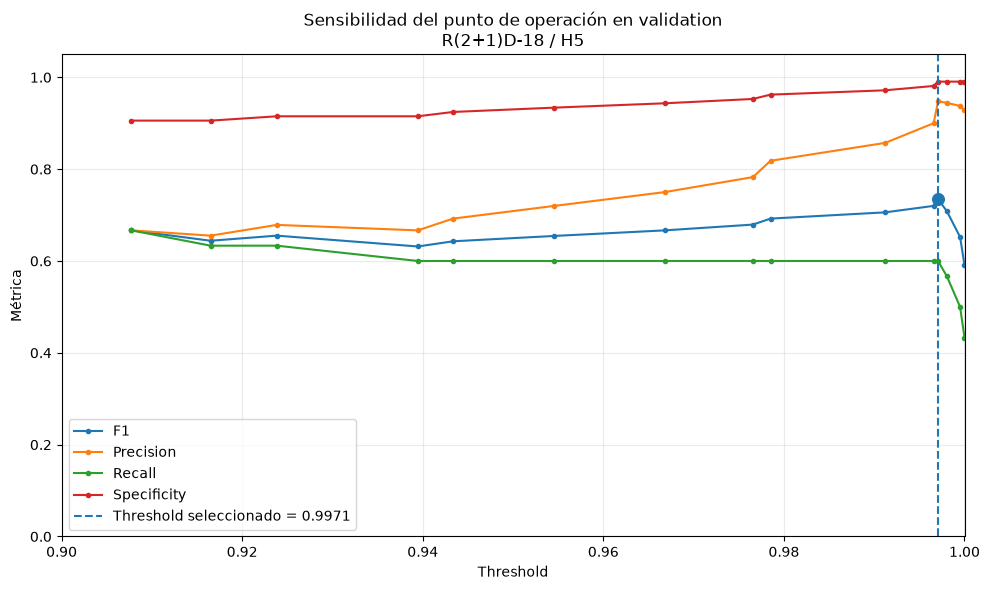

In [79]:
# ============================================================
# Sensibilidad del punto de operación en validation
# R(2+1)D-18 / H5
# ============================================================

df_sensibilidad_threshold = (
    df_thresholds_final
    .sort_values("threshold")
    .reset_index(drop=True)
)

# Zoom en la región donde quedó el threshold óptimo.
df_sensibilidad_zoom = (
    df_sensibilidad_threshold[
        df_sensibilidad_threshold["threshold"] >= 0.90
    ]
    .copy()
)

fig, ax = plt.subplots(figsize=(10, 6))

for metrica, etiqueta in [
    ("f1", "F1"),
    ("precision", "Precision"),
    ("recall", "Recall"),
    ("specificity", "Specificity"),
]:
    ax.plot(
        df_sensibilidad_zoom["threshold"],
        df_sensibilidad_zoom[metrica],
        marker="o",
        markersize=3,
        linewidth=1.5,
        label=etiqueta
    )

ax.axvline(
    THRESHOLD_FINAL_RGB,
    linestyle="--",
    linewidth=1.5,
    label=(
        f"Threshold seleccionado = "
        f"{THRESHOLD_FINAL_RGB:.4f}"
    )
)

ax.scatter(
    [THRESHOLD_FINAL_RGB],
    [mejor_threshold["f1"]],
    s=70,
    zorder=5
)

ax.set_xlim(0.90, 1.00)
ax.set_ylim(0.0, 1.05)

ax.set_xlabel("Threshold")
ax.set_ylabel("Métrica")

ax.set_title(
    "Sensibilidad del punto de operación en validation\n"
    "R(2+1)D-18 / H5"
)

ax.grid(alpha=0.25)
ax.legend()

plt.tight_layout()
plt.show()

#### Análisis de sensibilidad del threshold en `validation`

La sensibilidad del punto de operación muestra que el threshold seleccionado de **0.9971**, aunque numéricamente elevado, corresponde al máximo F1 observado en `validation` y no a un pico aislado producido por un cambio abrupto en las métricas.

En la región comprendida aproximadamente entre **0.94 y 0.9971**, el recall permanece estable alrededor de **0.60**, mientras que precision y specificity aumentan progresivamente. Como resultado, F1 también mejora hasta alcanzar **0.7347** en el threshold seleccionado. Al incrementar el threshold por encima de este punto, el recall comienza a disminuir y F1 se deteriora.

Este comportamiento indica que, para esta configuración, el valor elevado del threshold es consecuencia de la distribución de los scores producidos por el modelo y del criterio de selección utilizado, y no constituye por sí mismo evidencia de una selección incorrecta del punto de operación.

La concentración de scores cerca de los extremos, especialmente alrededor de 1.0, también sugiere que las salidas `softmax` de H5 pueden presentar un nivel elevado de confianza. Por esta razón, los valores se interpretan principalmente como scores de discriminación y no como probabilidades calibradas. Una evaluación formal de calibración requeriría métricas y procedimientos adicionales y queda fuera del alcance de este avance.

#### Conclusiones para la selección y congelación del umbral de decisión

Una vez seleccionado **R(2+1)D-18/H5** como modelo individual final con base en su desempeño sobre `validation`, se definió su threshold utilizando exclusivamente este conjunto.

Durante las etapas anteriores se utilizó un threshold provisional de **0.5** para calcular métricas dependientes de un punto de decisión. Este valor constituye una convención y no necesariamente representa el mejor punto de operación para el problema.

BNext expresó cualitativamente una preferencia por reducir falsas alarmas, debido al costo operativo y reputacional que podría tener una intervención sobre un caso incorrecto. Sin embargo, esta preferencia no establece una función de costo formal ni valores objetivo de precision, recall o specificity que permitan optimizar directamente el threshold con un criterio comercial.

Por esta razón se mantuvo un procedimiento reproducible basado exclusivamente en `validation`. Las salidas del modelo se transformaron mediante `softmax` en scores para la clase `ocultamiento` y se evaluaron los valores observados como thresholds candidatos. Se seleccionó el threshold que maximizó **F1**, utilizando **recall** y posteriormente **precision** como criterios de desempate.

El threshold seleccionado fue **0.9971**, con el cual el modelo alcanzó en `validation` un **F1 de 0.7347**, **recall de 0.6000**, **precision de 0.9474** y **specificity de 0.9906**. La matriz de confusión correspondiente contiene **18 verdaderos positivos, 12 falsos negativos, 1 falso positivo y 105 verdaderos negativos**.

Aunque el valor numérico del threshold es elevado, el análisis de sensibilidad muestra que no corresponde a un máximo aislado. En una región amplia previa al punto seleccionado, el recall se mantiene aproximadamente en **0.60**, mientras precision y specificity aumentan progresivamente. El F1 alcanza su máximo en **0.9971** y comienza a deteriorarse al incrementar aún más el threshold debido a la reducción del recall.

Este comportamiento indica que el punto de operación seleccionado es consistente con la distribución de scores producida por H5 y con el criterio definido sobre `validation`. Al mismo tiempo, la concentración de scores cercanos a los extremos sugiere interpretar las salidas `softmax` principalmente como valores de discriminación, sin asumir que representan probabilidades calibradas.

El punto de operación mantiene valores altos de precision y specificity, aunque conserva una proporción relevante de falsos negativos. Por ello, se interpreta como un criterio experimental reproducible y no como un threshold operativo definitivo para una implementación en tienda. Una definición operativa requeriría incorporar costos asociados a falsos positivos y falsos negativos, así como requisitos explícitos de BNext.

A partir de este punto, el **checkpoint R(2+1)D-18/H5** y el **threshold 0.9971** quedan congelados para la evaluación sobre `test`. Los resultados obtenidos posteriormente se utilizan para caracterizar el comportamiento de esta configuración y no para modificar el modelo ni el threshold dentro de este avance.

#### 8.10.2 Evaluación final sobre el conjunto de test

In [80]:
# ============================================================
# Evaluación final de R(2+1)D-18/H5 sobre test
# ============================================================

resultado_test_final_rgb = evaluar_modelo_rgb(
    modelo=modelo_final_rgb,
    loader=loaders_rgb["R(2+1)D-18"]["test"],
    criterio=criterio_final_rgb,
    device=DEVICE,
    usar_amp=USAR_AMP_RGB,
    threshold=THRESHOLD_FINAL_RGB
)

metricas_test_final_rgb = (
    resultado_test_final_rgb["metricas"]
)

tabla_test_final_rgb = pd.DataFrame(
    [
        {
            "Modelo": "R(2+1)D-18",
            "Configuración": "H5",
            "Threshold": THRESHOLD_FINAL_RGB,
            "AP": metricas_test_final_rgb[
                "average_precision"
            ],
            "PR-AUC": metricas_test_final_rgb[
                "pr_auc"
            ],
            "ROC-AUC": metricas_test_final_rgb[
                "roc_auc"
            ],
            "EER": metricas_test_final_rgb[
                "eer"
            ],
            "Accuracy": metricas_test_final_rgb[
                "accuracy"
            ],
            "Precision": metricas_test_final_rgb[
                "precision"
            ],
            "Recall": metricas_test_final_rgb[
                "recall"
            ],
            "Specificity": metricas_test_final_rgb[
                "specificity"
            ],
            "F1": metricas_test_final_rgb[
                "f1"
            ],
            "TN": metricas_test_final_rgb["tn"],
            "FP": metricas_test_final_rgb["fp"],
            "FN": metricas_test_final_rgb["fn"],
            "TP": metricas_test_final_rgb["tp"],
        }
    ]
)

display(
    tabla_test_final_rgb.style.format(
        {
            "Threshold": "{:.4f}",
            "AP": "{:.4f}",
            "PR-AUC": "{:.4f}",
            "ROC-AUC": "{:.4f}",
            "EER": "{:.4f}",
            "Accuracy": "{:.4f}",
            "Precision": "{:.4f}",
            "Recall": "{:.4f}",
            "Specificity": "{:.4f}",
            "F1": "{:.4f}",
        }
    )
)

,Modelo,Configuración,Threshold,AP,PR-AUC,ROC-AUC,EER,Accuracy,Precision,Recall,Specificity,F1,TN,FP,FN,TP
0,R(2+1)D-18,H5,0.9971,0.7551,0.7715,0.9446,0.0798,0.9338,0.7857,0.6471,0.9748,0.7097,116,3,6,11


In [81]:
# ============================================================
# Comparación histórica: baseline vs modelo final sobre test v2
# ============================================================

tabla_baseline_vs_final = pd.DataFrame(
    [
        {
            "Modelo": "R3D-18",
            "Configuración": "Baseline Avance 3",
            "Threshold": THRESHOLD_FINAL,
            "AP": metricas_v2["average_precision"],
            "PR-AUC": metricas_v2["pr_auc"],
            "ROC-AUC": metricas_v2["roc_auc"],
            "EER": metricas_v2["eer"],
            "Accuracy": metricas_v2["accuracy"],
            "Precision": metricas_v2["precision"],
            "Recall": metricas_v2["recall"],
            "Specificity": metricas_v2["specificity"],
            "F1": metricas_v2["f1"],
            "TN": metricas_v2["tn"],
            "FP": metricas_v2["fp"],
            "FN": metricas_v2["fn"],
            "TP": metricas_v2["tp"]
        },
        {
            "Modelo": "R(2+1)D-18",
            "Configuración": "H5",
            "Threshold": THRESHOLD_FINAL_RGB,
            "AP": metricas_test_final_rgb[
                "average_precision"
            ],
            "PR-AUC": metricas_test_final_rgb[
                "pr_auc"
            ],
            "ROC-AUC": metricas_test_final_rgb[
                "roc_auc"
            ],
            "EER": metricas_test_final_rgb["eer"],
            "Accuracy": metricas_test_final_rgb[
                "accuracy"
            ],
            "Precision": metricas_test_final_rgb[
                "precision"
            ],
            "Recall": metricas_test_final_rgb[
                "recall"
            ],
            "Specificity": metricas_test_final_rgb[
                "specificity"
            ],
            "F1": metricas_test_final_rgb["f1"],
            "TN": metricas_test_final_rgb["tn"],
            "FP": metricas_test_final_rgb["fp"],
            "FN": metricas_test_final_rgb["fn"],
            "TP": metricas_test_final_rgb["tp"]
        }
    ]
)

display(
    tabla_baseline_vs_final.style.format(
        {
            "Threshold": "{:.4f}",
            "AP": "{:.4f}",
            "PR-AUC": "{:.4f}",
            "ROC-AUC": "{:.4f}",
            "EER": "{:.4f}",
            "Accuracy": "{:.4f}",
            "Precision": "{:.4f}",
            "Recall": "{:.4f}",
            "Specificity": "{:.4f}",
            "F1": "{:.4f}"
        }
    )
)

,Modelo,Configuración,Threshold,AP,PR-AUC,ROC-AUC,EER,Accuracy,Precision,Recall,Specificity,F1,TN,FP,FN,TP
0,R3D-18,Baseline Avance 3,0.7090,0.6067,0.5858,0.9249,0.1092,0.9044,0.5769,0.8824,0.9076,0.6977,108,11,2,15
1,R(2+1)D-18,H5,0.9971,0.7551,0.7715,0.9446,0.0798,0.9338,0.7857,0.6471,0.9748,0.7097,116,3,6,11


#### Comparación del baseline con el modelo final sobre `test v2`

La comparación anterior utiliza el mismo conjunto `test v2`, pero corresponde a dos puntos de operación seleccionados sobre `validation`. R3D-18 utiliza el threshold de **0.7090** definido en el Avance 3, mientras que R(2+1)D-18/H5 utiliza el threshold de **0.9971** seleccionado para esta configuración. Por esta razón, AP, PR-AUC, ROC-AUC y EER permiten comparar la capacidad de discriminación sin depender de esos thresholds, mientras que accuracy, precision, recall, specificity, F1 y la matriz de confusión describen el comportamiento de cada modelo en su punto de operación correspondiente.

En `test v2`, **R(2+1)D-18/H5** obtiene mejores resultados que el baseline histórico en las cuatro métricas independientes del threshold. Average Precision aumenta de **0.6067 a 0.7551**, PR-AUC de **0.5858 a 0.7715** y ROC-AUC de **0.9249 a 0.9446**, mientras que EER disminuye de **0.1092 a 0.0798**. Estos resultados indican una mejor capacidad de discriminación del modelo H5 sobre este conjunto de prueba.

En las métricas dependientes del threshold se observa un cambio en el perfil de error. R(2+1)D-18/H5 reduce los falsos positivos de **11 a 3** y aumenta la precision de **0.5769 a 0.7857** y la specificity de **0.9076 a 0.9748**. Al mismo tiempo, los falsos negativos aumentan de **2 a 6** y el recall disminuye de **0.8824 a 0.6471**. El F1 aumenta ligeramente de **0.6977 a 0.7097** y la accuracy pasa de **0.9044 a 0.9338**.

Este comportamiento es relevante para el caso de BNext porque muestra de forma explícita el trade-off entre reducir falsas alarmas y conservar capacidad para detectar eventos positivos. El punto de operación de H5 produce menos alertas incorrectas que el baseline, pero deja sin detectar una proporción mayor de los eventos de ocultamiento presentes en `test v2`. Por esta razón, el threshold seleccionado debe interpretarse como un criterio experimental reproducible y no como un punto de operación definitivo para una implementación en tienda.

La comparación debe interpretarse como una referencia entre los dos pipelines y no como un experimento que aísle exclusivamente el efecto de la arquitectura. Existen diferencias de entrenamiento, preprocesamiento, configuración, profundidad de fine-tuning y threshold, por lo que las diferencias observadas describen el comportamiento de las configuraciones completas evaluadas y no pueden atribuirse únicamente a la arquitectura.

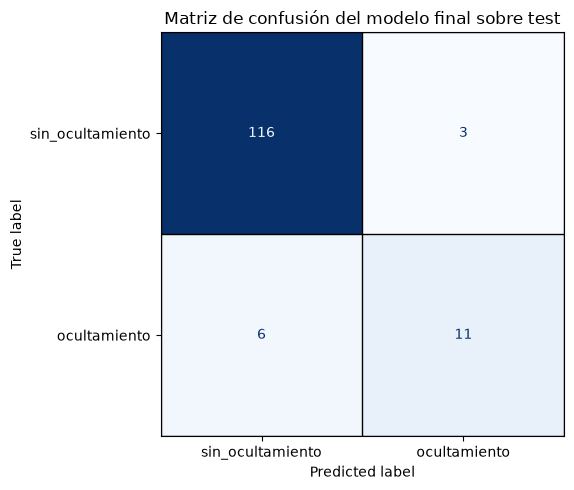

In [82]:
# ============================================================
# Matriz de confusión del modelo final sobre test
# ============================================================

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

y_test_final = np.asarray(
    resultado_test_final_rgb["y_true"]
)

p_test_final = np.asarray(
    resultado_test_final_rgb["y_prob"]
)

y_pred_test_final = (
    p_test_final >= THRESHOLD_FINAL_RGB
).astype(int)

matriz_confusion_final = confusion_matrix(
    y_test_final,
    y_pred_test_final,
    labels=[0, 1]
)

# Verificar consistencia con las métricas reportadas.
assert matriz_confusion_final[0, 0] == metricas_test_final_rgb["tn"]
assert matriz_confusion_final[0, 1] == metricas_test_final_rgb["fp"]
assert matriz_confusion_final[1, 0] == metricas_test_final_rgb["fn"]
assert matriz_confusion_final[1, 1] == metricas_test_final_rgb["tp"]

fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay(
    confusion_matrix=matriz_confusion_final,
    display_labels=[
        "sin_ocultamiento",
        "ocultamiento"
    ]
).plot(
    ax=ax,
    values_format="d",cmap="Blues", colorbar=False
)

for x in [-0.5, 0.5, 1.5]:
    ax.axvline(x, color="black", linewidth=1)

for y in [-0.5, 0.5, 1.5]:
    ax.axhline(y, color="black", linewidth=1)

ax.set_title(
    "Matriz de confusión del modelo final sobre test"
)

plt.tight_layout()
plt.show()

#### Conclusiones de la evaluación final sobre el conjunto de test

Una vez congelados el modelo **R(2+1)D-18/H5** y el umbral de decisión de **0.9971**, se evaluó esta configuración sobre el conjunto de **test v2** sin modificar posteriormente el checkpoint, los hiperparámetros ni el punto de decisión a partir de los resultados obtenidos.

El modelo obtuvo un **Average Precision de 0.7551**, un **PR-AUC de 0.7715**, un **ROC-AUC de 0.9446** y un **EER de 0.0798**. En las métricas dependientes del umbral alcanzó una **precision de 0.7857**, **recall de 0.6471**, **specificity de 0.9748** y **F1 de 0.7097**.

El comportamiento de las métricas Precision-Recall se mantuvo cercano al observado durante `validation`. El AP pasó de **0.7554 en validation a 0.7551 en test**, mientras que PR-AUC pasó de **0.7684 a 0.7715**. ROC-AUC aumentó de **0.8668 a 0.9446** y EER disminuyó de **0.2299 a 0.0798**. Estas diferencias se interpretan con cautela debido al número reducido de ejemplos positivos y a las diferencias de composición entre las particiones, por lo que no se consideran evidencia de que el modelo tenga un mejor desempeño general en `test` que en `validation`.

Con el umbral previamente seleccionado, el modelo clasificó correctamente **116 de los 119 ejemplos negativos** y **11 de los 17 ejemplos positivos**, produciendo **3 falsos positivos y 6 falsos negativos**. La precision de **0.7857** y la specificity de **0.9748** muestran un comportamiento consistente con la preferencia cualitativa expresada por BNext de reducir falsas alarmas, ya que la mayoría de los casos negativos fueron correctamente rechazados y una proporción alta de las alertas positivas correspondió realmente a casos de ocultamiento. Sin embargo, el recall de **0.6471** continúa siendo una limitación relevante: el modelo dejó sin detectar **6 de los 17 casos positivos reales**, aproximadamente el **35.3%** de los eventos de ocultamiento presentes en `test v2`.

Los errores observados en esta evaluación se analizan cualitativamente en la siguiente sección con el objetivo de identificar patrones de fallo y limitaciones del modelo.

#### 8.10.3 Análisis de falsos positivos y falsos negativos

In [83]:
# ============================================================
# Identificación de errores del modelo final sobre test
# ============================================================

df_predicciones_test_final = (
    datasets_rgb["R(2+1)D-18"]["test"]
    .df
    .copy()
    .reset_index(drop=True)
)

y_true_test = np.asarray(
    resultado_test_final_rgb["y_true"]
)

p_test_final = np.asarray(
    resultado_test_final_rgb["y_prob"]
)

y_pred_test = (
    p_test_final >= THRESHOLD_FINAL_RGB
).astype(int)

# Verificar correspondencia exacta entre dataset y predicciones.
assert len(df_predicciones_test_final) == len(y_true_test)
assert len(y_true_test) == len(p_test_final)

assert np.array_equal(
    df_predicciones_test_final[
        "clase_binaria"
    ].to_numpy(),
    y_true_test
)

df_predicciones_test_final[
    "p_ocultamiento_final"
] = p_test_final

df_predicciones_test_final[
    "prediccion_final"
] = y_pred_test

df_predicciones_test_final[
    "margen_threshold"
] = (
    p_test_final
    - THRESHOLD_FINAL_RGB
)

df_predicciones_test_final[
    "tipo_resultado"
] = np.select(
    [
        (y_true_test == 0) & (y_pred_test == 1),
        (y_true_test == 1) & (y_pred_test == 0),
        (y_true_test == 1) & (y_pred_test == 1),
        (y_true_test == 0) & (y_pred_test == 0),
    ],
    [
        "FP",
        "FN",
        "TP",
        "TN",
    ],
    default=""
)

df_errores_test_final = (
    df_predicciones_test_final[
        df_predicciones_test_final[
            "tipo_resultado"
        ].isin(["FP", "FN"])
    ]
    .copy()
)

columnas_identificacion = [
    c
    for c in [
        "dataset",
        "video_id",
        "clip_id",
        "nombre_clip",
        "clase_binaria",
        "p_ocultamiento_final",
        "prediccion_final",
        "margen_threshold",
        "tipo_resultado",
    ]
    if c in df_errores_test_final.columns
]

df_errores_test_final = (
    df_errores_test_final[
        columnas_identificacion
    ]
    .sort_values(
        [
            "tipo_resultado",
            "p_ocultamiento_final"
        ],
        ascending=[True, True]
    )
    .reset_index(drop=True)
)

print(
    "Errores totales:",
    len(df_errores_test_final)
)

print(
    "\nErrores por tipo:"
)

display(
    df_errores_test_final[
        "tipo_resultado"
    ]
    .value_counts()
    .rename_axis("tipo")
    .to_frame("casos")
)

display(
    df_errores_test_final.style.format(
        {
            "p_ocultamiento_final": "{:.4f}",
            "margen_threshold": "{:+.4f}",
        }
    )
)

Errores totales: 9

Errores por tipo:


,casos
tipo,
FN,6
FP,3


,dataset,video_id,clip_id,nombre_clip,clase_binaria,p_ocultamiento_final,prediccion_final,margen_threshold,tipo_resultado
0,DCSASS,Shoplifting021_x264,Shoplifting021_x264_24,DCSASS__Shoplifting021_x264__Shoplifting021_x264_24.mp4,1,0.3213,0,-0.6758,FN
1,DCSASS,Shoplifting048_x264,Shoplifting048_x264_10,DCSASS__Shoplifting048_x264__Shoplifting048_x264_10.mp4,1,0.9395,0,-0.0576,FN
2,DCSASS,Shoplifting048_x264,Shoplifting048_x264_11,DCSASS__Shoplifting048_x264__Shoplifting048_x264_11.mp4,1,0.9478,0,-0.0493,FN
3,DCSASS,Shoplifting048_x264,Shoplifting048_x264_2,DCSASS__Shoplifting048_x264__Shoplifting048_x264_2.mp4,1,0.9824,0,-0.0146,FN
4,DCSASS,Shoplifting048_x264,Shoplifting048_x264_0,DCSASS__Shoplifting048_x264__Shoplifting048_x264_0.mp4,1,0.9902,0,-0.0068,FN
5,DCSASS,Shoplifting048_x264,Shoplifting048_x264_12,DCSASS__Shoplifting048_x264__Shoplifting048_x264_12.mp4,1,0.9946,0,-0.0024,FN
6,DCSASS,Shoplifting048_x264,Shoplifting048_x264_13,DCSASS__Shoplifting048_x264__Shoplifting048_x264_13.mp4,0,0.9976,1,+0.0005,FP
7,DCSASS,Shoplifting048_x264,Shoplifting048_x264_14,DCSASS__Shoplifting048_x264__Shoplifting048_x264_14.mp4,0,0.9990,1,+0.0020,FP
8,MNNIT,normal-21,MNNIT_113,MNNIT__normal-21__MNNIT_113.mp4,0,1.0000,1,+0.0029,FP


In [84]:
# ============================================================
# Agrupación de errores por video para revisión visual
# ============================================================

df_errores_test_final["grupo_visual"] = (
    df_errores_test_final["dataset"].astype(str)
    + "__"
    + df_errores_test_final["video_id"].astype(str)
)

tabla_grupos_visuales = (
    df_errores_test_final
    .groupby(
        ["grupo_visual", "tipo_resultado"],
        as_index=False
    )
    .agg(
        n_clips=("clip_id", "size"),
        clips=("clip_id", lambda s: list(s))
    )
    .sort_values(
        ["tipo_resultado", "n_clips"],
        ascending=[True, False]
    )
    .reset_index(drop=True)
)

display(tabla_grupos_visuales)

,grupo_visual,tipo_resultado,n_clips,clips
0,DCSASS__Shoplifting048_x264,FN,5,"[Shoplifting048_x264_10, Shoplifting048_x264_1..."
1,DCSASS__Shoplifting021_x264,FN,1,[Shoplifting021_x264_24]
2,DCSASS__Shoplifting048_x264,FP,2,"[Shoplifting048_x264_13, Shoplifting048_x264_14]"
3,MNNIT__normal-21,FP,1,[MNNIT_113]


In [85]:
# ============================================================
# Generación de GIF de los errores del modelo final
# ============================================================

from Scripts.generar_gifs_evidencias import crear_gif


GIFS_AVANCE4_DIR = (
    REPO_DIR
    / "Datos"
    / "Preparacion_Datasets"
    / "evidencias_avance4"
    / "gifs"
)

GIFS_AVANCE4_DIR.mkdir(
    parents=True,
    exist_ok=True
)


gifs_generados = []

for _, fila in df_errores_test_final.iterrows():

    ruta_video = (
        CLIPS_DIR
        / fila["nombre_clip"]
    )

    ruta_gif = (
        GIFS_AVANCE4_DIR
        / f"{fila['clip_id']}.gif"
    )

    crear_gif(
        ruta_video=ruta_video,
        ruta_gif=ruta_gif
    )

    gifs_generados.append(
        {
            "grupo_visual": fila["grupo_visual"],
            "clip_id": fila["clip_id"],
            "tipo_resultado": fila["tipo_resultado"],
            "gif": ruta_gif.name
        }
    )


df_gifs_errores = pd.DataFrame(
    gifs_generados
)

display(df_gifs_errores)

,grupo_visual,clip_id,tipo_resultado,gif
0,DCSASS__Shoplifting021_x264,Shoplifting021_x264_24,FN,Shoplifting021_x264_24.gif
1,DCSASS__Shoplifting048_x264,Shoplifting048_x264_10,FN,Shoplifting048_x264_10.gif
2,DCSASS__Shoplifting048_x264,Shoplifting048_x264_11,FN,Shoplifting048_x264_11.gif
3,DCSASS__Shoplifting048_x264,Shoplifting048_x264_2,FN,Shoplifting048_x264_2.gif
4,DCSASS__Shoplifting048_x264,Shoplifting048_x264_0,FN,Shoplifting048_x264_0.gif
5,DCSASS__Shoplifting048_x264,Shoplifting048_x264_12,FN,Shoplifting048_x264_12.gif
6,DCSASS__Shoplifting048_x264,Shoplifting048_x264_13,FP,Shoplifting048_x264_13.gif
7,DCSASS__Shoplifting048_x264,Shoplifting048_x264_14,FP,Shoplifting048_x264_14.gif
8,MNNIT__normal-21,MNNIT_113,FP,MNNIT_113.gif


##### `Shoplifting048_x264`: falsos negativos concentrados en dos eventos

Cinco de los seis falsos negativos del modelo final corresponden a `Shoplifting048_x264` y se concentran en dos secuencias de ocultamiento realizadas por personas diferentes.

**Evento 1: mujer de rojo, clips 0–2**

| Clip 0 | Clip 1 |
|---|---|
| ![Shoplifting048_x264_0](../Datos/Preparacion_Datasets/evidencias_avance4/gifs/Shoplifting048_x264_0.gif) | ![Shoplifting048_x264_1](../Datos/Preparacion_Datasets/evidencias_avance4/gifs/Shoplifting048_x264_1.gif) |

| Clip 2 | |
|---|---|
| ![Shoplifting048_x264_2](../Datos/Preparacion_Datasets/evidencias_avance4/gifs/Shoplifting048_x264_2.gif) | |

En este primer evento, R(2+1)D-18/H5 clasifica correctamente el **clip 1**, mientras que los clips **0 y 2** son falsos negativos. Sin embargo, el modelo asigna a estos dos clips scores de ocultamiento de **0.9902** y **0.9824**, respectivamente. Ambos valores son altos, pero permanecen por debajo del threshold final de **0.9971**.

Por esta razón, estos errores no deben interpretarse directamente como ausencia de reconocimiento del patrón de ocultamiento. El modelo asigna una puntuación elevada a ambos casos y su clasificación negativa depende del punto de operación seleccionado sobre `validation`.

**Evento 2: mujer de verde, clips 10–12**

| Clip 10 | Clip 11 |
|---|---|
| ![Shoplifting048_x264_10](../Datos/Preparacion_Datasets/evidencias_avance4/gifs/Shoplifting048_x264_10.gif) | ![Shoplifting048_x264_11](../Datos/Preparacion_Datasets/evidencias_avance4/gifs/Shoplifting048_x264_11.gif) |

| Clip 12 | |
|---|---|
| ![Shoplifting048_x264_12](../Datos/Preparacion_Datasets/evidencias_avance4/gifs/Shoplifting048_x264_12.gif) | |

En el segundo evento, los tres clips son falsos negativos. Los scores asignados fueron **0.9395**, **0.9478** y **0.9946** para los clips 10, 11 y 12, respectivamente. El clip 12 se encuentra especialmente próximo al threshold de **0.9971**, mientras que los clips 10 y 11 presentan una separación mayor respecto al punto de decisión.

El patrón observado sugiere que los falsos negativos de este video tienen distinta severidad. Los clips 0, 2 y 12 reciben scores muy próximos al threshold y pueden considerarse errores fuertemente dependientes del punto de operación. Los clips 10 y 11 también reciben puntuaciones altas de ocultamiento, aunque con una separación mayor. En contraste, estos resultados no muestran scores bajos que permitan concluir que H5 sea incapaz de reconocer completamente las características asociadas al evento.

En conjunto, **cinco de los seis falsos negativos de `test v2`** se concentran en este único video. Esto explica una parte importante de la reducción del recall global y muestra que la decisión binaria final es sensible a la combinación entre la distribución de scores de H5 y el threshold seleccionado. El análisis de sensibilidad realizado sobre `validation` respalda conservar **0.9971** dentro del protocolo experimental, por lo que estos resultados se documentan como parte del trade-off del punto de operación y no se utilizan para reajustar el threshold a partir de `test`.

##### `Shoplifting021_x264_24`: falso negativo persistente

| Clip | Evidencia visual |
|---|---|
| `Shoplifting021_x264_24` | ![Shoplifting021_x264_24](../Datos/Preparacion_Datasets/evidencias_avance4/gifs/Shoplifting021_x264_24.gif) |

En este clip el evento de ocultamiento es observable y su etiqueta fue considerada clara durante la revisión cualitativa realizada en el Avance 3. El modelo final R(2+1)D-18/H5 asigna un score de ocultamiento de **0.3213**, considerablemente inferior al threshold final de **0.9971**, por lo que el caso se clasifica como falso negativo.

Este comportamiento es diferente al observado en los falsos negativos de `Shoplifting048_x264`, donde los scores se encuentran entre aproximadamente **0.94 y 0.99**. En `Shoplifting021_x264_24` existe una separación mucho mayor respecto al punto de decisión, por lo que el error parece estar asociado principalmente con la capacidad del modelo para discriminar este evento y no solamente con el threshold seleccionado.

El mismo clip también había sido clasificado incorrectamente por el baseline R3D-18 del Avance 3, que le asignó un score de ocultamiento de **0.0172**. H5 incrementa considerablemente la puntuación hasta **0.3213**, pero permanece lejos del rango necesario para producir una clasificación positiva bajo el punto de operación seleccionado.

La persistencia del error entre el baseline y el modelo final sugiere que este evento contiene características que resultan difíciles para ambas representaciones RGB evaluadas. Con la evidencia disponible no es posible determinar qué elemento visual o temporal provoca esta respuesta. Para establecerlo sería necesario realizar un análisis específico del clip y compararlo con ejemplos positivos correctamente clasificados que presenten condiciones visuales similares.

##### `MNNIT_113`: falso positivo persistente asociado con manipulación de una mochila

| Clip | Evidencia visual |
|---|---|
| `MNNIT_113` | ![MNNIT_113](../Datos/Preparacion_Datasets/evidencias_avance4/gifs/MNNIT_113.gif) |

La persona permanece frente al anaquel y manipula una mochila que no fue tomada de la mercancía disponible. Durante el clip comienza a abrirla y realiza movimientos de manos cerca del cuerpo, pero no se observa una acción de ocultamiento de mercancía. La etiqueta `sin_ocultamiento` se considera visualmente consistente con la definición operacional utilizada en el proyecto.

El modelo final **R(2+1)D-18/H5** asigna a este clip un score de ocultamiento de aproximadamente **1.0000**, que supera el threshold final de **0.9971** en aproximadamente **0.0029**, por lo que el caso se clasifica como falso positivo. Este mismo clip también había sido clasificado como falso positivo por el baseline R3D-18 del Avance 3, que había producido un score de **0.8105** con su propio punto de operación.

La persistencia del error entre ambas arquitecturas sugiere que la combinación de manipulación de una mochila, movimientos de manos y proximidad de los brazos al cuerpo contiene características visuales o espacio-temporales que los modelos pueden asociar con la clase de ocultamiento. Esta interpretación se mantiene como hipótesis, ya que las predicciones no permiten identificar directamente qué características fueron determinantes.

El caso resulta especialmente relevante para BNext porque la definición operacional del proyecto incluye ocultamiento en bolsas o mochilas. Una persona manipulando una pertenencia personal puede presentar movimientos visualmente similares a una acción objetivo sin que exista ocultamiento de mercancía, generando una posible fuente de falsas alertas que deberá estar representada adecuadamente entre los ejemplos negativos del dataset.

##### `Shoplifting048_x264_13` y `Shoplifting048_x264_14`: falsos positivos en la misma secuencia

| Clip 13 | Clip 14 |
|---|---|
| ![Shoplifting048_x264_13](../Datos/Preparacion_Datasets/evidencias_avance4/gifs/Shoplifting048_x264_13.gif) | ![Shoplifting048_x264_14](../Datos/Preparacion_Datasets/evidencias_avance4/gifs/Shoplifting048_x264_14.gif) |

Los clips `Shoplifting048_x264_13` y `Shoplifting048_x264_14` pertenecen a la clase `sin_ocultamiento`, pero R(2+1)D-18/H5 les asigna scores de ocultamiento de **0.9976** y **0.9990**, respectivamente. Ambos valores superan el threshold final de **0.9971**, aunque el clip 13 lo hace por un margen de solo **0.0005** y el clip 14 por aproximadamente **0.0020**.

Estos dos falsos positivos pertenecen al mismo video en el que se concentran cinco de los seis falsos negativos del modelo final. Además, aparecen inmediatamente después de los clips 10–12, correspondientes a una de las secuencias positivas analizadas previamente. Esta proximidad temporal hace relevante considerar que la segmentación en clips puede separar fragmentos consecutivos de una misma secuencia visual y que ciertos patrones espacio-temporales pueden extenderse más allá del intervalo etiquetado como positivo.

Con la evidencia disponible no puede afirmarse que ésta sea la causa de los falsos positivos. La clasificación también puede estar relacionada con características visuales presentes específicamente en los clips 13 y 14. Lo que sí muestran los resultados es que H5 asigna scores extremadamente altos tanto a algunos fragmentos positivos como a estos fragmentos negativos consecutivos, por lo que la frontera de decisión dentro de `Shoplifting048_x264` es especialmente sensible.

Este comportamiento refuerza la necesidad de revisar en etapas posteriores la definición temporal de los eventos y la estrategia de segmentación y etiquetado, especialmente alrededor de las transiciones entre `ocultamiento` y `sin_ocultamiento`.

##### Síntesis del análisis de errores

La revisión cualitativa de los **9 errores** del modelo final muestra patrones diferentes entre falsos negativos y falsos positivos. De los **6 falsos negativos**, cinco pertenecen a `Shoplifting048_x264` y se concentran en dos secuencias positivas del mismo video: los clips 0–2, asociados con la mujer de rojo, y los clips 10–12, asociados con la mujer de verde.

En estos cinco casos, R(2+1)D-18/H5 asigna scores de ocultamiento relativamente altos, entre **0.9395 y 0.9946**, pero inferiores al threshold final de **0.9971**. Tres de ellos, los clips 0, 2 y 12, quedan especialmente próximos al punto de decisión. Por esta razón, estos errores deben interpretarse considerando la interacción entre la distribución de scores del modelo y el threshold seleccionado, en lugar de atribuirse directamente a una incapacidad completa para reconocer el patrón de ocultamiento.

El sexto falso negativo, `Shoplifting021_x264_24`, presenta un comportamiento diferente. Su score de ocultamiento es de **0.3213**, considerablemente inferior al threshold final. Este mismo clip también había sido clasificado incorrectamente por el baseline R3D-18, por lo que se considera un error persistente entre ambas arquitecturas. La evidencia disponible no permite determinar qué característica visual o temporal explica esta baja puntuación.

Los **3 falsos positivos** también presentan patrones distintos. Dos de ellos, `Shoplifting048_x264_13` y `Shoplifting048_x264_14`, pertenecen al mismo video donde se concentran cinco falsos negativos y aparecen inmediatamente después de una de las secuencias positivas. Sus scores de **0.9976** y **0.9990** se encuentran apenas por encima del threshold de 0.9971. Este comportamiento hace relevante revisar en etapas posteriores la definición temporal de los eventos, la segmentación de clips y las transiciones entre intervalos etiquetados como `ocultamiento` y `sin_ocultamiento`.

El tercer falso positivo, `MNNIT_113`, corresponde a una persona que manipula una mochila personal frente al anaquel. El modelo asigna un score cercano a **1.0000**, y este mismo caso también había sido clasificado incorrectamente por el baseline. La combinación de manipulación de una mochila, movimientos de manos y proximidad al cuerpo constituye una posible fuente de confusión para el sistema, aunque esta explicación permanece como hipótesis.

En conjunto, el modelo final alcanza una **specificity de 0.9748** y genera únicamente **3 falsos positivos entre 119 ejemplos negativos**, comportamiento compatible con la preferencia cualitativa expresada por BNext de reducir falsas alarmas. Sin embargo, el **recall de 0.6471** indica que **6 de los 17 ejemplos positivos de test no fueron detectados**. Cinco de esos seis errores se concentran en un único video y, en varios casos, presentan scores muy próximos al punto de decisión.

Los resultados sugieren que las siguientes etapas deberían analizar con mayor detalle la calibración de los scores, la definición temporal de los eventos, la representatividad de los ejemplos de entrenamiento y los negativos difíciles que incluyen movimientos o pertenencias similares a los utilizados durante una acción de ocultamiento.

### 8.11 Comparación del costo computacional

#### 8.11.1 Comparación de costo computacional de los modelos RGB

Los cinco modelos RGB fueron entrenados y evaluados inicialmente bajo un protocolo común, antes del ajuste de hiperparámetros. Por esta razón, sus mediciones permiten una comparación directa del costo computacional de las arquitecturas en su **configuración inicial H0**. Además del desempeño predictivo, se registraron el tiempo total de entrenamiento, el pico de memoria GPU, el número de parámetros y la velocidad de inferencia.

| Modelo | AP validación H0 | Parámetros | Entrenamiento | GPU pico | Inferencia |
|---|---:|---:|---:|---:|---:|
| R(2+1)D-18 | **0.6730** | 31.30 M | 63.0 min | 2.32 GB | 3.19 clips/s |
| MViT-V2-S | 0.6473 | 34.23 M | 82.7 min | 5.60 GB | 2.26 clips/s |
| MC3-18 | 0.6442 | 11.49 M | **62.3 min** | 1.27 GB | 3.20 clips/s |
| R3D-18 | 0.6159 | 33.17 M | 66.3 min | **1.19 GB** | **3.44 clips/s** |
| S3D | 0.5978 | **7.91 M** | 65.5 min | 3.22 GB | 3.02 clips/s |

En esta comparación inicial, **R(2+1)D-18/H0** obtuvo el mayor Average Precision, con **0.6730**, utilizando aproximadamente **2.32 GB de memoria GPU** y alrededor de **63 minutos de entrenamiento**. Su velocidad de inferencia fue de aproximadamente **3.19 clips por segundo**. Este desempeño fue uno de los criterios utilizados para seleccionarlo posteriormente como candidato para el ajuste de hiperparámetros.

**MC3-18/H0** presentó un compromiso favorable entre desempeño y costo. Su AP de **0.6442** fue cercano al obtenido por MViT-V2-S, pero utilizó aproximadamente **11.49 millones de parámetros**, **1.27 GB de memoria GPU** y requirió cerca de **62 minutos de entrenamiento**. Esta relación entre desempeño y demanda computacional fue una de las razones para conservarlo como segundo candidato durante el ajuste de hiperparámetros.

**MViT-V2-S** fue la arquitectura más demandante de las cinco evaluadas inicialmente. Utilizó aproximadamente **5.60 GB de memoria GPU**, cerca del límite disponible en la NVIDIA GeForce RTX 3050 Laptop de 6 GB utilizada para los experimentos, y requirió aproximadamente **82.7 minutos de entrenamiento**. También presentó la menor velocidad de inferencia, cercana a **2.26 clips por segundo**. Aunque su AP fue ligeramente superior al de MC3-18, la diferencia de desempeño fue pequeña frente al incremento de recursos requerido.

**R3D-18** registró el menor consumo de memoria GPU, aproximadamente **1.19 GB**, y la mayor velocidad de inferencia, cercana a **3.44 clips por segundo**, aunque su AP de **0.6159** fue inferior al de los tres modelos RGB mejor posicionados. **S3D**, pese a contar con el menor número total de parámetros, requirió aproximadamente **3.22 GB de memoria GPU**, presentó una velocidad de inferencia cercana a **3.02 clips por segundo** y obtuvo el menor AP del grupo, lo que muestra que el número de parámetros por sí solo no determina el costo computacional ni el desempeño de una arquitectura de video.

En conjunto, esta comparación inicial muestra que la selección de candidatos para tuning no puede basarse únicamente en Average Precision. El tiempo de entrenamiento, el consumo de memoria y la velocidad de inferencia modifican de manera importante la viabilidad de cada arquitectura. Los resultados de esta sección corresponden a **H0** y se utilizan como referencia para la selección de R(2+1)D-18 y MC3-18; el costo y desempeño de la configuración final **R(2+1)D-18/H5** se analizan posteriormente de forma separada.

In [86]:
# ============================================================
# Costo computacional de R(2+1)D-18 / H5
# ============================================================

HISTORIAL_FINAL_H5 = (
    CHECKPOINT_DIR
    / "r2plus1d_18_avance4_h5_history.csv"
)

df_historial_final_h5 = pd.read_csv(
    HISTORIAL_FINAL_H5
)

tiempo_total_h5_s = (
    df_historial_final_h5["tiempo_epoca_s"].sum()
)

tiempo_medio_h5_s = (
    df_historial_final_h5["tiempo_epoca_s"].mean()
)

parametros_totales_h5 = sum(
    p.numel()
    for p in modelo_final_rgb.parameters()
)

# La configuración H5 descongela layer4 completo + clasificador.
modelo_h5_coste = crear_modelo_rgb(
    "R(2+1)D-18",
    num_classes=2,
    pretrained=False
)

configurar_parametros_entrenables(
    modelo_h5_coste,
    "R(2+1)D-18"
)

for parametro in modelo_h5_coste.layer4[0].parameters():
    parametro.requires_grad = True

parametros_entrenables_h5 = sum(
    p.numel()
    for p in modelo_h5_coste.parameters()
    if p.requires_grad
)

print(
    f"Parámetros totales H5: "
    f"{parametros_totales_h5:,}"
)

print(
    f"Parámetros entrenables H5: "
    f"{parametros_entrenables_h5:,}"
)

print(
    f"Tiempo total H5: "
    f"{tiempo_total_h5_s / 60:.2f} min"
)

print(
    f"Tiempo medio por época H5: "
    f"{tiempo_medio_h5_s / 60:.2f} min"
)

Parámetros totales H5: 31,301,151
Parámetros entrenables H5: 23,496,550
Tiempo total H5: 66.39 min
Tiempo medio por época H5: 4.43 min


In [87]:
# ============================================================
# GPU pico registrado durante el entrenamiento H5
# ============================================================

resumen_checkpoint_h5 = (
    checkpoint_final_rgb["experiment_summary"]
)

print(
    f"GPU pico H5: "
    f"{resumen_checkpoint_h5['gpu_peak_gb']:.3f} GB"
)

print(
    f"Tiempo registrado en checkpoint H5: "
    f"{resumen_checkpoint_h5['tiempo_entrenamiento_s'] / 60:.2f} min"
)

GPU pico H5: 3.143 GB
Tiempo registrado en checkpoint H5: 66.46 min


#### 8.11.2 Comparación del costo computacional entre el modelo RGB final y STG-NF

La comparación complementaria de costo computacional considera los dos enfoques técnicamente diferentes evaluados en este avance: **R(2+1)D-18/H5**, que procesa directamente clips RGB, y **STG-NF**, que opera sobre secuencias de pose previamente extraídas. Debido a que sus unidades de procesamiento son diferentes, los valores de throughput se presentan como referencia y no se interpretan como una comparación directa de velocidad.

| Característica | R(2+1)D-18/H5 | STG-NF |
|---|---:|---:|
| Representación de entrada | RGB | Pose |
| Entrada al modelo | Clips de video | Ventanas de coordenadas corporales |
| Parámetros totales | 31,301,151 | 488 |
| Parámetros entrenables | 23,496,550 | 488 |
| Porcentaje de parámetros entrenables | 75.07% | 100% |
| Unidades de entrenamiento por época | 702 clips | 909,689 ventanas |
| Épocas ejecutadas | 15 | 8 |
| Tiempo total de entrenamiento | ≈ 66.5 min | ≈ 533.2 min |
| Tiempo medio por época | ≈ 4.43 min | ≈ 66.7 min |
| GPU pico | ≈ 3.14 GB | ≈ 0.667 GB |
| Throughput de referencia | ≈ 3.19 clips/s | ≈ 1,788 ventanas/s |
| Procesamiento previo adicional | Preparación del clip RGB | Extracción de pose desde video |

La diferencia más evidente se encuentra en la complejidad de los modelos. **R(2+1)D-18/H5** contiene aproximadamente **31.3 millones de parámetros**, de los cuales **23.5 millones, aproximadamente 75.07%, son entrenables**. Este número es mayor que en la configuración inicial debido a que H5 amplía el fine-tuning al bloque `layer4` completo además del clasificador. **STG-NF**, en contraste, contiene únicamente **488 parámetros**, todos entrenables.

Esta diferencia también se refleja en el consumo de memoria GPU. Durante el entrenamiento de H5 se registró un pico aproximado de **3.14 GB**, mientras que STG-NF utilizó aproximadamente **0.667 GB**. Por tanto, STG-NF es considerablemente más ligero si se considera únicamente el modelo que recibe las secuencias de pose ya extraídas.

El tiempo total de entrenamiento presenta un comportamiento diferente. R(2+1)D-18/H5 requirió aproximadamente **66.5 minutos para 15 épocas**, con un promedio de **4.43 minutos por época**, mientras que STG-NF requirió aproximadamente **533.2 minutos para ocho épocas**, equivalentes a alrededor de **66.7 minutos por época**. Esta diferencia no debe atribuirse únicamente a la arquitectura. Cada época de STG-NF procesa **909,689 ventanas temporales**, frente a **702 clips** utilizados por el modelo RGB, por lo que las cargas de trabajo de ambos experimentos son sustancialmente diferentes.

En inferencia también existen diferencias importantes en la unidad de medición. Para R(2+1)D-18 se utiliza como referencia la velocidad de aproximadamente **3.19 clips por segundo** medida durante la comparación inicial de la arquitectura. H5 modifica la profundidad de fine-tuning durante el entrenamiento, pero conserva la misma arquitectura de inferencia y el mismo preprocesamiento. Esta cifra se utiliza, por tanto, como referencia computacional y no como una medición específica del checkpoint H5. STG-NF procesó aproximadamente **1,788 ventanas de pose por segundo** durante la evaluación `real-world`. Ambos valores corresponden a unidades de procesamiento diferentes y no permiten concluir directamente cuál pipeline completo es más rápido.

La menor complejidad de STG-NF debe interpretarse además considerando el pipeline completo. El experimento utiliza poses que ya se encuentran disponibles en RetailS, por lo que los **488 parámetros**, el consumo de memoria y el throughput medido corresponden únicamente al modelo de detección de anomalías. Una implementación sobre video proveniente de las cámaras de BNext requeriría ejecutar previamente un estimador de pose para obtener las coordenadas corporales. El costo computacional de ese componente no fue medido en este experimento.

R(2+1)D-18/H5, en cambio, recibe directamente los clips RGB después del preprocesamiento definido para el experimento. Los resultados muestran que **STG-NF es considerablemente más ligero como modelo individual**, mientras que H5 requiere más memoria y parámetros entrenables al ampliar la profundidad de fine-tuning. Sin embargo, la evidencia disponible todavía no permite concluir que una solución completa basada en pose tenga un costo computacional menor que una solución RGB end-to-end. Para establecer esa comparación sería necesario medir también la extracción de pose desde el video original bajo condiciones equivalentes.

### 8.12 Conclusiones y viabilidad para BNext

Los experimentos realizados permiten identificar resultados útiles para orientar las siguientes etapas del proyecto, pero todavía no proporcionan evidencia suficiente para seleccionar un modelo destinado a una implementación operativa.

El modelo individual final **R(2+1)D-18/H5** obtuvo en `test v2` un **Average Precision de 0.7551**, **PR-AUC de 0.7715**, **ROC-AUC de 0.9446** y **EER de 0.0798**. Estos resultados fueron superiores a los obtenidos por el baseline R3D-18 del Avance 3, que alcanzó respectivamente **0.6067**, **0.5858**, **0.9249** y **0.1092**. En sus respectivos puntos de operación, H5 también aumentó la precision de **0.5769 a 0.7857**, la specificity de **0.9076 a 0.9748**, la accuracy de **0.9044 a 0.9338** y el F1 de **0.6977 a 0.7097**.

El principal trade-off se encuentra en el recall. El baseline alcanzó **0.8824**, mientras que H5 obtuvo **0.6471** con el threshold final de **0.9971**. Como resultado, H5 redujo los falsos positivos de **11 a 3**, pero aumentó los falsos negativos de **2 a 6**. Este perfil es relevante para BNext porque disminuye la cantidad de falsas alarmas, aunque conserva el riesgo de dejar eventos de ocultamiento sin detectar.

El análisis de sensibilidad realizado sobre `validation` mostró que el threshold de **0.9971**, aunque numéricamente elevado, no corresponde a un máximo aislado. En una región amplia previa al punto seleccionado, el recall permanece aproximadamente estable mientras precision y specificity aumentan. El F1 alcanza su máximo en 0.9971 y posteriormente disminuye cuando el recall comienza a deteriorarse. Por esta razón, el threshold se conserva como parte del protocolo experimental y no se reajusta utilizando los resultados de `test`.

El análisis cualitativo también mostró que los falsos negativos no presentan un comportamiento uniforme. Cinco de los seis corresponden a `Shoplifting048_x264` y reciben scores de ocultamiento entre **0.9395 y 0.9946**. Varios se encuentran próximos al threshold, por lo que su clasificación depende de manera importante del punto de operación. En contraste, `Shoplifting021_x264_24` recibe un score de **0.3213** y constituye un error más claramente asociado con la capacidad de discriminación del modelo. Esta diferencia muestra la necesidad de separar errores ocasionados por la frontera de decisión de aquellos en los que el modelo asigna una puntuación baja al evento positivo.

Dos de los tres falsos positivos, `Shoplifting048_x264_13` y `Shoplifting048_x264_14`, pertenecen además al mismo video donde se concentran los falsos negativos y aparecen inmediatamente después de una secuencia positiva. Este comportamiento plantea la necesidad de revisar en etapas posteriores la definición temporal de los eventos, las fronteras utilizadas para segmentar clips y las transiciones entre `ocultamiento` y `sin_ocultamiento`. El tercer falso positivo, `MNNIT_113`, corresponde a la manipulación de una mochila personal y también había sido clasificado incorrectamente por el baseline, por lo que este tipo de comportamiento constituye un negativo difícil relevante para el caso de uso.

En el enfoque basado en pose, STG-NF fue entrenado con **909,689 ventanas temporales por época**, un volumen considerablemente mayor al utilizado por los modelos RGB. Sin embargo, ese número no representa necesariamente una cantidad equivalente de situaciones independientes. Muchas ventanas proceden de secuencias consecutivas y pueden contener variaciones pequeñas de las mismas poses, generando una alta correlación temporal y una diversidad efectiva menor que la sugerida por el número total de observaciones.

Además, la representación basada únicamente en coordenadas corporales elimina información potencialmente relevante para el problema de ocultamiento. STG-NF conserva los movimientos de las articulaciones, pero no dispone directamente de información sobre los productos manipulados, bolsas o mochilas, características de la ropa, interacción mano-objeto, desaparición visual de mercancía ni contexto del anaquel o mostrador.

Esta limitación resulta especialmente relevante al considerar la diferencia observada entre las dos evaluaciones de RetailS. STG-NF alcanzó un **Average Precision aproximado de 0.713 en `staged`**, pero disminuyó aproximadamente a **0.407 en `real-world`**. El resultado muestra que el gran volumen de ventanas de entrenamiento no se tradujo en una capacidad de discriminación igualmente alta al cambiar a condiciones más realistas.

Los modelos RGB ofrecen una ventaja potencial para el problema definido con BNext porque mantienen la información visual completa de la escena. Los datasets utilizados contienen escenarios de retail, distintas personas, diferentes acciones y una distribución desbalanceada entre comportamiento normal y ocultamiento. A pesar de no contar con videos operativos proporcionados por BNext, los resultados de R(2+1)D-18/H5 justifican continuar explorando esta línea.

Los resultados de este avance deben interpretarse como evidencia experimental para una **demostración funcional**, no como validación de un sistema listo para operación. Antes de considerar una implementación en tienda sería necesario evaluar el comportamiento con videos representativos de las condiciones reales de BNext, incluyendo variaciones de cámara, iluminación, distancia, oclusiones, densidad de personas, tipos de producto y formas de ocultamiento.

También será necesario revisar el punto de operación con criterios de negocio. El threshold utilizado en este avance fue seleccionado mediante `validation` para establecer un procedimiento experimental reproducible, pero una implementación real tendría que considerar explícitamente el costo de una falsa alarma y el costo de omitir un evento positivo. La reducción de falsos positivos observada con H5 es favorable para un sistema de alertas destinado a revisión humana, aunque el recall obtenido muestra que todavía existe margen importante de mejora.

Con la evidencia disponible, **R(2+1)D-18/H5 se conserva como la mejor alternativa individual RGB evaluada en este avance**, mientras que STG-NF se mantiene como una línea complementaria basada en pose que requiere evaluación adicional del pipeline completo, incluyendo la extracción de pose desde video. Las siguientes etapas del proyecto deberían concentrarse en aumentar la representatividad de los datos, revisar las fronteras temporales de los eventos, incorporar negativos difíciles y evaluar los modelos bajo condiciones más cercanas al escenario operativo de BNext.

## 9. Validación final de reproducibilidad

Como comprobación final de la integración, el notebook se ejecutó secuencialmente mediante `Restart Kernel` y `Run All`, sin inicializar previamente variables ni ejecutar celdas de forma manual. La ejecución completa finalizó sin errores.

Los experimentos persistidos permanecieron protegidos mediante `FORCE_RETRAIN_RGB = False`, `FORCE_RETRAIN_STGNF = False`, `EJECUTAR_TUNING_RGB = False` y `FORCE_RETRAIN_TUNING_RGB = False`, por lo que durante esta validación se reutilizaron los artefactos existentes en lugar de repetir los procesos de entrenamiento.

La prueba confirmó que la preparación de datos, carga de módulos, recuperación de checkpoints, evaluación de los modelos y construcción de tablas y gráficas pueden ejecutarse en el orden definido por el notebook sin depender del estado previo del kernel.

### Ubicación de checkpoints y artefactos persistidos

Los artefactos generados durante los experimentos se almacenan mediante rutas relativas a la raíz del repositorio para evitar depender de una ubicación absoluta del entorno de ejecución. Los checkpoints e historiales de los modelos RGB, incluyendo las ejecuciones iniciales y los experimentos de ajuste de hiperparámetros **H1-H5**, se concentran en `Notebooks/checkpoints/`. En este mismo directorio se conserva también el archivo histórico de predicciones del baseline utilizado para reproducir el Experimento 0.

El modelo RGB final corresponde a **R(2+1)D-18/H5** y su checkpoint se almacena como `Notebooks/checkpoints/r2plus1d_18_avance4_h5.pt`, acompañado por su historial `r2plus1d_18_avance4_h5_history.csv`.

Los artefactos de STG-NF se almacenan en el subdirectorio `Notebooks/checkpoints/stgnf_retails/`. Este directorio contiene el checkpoint final `stgnf_retails_best.pt`, el historial de entrenamiento `stgnf_retails_history.json` y el archivo `stgnf_retails_config.json`, utilizado para verificar que la configuración persistida corresponde con la configuración activa del experimento.

Esta organización permite que una ejecución posterior del notebook localice y valide los artefactos previamente generados antes de decidir si debe reutilizarlos o ejecutar nuevamente un entrenamiento.

Los archivos de checkpoints y otros artefactos binarios de modelos se mantienen en estas rutas dentro del entorno local de experimentación, pero se encuentran excluidos del control de versiones mediante `.gitignore` debido a su tamaño. Por esta razón, no forman parte de la entrega almacenada en GitHub. Las rutas relativas documentadas permiten mantener una estructura reproducible cuando dichos artefactos están disponibles localmente; en ausencia de ellos, su regeneración requiere habilitar explícitamente los controles de entrenamiento correspondientes.

### Licencias y condiciones de uso de recursos externos

Además de los criterios técnicos, se revisaron las condiciones de uso publicadas para los principales recursos externos utilizados en los experimentos. Esta revisión documenta el estado identificado en las fuentes oficiales y no sustituye una evaluación legal específica para una eventual implementación comercial.

| Recurso | Uso en el proyecto | Licencia o condición identificada | Implicación para el proyecto |
|---|---|---|---|
| RetailS | Dataset de secuencias de pose utilizado para evaluar STG-NF | El repositorio oficial proporciona acceso y documentación del dataset, pero no publica una licencia explícita en el repositorio | El uso realizado se limita al experimento académico. La ausencia de una licencia explícita impide asumir automáticamente derechos de redistribución o reutilización comercial; estos tendrían que confirmarse con los autores o propietarios del dataset |
| Torchvision | Implementación de las arquitecturas RGB y carga de los pesos preentrenados | BSD-3-Clause para el software Torchvision | Permite utilizar y modificar el software conforme a las condiciones de la licencia. Esta licencia corresponde al código de Torchvision y no debe interpretarse automáticamente como la licencia de los datos o de todos los pesos preentrenados |
| Pesos preentrenados sobre Kinetics-400 | Inicialización de R3D-18, MC3-18, R(2+1)D-18, S3D y MViT-V2-S | Torchvision señala que los modelos preentrenados pueden estar sujetos a condiciones adicionales derivadas de los datasets utilizados para su entrenamiento. Kinetics-400 contiene clips procedentes originalmente de videos de YouTube, sujetos a sus respectivas condiciones | Los pesos se utilizan en este avance para transfer learning experimental. Antes de una reutilización comercial sería necesario verificar las condiciones aplicables al modelo preentrenado y a los datos de origen, en lugar de asumir que la licencia BSD-3-Clause de Torchvision cubre también los pesos |
| STG-NF | Arquitectura de detección de anomalías basada en pose | Creative Commons Attribution-NonCommercial 4.0 International, CC BY-NC 4.0 | La implementación puede utilizarse bajo las condiciones de atribución y uso no comercial de la licencia. Una eventual incorporación de esta implementación en un producto o servicio comercial de BNext requeriría revisar esta restricción y, en su caso, obtener autorización adicional |
| DCSASS | Dataset RGB utilizado para los experimentos de clasificación de ocultamiento | Creative Commons Attribution-NonCommercial-ShareAlike 4.0 International, **CC BY-NC-SA 4.0** | Permite reutilización y adaptación con atribución, siempre que el uso sea no comercial y las obras derivadas se compartan bajo la misma licencia. El uso en este avance es académico; una eventual utilización del dataset dentro de una solución comercial de BNext requeriría revisar esta restricción y, en su caso, obtener autorización adicional |
| MNNIT Shoplifting Dataset | Dataset RGB con clases normal y shoplifting utilizado en los experimentos de clasificación | Creative Commons Attribution 4.0 International, **CC BY 4.0** | Permite compartir y adaptar el recurso, incluso para uso comercial, siempre que se proporcione la atribución correspondiente, se indiquen los cambios realizados y se respeten las condiciones de la licencia |

La revisión de licencias se considera parte de la viabilidad del proyecto. Los resultados experimentales permiten evaluar técnicamente los enfoques, pero la selección de una alternativa para una fase comercial posterior también tendría que considerar los derechos de uso de datasets, implementaciones y pesos preentrenados.

## Aportaciones individuales del equipo

**José Luis Tinajero Guerrero.** Realizó la revisión de los criterios de etiquetado y de la consistencia de la definición operacional de `ocultamiento` a lo largo del notebook. Verificó que los casos ambiguos identificados durante el análisis del baseline permanecieran documentados y fueran excluidos del dataset v2 sin reasignarlos automáticamente a la clase negativa, así como la consistencia de las cifras de las particiones y datasets utilizados.

También revisó la relación entre los resultados experimentales y el caso de uso planteado por BNext, particularmente el balance entre falsas alarmas y eventos de ocultamiento no detectados, considerando que el sistema se plantea como apoyo para revisión humana. Finalmente, realizó una revisión cualitativa de los falsos positivos y falsos negativos del modelo final, identificando la concentración de **cinco de los seis falsos negativos** en `Shoplifting048_x264` y revisando los patrones visuales presentes en los **tres falsos positivos**. A partir de esta revisión confirmó la pertinencia de mantener como hipótesis, y no como causas demostradas, las posibles asociaciones entre los errores y los movimientos de manos, proximidad al cuerpo, manipulación de pertenencias personales o transiciones temporales alrededor de los eventos etiquetados.

**Nélida Silva Cabrera.** Realizó la revisión documental y de reproducibilidad del Avance 4. Verificó la consistencia de las referencias utilizadas para STG-NF entre las secciones del notebook y la correspondencia entre el artículo de Hirschorn y Avidan (2023), la implementación oficial y el commit fijado en el código. También identificó recursos utilizados que requieren mantener una referencia explícita, entre ellos las arquitecturas RGB, Kinetics-400, RetailS, DCSASS y MNNIT.

Revisó las condiciones de uso documentadas para los principales recursos externos. Confirmó la licencia BSD-3-Clause de Torchvision, la necesidad de tratar por separado las condiciones aplicables a los pesos preentrenados sobre Kinetics-400, la ausencia de una licencia explícita en el repositorio de RetailS y la licencia CC BY-NC 4.0 de la implementación de STG-NF, relevante por su restricción de uso comercial.

Asimismo, cotejó las tablas comparativas del notebook contra los outputs experimentales, incluyendo métricas de desempeño, parámetros, memoria GPU y tiempos de entrenamiento, y reportó al equipo diferencias de redondeo o presentación para su corrección. Revisó también la trazabilidad de los cinco checkpoints RGB iniciales, los **diez experimentos de ajuste de hiperparámetros H1-H5** correspondientes a R(2+1)D-18 y MC3-18, el checkpoint final `r2plus1d_18_avance4_h5.pt` y los artefactos persistidos de STG-NF.

Finalmente, verificó los principales mecanismos de reproducibilidad del notebook: semilla experimental, configuración determinista de cuDNN, versiones del entorno, rutas configurables mediante variables de entorno, identificación del dataset v2 mediante SHA-256, commit fijo de STG-NF y controles `FORCE_RETRAIN` para reutilizar artefactos previamente validados. También contrastó las cifras reportadas en las conclusiones con los outputs correspondientes al Experimento 0, las particiones del dataset v2, el threshold final, la evaluación sobre test y los resultados de STG-NF.

**Jesús Alberto Jiménez Ramos.** Tuvo a su cargo la integración técnica y experimental del Avance 4. Implementó y ejecutó el pipeline común para la evaluación de los cinco modelos RGB, incluyendo la preparación de datos, adaptación de las arquitecturas al problema binario, entrenamiento, recuperación y validación de checkpoints, cálculo de métricas y generación de las tablas y gráficas utilizadas para comparar los modelos.

Desarrolló la etapa de ajuste de hiperparámetros para R(2+1)D-18 y MC3-18, integró los historiales de las configuraciones **H1-H5** evaluadas y realizó el análisis descriptivo de sensibilidad. La configuración H5 amplió además la profundidad de fine-tuning al bloque `layer4` completo para evaluar el efecto de permitir la adaptación de una mayor proporción de la representación aprendida. También implementó el procedimiento para seleccionar y congelar el threshold utilizando `validation` y ejecutó la evaluación final del modelo seleccionado sobre `test`.

Para el enfoque basado en pose, realizó la integración experimental de STG-NF con RetailS, incluyendo la preparación de la representación COCO17 a COCO18, construcción y validación de ventanas temporales, generación y lectura de artefactos NPZ, entrenamiento del modelo y evaluación diferenciada sobre los subconjuntos `staged` y `real-world`. Asimismo, integró las mediciones de costo computacional y las precauciones necesarias para evitar comparaciones directas entre STG-NF y los modelos RGB cuando las unidades de análisis y los datos utilizados son diferentes.

Realizó además la integración del análisis cuantitativo y cualitativo de los resultados, incluyendo la comparación del baseline con el modelo final R(2+1)D-18/H5, la revisión de falsos positivos y falsos negativos, el análisis de sensibilidad del threshold y la consolidación de las limitaciones observadas para el caso de uso de BNext. Las interpretaciones y decisiones experimentales fueron discutidas y revisadas con el equipo antes de incorporarse al notebook.

Finalmente, estructuró los mecanismos de reproducibilidad del avance, incluyendo semillas, validación de configuraciones, hashes del dataset, control de reentrenamientos, rutas relativas, persistencia de checkpoints e historiales y recuperación de artefactos. Como comprobación final, ejecutó el notebook completo mediante `Restart Kernel` y `Run All`, verificando que pudiera reproducirse secuencialmente sin depender del estado previo del kernel y sin repetir innecesariamente los entrenamientos ya validados.

## Decisiones principales y alternativas consideradas

Durante el desarrollo del Avance 4 se tomaron decisiones que requirieron balancear los objetivos técnicos del proyecto con BNext, la comparabilidad experimental, las características de los datos y los recursos computacionales disponibles. A continuación se documentan tres de las decisiones que tuvieron mayor impacto en el diseño experimental, junto con las alternativas consideradas y los criterios utilizados para seleccionarlas.

### 1. Inclusión de STG-NF como sexto modelo

**Decisión.** Se decidió incluir **STG-NF** como sexto modelo individual del Avance 4. La incorporación respondió al interés de BNext por explorar un enfoque basado en pose y a la disponibilidad de RetailS, que proporciona secuencias de puntos corporales adecuadas para evaluar este tipo de arquitectura. Además, STG-NF representa una familia de modelado diferente a las cinco arquitecturas RGB, al utilizar grafos espacio-temporales y normalizing flows para detección de anomalías.

**Alternativa considerada.** Se consideró utilizar una sexta arquitectura RGB entrenada sobre el mismo dataset v2. Esta alternativa habría permitido una comparación completamente homogénea entre los seis modelos, utilizando las mismas particiones, representación de entrada, definición de clases y unidad de evaluación.

El equipo decidió conservar STG-NF porque permitía evaluar una línea técnicamente distinta y directamente relacionada con uno de los intereses planteados por BNext. Sin embargo, esta decisión introduce una limitación metodológica que se documenta explícitamente: STG-NF utiliza **RetailS**, una representación basada en pose, un objetivo de detección de anomalías y una unidad de evaluación diferente a las utilizadas por los clasificadores RGB. Por esta razón, sus métricas se presentan como evidencia complementaria y no se utilizan para modificar el ranking numérico de los cinco modelos RGB.

La inclusión de STG-NF permite ampliar la variedad algorítmica evaluada, pero requiere mantener separadas las conclusiones obtenidas bajo protocolos experimentales diferentes. Los cinco modelos RGB constituyen el grupo directamente comparable, mientras que STG-NF permite evaluar de manera complementaria la viabilidad de una representación basada exclusivamente en pose.

### 2. Definición del espacio de ajuste de hiperparámetros y profundidad de fine-tuning

**Decisión.** Se realizó un ajuste de hiperparámetros sobre los dos modelos seleccionados, **R(2+1)D-18** y **MC3-18**, utilizando H0 como configuración inicial de referencia y cinco configuraciones adicionales, **H1-H5**, para cada arquitectura.

Las configuraciones H1-H4 exploraron diferentes combinaciones de tasa de aprendizaje para las capas de representación, tasa de aprendizaje del clasificador y `weight_decay`, manteniendo constante la profundidad de fine-tuning. La configuración **H5** conservó los hiperparámetros de optimización de H0 y modificó una dimensión distinta del entrenamiento: amplió el fine-tuning desde el bloque final utilizado inicialmente hasta el bloque `layer4` completo. De esta forma, H5 permitió evaluar si una mayor capacidad de adaptación de las representaciones preentrenadas beneficiaba el problema de ocultamiento.

**Alternativa considerada.** Se consideró ampliar aún más el espacio de búsqueda mediante valores adicionales de learning rate y `weight_decay`, así como otros hiperparámetros, por ejemplo `dropout`, funciones de activación o modificaciones de arquitectura. También podría haberse utilizado una búsqueda automática más extensa.

El espacio se mantuvo acotado debido a las condiciones experimentales disponibles. Cada entrenamiento de los modelos candidatos requería aproximadamente una hora en la **NVIDIA GeForce RTX 3050 Laptop de 6 GB**, mientras que el conjunto de `validation` contenía **136 clips**, de los cuales únicamente **30 correspondían a la clase `ocultamiento`**. Incrementar considerablemente el número de configuraciones habría aumentado tanto el costo computacional como el riesgo de seleccionar hiperparámetros excesivamente adaptados a una partición de validación relativamente pequeña.

Los resultados mostraron además que la sensibilidad no era uniforme entre los hiperparámetros evaluados. En R(2+1)D-18, las configuraciones H1-H4 produjeron cambios relativamente moderados respecto a H0: el mejor resultado dentro de ese grupo fue H4, con un Average Precision de **0.6867** frente a **0.6730** de H0. Sin embargo, al modificar la profundidad de fine-tuning, **H5 alcanzó un Average Precision de 0.7554**, mostrando una mejora sustancialmente mayor.

En MC3-18 se observó un patrón similar respecto a la profundidad de ajuste. Las configuraciones H1-H4 no superaron el Average Precision de **0.6442** obtenido por H0, mientras que **H5 alcanzó 0.7134**. Esto indica que, dentro del espacio experimental evaluado, la profundidad de fine-tuning tuvo un efecto más relevante que las variaciones realizadas únicamente sobre learning rate y regularización.

La búsqueda realizada no pretende agotar el espacio global de hiperparámetros. Su objetivo fue explorar sistemáticamente variables de optimización y profundidad de fine-tuning bajo un presupuesto computacional controlado, utilizando validation como base para comparar las configuraciones y seleccionar la alternativa final.

### 3. Selección de R(2+1)D-18/H5 como modelo individual final

**Decisión.** Se seleccionó **R(2+1)D-18 con la configuración H5** como modelo individual final. La selección se sustentó en los resultados obtenidos sobre `validation`, manteniendo Average Precision como métrica principal y utilizando PR-AUC, ROC-AUC, EER y F1 como métricas complementarias.

**Alternativa considerada.** La principal alternativa fue **MC3-18/H5**, que también presentó una mejora importante al ampliar la profundidad de fine-tuning y mantiene una arquitectura considerablemente más pequeña.

R(2+1)D-18/H5 obtuvo un **Average Precision de 0.7554**, frente a **0.7134** de MC3-18/H5, una diferencia aproximada de **0.0420 puntos absolutos**. También presentó mejores resultados en las demás métricas de `validation` utilizadas para comparar ambas configuraciones finales:

| Métrica | R(2+1)D-18/H5 | MC3-18/H5 |
|---|---:|---:|
| Average Precision | **0.7554** | 0.7134 |
| PR-AUC | **0.7684** | 0.7112 |
| ROC-AUC | **0.8668** | 0.8302 |
| EER | **0.2299** | 0.2701 |
| F1 | **0.6133** | 0.5763 |

En este caso, la selección no depende únicamente de Average Precision. R(2+1)D-18/H5 obtiene mejores resultados en las cinco métricas consideradas, por lo que presenta una ventaja más consistente respecto al segundo candidato.

El costo computacional también se consideró en la decisión. R(2+1)D-18 contiene aproximadamente **31.3 millones de parámetros** y, bajo H5, mantiene entrenables **23.5 millones**, equivalentes al **75.07%** del modelo. Su entrenamiento requirió aproximadamente **66.5 minutos** y registró un pico de memoria GPU cercano a **3.14 GB**. MC3-18 conserva una ventaja clara en tamaño, con aproximadamente **11.49 millones de parámetros totales**, por lo que continúa siendo una alternativa relevante cuando la eficiencia computacional tenga mayor prioridad.

La selección de R(2+1)D-18/H5 acepta este mayor costo computacional a cambio del mejor desempeño observado en `validation`. Ambas arquitecturas permanecen dentro de las capacidades del hardware utilizado durante los experimentos, por lo que la diferencia de recursos no impidió evaluar o utilizar el modelo seleccionado.

También se reconoce una limitación de interpretabilidad. R(2+1)D-18 produce un score de clasificación a partir de la información espacio-temporal del clip, pero no proporciona de forma intrínseca una explicación legible de las regiones, movimientos u objetos que determinaron cada predicción. Una implementación posterior orientada a generar alertas para revisión humana podría requerir métodos post hoc de interpretación o mecanismos adicionales para aportar evidencia visual asociada con cada alerta.

En conjunto, la elección de **R(2+1)D-18/H5** se sustenta en el mejor desempeño observado entre los dos candidatos después del ajuste de hiperparámetros y profundidad de fine-tuning, considerando simultáneamente desempeño predictivo, costo computacional, interpretabilidad y pertinencia para el caso de uso de BNext.

## Declaración de uso de inteligencia artificial

Durante el desarrollo del Avance 4 se utilizó **ChatGPT de OpenAI** como herramienta de apoyo, de acuerdo con un esquema de asistencia y revisión. Su uso incluyó:

- explicación y discusión de conceptos técnicos;
- consulta y aclaración de sintaxis y documentación;
- identificación y depuración de errores puntuales;
- propuesta de fragmentos de código para tablas, visualizaciones y validaciones;
- revisión de consistencia metodológica;
- apoyo en la interpretación de resultados experimentales;
- revisión y mejora de redacción en celdas Markdown.

El apoyo de IA se utilizó principalmente en las secciones relacionadas con criterios de calidad experimental, métricas de evaluación, comparación de arquitecturas RGB, preparación e integración experimental de STG-NF, ajuste de hiperparámetros, análisis de sensibilidad, selección del threshold, comparación del modelo final con el baseline, análisis de errores, costo computacional, reproducibilidad y documentación de licencias y artefactos.

Los fragmentos de código y propuestas de redacción obtenidos mediante la herramienta fueron **revisados, adaptados e integrados al notebook por el equipo**. Los resultados numéricos utilizados en el análisis provienen de las ejecuciones y artefactos experimentales del proyecto. Las interpretaciones se contrastaron con los outputs correspondientes y se modificaron cuando una afirmación no podía sostenerse directamente con la evidencia disponible.

Después de recibir los lineamientos de uso de inteligencia artificial aplicables al avance, el equipo realizó una revisión adicional del notebook. José Luis Tinajero Guerrero verificó criterios de etiquetado, definición operacional y análisis cualitativo de errores; Nélida Silva Cabrera revisó referencias, condiciones de uso de recursos externos, tablas, trazabilidad de checkpoints y reproducibilidad documental; y Jesús Alberto Jiménez Ramos realizó la integración técnica y experimental, además de la ejecución y validación del pipeline completo.

Como comprobación final, el notebook fue ejecutado mediante **`Restart Kernel` y `Run All`**, sin inicializar previamente variables ni ejecutar celdas manualmente. La ejecución terminó sin errores y reutilizó los checkpoints y artefactos previamente validados mediante los controles de reentrenamiento definidos en el notebook. Esta prueba permitió verificar que la secuencia de preparación de datos, carga de modelos, recuperación de artefactos, evaluación y generación de resultados puede ejecutarse en el orden documentado.

La herramienta de IA **no sustituyó la ejecución de los experimentos ni la validación de sus resultados**. Las decisiones incorporadas al avance fueron revisadas por el equipo y deben poder ser explicadas, justificadas y modificadas por sus integrantes.

### Referencia

OpenAI. (2026). *ChatGPT* [Modelo de lenguaje de gran escala]. https://chatgpt.com/